# CELL 1 — Import Libraries & Configuration

In [1]:
# ============================================================
# CELL 1 — IMPORT LIBRARIES & GLOBAL CONFIGURATION
# TCGA-BRCA PAM50
# MACHINE LEARNING + DEEP LEARNING
# ============================================================

import os
import sys
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")


# ============================================================
# SCIKIT-LEARN
# ============================================================

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate
)

from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder,
    label_binarize
)

from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline

from sklearn.base import (
    BaseEstimator,
    TransformerMixin
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    auc
)


# ============================================================
# CLASSICAL MACHINE LEARNING MODELS
# ============================================================

from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.ensemble import RandomForestClassifier


# ============================================================
# XGBOOST
# ============================================================

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True

except ImportError:
    XGBOOST_AVAILABLE = False
    print(
        "⚠️ XGBoost belum tersedia."
    )


# ============================================================
# DEEP LEARNING — TENSORFLOW / KERAS
# ============================================================

try:
    import tensorflow as tf

    from tensorflow import keras

    from tensorflow.keras import (
        layers,
        models,
        callbacks,
        regularizers
    )

    TENSORFLOW_AVAILABLE = True

except ImportError:

    TENSORFLOW_AVAILABLE = False

    print(
        "⚠️ TensorFlow belum tersedia."
    )


# ============================================================
# RANDOM SEED
# ============================================================

RANDOM_STATE = 42

np.random.seed(
    RANDOM_STATE
)

random.seed(
    RANDOM_STATE
)

if TENSORFLOW_AVAILABLE:

    tf.random.set_seed(
        RANDOM_STATE
    )


# ============================================================
# GLOBAL SETTINGS
# ============================================================

N_CLASSES = 5

PRIMARY_METRIC = "f1_macro"

TEST_SIZE = 0.20

N_SPLITS = 5

TOP_K_GENES = 2000


# ============================================================
# OUTPUT DIRECTORIES
# ============================================================

os.makedirs(
    "results",
    exist_ok=True
)

os.makedirs(
    "results/models",
    exist_ok=True
)

os.makedirs(
    "results/figures",
    exist_ok=True
)

os.makedirs(
    "results/tables",
    exist_ok=True
)


# ============================================================
# ENVIRONMENT INFORMATION
# ============================================================

print("=" * 80)
print("TCGA-BRCA PAM50 — ML + DEEP LEARNING")
print("=" * 80)

print(
    f"Python version       : "
    f"{sys.version.split()[0]}"
)

print(
    f"Python executable    : "
    f"{sys.executable}"
)

print(
    f"NumPy version        : "
    f"{np.__version__}"
)

print(
    f"Pandas version       : "
    f"{pd.__version__}"
)

print(
    f"XGBoost available    : "
    f"{XGBOOST_AVAILABLE}"
)

print(
    f"TensorFlow available : "
    f"{TENSORFLOW_AVAILABLE}"
)

if TENSORFLOW_AVAILABLE:

    print(
        f"TensorFlow version   : "
        f"{tf.__version__}"
    )


print("-" * 80)

print(
    f"Random State         : "
    f"{RANDOM_STATE}"
)

print(
    f"Test Size            : "
    f"{TEST_SIZE}"
)

print(
    f"CV Folds             : "
    f"{N_SPLITS}"
)

print(
    f"Top Genes            : "
    f"{TOP_K_GENES}"
)

print(
    f"Primary Metric       : "
    f"{PRIMARY_METRIC}"
)

print("=" * 80)

print(
    "✅ CELL 1 COMPLETED"
)

TCGA-BRCA PAM50 — ML + DEEP LEARNING
Python version       : 3.13.16
Python executable    : /Users/cacan/Skripsi/Code/.venv313/bin/python
NumPy version        : 2.5.4
Pandas version       : 3.0.6
XGBoost available    : True
TensorFlow available : True
TensorFlow version   : 2.21.0
--------------------------------------------------------------------------------
Random State         : 42
Test Size            : 0.2
CV Folds             : 5
Top Genes            : 2000
Primary Metric       : f1_macro
✅ CELL 1 COMPLETED


In [2]:
# ============================================================
# CHECK DEEP LEARNING ENVIRONMENT
# ============================================================

import sys
import platform

import numpy as np
import pandas as pd
import sklearn
import tensorflow as tf

print("=" * 70)
print("DEEP LEARNING ENVIRONMENT CHECK")
print("=" * 70)

print("Python      :", sys.version)
print("Executable  :", sys.executable)
print("Machine     :", platform.machine())

print("NumPy       :", np.__version__)
print("Pandas      :", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("TensorFlow  :", tf.__version__)

print("-" * 70)

print(
    "TensorFlow devices:",
    tf.config.list_physical_devices()
)

print("=" * 70)
print("✅ ENVIRONMENT READY")
print("=" * 70)

DEEP LEARNING ENVIRONMENT CHECK
Python      : 3.13.16 (main, Sep 30 2026, 18:57:20) [Clang 21.0.0 (clang-2100.3.34.2)]
Executable  : /Users/cacan/Skripsi/Code/.venv313/bin/python
Machine     : arm64
NumPy       : 2.5.4
Pandas      : 3.0.6
Scikit-learn: 1.9.1
TensorFlow  : 2.21.0
----------------------------------------------------------------------
TensorFlow devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
✅ ENVIRONMENT READY


# CELL 2 — LOAD TCGA-BRCA GENE EXPRESSION DATA

In [3]:
# ============================================================
# CELL 2 — LOAD TCGA-BRCA GENE EXPRESSION DATA
# UCSC Xena — HiSeqV2
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd


# ============================================================
# 1. LOCATE EXPRESSION FILE
# ============================================================

EXPRESSION_FILENAME = "TCGA.BRCA.sampleMap_HiSeqV2.tsv"

candidate_paths = [
    Path(EXPRESSION_FILENAME),
    Path("data") / EXPRESSION_FILENAME,
    Path("dataset") / EXPRESSION_FILENAME,
    Path("datasets") / EXPRESSION_FILENAME
]

EXPRESSION_PATH = None

for path in candidate_paths:
    if path.exists():
        EXPRESSION_PATH = path
        break


if EXPRESSION_PATH is None:
    raise FileNotFoundError(
        f"\nFile tidak ditemukan: {EXPRESSION_FILENAME}\n\n"
        "Pastikan file berada di salah satu lokasi berikut:\n"
        "1. Folder notebook saat ini\n"
        "2. data/\n"
        "3. dataset/\n"
        "4. datasets/\n"
    )


# ============================================================
# 2. LOAD DATA
# ============================================================

print("=" * 85)
print("LOADING TCGA-BRCA GENE EXPRESSION")
print("=" * 85)

print(
    f"File : {EXPRESSION_PATH.resolve()}"
)

expression_raw = pd.read_csv(
    EXPRESSION_PATH,
    sep="\t",
    index_col=0
)


# ============================================================
# 3. BASIC INFORMATION
# ============================================================

print("\n" + "=" * 85)
print("GENE EXPRESSION DATASET INFORMATION")
print("=" * 85)

print(
    f"Shape              : {expression_raw.shape}"
)

print(
    f"Number of genes    : {expression_raw.shape[0]:,}"
)

print(
    f"Number of samples  : {expression_raw.shape[1]:,}"
)

print(
    f"Duplicated genes   : "
    f"{expression_raw.index.duplicated().sum():,}"
)

print(
    f"Duplicated samples : "
    f"{expression_raw.columns.duplicated().sum():,}"
)


# ============================================================
# 4. CHECK MISSING VALUES
# ============================================================

missing_values = (
    expression_raw
    .isna()
    .sum()
    .sum()
)

print(
    f"Missing values     : "
    f"{missing_values:,}"
)


# ============================================================
# 5. CHECK INFINITE VALUES
# ============================================================

numeric_array = expression_raw.to_numpy(
    dtype=float
)

infinite_values = np.isinf(
    numeric_array
).sum()

print(
    f"Infinite values    : "
    f"{infinite_values:,}"
)


# ============================================================
# 6. DISPLAY SAMPLE DATA
# ============================================================

print("\n" + "=" * 85)
print("FIRST 5 GENES × FIRST 5 SAMPLES")
print("=" * 85)

display(
    expression_raw.iloc[
        :5,
        :5
    ]
)


# ============================================================
# 7. GENE EXAMPLES
# ============================================================

print("\nExample genes:")

for gene in expression_raw.index[:10]:
    print(
        f"  - {gene}"
    )


# ============================================================
# 8. SAMPLE ID EXAMPLES
# ============================================================

print("\nExample TCGA sample IDs:")

for sample in expression_raw.columns[:10]:
    print(
        f"  - {sample}"
    )


# ============================================================
# 9. ORIENTATION CHECK
# ============================================================

print("\n" + "=" * 85)
print("MATRIX ORIENTATION")
print("=" * 85)

print(
    "Rows    : Genes"
)

print(
    "Columns : TCGA samples"
)

print(
    "\nCurrent matrix:"
)

print(
    f"{expression_raw.shape[0]:,} genes × "
    f"{expression_raw.shape[1]:,} samples"
)


# ============================================================
# 10. EXPECTED DATASET CHECK
# ============================================================

EXPECTED_GENES = 20530
EXPECTED_SAMPLES = 1218

if (
    expression_raw.shape[0] == EXPECTED_GENES
    and
    expression_raw.shape[1] == EXPECTED_SAMPLES
):

    print(
        "\n✅ Dataset dimensions match expected "
        "TCGA-BRCA HiSeqV2 dataset."
    )

else:

    print(
        "\n⚠️ Dataset dimensions differ from expected."
    )

    print(
        f"Expected : "
        f"{EXPECTED_GENES:,} genes × "
        f"{EXPECTED_SAMPLES:,} samples"
    )

    print(
        f"Found    : "
        f"{expression_raw.shape[0]:,} genes × "
        f"{expression_raw.shape[1]:,} samples"
    )


print("\n" + "=" * 85)
print("✅ CELL 2 COMPLETED — GENE EXPRESSION LOADED")
print("=" * 85)

LOADING TCGA-BRCA GENE EXPRESSION
File : /Users/cacan/Skripsi/Code/TCGA.BRCA.sampleMap_HiSeqV2.tsv

GENE EXPRESSION DATASET INFORMATION
Shape              : (20530, 1218)
Number of genes    : 20,530
Number of samples  : 1,218
Duplicated genes   : 0
Duplicated samples : 0
Missing values     : 0
Infinite values    : 0

FIRST 5 GENES × FIRST 5 SAMPLES


,TCGA-AR-A5QQ-01,TCGA-D8-A1JA-01,TCGA-BH-A0BQ-01,TCGA-BH-A0BT-01,TCGA-A8-A06X-01
sample,,,,,
ARHGEF10L,9.5074,7.4346,9.3216,9.0198,9.6417
HIF3A,1.5787,3.6607,2.7224,1.3414,0.5819
RNF17,0.0000,0.6245,0.5526,0.0000,0.0000
RNF10,11.3676,11.9181,11.9665,13.1881,12.0036
RNF11,11.1292,13.5273,11.4105,11.0911,11.2545



Example genes:
  - ARHGEF10L
  - HIF3A
  - RNF17
  - RNF10
  - RNF11
  - RNF13
  - GTF2IP1
  - REM1
  - MTVR2
  - RTN4RL2

Example TCGA sample IDs:
  - TCGA-AR-A5QQ-01
  - TCGA-D8-A1JA-01
  - TCGA-BH-A0BQ-01
  - TCGA-BH-A0BT-01
  - TCGA-A8-A06X-01
  - TCGA-A8-A096-01
  - TCGA-BH-A0C7-01
  - TCGA-AC-A5XU-01
  - TCGA-PE-A5DE-01
  - TCGA-PE-A5DC-01

MATRIX ORIENTATION
Rows    : Genes
Columns : TCGA samples

Current matrix:
20,530 genes × 1,218 samples

✅ Dataset dimensions match expected TCGA-BRCA HiSeqV2 dataset.

✅ CELL 2 COMPLETED — GENE EXPRESSION LOADED


# CELL 3 — LOAD TCGA-BRCA CLINICAL DATA

In [4]:
# ============================================================
# CELL 3 — LOAD TCGA-BRCA CLINICAL DATA
# UCSC Xena Clinical Matrix
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np


# ============================================================
# 1. LOCATE CLINICAL FILE
# ============================================================

clinical_filenames = [
    "TCGA.BRCA.sampleMap_BRCA_clinicalMatrix.tsv",
    "TCGA_BRCA_clinicalMatrix.tsv",
    "TCGA_BRCA_clinicalMatrix_deidentified.tsv",
    "BRCA_clinicalMatrix.tsv"
]

search_folders = [
    Path("."),
    Path("data"),
    Path("dataset"),
    Path("datasets")
]

CLINICAL_PATH = None

for folder in search_folders:
    for filename in clinical_filenames:

        path = folder / filename

        if path.exists():

            CLINICAL_PATH = path
            break

    if CLINICAL_PATH is not None:
        break


if CLINICAL_PATH is None:

    raise FileNotFoundError(
        "\nClinical file tidak ditemukan.\n\n"
        "Pastikan file clinical matrix berada di folder notebook,\n"
        "data/, dataset/, atau datasets/.\n\n"
        "Nama file yang dicari:\n"
        + "\n".join(
            f"- {name}"
            for name in clinical_filenames
        )
    )


# ============================================================
# 2. LOAD CLINICAL DATA
# ============================================================

print("=" * 90)
print("LOADING TCGA-BRCA CLINICAL DATA")
print("=" * 90)

print(
    f"File : {CLINICAL_PATH.resolve()}"
)

clinical_raw = pd.read_csv(
    CLINICAL_PATH,
    sep="\t",
    index_col=0,
    low_memory=False
)


# ============================================================
# 3. BASIC INFORMATION
# ============================================================

print("\n" + "=" * 90)
print("CLINICAL DATASET INFORMATION")
print("=" * 90)

print(
    f"Shape              : {clinical_raw.shape}"
)

print(
    f"Number of samples  : {clinical_raw.shape[0]:,}"
)

print(
    f"Number of variables: {clinical_raw.shape[1]:,}"
)

print(
    f"Duplicated IDs     : "
    f"{clinical_raw.index.duplicated().sum():,}"
)


# ============================================================
# 4. DISPLAY FIRST ROWS
# ============================================================

print("\n" + "=" * 90)
print("FIRST 5 CLINICAL SAMPLES")
print("=" * 90)

display(
    clinical_raw.head()
)


# ============================================================
# 5. SAMPLE ID EXAMPLES
# ============================================================

print("\nExample clinical sample IDs:")

for sample in clinical_raw.index[:10]:

    print(
        f"  - {sample}"
    )


# ============================================================
# 6. SEARCH PAM50 COLUMNS
# ============================================================

pam50_columns = [

    column

    for column in clinical_raw.columns

    if "pam50" in str(column).lower()

]


print("\n" + "=" * 90)
print("PAM50-RELATED COLUMNS")
print("=" * 90)

if len(pam50_columns) == 0:

    print(
        "⚠️ Tidak ditemukan kolom dengan nama PAM50."
    )

else:

    for i, column in enumerate(
        pam50_columns,
        start=1
    ):

        print(
            f"{i}. {column}"
        )


# ============================================================
# 7. INSPECT EACH PAM50 COLUMN
# ============================================================

for column in pam50_columns:

    print("\n" + "-" * 90)

    print(
        f"COLUMN: {column}"
    )

    print("-" * 90)

    counts = (
        clinical_raw[column]
        .value_counts(
            dropna=False
        )
    )

    display(
        counts.to_frame(
            name="Count"
        )
    )


# ============================================================
# 8. CHECK EXPECTED PAM50 TARGET
# ============================================================

TARGET_COLUMN = "PAM50Call_RNAseq"

if TARGET_COLUMN in clinical_raw.columns:

    print("\n" + "=" * 90)
    print("SELECTED PAM50 TARGET")
    print("=" * 90)

    print(
        f"Target column : {TARGET_COLUMN}"
    )

    target_counts = (
        clinical_raw[
            TARGET_COLUMN
        ]
        .value_counts(
            dropna=False
        )
    )

    display(
        target_counts.to_frame(
            name="Count"
        )
    )

    print(
        "\n✅ PAM50Call_RNAseq ditemukan."
    )

else:

    print(
        "\n⚠️ PAM50Call_RNAseq tidak ditemukan."
    )

    print(
        "Periksa daftar PAM50 columns di atas."
    )


# ============================================================
# 9. MISSING VALUES IN TARGET
# ============================================================

if TARGET_COLUMN in clinical_raw.columns:

    target_missing = (
        clinical_raw[
            TARGET_COLUMN
        ]
        .isna()
        .sum()
    )

    target_available = (
        clinical_raw[
            TARGET_COLUMN
        ]
        .notna()
        .sum()
    )

    print("\n" + "=" * 90)
    print("PAM50 TARGET AVAILABILITY")
    print("=" * 90)

    print(
        f"Available labels : "
        f"{target_available:,}"
    )

    print(
        f"Missing labels   : "
        f"{target_missing:,}"
    )


# ============================================================
# 10. EXPECTED DATASET CHECK
# ============================================================

EXPECTED_CLINICAL_SAMPLES = 1247

if clinical_raw.shape[0] == EXPECTED_CLINICAL_SAMPLES:

    print(
        "\n✅ Clinical sample count matches "
        "previous TCGA-BRCA dataset."
    )

else:

    print(
        "\n⚠️ Clinical sample count differs "
        "from previous dataset."
    )

    print(
        f"Expected : {EXPECTED_CLINICAL_SAMPLES:,}"
    )

    print(
        f"Found    : {clinical_raw.shape[0]:,}"
    )


print("\n" + "=" * 90)
print("✅ CELL 3 COMPLETED — CLINICAL DATA LOADED")
print("=" * 90)

LOADING TCGA-BRCA CLINICAL DATA
File : /Users/cacan/Skripsi/Code/TCGA_BRCA_clinicalMatrix_deidentified.tsv



CLINICAL DATASET INFORMATION
Shape              : (1247, 191)
Number of samples  : 1,247
Number of variables: 191
Duplicated IDs     : 0

FIRST 5 CLINICAL SAMPLES


,AJCC_Stage_nature2012,Age_at_Initial_Pathologic_Diagnosis_nature2012,CN_Clusters_nature2012,Converted_Stage_nature2012,Days_to_Date_of_Last_Contact_nature2012,Days_to_date_of_Death_nature2012,ER_Status_nature2012,Gender_nature2012,HER2_Final_Status_nature2012,Integrated_Clusters_no_exp__nature2012,...,_GENOMIC_ID_TCGA_BRCA_mutation_wustl_gene,_GENOMIC_ID_TCGA_BRCA_miRNA_GA,_GENOMIC_ID_TCGA_BRCA_exp_HiSeqV2_percentile,_GENOMIC_ID_data/public/TCGA/BRCA/miRNA_GA_gene,_GENOMIC_ID_TCGA_BRCA_gistic2thd,_GENOMIC_ID_data/public/TCGA/BRCA/miRNA_HiSeq_gene,_GENOMIC_ID_TCGA_BRCA_G4502A_07_3,_GENOMIC_ID_TCGA_BRCA_exp_HiSeqV2,_GENOMIC_ID_TCGA_BRCA_gistic2,_GENOMIC_ID_TCGA_BRCA_PDMarray
sampleID,,,,,,,,,,,,,,,,,,,,,
TCGA-3C-AAAU-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,6ef883fc-81f3-4089-95e0-86904ffc0d38,NaN,TCGA-3C-AAAU-01A-11D-A41E-01,TCGA-3C-AAAU-01,NaN,6ef883fc-81f3-4089-95e0-86904ffc0d38,TCGA-3C-AAAU-01A-11D-A41E-01,NaN
TCGA-3C-AALI-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,dd8d3665-ec9d-45be-b7b9-a85dac3585e2,NaN,TCGA-3C-AALI-01A-11D-A41E-01,TCGA-3C-AALI-01,NaN,dd8d3665-ec9d-45be-b7b9-a85dac3585e2,TCGA-3C-AALI-01A-11D-A41E-01,NaN
TCGA-3C-AALJ-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,c924c2a8-ab41-4499-bb30-79705cc17d45,NaN,TCGA-3C-AALJ-01A-31D-A41E-01,TCGA-3C-AALJ-01,NaN,c924c2a8-ab41-4499-bb30-79705cc17d45,TCGA-3C-AALJ-01A-31D-A41E-01,NaN
TCGA-3C-AALK-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1a19e068-d213-41ef-aebb-104017a883cc,NaN,TCGA-3C-AALK-01A-11D-A41E-01,TCGA-3C-AALK-01,NaN,1a19e068-d213-41ef-aebb-104017a883cc,TCGA-3C-AALK-01A-11D-A41E-01,NaN
TCGA-4H-AAAK-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,2ea9e472-a408-4ae0-975d-50a566f22b2a,NaN,TCGA-4H-AAAK-01A-12D-A41E-01,TCGA-4H-AAAK-01,NaN,2ea9e472-a408-4ae0-975d-50a566f22b2a,TCGA-4H-AAAK-01A-12D-A41E-01,NaN



Example clinical sample IDs:
  - TCGA-3C-AAAU-01
  - TCGA-3C-AALI-01
  - TCGA-3C-AALJ-01
  - TCGA-3C-AALK-01
  - TCGA-4H-AAAK-01
  - TCGA-5L-AAT0-01
  - TCGA-5L-AAT1-01
  - TCGA-5T-A9QA-01
  - TCGA-A1-A0SB-01
  - TCGA-A1-A0SD-01

PAM50-RELATED COLUMNS
1. Integrated_Clusters_with_PAM50__nature2012
2. PAM50Call_RNAseq
3. PAM50_mRNA_nature2012

------------------------------------------------------------------------------------------
COLUMN: Integrated_Clusters_with_PAM50__nature2012
------------------------------------------------------------------------------------------


,Count
Integrated_Clusters_with_PAM50__nature2012,
NaN,899
3.0,161
4.0,76
2.0,72
1.0,39



------------------------------------------------------------------------------------------
COLUMN: PAM50Call_RNAseq
------------------------------------------------------------------------------------------


... (2 outputs left out)

,Count
PAM50_mRNA_nature2012,
NaN,725
Luminal A,231
Luminal B,127
Basal-like,98
HER2-enriched,58
Normal-like,8



SELECTED PAM50 TARGET
Target column : PAM50Call_RNAseq


,Count
PAM50Call_RNAseq,
LumA,434
NaN,291
LumB,194
Basal,142
Normal,119
Her2,67



✅ PAM50Call_RNAseq ditemukan.

PAM50 TARGET AVAILABILITY
Available labels : 956
Missing labels   : 291

✅ Clinical sample count matches previous TCGA-BRCA dataset.

✅ CELL 3 COMPLETED — CLINICAL DATA LOADED


# CELL 4 — MATCH EXPRESSION & CLINICAL SAMPLE IDs

In [5]:
# ============================================================
# CELL 4 — MATCH EXPRESSION & CLINICAL SAMPLE IDs
# TCGA-BRCA — EXACT SAMPLE-LEVEL MATCHING
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. STANDARDIZE SAMPLE IDs AS STRINGS
# ============================================================

expression_sample_ids = pd.Index(
    expression_raw.columns.astype(str)
)

clinical_sample_ids = pd.Index(
    clinical_raw.index.astype(str)
)


print("=" * 90)
print("TCGA-BRCA — SAMPLE ID MATCHING")
print("=" * 90)

print(
    f"Expression samples : "
    f"{len(expression_sample_ids):,}"
)

print(
    f"Clinical samples   : "
    f"{len(clinical_sample_ids):,}"
)


# ============================================================
# 2. EXACT SAMPLE ID MATCHING
# ============================================================

# Pertahankan urutan seperti pada expression matrix
common_samples = [
    sample_id
    for sample_id in expression_sample_ids
    if sample_id in clinical_sample_ids
]

expression_only = [
    sample_id
    for sample_id in expression_sample_ids
    if sample_id not in clinical_sample_ids
]

clinical_only = [
    sample_id
    for sample_id in clinical_sample_ids
    if sample_id not in expression_sample_ids
]


# ============================================================
# 3. MATCHING SUMMARY
# ============================================================

matching_rate = (
    len(common_samples)
    / len(expression_sample_ids)
    * 100
)

print("\n" + "=" * 90)
print("MATCHING SUMMARY")
print("=" * 90)

print(
    f"Exact matches      : "
    f"{len(common_samples):,}"
)

print(
    f"Expression only    : "
    f"{len(expression_only):,}"
)

print(
    f"Clinical only      : "
    f"{len(clinical_only):,}"
)

print(
    f"Expression matching rate : "
    f"{matching_rate:.2f}%"
)


# ============================================================
# 4. CREATE MATCHED EXPRESSION DATA
# ============================================================

expression_matched = expression_raw.loc[
    :,
    common_samples
].copy()


# Transpose:
# before  = genes × samples
# after   = samples × genes
X_matched = expression_matched.T.copy()


# ============================================================
# 5. CREATE MATCHED CLINICAL DATA
# ============================================================

clinical_matched = clinical_raw.loc[
    common_samples
].copy()


# ============================================================
# 6. VERIFY SAMPLE ORDER
# ============================================================

same_order = (
    X_matched.index.equals(
        clinical_matched.index
    )
)

print("\n" + "=" * 90)
print("MATCHED DATASETS")
print("=" * 90)

print(
    f"Expression matched : "
    f"{X_matched.shape}"
)

print(
    f"Clinical matched   : "
    f"{clinical_matched.shape}"
)

print(
    f"Same sample order  : "
    f"{same_order}"
)


if not same_order:
    raise RuntimeError(
        "Expression dan clinical tidak memiliki "
        "urutan sample ID yang sama."
    )


# ============================================================
# 7. DUPLICATE CHECK
# ============================================================

print("\nDuplicate check:")

print(
    f"Expression duplicate IDs : "
    f"{X_matched.index.duplicated().sum()}"
)

print(
    f"Clinical duplicate IDs   : "
    f"{clinical_matched.index.duplicated().sum()}"
)


# ============================================================
# 8. PAM50 AVAILABILITY AFTER MATCHING
# ============================================================

TARGET_COLUMN = "PAM50Call_RNAseq"

if TARGET_COLUMN not in clinical_matched.columns:

    raise KeyError(
        f"{TARGET_COLUMN} tidak ditemukan "
        "pada clinical_matched."
    )


pam50_matched = clinical_matched[
    TARGET_COLUMN
]

pam50_available = (
    pam50_matched
    .notna()
    .sum()
)

pam50_missing = (
    pam50_matched
    .isna()
    .sum()
)


print("\n" + "=" * 90)
print("PAM50 LABELS AFTER EXACT MATCHING")
print("=" * 90)

print(
    f"Available PAM50 : "
    f"{pam50_available:,}"
)

print(
    f"Missing PAM50   : "
    f"{pam50_missing:,}"
)


print("\nPAM50 distribution:")

display(
    pam50_matched
    .value_counts(
        dropna=False
    )
    .to_frame(
        name="Count"
    )
)


# ============================================================
# 9. DISPLAY EXAMPLE MATCHES
# ============================================================

print("\n" + "=" * 90)
print("FIRST 10 MATCHED SAMPLE IDs")
print("=" * 90)

match_preview = pd.DataFrame({

    "Expression_ID":
        X_matched.index[:10],

    "Clinical_ID":
        clinical_matched.index[:10],

    "PAM50":
        clinical_matched[
            TARGET_COLUMN
        ].iloc[:10].values

})

display(
    match_preview
)


# ============================================================
# 10. EXPECTED MATCH CHECK
# ============================================================

EXPECTED_MATCHES = 1218

if (
    len(common_samples)
    == EXPECTED_MATCHES
    and
    len(expression_only) == 0
):

    print(
        "\n✅ All expression samples "
        "successfully matched to clinical data."
    )

else:

    print(
        "\n⚠️ Matching differs from expected result."
    )

    print(
        f"Expected exact matches : "
        f"{EXPECTED_MATCHES}"
    )

    print(
        f"Found exact matches    : "
        f"{len(common_samples)}"
    )


print("\n" + "=" * 90)
print("✅ CELL 4 COMPLETED — SAMPLE MATCHING FINISHED")
print("=" * 90)

TCGA-BRCA — SAMPLE ID MATCHING
Expression samples : 1,218
Clinical samples   : 1,247

MATCHING SUMMARY
Exact matches      : 1,218
Expression only    : 0
Clinical only      : 29
Expression matching rate : 100.00%



MATCHED DATASETS
Expression matched : (1218, 20530)
Clinical matched   : (1218, 191)
Same sample order  : True

Duplicate check:
Expression duplicate IDs : 0
Clinical duplicate IDs   : 0

PAM50 LABELS AFTER EXACT MATCHING
Available PAM50 : 956
Missing PAM50   : 262

PAM50 distribution:


,Count
PAM50Call_RNAseq,
LumA,434
NaN,262
LumB,194
Basal,142
Normal,119
Her2,67



FIRST 10 MATCHED SAMPLE IDs


,Expression_ID,Clinical_ID,PAM50
0,TCGA-AR-A5QQ-01,TCGA-AR-A5QQ-01,NaN
1,TCGA-D8-A1JA-01,TCGA-D8-A1JA-01,Her2
2,TCGA-BH-A0BQ-01,TCGA-BH-A0BQ-01,LumA
3,TCGA-BH-A0BT-01,TCGA-BH-A0BT-01,LumA
4,TCGA-A8-A06X-01,TCGA-A8-A06X-01,LumB
5,TCGA-A8-A096-01,TCGA-A8-A096-01,LumB
6,TCGA-BH-A0C7-01,TCGA-BH-A0C7-01,LumB
7,TCGA-AC-A5XU-01,TCGA-AC-A5XU-01,NaN
8,TCGA-PE-A5DE-01,TCGA-PE-A5DE-01,NaN
9,TCGA-PE-A5DC-01,TCGA-PE-A5DC-01,NaN



✅ All expression samples successfully matched to clinical data.

✅ CELL 4 COMPLETED — SAMPLE MATCHING FINISHED


# CELL 5 — FILTER PRIMARY TUMOR + COMPLETE PAM50 LABELS

In [6]:
# ============================================================
# CELL 5 — FILTER PRIMARY TUMOR + COMPLETE PAM50 LABELS
# TCGA-BRCA
#
# Sample Type Code:
# 01 = Primary Solid Tumor
# 06 = Metastatic
# 11 = Solid Tissue Normal
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "X_matched",
    "clinical_matched"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
        + "\nJalankan CELL 4 terlebih dahulu."
    )


# ============================================================
# 2. TARGET COLUMN
# ============================================================

TARGET_COLUMN = "PAM50Call_RNAseq"

if TARGET_COLUMN not in clinical_matched.columns:
    raise KeyError(
        f"{TARGET_COLUMN} tidak ditemukan "
        "pada clinical_matched."
    )


# ============================================================
# 3. EXTRACT TCGA SAMPLE TYPE CODE
# ============================================================

def get_tcga_sample_type(sample_id):
    """
    Example:
    TCGA-AR-A5QQ-01
    -> 01

    Also works for:
    TCGA-XX-YYYY-01A
    -> 01
    """

    parts = str(sample_id).split("-")

    if len(parts) < 4:
        return np.nan

    return parts[3][:2]


sample_type_codes = pd.Series(
    [
        get_tcga_sample_type(sample_id)
        for sample_id in X_matched.index
    ],
    index=X_matched.index,
    name="Sample_Type_Code"
)


# ============================================================
# 4. SAMPLE TYPE DISTRIBUTION
# ============================================================

print("=" * 90)
print("TCGA-BRCA — SAMPLE TYPE DISTRIBUTION")
print("=" * 90)

sample_type_counts = (
    sample_type_codes
    .value_counts(
        dropna=False
    )
    .sort_index()
)

display(
    sample_type_counts
    .to_frame(
        name="Count"
    )
)


# ============================================================
# 5. EXPECTED SAMPLE TYPE CHECK
# ============================================================

expected_sample_types = {
    "01": 1097,
    "06": 7,
    "11": 114
}

print("\nExpected composition:")

for code, expected_count in expected_sample_types.items():

    found_count = int(
        sample_type_counts.get(
            code,
            0
        )
    )

    status = (
        "✅"
        if found_count == expected_count
        else "⚠️"
    )

    print(
        f"{status} Type {code}: "
        f"Found={found_count}, "
        f"Expected={expected_count}"
    )


# ============================================================
# 6. FILTER PRIMARY TUMOR ONLY
# ============================================================

primary_mask = (
    sample_type_codes == "01"
)

X_primary = X_matched.loc[
    primary_mask
].copy()

clinical_primary = clinical_matched.loc[
    primary_mask
].copy()


print("\n" + "=" * 90)
print("PRIMARY TUMOR FILTER")
print("=" * 90)

print(
    f"Before filtering : "
    f"{X_matched.shape[0]:,} samples"
)

print(
    f"Primary tumors   : "
    f"{X_primary.shape[0]:,} samples"
)

print(
    f"Removed          : "
    f"{X_matched.shape[0] - X_primary.shape[0]:,} samples"
)


# ============================================================
# 7. PAM50 DISTRIBUTION BEFORE REMOVING MISSING LABELS
# ============================================================

print("\n" + "=" * 90)
print("PAM50 DISTRIBUTION — PRIMARY TUMORS")
print("=" * 90)

display(
    clinical_primary[
        TARGET_COLUMN
    ]
    .value_counts(
        dropna=False
    )
    .to_frame(
        name="Count"
    )
)


# ============================================================
# 8. REMOVE MISSING PAM50 LABELS
# ============================================================

pam50_complete_mask = (
    clinical_primary[
        TARGET_COLUMN
    ]
    .notna()
)

X_final = X_primary.loc[
    pam50_complete_mask
].copy()

clinical_final = clinical_primary.loc[
    pam50_complete_mask
].copy()

y_labels = clinical_final[
    TARGET_COLUMN
].copy()


# ============================================================
# 9. FINAL DATASET CHECK
# ============================================================

print("\n" + "=" * 90)
print("FINAL TCGA-BRCA PAM50 DATASET")
print("=" * 90)

print(
    f"Final samples       : "
    f"{X_final.shape[0]:,}"
)

print(
    f"Gene features       : "
    f"{X_final.shape[1]:,}"
)

print(
    f"X_final shape       : "
    f"{X_final.shape}"
)

print(
    f"y_labels shape      : "
    f"{y_labels.shape}"
)


# ============================================================
# 10. FINAL CLASS DISTRIBUTION
# ============================================================

class_counts = (
    y_labels
    .value_counts()
)

class_percentages = (
    y_labels
    .value_counts(
        normalize=True
    )
    * 100
)

class_distribution_df = pd.DataFrame({
    "Count":
        class_counts,

    "Percentage":
        class_percentages
})

print("\n" + "=" * 90)
print("FINAL PAM50 CLASS DISTRIBUTION")
print("=" * 90)

display(
    class_distribution_df.round(2)
)


# ============================================================
# 11. DATA QUALITY CHECK
# ============================================================

missing_expression = (
    X_final
    .isna()
    .sum()
    .sum()
)

infinite_expression = (
    np.isinf(
        X_final.to_numpy(
            dtype=float
        )
    )
    .sum()
)

duplicate_samples = (
    X_final.index
    .duplicated()
    .sum()
)

duplicate_genes = (
    X_final.columns
    .duplicated()
    .sum()
)


print("\n" + "=" * 90)
print("FINAL DATA QUALITY CHECK")
print("=" * 90)

print(
    f"Missing expression values : "
    f"{missing_expression:,}"
)

print(
    f"Infinite values           : "
    f"{infinite_expression:,}"
)

print(
    f"Duplicated sample IDs     : "
    f"{duplicate_samples:,}"
)

print(
    f"Duplicated genes          : "
    f"{duplicate_genes:,}"
)


# ============================================================
# 12. EXPECTED FINAL DATASET CHECK
# ============================================================

EXPECTED_FINAL_SAMPLES = 844
EXPECTED_GENES = 20530

if (
    X_final.shape[0] == EXPECTED_FINAL_SAMPLES
    and
    X_final.shape[1] == EXPECTED_GENES
):

    print(
        "\n✅ Final dataset matches expected "
        "TCGA-BRCA PAM50 dataset."
    )

else:

    print(
        "\n⚠️ Final dataset dimensions differ "
        "from expected."
    )

    print(
        f"Expected : "
        f"({EXPECTED_FINAL_SAMPLES}, "
        f"{EXPECTED_GENES})"
    )

    print(
        f"Found    : "
        f"{X_final.shape}"
    )


# ============================================================
# 13. EXPECTED CLASS DISTRIBUTION CHECK
# ============================================================

expected_class_counts = {
    "LumA": 421,
    "LumB": 192,
    "Basal": 141,
    "Her2": 67,
    "Normal": 23
}

print("\nExpected class distribution check:")

for subtype, expected_count in expected_class_counts.items():

    found_count = int(
        class_counts.get(
            subtype,
            0
        )
    )

    status = (
        "✅"
        if found_count == expected_count
        else "⚠️"
    )

    print(
        f"{status} {subtype:<7} "
        f"Found={found_count:<4} "
        f"Expected={expected_count}"
    )


# ============================================================
# 14. FINAL PREVIEW
# ============================================================

print("\n" + "=" * 90)
print("FINAL DATA PREVIEW")
print("=" * 90)

preview = pd.DataFrame({
    "Sample_ID":
        X_final.index[:10],

    "Sample_Type":
        [
            get_tcga_sample_type(x)
            for x in X_final.index[:10]
        ],

    "PAM50":
        y_labels.iloc[:10].values
})

display(
    preview
)


print("\n" + "=" * 90)
print("✅ CELL 5 COMPLETED — FINAL PAM50 DATASET READY")
print("=" * 90)

TCGA-BRCA — SAMPLE TYPE DISTRIBUTION


,Count
Sample_Type_Code,
01,1097
06,7
11,114



Expected composition:
✅ Type 01: Found=1097, Expected=1097
✅ Type 06: Found=7, Expected=7
✅ Type 11: Found=114, Expected=114

PRIMARY TUMOR FILTER
Before filtering : 1,218 samples
Primary tumors   : 1,097 samples
Removed          : 121 samples

PAM50 DISTRIBUTION — PRIMARY TUMORS


,Count
PAM50Call_RNAseq,
LumA,421
NaN,253
LumB,192
Basal,141
Her2,67
Normal,23



FINAL TCGA-BRCA PAM50 DATASET
Final samples       : 844
Gene features       : 20,530
X_final shape       : (844, 20530)
y_labels shape      : (844,)

FINAL PAM50 CLASS DISTRIBUTION


,Count,Percentage
PAM50Call_RNAseq,,
LumA,421,49.88
LumB,192,22.75
Basal,141,16.71
Her2,67,7.94
Normal,23,2.73



FINAL DATA QUALITY CHECK
Missing expression values : 0
Infinite values           : 0
Duplicated sample IDs     : 0
Duplicated genes          : 0

✅ Final dataset matches expected TCGA-BRCA PAM50 dataset.

Expected class distribution check:
✅ LumA    Found=421  Expected=421
✅ LumB    Found=192  Expected=192
✅ Basal   Found=141  Expected=141
✅ Her2    Found=67   Expected=67
✅ Normal  Found=23   Expected=23

FINAL DATA PREVIEW


,Sample_ID,Sample_Type,PAM50
0,TCGA-D8-A1JA-01,01,Her2
1,TCGA-BH-A0BQ-01,01,LumA
2,TCGA-BH-A0BT-01,01,LumA
3,TCGA-A8-A06X-01,01,LumB
4,TCGA-A8-A096-01,01,LumB
5,TCGA-BH-A0C7-01,01,LumB
6,TCGA-AR-A0TV-01,01,LumB
7,TCGA-BH-A18J-01,01,LumA
8,TCGA-BH-A0W7-01,01,LumA
9,TCGA-BH-A0HA-01,01,LumA



✅ CELL 5 COMPLETED — FINAL PAM50 DATASET READY


# CELL 6 — LABEL ENCODING + CLASS DISTRIBUTION

PAM50 LABEL ENCODING


,Encoded_Label,PAM50_Subtype
0,0,Basal
1,1,Her2
2,2,LumA
3,3,LumB
4,4,Normal



Mapping verification:
✅ Basal   -> 0
✅ Her2    -> 1
✅ LumA    -> 2
✅ LumB    -> 3
✅ Normal  -> 4

✅ Label mapping matches expected order.

PAM50 CLASS DISTRIBUTION


,Subtype,Count,Percentage
0,Basal,141,16.71
1,Her2,67,7.94
2,LumA,421,49.88
3,LumB,192,22.75
4,Normal,23,2.73



CLASS IMBALANCE SUMMARY
Largest class  : LumA (421 samples)
Smallest class : Normal (23 samples)
Imbalance ratio: 18.30 : 1

Primary evaluation metric:
★ Macro-F1
Reason: each PAM50 subtype receives equal importance despite class imbalance.


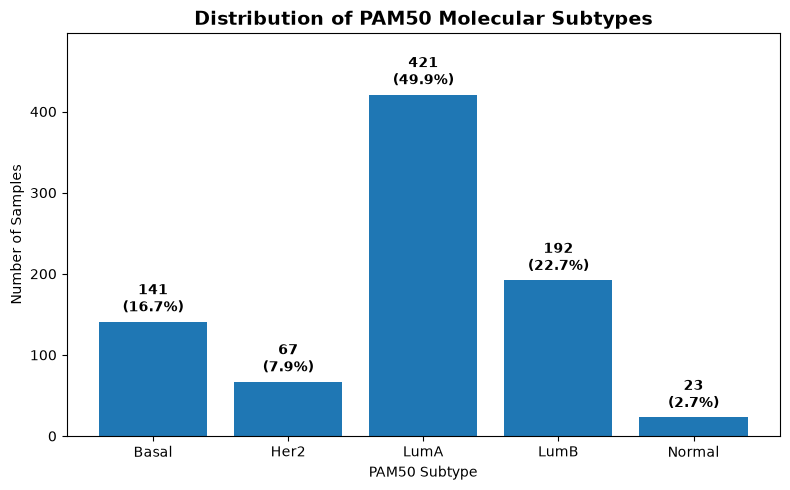


X / y ALIGNMENT CHECK
X_final shape : (844, 20530)
y_encoded     : (844,)
Same index    : True

FINAL MODELING VARIABLES
X shape       : (844, 20530)
y shape       : (844,)
Number classes: 5
Class names   : ['Basal', 'Her2', 'LumA', 'LumB', 'Normal']

✅ CELL 6 COMPLETED — LABELS READY FOR MODELING


In [7]:
# ============================================================
# CELL 6 — LABEL ENCODING + CLASS DISTRIBUTION
# TCGA-BRCA PAM50
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "X_final",
    "y_labels"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
        + "\nJalankan CELL 5 terlebih dahulu."
    )


# ============================================================
# 2. LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(
    y_labels
)

y_encoded = pd.Series(
    y_encoded,
    index=y_labels.index,
    name="PAM50_Encoded"
)


# ============================================================
# 3. CLASS MAPPING
# ============================================================

class_mapping_df = pd.DataFrame({
    "Encoded_Label": np.arange(
        len(label_encoder.classes_)
    ),
    "PAM50_Subtype": label_encoder.classes_
})


print("=" * 90)
print("PAM50 LABEL ENCODING")
print("=" * 90)

display(
    class_mapping_df
)


# ============================================================
# 4. VERIFY EXPECTED MAPPING
# ============================================================

expected_mapping = {
    "Basal": 0,
    "Her2": 1,
    "LumA": 2,
    "LumB": 3,
    "Normal": 4
}

print("\nMapping verification:")

all_mapping_correct = True

for subtype, expected_code in expected_mapping.items():

    if subtype in label_encoder.classes_:

        actual_code = int(
            label_encoder.transform(
                [subtype]
            )[0]
        )

        status = (
            "✅"
            if actual_code == expected_code
            else "⚠️"
        )

        print(
            f"{status} "
            f"{subtype:<7} "
            f"-> {actual_code}"
        )

        if actual_code != expected_code:
            all_mapping_correct = False

    else:

        print(
            f"⚠️ {subtype} tidak ditemukan."
        )

        all_mapping_correct = False


if all_mapping_correct:

    print(
        "\n✅ Label mapping matches expected order."
    )

else:

    print(
        "\n⚠️ Label mapping differs from expected."
    )


# ============================================================
# 5. CLASS DISTRIBUTION
# ============================================================

class_counts = (
    y_labels
    .value_counts()
    .reindex(
        label_encoder.classes_
    )
)

class_percentages = (
    class_counts
    / len(y_labels)
    * 100
)

class_distribution_df = pd.DataFrame({
    "Subtype":
        class_counts.index,

    "Count":
        class_counts.values,

    "Percentage":
        class_percentages.values
})


print("\n" + "=" * 90)
print("PAM50 CLASS DISTRIBUTION")
print("=" * 90)

display(
    class_distribution_df.round(2)
)


# ============================================================
# 6. CLASS IMBALANCE INFORMATION
# ============================================================

largest_class = (
    class_distribution_df
    .sort_values(
        "Count",
        ascending=False
    )
    .iloc[0]
)

smallest_class = (
    class_distribution_df
    .sort_values(
        "Count",
        ascending=True
    )
    .iloc[0]
)

imbalance_ratio = (
    largest_class["Count"]
    / smallest_class["Count"]
)


print("\n" + "=" * 90)
print("CLASS IMBALANCE SUMMARY")
print("=" * 90)

print(
    f"Largest class  : "
    f"{largest_class['Subtype']} "
    f"({int(largest_class['Count'])} samples)"
)

print(
    f"Smallest class : "
    f"{smallest_class['Subtype']} "
    f"({int(smallest_class['Count'])} samples)"
)

print(
    f"Imbalance ratio: "
    f"{imbalance_ratio:.2f} : 1"
)

print(
    "\nPrimary evaluation metric:"
)

print(
    "★ Macro-F1"
)

print(
    "Reason: each PAM50 subtype receives "
    "equal importance despite class imbalance."
)


# ============================================================
# 7. CLASS DISTRIBUTION BAR CHART
# ============================================================

plt.figure(
    figsize=(8, 5)
)

bars = plt.bar(
    class_distribution_df[
        "Subtype"
    ],
    class_distribution_df[
        "Count"
    ]
)

plt.title(
    "Distribution of PAM50 Molecular Subtypes",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "PAM50 Subtype"
)

plt.ylabel(
    "Number of Samples"
)


# Add count and percentage
for bar, count, percentage in zip(
    bars,
    class_distribution_df[
        "Count"
    ],
    class_distribution_df[
        "Percentage"
    ]
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,

        bar.get_height() + 7,

        f"{int(count)}\n"
        f"({percentage:.1f}%)",

        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )


plt.ylim(
    0,
    class_distribution_df[
        "Count"
    ].max() * 1.18
)

plt.tight_layout()
plt.show()


# ============================================================
# 8. CHECK INDEX ALIGNMENT
# ============================================================

same_index = (
    X_final.index.equals(
        y_encoded.index
    )
)

print("\n" + "=" * 90)
print("X / y ALIGNMENT CHECK")
print("=" * 90)

print(
    f"X_final shape : "
    f"{X_final.shape}"
)

print(
    f"y_encoded     : "
    f"{y_encoded.shape}"
)

print(
    f"Same index    : "
    f"{same_index}"
)

if not same_index:

    raise RuntimeError(
        "X_final dan y_encoded "
        "tidak memiliki index yang sama."
    )


# ============================================================
# 9. FINAL VARIABLES
# ============================================================

X = X_final.copy()
y = y_encoded.copy()

class_names = (
    label_encoder.classes_
)

N_CLASSES = len(
    class_names
)


print("\n" + "=" * 90)
print("FINAL MODELING VARIABLES")
print("=" * 90)

print(
    f"X shape       : {X.shape}"
)

print(
    f"y shape       : {y.shape}"
)

print(
    f"Number classes: {N_CLASSES}"
)

print(
    f"Class names   : "
    f"{list(class_names)}"
)


print("\n" + "=" * 90)
print("✅ CELL 6 COMPLETED — LABELS READY FOR MODELING")
print("=" * 90)

# CELL 7 — STRATIFIED TRAIN-TEST SPLIT

In [8]:
# ============================================================
# CELL 7 — STRATIFIED TRAIN-TEST SPLIT
# TCGA-BRCA PAM50
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "X",
    "y",
    "label_encoder"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
        + "\nJalankan CELL 6 terlebih dahulu."
    )


# ============================================================
# 2. GLOBAL SPLIT SETTINGS
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.20


# ============================================================
# 3. STRATIFIED TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    test_size=TEST_SIZE,

    stratify=y,

    random_state=RANDOM_STATE
)


# ============================================================
# 4. BASIC SPLIT INFORMATION
# ============================================================

print("=" * 90)
print("STRATIFIED TRAIN-TEST SPLIT")
print("=" * 90)

print(
    f"Total samples : {len(X):,}"
)

print(
    f"Train samples : {len(X_train):,}"
)

print(
    f"Test samples  : {len(X_test):,}"
)

print(
    f"Train ratio   : "
    f"{len(X_train) / len(X) * 100:.2f}%"
)

print(
    f"Test ratio    : "
    f"{len(X_test) / len(X) * 100:.2f}%"
)


# ============================================================
# 5. CLASS DISTRIBUTION FUNCTION
# ============================================================

def get_class_distribution(
    y_values,
    dataset_name,
    label_encoder
):

    y_series = pd.Series(
        np.asarray(y_values)
    )

    counts = (
        y_series
        .value_counts()
        .sort_index()
    )

    rows = []

    for class_id in range(
        len(label_encoder.classes_)
    ):

        class_name = (
            label_encoder
            .inverse_transform(
                [class_id]
            )[0]
        )

        count = int(
            counts.get(
                class_id,
                0
            )
        )

        percentage = (
            count
            / len(y_values)
            * 100
        )

        rows.append({
            "Dataset":
                dataset_name,

            "Class_ID":
                class_id,

            "Subtype":
                class_name,

            "Count":
                count,

            "Percentage":
                percentage
        })

    return pd.DataFrame(
        rows
    )


# ============================================================
# 6. TRAIN DISTRIBUTION
# ============================================================

train_distribution_df = (
    get_class_distribution(
        y_train,
        "Train",
        label_encoder
    )
)


print("\n" + "=" * 90)
print("TRAIN SET DISTRIBUTION")
print("=" * 90)

display(
    train_distribution_df[
        [
            "Subtype",
            "Count",
            "Percentage"
        ]
    ].round(2)
)


# ============================================================
# 7. TEST DISTRIBUTION
# ============================================================

test_distribution_df = (
    get_class_distribution(
        y_test,
        "Test",
        label_encoder
    )
)


print("\n" + "=" * 90)
print("TEST SET DISTRIBUTION")
print("=" * 90)

display(
    test_distribution_df[
        [
            "Subtype",
            "Count",
            "Percentage"
        ]
    ].round(2)
)


# ============================================================
# 8. COMBINED DISTRIBUTION TABLE
# ============================================================

distribution_comparison_df = (

    train_distribution_df[
        [
            "Subtype",
            "Count",
            "Percentage"
        ]
    ]

    .rename(
        columns={
            "Count":
                "Train_Count",

            "Percentage":
                "Train_Percentage"
        }
    )

    .merge(

        test_distribution_df[
            [
                "Subtype",
                "Count",
                "Percentage"
            ]
        ]
        .rename(
            columns={
                "Count":
                    "Test_Count",

                "Percentage":
                    "Test_Percentage"
            }
        ),

        on="Subtype",

        how="outer"
    )
)


print("\n" + "=" * 90)
print("TRAIN vs TEST CLASS DISTRIBUTION")
print("=" * 90)

display(
    distribution_comparison_df.round(2)
)


# ============================================================
# 9. INDEX OVERLAP CHECK
# ============================================================

overlap_samples = (
    set(X_train.index)
    .intersection(
        set(X_test.index)
    )
)

print("\n" + "=" * 90)
print("DATA LEAKAGE CHECK")
print("=" * 90)

print(
    f"Train/Test overlapping samples : "
    f"{len(overlap_samples)}"
)


if len(overlap_samples) == 0:

    print(
        "✅ No sample overlap between "
        "training and test set."
    )

else:

    print(
        "⚠️ WARNING: overlapping sample IDs detected."
    )


# ============================================================
# 10. X / y ALIGNMENT CHECK
# ============================================================

train_index_ok = (
    X_train.index.equals(
        y_train.index
    )
)

test_index_ok = (
    X_test.index.equals(
        y_test.index
    )
)


print("\nAlignment:")

print(
    f"Train X/y aligned : "
    f"{train_index_ok}"
)

print(
    f"Test X/y aligned  : "
    f"{test_index_ok}"
)


if not train_index_ok:
    raise RuntimeError(
        "X_train dan y_train tidak aligned."
    )

if not test_index_ok:
    raise RuntimeError(
        "X_test dan y_test tidak aligned."
    )


# ============================================================
# 11. EXPECTED RESULT CHECK
# ============================================================

EXPECTED_TRAIN = 675
EXPECTED_TEST = 169

expected_train_counts = {
    "Basal": 113,
    "Her2": 54,
    "LumA": 337,
    "LumB": 153,
    "Normal": 18
}

expected_test_counts = {
    "Basal": 28,
    "Her2": 13,
    "LumA": 84,
    "LumB": 39,
    "Normal": 5
}


print("\n" + "=" * 90)
print("EXPECTED SPLIT CHECK")
print("=" * 90)

if (
    len(X_train) == EXPECTED_TRAIN
    and
    len(X_test) == EXPECTED_TEST
):

    print(
        "✅ Train/Test sample counts match expected."
    )

else:

    print(
        "⚠️ Train/Test sample counts differ from expected."
    )

    print(
        f"Expected train/test : "
        f"{EXPECTED_TRAIN}/{EXPECTED_TEST}"
    )

    print(
        f"Found train/test    : "
        f"{len(X_train)}/{len(X_test)}"
    )


print("\nClass distribution verification:")

for subtype in label_encoder.classes_:

    class_id = int(
        label_encoder.transform(
            [subtype]
        )[0]
    )

    train_count = int(
        np.sum(
            np.asarray(y_train)
            == class_id
        )
    )

    test_count = int(
        np.sum(
            np.asarray(y_test)
            == class_id
        )
    )

    expected_train = (
        expected_train_counts[
            subtype
        ]
    )

    expected_test = (
        expected_test_counts[
            subtype
        ]
    )

    train_status = (
        "✅"
        if train_count == expected_train
        else "⚠️"
    )

    test_status = (
        "✅"
        if test_count == expected_test
        else "⚠️"
    )

    print(
        f"{subtype:<7} "
        f"Train: {train_status} "
        f"{train_count}/{expected_train} | "
        f"Test: {test_status} "
        f"{test_count}/{expected_test}"
    )


# ============================================================
# 12. HOLDOUT WARNING
# ============================================================

print("\n" + "=" * 90)
print("IMPORTANT")
print("=" * 90)

print(
    "X_test / y_test sekarang menjadi "
    "LOCKED HOLDOUT TEST SET."
)

print(
    "Jangan gunakan test set untuk:"
)

print(
    "- Feature selection"
)

print(
    "- Hyperparameter tuning"
)

print(
    "- Memilih arsitektur deep learning"
)

print(
    "- Menentukan jumlah epoch"
)

print(
    "- Memilih dropout / learning rate"
)

print(
    "\nGunakan training set / validation / CV "
    "untuk semua keputusan model."
)


print("\n" + "=" * 90)
print("✅ CELL 7 COMPLETED — TRAIN/TEST SPLIT READY")
print("=" * 90)

STRATIFIED TRAIN-TEST SPLIT
Total samples : 844
Train samples : 675
Test samples  : 169
Train ratio   : 79.98%
Test ratio    : 20.02%

TRAIN SET DISTRIBUTION


,Subtype,Count,Percentage
0,Basal,113,16.74
1,Her2,54,8.00
2,LumA,337,49.93
3,LumB,153,22.67
4,Normal,18,2.67



TEST SET DISTRIBUTION


,Subtype,Count,Percentage
0,Basal,28,16.57
1,Her2,13,7.69
2,LumA,84,49.70
3,LumB,39,23.08
4,Normal,5,2.96



TRAIN vs TEST CLASS DISTRIBUTION


,Subtype,Train_Count,Train_Percentage,Test_Count,Test_Percentage
0,Basal,113,16.74,28,16.57
1,Her2,54,8.00,13,7.69
2,LumA,337,49.93,84,49.70
3,LumB,153,22.67,39,23.08
4,Normal,18,2.67,5,2.96



DATA LEAKAGE CHECK
Train/Test overlapping samples : 0
✅ No sample overlap between training and test set.

Alignment:
Train X/y aligned : True
Test X/y aligned  : True

EXPECTED SPLIT CHECK
✅ Train/Test sample counts match expected.

Class distribution verification:
Basal   Train: ✅ 113/113 | Test: ✅ 28/28
Her2    Train: ✅ 54/54 | Test: ✅ 13/13
LumA    Train: ✅ 337/337 | Test: ✅ 84/84
LumB    Train: ✅ 153/153 | Test: ✅ 39/39
Normal  Train: ✅ 18/18 | Test: ✅ 5/5

IMPORTANT
X_test / y_test sekarang menjadi LOCKED HOLDOUT TEST SET.
Jangan gunakan test set untuk:
- Feature selection
- Hyperparameter tuning
- Memilih arsitektur deep learning
- Menentukan jumlah epoch
- Memilih dropout / learning rate

Gunakan training set / validation / CV untuk semua keputusan model.

✅ CELL 7 COMPLETED — TRAIN/TEST SPLIT READY


# CELL 8 — CUSTOM HIGH-VARIANCE GENE SELECTOR

In [9]:
# ============================================================
# CELL 8 — CUSTOM HIGH-VARIANCE GENE SELECTOR
# TCGA-BRCA PAM50
#
# Tujuan:
# - Memilih Top-K gen dengan variance tertinggi
# - Fit hanya menggunakan data training
# - Bisa digunakan di sklearn Pipeline
# - Menjaga nama gen jika input berupa DataFrame
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import (
    BaseEstimator,
    TransformerMixin
)


# ============================================================
# 1. CUSTOM TRANSFORMER
# ============================================================

class TopVarianceGenes(
    BaseEstimator,
    TransformerMixin
):

    def __init__(
        self,
        k=2000
    ):
        self.k = k


    # ========================================================
    # FIT
    # ========================================================

    def fit(
        self,
        X,
        y=None
    ):

        # --------------------------------------------
        # DataFrame input
        # --------------------------------------------

        if isinstance(
            X,
            pd.DataFrame
        ):

            self.feature_names_in_ = np.asarray(
                X.columns,
                dtype=object
            )

            X_array = X.to_numpy(
                dtype=float
            )

        # --------------------------------------------
        # NumPy input
        # --------------------------------------------

        else:

            X_array = np.asarray(
                X,
                dtype=float
            )

            self.feature_names_in_ = np.arange(
                X_array.shape[1]
            )


        # --------------------------------------------
        # Validation
        # --------------------------------------------

        n_features = X_array.shape[1]

        if self.k <= 0:

            raise ValueError(
                "k harus lebih besar dari 0."
            )

        if self.k > n_features:

            raise ValueError(
                f"k={self.k} lebih besar dari "
                f"jumlah fitur={n_features}."
            )


        # --------------------------------------------
        # Calculate variance
        # --------------------------------------------

        self.variances_ = np.nanvar(
            X_array,
            axis=0
        )


        # --------------------------------------------
        # Rank genes
        # Highest variance first
        # --------------------------------------------

        ranked_indices = np.argsort(
            -self.variances_,
            kind="stable"
        )


        self.selected_indices_ = (
            ranked_indices[
                :self.k
            ]
        )


        # --------------------------------------------
        # Selected gene names
        # --------------------------------------------

        self.selected_features_ = (
            self.feature_names_in_[
                self.selected_indices_
            ]
        )


        self.n_features_in_ = (
            n_features
        )


        return self


    # ========================================================
    # TRANSFORM
    # ========================================================

    def transform(
        self,
        X
    ):

        if not hasattr(
            self,
            "selected_indices_"
        ):

            raise RuntimeError(
                "TopVarianceGenes belum di-fit."
            )


        if isinstance(
            X,
            pd.DataFrame
        ):

            return X.iloc[
                :,
                self.selected_indices_
            ].copy()


        X_array = np.asarray(
            X
        )

        return X_array[
            :,
            self.selected_indices_
        ]


    # ========================================================
    # GET SUPPORT
    # ========================================================

    def get_support(
        self
    ):

        mask = np.zeros(
            self.n_features_in_,
            dtype=bool
        )

        mask[
            self.selected_indices_
        ] = True

        return mask


    # ========================================================
    # GET FEATURE NAMES
    # ========================================================

    def get_feature_names_out(
        self,
        input_features=None
    ):

        if input_features is None:

            input_features = (
                self.feature_names_in_
            )

        input_features = np.asarray(
            input_features,
            dtype=object
        )

        return input_features[
            self.selected_indices_
        ]


# ============================================================
# 2. CONFIGURATION
# ============================================================

TOP_K_GENES = 2000


# ============================================================
# 3. TEST SELECTOR USING TRAINING DATA ONLY
# ============================================================
# Ini hanya sanity check.
# Selector final nanti tetap dimasukkan ke dalam Pipeline/CV.

selector_check = TopVarianceGenes(
    k=TOP_K_GENES
)

selector_check.fit(
    X_train
)


# ============================================================
# 4. SELECTED GENE INFORMATION
# ============================================================

selected_genes_check = (
    selector_check
    .get_feature_names_out(
        X_train.columns
    )
)

selected_variances = (
    selector_check
    .variances_[
        selector_check
        .selected_indices_
    ]
)


variance_ranking_df = pd.DataFrame({

    "Rank":
        np.arange(
            1,
            TOP_K_GENES + 1
        ),

    "Gene":
        selected_genes_check,

    "Variance":
        selected_variances
})


# ============================================================
# 5. DISPLAY TOP 20 HIGH-VARIANCE GENES
# ============================================================

print("=" * 90)
print("TOP-VARIANCE GENE SELECTOR")
print("=" * 90)

print(
    f"Original features : "
    f"{X_train.shape[1]:,}"
)

print(
    f"Selected features : "
    f"{TOP_K_GENES:,}"
)

print(
    f"Training samples  : "
    f"{X_train.shape[0]:,}"
)

print(
    "\nTop 20 highest-variance genes:"
)

display(
    variance_ranking_df
    .head(20)
    .round(6)
)


# ============================================================
# 6. VERIFY TRANSFORMATION SHAPE
# ============================================================

X_train_check = (
    selector_check
    .transform(
        X_train
    )
)

X_test_check = (
    selector_check
    .transform(
        X_test
    )
)


print("\n" + "=" * 90)
print("TRANSFORMATION CHECK")
print("=" * 90)

print(
    f"Original X_train : "
    f"{X_train.shape}"
)

print(
    f"Selected X_train : "
    f"{X_train_check.shape}"
)

print(
    f"Original X_test  : "
    f"{X_test.shape}"
)

print(
    f"Selected X_test  : "
    f"{X_test_check.shape}"
)


# ============================================================
# 7. VERIFY SAME GENES / ORDER
# ============================================================

if isinstance(
    X_train_check,
    pd.DataFrame
):

    same_gene_order = (
        list(
            X_train_check.columns
        )
        ==
        list(
            X_test_check.columns
        )
    )

else:

    same_gene_order = True


print(
    f"Same selected gene order : "
    f"{same_gene_order}"
)


# ============================================================
# 8. DATA LEAKAGE NOTE
# ============================================================

print("\n" + "=" * 90)
print("IMPORTANT — DATA LEAKAGE PREVENTION")
print("=" * 90)

print(
    "✅ Selector di-fit menggunakan X_train saja."
)

print(
    "✅ X_test hanya ditransform menggunakan "
    "selector yang sudah di-fit."
)

print(
    "⚠️ selector_check hanya digunakan sebagai sanity check."
)

print(
    "Untuk classical ML + cross-validation, "
    "TopVarianceGenes akan dimasukkan ke dalam Pipeline "
    "agar selector di-fit ulang di setiap fold."
)

print(
    "Untuk Deep Learning, feature selection akan dilakukan "
    "setelah train/validation split sehingga validation data "
    "tidak menentukan gen yang dipilih."
)


# ============================================================
# 9. EXPECTED CHECK
# ============================================================

if (
    X_train_check.shape
    ==
    (
        X_train.shape[0],
        TOP_K_GENES
    )
    and
    X_test_check.shape
    ==
    (
        X_test.shape[0],
        TOP_K_GENES
    )
):

    print(
        "\n✅ High-variance selector works correctly."
    )

else:

    print(
        "\n⚠️ Unexpected feature-selection dimensions."
    )


print("\n" + "=" * 90)
print("✅ CELL 8 COMPLETED — FEATURE SELECTOR READY")
print("=" * 90)

TOP-VARIANCE GENE SELECTOR
Original features : 20,530
Selected features : 2,000
Training samples  : 675

Top 20 highest-variance genes:


,Rank,Gene,Variance
0,1,CPB1,28.445809
1,2,CLEC3A,27.620093
2,3,SCGB2A2,25.219673
3,4,SCGB1D2,19.896947
4,5,GSTM1,18.906123
5,6,TFF1,18.862096
6,7,S100A7,17.491873
7,8,PIP,17.419147
8,9,SERPINA6,17.401050
9,10,CYP2B7P1,17.395482



TRANSFORMATION CHECK
Original X_train : (675, 20530)
Selected X_train : (675, 2000)
Original X_test  : (169, 20530)
Selected X_test  : (169, 2000)
Same selected gene order : True

IMPORTANT — DATA LEAKAGE PREVENTION
✅ Selector di-fit menggunakan X_train saja.
✅ X_test hanya ditransform menggunakan selector yang sudah di-fit.
⚠️ selector_check hanya digunakan sebagai sanity check.
Untuk classical ML + cross-validation, TopVarianceGenes akan dimasukkan ke dalam Pipeline agar selector di-fit ulang di setiap fold.
Untuk Deep Learning, feature selection akan dilakukan setelah train/validation split sehingga validation data tidak menentukan gen yang dipilih.

✅ High-variance selector works correctly.

✅ CELL 8 COMPLETED — FEATURE SELECTOR READY


# CELL 9 — Stratified Train–Validation Split for Deep Learning

In [10]:
# ============================================================
# CELL 9 — TRAIN-VALIDATION SPLIT FOR DEEP LEARNING
# TCGA-BRCA PAM50
#
# Original development set:
# X_train / y_train = 675 samples
#
# Split:
# 80% DL training
# 20% DL validation
#
# Final holdout X_test / y_test remains LOCKED
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "X_train",
    "y_train",
    "X_test",
    "y_test",
    "label_encoder"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
        + "\nJalankan CELL 7 terlebih dahulu."
    )


# ============================================================
# 2. CONFIGURATION
# ============================================================

RANDOM_STATE = 42

VALIDATION_SIZE = 0.20


# ============================================================
# 3. STRATIFIED TRAIN-VALIDATION SPLIT
# ============================================================

X_train_dl, X_val_dl, y_train_dl, y_val_dl = train_test_split(

    X_train,
    y_train,

    test_size=VALIDATION_SIZE,

    stratify=y_train,

    random_state=RANDOM_STATE
)


# ============================================================
# 4. BASIC INFORMATION
# ============================================================

print("=" * 90)
print("DEEP LEARNING — TRAIN / VALIDATION SPLIT")
print("=" * 90)

print(
    f"Original development samples : "
    f"{len(X_train):,}"
)

print(
    f"DL training samples          : "
    f"{len(X_train_dl):,}"
)

print(
    f"DL validation samples        : "
    f"{len(X_val_dl):,}"
)

print(
    f"Final locked test samples    : "
    f"{len(X_test):,}"
)


print("\nRatios:")

print(
    f"DL training   : "
    f"{len(X_train_dl) / len(X_train) * 100:.2f}%"
)

print(
    f"DL validation : "
    f"{len(X_val_dl) / len(X_train) * 100:.2f}%"
)


# ============================================================
# 5. DISTRIBUTION FUNCTION
# ============================================================

def build_distribution_table(
    y_values,
    dataset_name
):

    y_array = np.asarray(
        y_values
    )

    rows = []

    for class_id, class_name in enumerate(
        label_encoder.classes_
    ):

        count = int(
            np.sum(
                y_array == class_id
            )
        )

        percentage = (
            count
            / len(y_array)
            * 100
        )

        rows.append({

            "Dataset":
                dataset_name,

            "Class_ID":
                class_id,

            "Subtype":
                class_name,

            "Count":
                count,

            "Percentage":
                percentage
        })

    return pd.DataFrame(
        rows
    )


# ============================================================
# 6. TRAIN DISTRIBUTION
# ============================================================

dl_train_distribution = (
    build_distribution_table(
        y_train_dl,
        "DL Train"
    )
)


print("\n" + "=" * 90)
print("DL TRAINING DISTRIBUTION")
print("=" * 90)

display(
    dl_train_distribution[
        [
            "Subtype",
            "Count",
            "Percentage"
        ]
    ].round(2)
)


# ============================================================
# 7. VALIDATION DISTRIBUTION
# ============================================================

dl_val_distribution = (
    build_distribution_table(
        y_val_dl,
        "Validation"
    )
)


print("\n" + "=" * 90)
print("DL VALIDATION DISTRIBUTION")
print("=" * 90)

display(
    dl_val_distribution[
        [
            "Subtype",
            "Count",
            "Percentage"
        ]
    ].round(2)
)


# ============================================================
# 8. TEST DISTRIBUTION
# ============================================================

test_distribution = (
    build_distribution_table(
        y_test,
        "Final Test"
    )
)


print("\n" + "=" * 90)
print("FINAL LOCKED TEST DISTRIBUTION")
print("=" * 90)

display(
    test_distribution[
        [
            "Subtype",
            "Count",
            "Percentage"
        ]
    ].round(2)
)


# ============================================================
# 9. COMBINED DISTRIBUTION TABLE
# ============================================================

combined_distribution = pd.concat(
    [
        dl_train_distribution,
        dl_val_distribution,
        test_distribution
    ],
    ignore_index=True
)


comparison_table = (

    combined_distribution

    .pivot(
        index="Subtype",
        columns="Dataset",
        values="Count"
    )

    .reindex(
        label_encoder.classes_
    )
)


print("\n" + "=" * 90)
print("CLASS DISTRIBUTION COMPARISON")
print("=" * 90)

display(
    comparison_table
)


# ============================================================
# 10. DATA LEAKAGE CHECK
# ============================================================

train_ids = set(
    X_train_dl.index
)

val_ids = set(
    X_val_dl.index
)

test_ids = set(
    X_test.index
)


train_val_overlap = (
    train_ids
    .intersection(
        val_ids
    )
)

train_test_overlap = (
    train_ids
    .intersection(
        test_ids
    )
)

val_test_overlap = (
    val_ids
    .intersection(
        test_ids
    )
)


print("\n" + "=" * 90)
print("DATA LEAKAGE CHECK")
print("=" * 90)

print(
    f"Train ↔ Validation overlap : "
    f"{len(train_val_overlap)}"
)

print(
    f"Train ↔ Test overlap       : "
    f"{len(train_test_overlap)}"
)

print(
    f"Validation ↔ Test overlap  : "
    f"{len(val_test_overlap)}"
)


if (
    len(train_val_overlap) == 0
    and
    len(train_test_overlap) == 0
    and
    len(val_test_overlap) == 0
):

    print(
        "\n✅ No sample overlap between "
        "training, validation, and test sets."
    )

else:

    raise RuntimeError(
        "Sample overlap detected."
    )


# ============================================================
# 11. X / y ALIGNMENT CHECK
# ============================================================

train_alignment = (
    X_train_dl.index.equals(
        y_train_dl.index
    )
)

val_alignment = (
    X_val_dl.index.equals(
        y_val_dl.index
    )
)

test_alignment = (
    X_test.index.equals(
        y_test.index
    )
)


print("\n" + "=" * 90)
print("X / y ALIGNMENT")
print("=" * 90)

print(
    f"DL Train aligned : "
    f"{train_alignment}"
)

print(
    f"Validation aligned: "
    f"{val_alignment}"
)

print(
    f"Test aligned      : "
    f"{test_alignment}"
)


if not (
    train_alignment
    and
    val_alignment
    and
    test_alignment
):

    raise RuntimeError(
        "X/y index alignment problem detected."
    )


# ============================================================
# 12. EXPECTED RESULT CHECK
# ============================================================

EXPECTED_DL_TRAIN = 540
EXPECTED_VALIDATION = 135
EXPECTED_TEST = 169


print("\n" + "=" * 90)
print("EXPECTED SIZE CHECK")
print("=" * 90)

print(
    f"DL Train     : "
    f"{len(X_train_dl)} "
    f"(expected {EXPECTED_DL_TRAIN})"
)

print(
    f"Validation   : "
    f"{len(X_val_dl)} "
    f"(expected {EXPECTED_VALIDATION})"
)

print(
    f"Final Test   : "
    f"{len(X_test)} "
    f"(expected {EXPECTED_TEST})"
)


if (
    len(X_train_dl) == EXPECTED_DL_TRAIN
    and
    len(X_val_dl) == EXPECTED_VALIDATION
    and
    len(X_test) == EXPECTED_TEST
):

    print(
        "\n✅ Dataset sizes match expected values."
    )

else:

    print(
        "\n⚠️ Dataset sizes differ from expected."
    )


# ============================================================
# 13. EXPECTED CLASS DISTRIBUTION
# ============================================================

expected_dl_train = {
    "Basal": 90,
    "Her2": 43,
    "LumA": 270,
    "LumB": 122,
    "Normal": 15
}

expected_validation = {
    "Basal": 23,
    "Her2": 11,
    "LumA": 67,
    "LumB": 31,
    "Normal": 3
}


print("\n" + "=" * 90)
print("EXPECTED CLASS DISTRIBUTION CHECK")
print("=" * 90)


for subtype in label_encoder.classes_:

    class_id = int(
        label_encoder.transform(
            [subtype]
        )[0]
    )

    actual_train = int(
        np.sum(
            np.asarray(
                y_train_dl
            ) == class_id
        )
    )

    actual_val = int(
        np.sum(
            np.asarray(
                y_val_dl
            ) == class_id
        )
    )

    expected_train = (
        expected_dl_train[
            subtype
        ]
    )

    expected_val = (
        expected_validation[
            subtype
        ]
    )

    train_status = (
        "✅"
        if actual_train == expected_train
        else "⚠️"
    )

    val_status = (
        "✅"
        if actual_val == expected_val
        else "⚠️"
    )

    print(
        f"{subtype:<7} | "
        f"Train {train_status} "
        f"{actual_train}/{expected_train} | "
        f"Val {val_status} "
        f"{actual_val}/{expected_val}"
    )


# ============================================================
# 14. IMPORTANT NOTE
# ============================================================

print("\n" + "=" * 90)
print("IMPORTANT — DEEP LEARNING DEVELOPMENT SETUP")
print("=" * 90)

print(
    "X_train_dl / y_train_dl:"
)

print(
    "→ digunakan untuk melatih neural network."
)

print(
    "\nX_val_dl / y_val_dl:"
)

print(
    "→ digunakan untuk Early Stopping,"
)

print(
    "→ memilih epoch terbaik,"
)

print(
    "→ memantau overfitting,"
)

print(
    "→ memilih arsitektur / hyperparameter."
)

print(
    "\nX_test / y_test:"
)

print(
    "→ tetap LOCKED."
)

print(
    "→ hanya digunakan untuk evaluasi final."
)


print("\n" + "=" * 90)
print("✅ CELL 9 COMPLETED — DL TRAIN/VALIDATION SETS READY")
print("=" * 90)

DEEP LEARNING — TRAIN / VALIDATION SPLIT
Original development samples : 675
DL training samples          : 540
DL validation samples        : 135
Final locked test samples    : 169

Ratios:
DL training   : 80.00%
DL validation : 20.00%

DL TRAINING DISTRIBUTION


,Subtype,Count,Percentage
0,Basal,90,16.67
1,Her2,43,7.96
2,LumA,270,50.00
3,LumB,122,22.59
4,Normal,15,2.78



DL VALIDATION DISTRIBUTION


,Subtype,Count,Percentage
0,Basal,23,17.04
1,Her2,11,8.15
2,LumA,67,49.63
3,LumB,31,22.96
4,Normal,3,2.22



FINAL LOCKED TEST DISTRIBUTION


,Subtype,Count,Percentage
0,Basal,28,16.57
1,Her2,13,7.69
2,LumA,84,49.70
3,LumB,39,23.08
4,Normal,5,2.96



CLASS DISTRIBUTION COMPARISON


Dataset,DL Train,Final Test,Validation
Subtype,,,
Basal,90,28,23
Her2,43,13,11
LumA,270,84,67
LumB,122,39,31
Normal,15,5,3



DATA LEAKAGE CHECK
Train ↔ Validation overlap : 0
Train ↔ Test overlap       : 0
Validation ↔ Test overlap  : 0

✅ No sample overlap between training, validation, and test sets.

X / y ALIGNMENT
DL Train aligned : True
Validation aligned: True
Test aligned      : True

EXPECTED SIZE CHECK
DL Train     : 540 (expected 540)
Validation   : 135 (expected 135)
Final Test   : 169 (expected 169)

✅ Dataset sizes match expected values.

EXPECTED CLASS DISTRIBUTION CHECK
Basal   | Train ✅ 90/90 | Val ✅ 23/23
Her2    | Train ✅ 43/43 | Val ✅ 11/11
LumA    | Train ✅ 270/270 | Val ✅ 67/67
LumB    | Train ✅ 122/122 | Val ✅ 31/31
Normal  | Train ✅ 15/15 | Val ✅ 3/3

IMPORTANT — DEEP LEARNING DEVELOPMENT SETUP
X_train_dl / y_train_dl:
→ digunakan untuk melatih neural network.

X_val_dl / y_val_dl:
→ digunakan untuk Early Stopping,
→ memilih epoch terbaik,
→ memantau overfitting,
→ memilih arsitektur / hyperparameter.

X_test / y_test:
→ tetap LOCKED.
→ hanya digunakan untuk evaluasi final.

✅ CELL 9 

# CELL 10 — Feature Selection + Scaling for Deep Learning

In [11]:
# ============================================================
# CELL 10 — FEATURE SELECTION + STANDARDIZATION FOR DEEP LEARNING
# TCGA-BRCA PAM50
#
# FIT ONLY ON:
# X_train_dl
#
# TRANSFORM:
# X_train_dl
# X_val_dl
# X_test
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "X_train_dl",
    "X_val_dl",
    "X_test",
    "y_train_dl",
    "y_val_dl",
    "y_test",
    "TopVarianceGenes"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:

    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
        + "\nJalankan CELL 8 dan CELL 9 terlebih dahulu."
    )


# ============================================================
# 2. CONFIGURATION
# ============================================================

TOP_K_GENES = 2000


# ============================================================
# 3. HIGH-VARIANCE FEATURE SELECTION
# FIT ONLY ON DL TRAINING DATA
# ============================================================

dl_gene_selector = TopVarianceGenes(
    k=TOP_K_GENES
)

dl_gene_selector.fit(
    X_train_dl
)


# ============================================================
# 4. TRANSFORM TRAIN / VALIDATION / TEST
# ============================================================

X_train_dl_selected = (
    dl_gene_selector
    .transform(
        X_train_dl
    )
)

X_val_dl_selected = (
    dl_gene_selector
    .transform(
        X_val_dl
    )
)

X_test_dl_selected = (
    dl_gene_selector
    .transform(
        X_test
    )
)


# ============================================================
# 5. SELECTED GENE NAMES
# ============================================================

selected_genes_dl = (
    dl_gene_selector
    .get_feature_names_out(
        X_train_dl.columns
    )
)


selected_variances_dl = (
    dl_gene_selector
    .variances_[
        dl_gene_selector
        .selected_indices_
    ]
)


selected_gene_df = pd.DataFrame({

    "Rank":
        np.arange(
            1,
            TOP_K_GENES + 1
        ),

    "Gene":
        selected_genes_dl,

    "Variance":
        selected_variances_dl
})


# ============================================================
# 6. CHECK SELECTED DATA
# ============================================================

print("=" * 90)
print("DEEP LEARNING — HIGH-VARIANCE FEATURE SELECTION")
print("=" * 90)

print(
    f"Original genes     : "
    f"{X_train_dl.shape[1]:,}"
)

print(
    f"Selected genes     : "
    f"{len(selected_genes_dl):,}"
)

print(
    f"DL Train shape     : "
    f"{X_train_dl_selected.shape}"
)

print(
    f"Validation shape   : "
    f"{X_val_dl_selected.shape}"
)

print(
    f"Test shape         : "
    f"{X_test_dl_selected.shape}"
)


print("\nTop 20 selected genes:")

display(
    selected_gene_df
    .head(20)
    .round(6)
)


# ============================================================
# 7. STANDARDIZATION
# FIT ONLY ON DL TRAINING DATA
# ============================================================

dl_scaler = StandardScaler()

dl_scaler.fit(
    X_train_dl_selected
)


X_train_dl_scaled = (
    dl_scaler
    .transform(
        X_train_dl_selected
    )
)

X_val_dl_scaled = (
    dl_scaler
    .transform(
        X_val_dl_selected
    )
)

X_test_dl_scaled = (
    dl_scaler
    .transform(
        X_test_dl_selected
    )
)


# ============================================================
# 8. CONVERT TO FLOAT32
# Recommended for neural networks
# ============================================================

X_train_dl_scaled = (
    X_train_dl_scaled
    .astype(
        np.float32
    )
)

X_val_dl_scaled = (
    X_val_dl_scaled
    .astype(
        np.float32
    )
)

X_test_dl_scaled = (
    X_test_dl_scaled
    .astype(
        np.float32
    )
)


y_train_dl_array = (
    np.asarray(
        y_train_dl
    )
    .astype(
        np.int32
    )
)

y_val_dl_array = (
    np.asarray(
        y_val_dl
    )
    .astype(
        np.int32
    )
)

y_test_dl_array = (
    np.asarray(
        y_test
    )
    .astype(
        np.int32
    )
)


# ============================================================
# 9. STANDARDIZATION CHECK
# ============================================================

train_mean = np.mean(
    X_train_dl_scaled
)

train_std = np.std(
    X_train_dl_scaled
)


print("\n" + "=" * 90)
print("STANDARDIZATION CHECK")
print("=" * 90)

print(
    f"Training global mean : "
    f"{train_mean:.6f}"
)

print(
    f"Training global std  : "
    f"{train_std:.6f}"
)

print(
    f"Minimum value        : "
    f"{X_train_dl_scaled.min():.4f}"
)

print(
    f"Maximum value        : "
    f"{X_train_dl_scaled.max():.4f}"
)


# ============================================================
# 10. FINAL DL INPUT SHAPES
# ============================================================

print("\n" + "=" * 90)
print("FINAL DEEP LEARNING INPUT")
print("=" * 90)

print(
    f"X_train_dl_scaled : "
    f"{X_train_dl_scaled.shape}"
)

print(
    f"y_train_dl_array  : "
    f"{y_train_dl_array.shape}"
)

print(
    f"X_val_dl_scaled   : "
    f"{X_val_dl_scaled.shape}"
)

print(
    f"y_val_dl_array    : "
    f"{y_val_dl_array.shape}"
)

print(
    f"X_test_dl_scaled  : "
    f"{X_test_dl_scaled.shape}"
)

print(
    f"y_test_dl_array   : "
    f"{y_test_dl_array.shape}"
)


# ============================================================
# 11. CHECK NAN / INF AFTER PREPROCESSING
# ============================================================

datasets_to_check = {

    "Train":
        X_train_dl_scaled,

    "Validation":
        X_val_dl_scaled,

    "Test":
        X_test_dl_scaled
}


print("\n" + "=" * 90)
print("NaN / INF CHECK")
print("=" * 90)

all_clean = True

for dataset_name, data in datasets_to_check.items():

    n_nan = np.isnan(
        data
    ).sum()

    n_inf = np.isinf(
        data
    ).sum()

    print(
        f"{dataset_name:<10} "
        f"NaN={n_nan:<5} "
        f"Inf={n_inf}"
    )

    if (
        n_nan > 0
        or
        n_inf > 0
    ):
        all_clean = False


if all_clean:

    print(
        "\n✅ All DL input matrices are clean."
    )

else:

    print(
        "\n⚠️ NaN or infinite values detected."
    )


# ============================================================
# 12. VERIFY NO TEST INFORMATION USED
# ============================================================

print("\n" + "=" * 90)
print("DATA LEAKAGE CHECK")
print("=" * 90)

print(
    "✅ Gene selector fitted ONLY on X_train_dl."
)

print(
    "✅ StandardScaler fitted ONLY on X_train_dl."
)

print(
    "✅ Validation data only transformed."
)

print(
    "✅ Final test data only transformed."
)

print(
    "✅ y_val and y_test were NOT used "
    "during feature selection or scaling."
)


# ============================================================
# 13. SAVE SELECTED GENE LIST
# ============================================================

os.makedirs(
    "results/deep_learning",
    exist_ok=True
)

selected_gene_df.to_csv(
    "results/deep_learning/"
    "selected_2000_high_variance_genes.csv",
    index=False
)


print("\nSelected genes saved to:")

print(
    "results/deep_learning/"
    "selected_2000_high_variance_genes.csv"
)


# ============================================================
# 14. EXPECTED SHAPE CHECK
# ============================================================

expected_shapes = {

    "Train":
        (540, 2000),

    "Validation":
        (135, 2000),

    "Test":
        (169, 2000)
}


actual_shapes = {

    "Train":
        X_train_dl_scaled.shape,

    "Validation":
        X_val_dl_scaled.shape,

    "Test":
        X_test_dl_scaled.shape
}


print("\n" + "=" * 90)
print("EXPECTED SHAPE CHECK")
print("=" * 90)

for dataset_name in expected_shapes:

    expected = expected_shapes[
        dataset_name
    ]

    actual = actual_shapes[
        dataset_name
    ]

    status = (
        "✅"
        if actual == expected
        else "⚠️"
    )

    print(
        f"{status} "
        f"{dataset_name:<10} "
        f"{actual} "
        f"(expected {expected})"
    )


print("\n" + "=" * 90)
print("✅ CELL 10 COMPLETED — DL PREPROCESSING READY")
print("=" * 90)

DEEP LEARNING — HIGH-VARIANCE FEATURE SELECTION
Original genes     : 20,530
Selected genes     : 2,000
DL Train shape     : (540, 2000)
Validation shape   : (135, 2000)
Test shape         : (169, 2000)

Top 20 selected genes:


,Rank,Gene,Variance
0,1,CPB1,28.258235
1,2,CLEC3A,27.688039
2,3,SCGB2A2,25.128901
3,4,SCGB1D2,19.988915
4,5,TFF1,18.943953
5,6,GSTM1,18.760672
6,7,SERPINA6,17.630253
7,8,CYP2B7P1,17.412326
8,9,S100A7,17.045736
9,10,PIP,16.987574



STANDARDIZATION CHECK
Training global mean : -0.000000
Training global std  : 1.000000
Minimum value        : -6.1960
Maximum value        : 10.0305

FINAL DEEP LEARNING INPUT
X_train_dl_scaled : (540, 2000)
y_train_dl_array  : (540,)
X_val_dl_scaled   : (135, 2000)
y_val_dl_array    : (135,)
X_test_dl_scaled  : (169, 2000)
y_test_dl_array   : (169,)

NaN / INF CHECK
Train      NaN=0     Inf=0
Validation NaN=0     Inf=0
Test       NaN=0     Inf=0

✅ All DL input matrices are clean.

DATA LEAKAGE CHECK
✅ Gene selector fitted ONLY on X_train_dl.
✅ StandardScaler fitted ONLY on X_train_dl.
✅ Validation data only transformed.
✅ Final test data only transformed.
✅ y_val and y_test were NOT used during feature selection or scaling.

Selected genes saved to:
results/deep_learning/selected_2000_high_variance_genes.csv

EXPECTED SHAPE CHECK
✅ Train      (540, 2000) (expected (540, 2000))
✅ Validation (135, 2000) (expected (135, 2000))
✅ Test       (169, 2000) (expected (169, 2000))

✅ CELL 10 

# CELL 11 — CLASS WEIGHTS FOR DEEP LEARNING

In [12]:
# ============================================================
# CELL 11 — CLASS WEIGHTS FOR DEEP LEARNING
# TCGA-BRCA PAM50
# ============================================================

import numpy as np
import pandas as pd

from sklearn.utils.class_weight import compute_class_weight


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "y_train_dl_array",
    "label_encoder"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
        + "\nJalankan CELL 10 terlebih dahulu."
    )


# ============================================================
# 2. CALCULATE BALANCED CLASS WEIGHTS
# ============================================================

classes_dl = np.unique(
    y_train_dl_array
)

weights_dl = compute_class_weight(
    class_weight="balanced",
    classes=classes_dl,
    y=y_train_dl_array
)


class_weight_dict = {
    int(class_id): float(weight)
    for class_id, weight
    in zip(classes_dl, weights_dl)
}


# ============================================================
# 3. TABLE
# ============================================================

class_weight_df = pd.DataFrame({
    "Class_ID": classes_dl,
    "Subtype": label_encoder.inverse_transform(
        classes_dl
    ),
    "Train_Count": [
        np.sum(y_train_dl_array == class_id)
        for class_id in classes_dl
    ],
    "Class_Weight": weights_dl
})


print("=" * 90)
print("DEEP LEARNING — CLASS WEIGHTS")
print("=" * 90)

display(
    class_weight_df.round(4)
)

print("\nClass weight dictionary:")
print(
    class_weight_dict
)


# ============================================================
# 4. CHECK
# ============================================================

print("\nInterpretation:")

for _, row in class_weight_df.iterrows():

    print(
        f"{row['Subtype']:<7} | "
        f"n={int(row['Train_Count']):<3} | "
        f"weight={row['Class_Weight']:.4f}"
    )


print("\n✅ CELL 11 COMPLETED — CLASS WEIGHTS READY")

DEEP LEARNING — CLASS WEIGHTS


,Class_ID,Subtype,Train_Count,Class_Weight
0,0,Basal,90,1.2000
1,1,Her2,43,2.5116
2,2,LumA,270,0.4000
3,3,LumB,122,0.8852
4,4,Normal,15,7.2000



Class weight dictionary:
{0: 1.2, 1: 2.511627906976744, 2: 0.4, 3: 0.8852459016393442, 4: 7.2}

Interpretation:
Basal   | n=90  | weight=1.2000
Her2    | n=43  | weight=2.5116
LumA    | n=270 | weight=0.4000
LumB    | n=122 | weight=0.8852
Normal  | n=15  | weight=7.2000

✅ CELL 11 COMPLETED — CLASS WEIGHTS READY


# CELL 12 — BUILD DEEP LEARNING MLP


In [13]:
# ============================================================
# CELL 12 — BUILD DEEP LEARNING MLP
# TCGA-BRCA PAM50
# ============================================================

import os
import numpy as np

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers, regularizers

except ImportError:
    raise RuntimeError(
        "TensorFlow belum tersedia pada kernel ini.\n"
        "Pastikan menggunakan kernel Python 3.13 "
        "(Skripsi DL)."
    )


# ============================================================
# 1. RANDOM SEED
# ============================================================

RANDOM_STATE = 42

tf.keras.utils.set_random_seed(
    RANDOM_STATE
)


# ============================================================
# 2. CONFIGURATION
# ============================================================

INPUT_DIM = (
    X_train_dl_scaled.shape[1]
)

N_CLASSES = len(
    label_encoder.classes_
)

LEARNING_RATE = 0.001

L2_REGULARIZATION = 1e-4


# ============================================================
# 3. BUILD MODEL
# ============================================================

mlp_model = keras.Sequential([

    layers.Input(
        shape=(INPUT_DIM,),
        name="gene_expression_input"
    ),

    # --------------------------------------------------------
    # Hidden Layer 1
    # --------------------------------------------------------

    layers.Dense(
        128,
        kernel_regularizer=regularizers.l2(
            L2_REGULARIZATION
        )
    ),

    layers.BatchNormalization(),

    layers.Activation(
        "relu"
    ),

    layers.Dropout(
        0.40
    ),

    # --------------------------------------------------------
    # Hidden Layer 2
    # --------------------------------------------------------

    layers.Dense(
        32,
        kernel_regularizer=regularizers.l2(
            L2_REGULARIZATION
        )
    ),

    layers.BatchNormalization(),

    layers.Activation(
        "relu"
    ),

    layers.Dropout(
        0.30
    ),

    # --------------------------------------------------------
    # Output Layer
    # --------------------------------------------------------

    layers.Dense(
        N_CLASSES,
        activation="softmax",
        name="pam50_output"
    )
])


# ============================================================
# 4. COMPILE
# ============================================================

optimizer = keras.optimizers.Adam(
    learning_rate=LEARNING_RATE
)

mlp_model.compile(

    optimizer=optimizer,

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)


# ============================================================
# 5. MODEL SUMMARY
# ============================================================

print("=" * 90)
print("DEEP LEARNING MLP — MODEL ARCHITECTURE")
print("=" * 90)

mlp_model.summary()


# ============================================================
# 6. MODEL INFORMATION
# ============================================================

total_params = mlp_model.count_params()

print("\n" + "=" * 90)

print(
    f"Input genes        : {INPUT_DIM}"
)

print(
    f"Output classes     : {N_CLASSES}"
)

print(
    f"Learning rate      : {LEARNING_RATE}"
)

print(
    f"L2 regularization  : {L2_REGULARIZATION}"
)

print(
    f"Total parameters   : {total_params:,}"
)

print("=" * 90)

print(
    "✅ CELL 12 COMPLETED — MLP MODEL READY"
)

DEEP LEARNING MLP — MODEL ARCHITECTURE


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       256,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pam50_output (Dense)            │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 261,061 (1019.77 KB)

 Trainable params: 260,741 (1018.52 KB)

 Non-trainable params: 320 (1.25 KB)


Input genes        : 2000
Output classes     : 5
Learning rate      : 0.001
L2 regularization  : 0.0001
Total parameters   : 261,061
✅ CELL 12 COMPLETED — MLP MODEL READY


# CELL 13 — TRAIN MLP


In [14]:
# ============================================================
# CELL 13 — TRAIN MLP
# Macro-F1 Monitoring + Early Stopping
# ============================================================

import os
import numpy as np
import tensorflow as tf

from sklearn.metrics import f1_score


# ============================================================
# 1. CUSTOM CALLBACK — VALIDATION MACRO-F1
# ============================================================

class ValidationMacroF1(
    tf.keras.callbacks.Callback
):

    def __init__(
        self,
        x_val,
        y_val
    ):

        super().__init__()

        self.x_val = x_val
        self.y_val = np.asarray(
            y_val
        )

        self.macro_f1_history = []


    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        if logs is None:
            logs = {}

        y_prob = self.model.predict(
            self.x_val,
            verbose=0
        )

        y_pred = np.argmax(
            y_prob,
            axis=1
        )

        macro_f1 = f1_score(
            self.y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        self.macro_f1_history.append(
            macro_f1
        )

        logs[
            "val_macro_f1"
        ] = macro_f1

        print(
            f" - val_macro_f1: "
            f"{macro_f1:.4f}",
            end=""
        )


# ============================================================
# 2. CALLBACK
# ============================================================

macro_f1_callback = ValidationMacroF1(
    X_val_dl_scaled,
    y_val_dl_array
)


early_stopping = (
    tf.keras.callbacks.EarlyStopping(

        monitor="val_macro_f1",

        mode="max",

        patience=20,

        min_delta=0.001,

        restore_best_weights=True,

        verbose=1
    )
)


reduce_lr = (
    tf.keras.callbacks.ReduceLROnPlateau(

        monitor="val_loss",

        mode="min",

        factor=0.5,

        patience=8,

        min_lr=1e-6,

        verbose=1
    )
)


os.makedirs(
    "results/deep_learning",
    exist_ok=True
)


checkpoint = (
    tf.keras.callbacks.ModelCheckpoint(

        filepath=(
            "results/deep_learning/"
            "best_mlp_validation.keras"
        ),

        monitor="val_macro_f1",

        mode="max",

        save_best_only=True,

        verbose=1
    )
)


# ============================================================
# 3. TRAINING CONFIGURATION
# ============================================================

MAX_EPOCHS = 200

BATCH_SIZE = 32


print("=" * 90)
print("TRAINING MLP")
print("=" * 90)

print(
    f"Maximum epochs : {MAX_EPOCHS}"
)

print(
    f"Batch size     : {BATCH_SIZE}"
)

print(
    f"Training       : "
    f"{X_train_dl_scaled.shape}"
)

print(
    f"Validation     : "
    f"{X_val_dl_scaled.shape}"
)


# ============================================================
# 4. TRAIN
# ============================================================

history = mlp_model.fit(

    X_train_dl_scaled,
    y_train_dl_array,

    validation_data=(
        X_val_dl_scaled,
        y_val_dl_array
    ),

    epochs=MAX_EPOCHS,

    batch_size=BATCH_SIZE,

    class_weight=class_weight_dict,

    callbacks=[
        macro_f1_callback,
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)


# ============================================================
# 5. TRAINING SUMMARY
# ============================================================

epochs_completed = len(
    history.history["loss"]
)

best_epoch = int(
    np.argmax(
        macro_f1_callback
        .macro_f1_history
    )
    + 1
)

best_val_macro_f1 = float(
    np.max(
        macro_f1_callback
        .macro_f1_history
    )
)


print("\n" + "=" * 90)
print("TRAINING COMPLETED")
print("=" * 90)

print(
    f"Epochs completed       : "
    f"{epochs_completed}"
)

print(
    f"Best epoch             : "
    f"{best_epoch}"
)

print(
    f"Best validation Macro-F1: "
    f"{best_val_macro_f1:.4f}"
)

print(
    "\n✅ CELL 13 COMPLETED — MLP TRAINING FINISHED"
)

TRAINING MLP
Maximum epochs : 200
Batch size     : 32
Training       : (540, 2000)
Validation     : (135, 2000)
Epoch 1/200
 1/17 ━━━━━━━━━━━━━━━━━━━━ 15s 1000ms/step - accuracy: 0.2500 - loss: 2.1900 - val_macro_f1: 0.4809
Epoch 1: val_macro_f1 improved from None to 0.48088, saving model to results/deep_learning/best_mlp_validation.keras

Epoch 1: finished saving model to results/deep_learning/best_mlp_validation.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.3722 - loss: 1.2581 - val_accuracy: 0.4963 - val_loss: 1.2441 - val_macro_f1: 0.4809 - learning_rate: 0.0010
Epoch 2/200
 1/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7500 - loss: 0.6458 - val_macro_f1: 0.5476
Epoch 2: val_macro_f1 improved from 0.48088 to 0.54760, saving model to results/deep_learning/best_mlp_validation.keras

Epoch 2: finished saving model to results/deep_learning/best_mlp_validation.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5556 - loss: 0.7883 - val_accuracy: 0.5704 - val_

# CELL 14 — MLP LEARNING CURVES


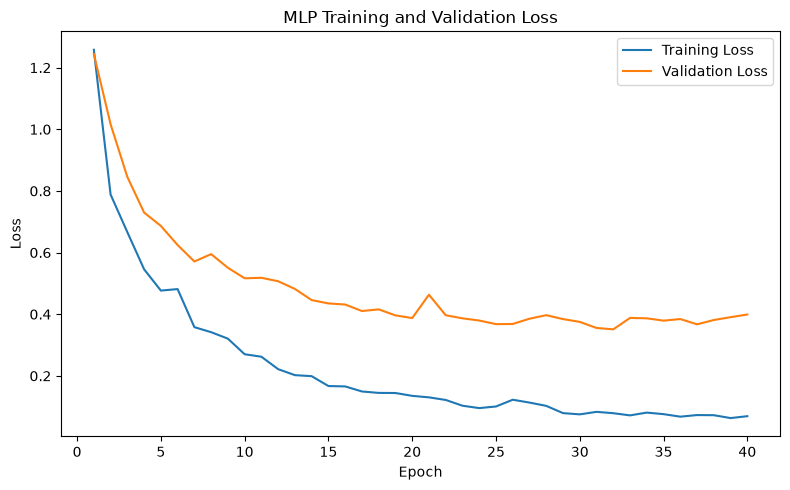

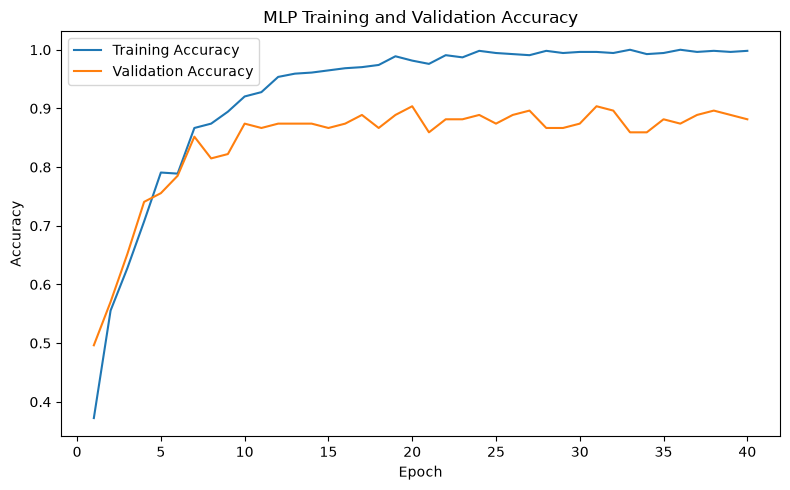

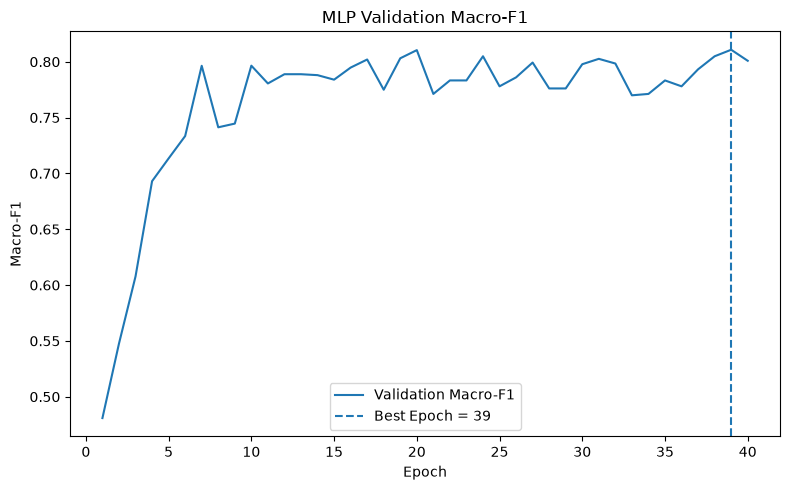

LEARNING CURVE SUMMARY
Epochs completed        : 40
Best epoch              : 39
Best Validation Macro-F1: 0.8108

✅ CELL 14 COMPLETED


In [15]:
# ============================================================
# CELL 14 — MLP LEARNING CURVES
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. PREPARE HISTORY
# ============================================================

epochs_range = np.arange(
    1,
    len(history.history["loss"]) + 1
)

val_macro_f1_history = np.asarray(
    macro_f1_callback
    .macro_f1_history
)


# ============================================================
# 2. LOSS CURVE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history.history[
        "loss"
    ],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history.history[
        "val_loss"
    ],
    label="Validation Loss"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "MLP Training and Validation Loss"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "results/deep_learning/"
    "mlp_loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 3. ACCURACY CURVE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    history.history[
        "accuracy"
    ],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history.history[
        "val_accuracy"
    ],
    label="Validation Accuracy"
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "MLP Training and Validation Accuracy"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "results/deep_learning/"
    "mlp_accuracy_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 4. VALIDATION MACRO-F1 CURVE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    epochs_range,
    val_macro_f1_history,
    label="Validation Macro-F1"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=(
        f"Best Epoch = {best_epoch}"
    )
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Macro-F1"
)

plt.title(
    "MLP Validation Macro-F1"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "results/deep_learning/"
    "mlp_validation_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 5. SUMMARY
# ============================================================

print("=" * 90)
print("LEARNING CURVE SUMMARY")
print("=" * 90)

print(
    f"Epochs completed        : "
    f"{epochs_completed}"
)

print(
    f"Best epoch              : "
    f"{best_epoch}"
)

print(
    f"Best Validation Macro-F1: "
    f"{best_val_macro_f1:.4f}"
)

print(
    "\n✅ CELL 14 COMPLETED"
)

# CELL 16 — LumA vs LumB VALIDATION ERROR ANALYSIS


In [16]:
# ============================================================
# CELL 16 — LumA vs LumB VALIDATION ERROR ANALYSIS
# MLP — TCGA-BRCA
# SELF-CONTAINED / FIXED VERSION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix
)


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "mlp_model",
    "X_val_dl_scaled",
    "y_val_dl_array",
    "label_encoder"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
        + "\nPastikan CELL 10–15 sudah dijalankan."
    )


# ============================================================
# 2. CREATE VALIDATION PREDICTIONS
# If not already available
# ============================================================

if "y_val_prob_mlp" not in globals():

    y_val_prob_mlp = mlp_model.predict(
        X_val_dl_scaled,
        verbose=0
    )


if "y_val_pred_mlp" not in globals():

    y_val_pred_mlp = np.argmax(
        y_val_prob_mlp,
        axis=1
    )


# ============================================================
# 3. GET LumA / LumB CLASS IDs
# ============================================================

LUMA_ID = int(
    label_encoder.transform(
        ["LumA"]
    )[0]
)

LUMB_ID = int(
    label_encoder.transform(
        ["LumB"]
    )[0]
)


print("=" * 90)
print("LumA / LumB CLASS IDS")
print("=" * 90)

print(
    f"LumA ID : {LUMA_ID}"
)

print(
    f"LumB ID : {LUMB_ID}"
)


# ============================================================
# 4. F1, PRECISION, RECALL PER CLASS
# ============================================================

luminal_class_ids = [
    LUMA_ID,
    LUMB_ID
]


precision_luminal = precision_score(
    y_val_dl_array,
    y_val_pred_mlp,
    labels=luminal_class_ids,
    average=None,
    zero_division=0
)

recall_luminal = recall_score(
    y_val_dl_array,
    y_val_pred_mlp,
    labels=luminal_class_ids,
    average=None,
    zero_division=0
)

f1_luminal = f1_score(
    y_val_dl_array,
    y_val_pred_mlp,
    labels=luminal_class_ids,
    average=None,
    zero_division=0
)


luma_precision_mlp = precision_luminal[0]
lumb_precision_mlp = precision_luminal[1]

luma_recall_mlp = recall_luminal[0]
lumb_recall_mlp = recall_luminal[1]

luma_f1_mlp = f1_luminal[0]
lumb_f1_mlp = f1_luminal[1]


# ============================================================
# 5. COUNT LumA / LumB ERRORS
# ============================================================

luma_total = int(
    np.sum(
        y_val_dl_array == LUMA_ID
    )
)

lumb_total = int(
    np.sum(
        y_val_dl_array == LUMB_ID
    )
)


luma_correct = int(
    np.sum(
        (y_val_dl_array == LUMA_ID)
        &
        (y_val_pred_mlp == LUMA_ID)
    )
)

lumb_correct = int(
    np.sum(
        (y_val_dl_array == LUMB_ID)
        &
        (y_val_pred_mlp == LUMB_ID)
    )
)


luma_to_lumb = int(
    np.sum(
        (y_val_dl_array == LUMA_ID)
        &
        (y_val_pred_mlp == LUMB_ID)
    )
)

lumb_to_luma = int(
    np.sum(
        (y_val_dl_array == LUMB_ID)
        &
        (y_val_pred_mlp == LUMA_ID)
    )
)


# ============================================================
# 6. OTHER ERRORS
# ============================================================

luma_other_errors = (
    luma_total
    - luma_correct
    - luma_to_lumb
)

lumb_other_errors = (
    lumb_total
    - lumb_correct
    - lumb_to_luma
)


# ============================================================
# 7. SUMMARY TABLE
# ============================================================

luminal_validation_summary = pd.DataFrame({

    "Subtype": [
        "LumA",
        "LumB"
    ],

    "Support": [
        luma_total,
        lumb_total
    ],

    "Correct": [
        luma_correct,
        lumb_correct
    ],

    "Precision": [
        luma_precision_mlp,
        lumb_precision_mlp
    ],

    "Recall": [
        luma_recall_mlp,
        lumb_recall_mlp
    ],

    "F1-Score": [
        luma_f1_mlp,
        lumb_f1_mlp
    ],

    "Misclassified_as_Other_Luminal": [
        luma_to_lumb,
        lumb_to_luma
    ],

    "Other_Errors": [
        luma_other_errors,
        lumb_other_errors
    ]
})


print("\n" + "=" * 90)
print("MLP — LumA vs LumB VALIDATION PERFORMANCE")
print("=" * 90)

display(
    luminal_validation_summary.round(4)
)


# ============================================================
# 8. DIRECT ERROR SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("DIRECT LumA ↔ LumB ERRORS")
print("=" * 90)

print(
    f"LumA total     : {luma_total}"
)

print(
    f"LumA correct   : {luma_correct}"
)

print(
    f"LumA → LumB    : {luma_to_lumb}"
)

print(
    f"LumA F1        : {luma_f1_mlp:.4f}"
)

print("-" * 90)

print(
    f"LumB total     : {lumb_total}"
)

print(
    f"LumB correct   : {lumb_correct}"
)

print(
    f"LumB → LumA    : {lumb_to_luma}"
)

print(
    f"LumB F1        : {lumb_f1_mlp:.4f}"
)


# ============================================================
# 9. LUMINAL-ONLY MACRO-F1
# ============================================================

luminal_macro_f1 = np.mean([
    luma_f1_mlp,
    lumb_f1_mlp
])


print("-" * 90)

print(
    f"LumA/LumB Macro-F1 : "
    f"{luminal_macro_f1:.4f}"
)


# ============================================================
# 10. SAVE
# ============================================================

luminal_validation_summary.to_csv(
    "results/deep_learning/"
    "mlp_luma_lumb_validation.csv",
    index=False
)


print("\n" + "=" * 90)
print(
    "✅ CELL 16 COMPLETED — "
    "LUMINAL VALIDATION ANALYSIS READY"
)
print("=" * 90)

LumA / LumB CLASS IDS
LumA ID : 2
LumB ID : 3

MLP — LumA vs LumB VALIDATION PERFORMANCE


,Subtype,Support,Correct,Precision,Recall,F1-Score,Misclassified_as_Other_Luminal,Other_Errors
0,LumA,67,61,0.9531,0.9104,0.9313,5,1
1,LumB,31,26,0.8125,0.8387,0.8254,3,2



DIRECT LumA ↔ LumB ERRORS
LumA total     : 67
LumA correct   : 61
LumA → LumB    : 5
LumA F1        : 0.9313
------------------------------------------------------------------------------------------
LumB total     : 31
LumB correct   : 26
LumB → LumA    : 3
LumB F1        : 0.8254
------------------------------------------------------------------------------------------
LumA/LumB Macro-F1 : 0.8783

✅ CELL 16 COMPLETED — LUMINAL VALIDATION ANALYSIS READY


# CELL 17 — FAIR VALIDATION COMPARISON


In [17]:
# ============================================================
# CELL 17 — FAIR VALIDATION COMPARISON
# LINEAR SVM vs DEEP LEARNING MLP
# SAME TRAINING / VALIDATION SET
# SELF-CONTAINED VERSION
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score
)

from sklearn.preprocessing import label_binarize


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "X_train_dl_scaled",
    "y_train_dl_array",
    "X_val_dl_scaled",
    "y_val_dl_array",
    "mlp_model",
    "label_encoder"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
        + "\nPastikan CELL 10–16 sudah dijalankan."
    )


# ============================================================
# 2. CLASS INFORMATION
# ============================================================

class_ids = np.arange(
    len(label_encoder.classes_)
)

class_names = np.asarray(
    label_encoder.classes_
)

print("=" * 90)
print("CLASS INFORMATION")
print("=" * 90)

for class_id, class_name in zip(
    class_ids,
    class_names
):
    print(
        f"{class_id} -> {class_name}"
    )


# ============================================================
# 3. MLP VALIDATION PREDICTIONS
# ============================================================

y_val_prob_mlp = mlp_model.predict(
    X_val_dl_scaled,
    verbose=0
)

y_val_pred_mlp = np.argmax(
    y_val_prob_mlp,
    axis=1
)


# ============================================================
# 4. MLP OVERALL METRICS
# ============================================================

mlp_val_accuracy = accuracy_score(
    y_val_dl_array,
    y_val_pred_mlp
)

mlp_val_balanced_accuracy = (
    balanced_accuracy_score(
        y_val_dl_array,
        y_val_pred_mlp
    )
)

mlp_val_macro_f1 = f1_score(
    y_val_dl_array,
    y_val_pred_mlp,
    average="macro",
    zero_division=0
)

mlp_val_mcc = matthews_corrcoef(
    y_val_dl_array,
    y_val_pred_mlp
)


# ============================================================
# 5. MLP ROC-AUC
# ============================================================

y_val_bin = label_binarize(
    y_val_dl_array,
    classes=class_ids
)

mlp_auc_per_class = []

for i in class_ids:

    auc_i = roc_auc_score(
        y_val_bin[:, i],
        y_val_prob_mlp[:, i]
    )

    mlp_auc_per_class.append(
        auc_i
    )

mlp_val_macro_auc = np.mean(
    mlp_auc_per_class
)


# ============================================================
# 6. TRAIN LINEAR SVM
# SAME TRAINING DATA AS MLP
# ============================================================

print("\n" + "=" * 90)
print("TRAINING LINEAR SVM — FAIR VALIDATION BENCHMARK")
print("=" * 90)

svm_validation_model = SVC(
    kernel="linear",
    C=0.01,
    class_weight=None,
    decision_function_shape="ovr",
    random_state=42
)

svm_validation_model.fit(
    X_train_dl_scaled,
    y_train_dl_array
)

print("✅ Linear SVM training completed.")


# ============================================================
# 7. SVM VALIDATION PREDICTION
# ============================================================

y_val_pred_svm = svm_validation_model.predict(
    X_val_dl_scaled
)

y_val_score_svm = (
    svm_validation_model
    .decision_function(
        X_val_dl_scaled
    )
)


# ============================================================
# 8. SVM OVERALL METRICS
# ============================================================

svm_val_accuracy = accuracy_score(
    y_val_dl_array,
    y_val_pred_svm
)

svm_val_balanced_accuracy = (
    balanced_accuracy_score(
        y_val_dl_array,
        y_val_pred_svm
    )
)

svm_val_macro_f1 = f1_score(
    y_val_dl_array,
    y_val_pred_svm,
    average="macro",
    zero_division=0
)

svm_val_mcc = matthews_corrcoef(
    y_val_dl_array,
    y_val_pred_svm
)


# ============================================================
# 9. SVM ROC-AUC PER CLASS
# Binary OvR using decision scores
# ============================================================

svm_auc_per_class = []

for i in class_ids:

    auc_i = roc_auc_score(
        y_val_bin[:, i],
        y_val_score_svm[:, i]
    )

    svm_auc_per_class.append(
        auc_i
    )

svm_val_macro_auc = np.mean(
    svm_auc_per_class
)


# ============================================================
# 10. F1 PER CLASS
# ============================================================

svm_f1_per_class = f1_score(
    y_val_dl_array,
    y_val_pred_svm,
    labels=class_ids,
    average=None,
    zero_division=0
)

mlp_f1_per_class = f1_score(
    y_val_dl_array,
    y_val_pred_mlp,
    labels=class_ids,
    average=None,
    zero_division=0
)


# ============================================================
# 11. PRECISION / RECALL PER CLASS
# ============================================================

svm_precision_per_class = precision_score(
    y_val_dl_array,
    y_val_pred_svm,
    labels=class_ids,
    average=None,
    zero_division=0
)

mlp_precision_per_class = precision_score(
    y_val_dl_array,
    y_val_pred_mlp,
    labels=class_ids,
    average=None,
    zero_division=0
)


svm_recall_per_class = recall_score(
    y_val_dl_array,
    y_val_pred_svm,
    labels=class_ids,
    average=None,
    zero_division=0
)

mlp_recall_per_class = recall_score(
    y_val_dl_array,
    y_val_pred_mlp,
    labels=class_ids,
    average=None,
    zero_division=0
)


# ============================================================
# 12. OVERALL COMPARISON
# ============================================================

model_validation_comparison = pd.DataFrame({

    "Model": [
        "Linear SVM",
        "MLP Deep Learning"
    ],

    "Accuracy": [
        svm_val_accuracy,
        mlp_val_accuracy
    ],

    "Balanced_Accuracy": [
        svm_val_balanced_accuracy,
        mlp_val_balanced_accuracy
    ],

    "Macro_F1": [
        svm_val_macro_f1,
        mlp_val_macro_f1
    ],

    "Macro_ROC_AUC": [
        svm_val_macro_auc,
        mlp_val_macro_auc
    ],

    "MCC": [
        svm_val_mcc,
        mlp_val_mcc
    ]
})


print("\n" + "=" * 90)
print("SVM vs MLP — SAME VALIDATION SET")
print("=" * 90)

display(
    model_validation_comparison.round(4)
)


# ============================================================
# 13. PER-SUBTYPE COMPARISON
# ============================================================

per_subtype_comparison = pd.DataFrame({

    "Subtype":
        class_names,

    "SVM_Precision":
        svm_precision_per_class,

    "MLP_Precision":
        mlp_precision_per_class,

    "SVM_Recall":
        svm_recall_per_class,

    "MLP_Recall":
        mlp_recall_per_class,

    "SVM_F1":
        svm_f1_per_class,

    "MLP_F1":
        mlp_f1_per_class,

    "F1_Change_MLP_minus_SVM":
        mlp_f1_per_class
        - svm_f1_per_class,

    "SVM_ROC_AUC":
        svm_auc_per_class,

    "MLP_ROC_AUC":
        mlp_auc_per_class
})


print("\n" + "=" * 90)
print("PER-SUBTYPE PERFORMANCE — SVM vs MLP")
print("=" * 90)

display(
    per_subtype_comparison.round(4)
)


# ============================================================
# 14. FOCUS LumA / LumB
# ============================================================

luminal_comparison = (
    per_subtype_comparison[
        per_subtype_comparison[
            "Subtype"
        ].isin(
            [
                "LumA",
                "LumB"
            ]
        )
    ]
    .copy()
)


print("\n" + "=" * 90)
print("FOCUS — LumA AND LumB")
print("=" * 90)

display(
    luminal_comparison.round(4)
)


# ============================================================
# 15. DIRECT LumA ↔ LumB ERRORS
# ============================================================

LUMA_ID = int(
    label_encoder.transform(
        ["LumA"]
    )[0]
)

LUMB_ID = int(
    label_encoder.transform(
        ["LumB"]
    )[0]
)


# SVM
svm_luma_to_lumb = int(
    np.sum(
        (y_val_dl_array == LUMA_ID)
        &
        (y_val_pred_svm == LUMB_ID)
    )
)

svm_lumb_to_luma = int(
    np.sum(
        (y_val_dl_array == LUMB_ID)
        &
        (y_val_pred_svm == LUMA_ID)
    )
)


# MLP
mlp_luma_to_lumb = int(
    np.sum(
        (y_val_dl_array == LUMA_ID)
        &
        (y_val_pred_mlp == LUMB_ID)
    )
)

mlp_lumb_to_luma = int(
    np.sum(
        (y_val_dl_array == LUMB_ID)
        &
        (y_val_pred_mlp == LUMA_ID)
    )
)


luminal_error_comparison = pd.DataFrame({

    "Model": [
        "Linear SVM",
        "MLP Deep Learning"
    ],

    "LumA_to_LumB": [
        svm_luma_to_lumb,
        mlp_luma_to_lumb
    ],

    "LumB_to_LumA": [
        svm_lumb_to_luma,
        mlp_lumb_to_luma
    ],

    "Total_Luminal_Cross_Errors": [
        svm_luma_to_lumb
        + svm_lumb_to_luma,

        mlp_luma_to_lumb
        + mlp_lumb_to_luma
    ]
})


print("\n" + "=" * 90)
print("LumA ↔ LumB CROSS-CLASSIFICATION ERRORS")
print("=" * 90)

display(
    luminal_error_comparison
)


# ============================================================
# 16. SAVE RESULTS
# ============================================================

os.makedirs(
    "results/deep_learning",
    exist_ok=True
)

model_validation_comparison.to_csv(
    "results/deep_learning/"
    "svm_vs_mlp_validation_overall.csv",
    index=False
)

per_subtype_comparison.to_csv(
    "results/deep_learning/"
    "svm_vs_mlp_validation_per_subtype.csv",
    index=False
)

luminal_error_comparison.to_csv(
    "results/deep_learning/"
    "svm_vs_mlp_luminal_errors.csv",
    index=False
)


# ============================================================
# 17. FINAL PRINT
# ============================================================

print("\n" + "=" * 90)
print("KEY COMPARISON")
print("=" * 90)

print(
    f"SVM Macro-F1 : "
    f"{svm_val_macro_f1:.4f}"
)

print(
    f"MLP Macro-F1 : "
    f"{mlp_val_macro_f1:.4f}"
)

print("-" * 90)

print(
    f"SVM LumA F1  : "
    f"{svm_f1_per_class[LUMA_ID]:.4f}"
)

print(
    f"MLP LumA F1  : "
    f"{mlp_f1_per_class[LUMA_ID]:.4f}"
)

print(
    f"SVM LumB F1  : "
    f"{svm_f1_per_class[LUMB_ID]:.4f}"
)

print(
    f"MLP LumB F1  : "
    f"{mlp_f1_per_class[LUMB_ID]:.4f}"
)

print("-" * 90)

print(
    f"SVM LumA → LumB : "
    f"{svm_luma_to_lumb}"
)

print(
    f"MLP LumA → LumB : "
    f"{mlp_luma_to_lumb}"
)

print(
    f"SVM LumB → LumA : "
    f"{svm_lumb_to_luma}"
)

print(
    f"MLP LumB → LumA : "
    f"{mlp_lumb_to_luma}"
)

print("\n✅ CELL 17 COMPLETED — FAIR COMPARISON READY")

CLASS INFORMATION
0 -> Basal
1 -> Her2
2 -> LumA
3 -> LumB
4 -> Normal

TRAINING LINEAR SVM — FAIR VALIDATION BENCHMARK
✅ Linear SVM training completed.

SVM vs MLP — SAME VALIDATION SET


,Model,Accuracy,Balanced_Accuracy,Macro_F1,Macro_ROC_AUC,MCC
0,Linear SVM,0.8593,0.7695,0.7983,0.9620,0.7865
1,MLP Deep Learning,0.9037,0.8165,0.8104,0.9772,0.8573



PER-SUBTYPE PERFORMANCE — SVM vs MLP


,Subtype,SVM_Precision,MLP_Precision,SVM_Recall,MLP_Recall,SVM_F1,MLP_F1,F1_Change_MLP_minus_SVM,SVM_ROC_AUC,MLP_ROC_AUC
0,Basal,0.9583,0.9583,1.0000,1.0000,0.9787,0.9787,0.0000,0.9988,1.0000
1,Her2,0.9091,0.8462,0.9091,1.0000,0.9091,0.9167,0.0076,0.9853,0.9985
2,LumA,0.8696,0.9531,0.8955,0.9104,0.8824,0.9313,0.0489,0.9609,0.9789
3,LumB,0.7333,0.8125,0.7097,0.8387,0.7213,0.8254,0.1041,0.8980,0.9541
4,Normal,1.0000,0.5000,0.3333,0.3333,0.5000,0.4000,-0.1000,0.9672,0.9545



FOCUS — LumA AND LumB


,Subtype,SVM_Precision,MLP_Precision,SVM_Recall,MLP_Recall,SVM_F1,MLP_F1,F1_Change_MLP_minus_SVM,SVM_ROC_AUC,MLP_ROC_AUC
2,LumA,0.8696,0.9531,0.8955,0.9104,0.8824,0.9313,0.0489,0.9609,0.9789
3,LumB,0.7333,0.8125,0.7097,0.8387,0.7213,0.8254,0.1041,0.8980,0.9541



LumA ↔ LumB CROSS-CLASSIFICATION ERRORS


,Model,LumA_to_LumB,LumB_to_LumA,Total_Luminal_Cross_Errors
0,Linear SVM,7,8,15
1,MLP Deep Learning,5,3,8



KEY COMPARISON
SVM Macro-F1 : 0.7983
MLP Macro-F1 : 0.8104
------------------------------------------------------------------------------------------
SVM LumA F1  : 0.8824
MLP LumA F1  : 0.9313
SVM LumB F1  : 0.7213
MLP LumB F1  : 0.8254
------------------------------------------------------------------------------------------
SVM LumA → LumB : 7
MLP LumA → LumB : 5
SVM LumB → LumA : 8
MLP LumB → LumA : 3

✅ CELL 17 COMPLETED — FAIR COMPARISON READY


# CELL 18 — PREPARE FINAL MLP TRAINING DATA


In [18]:
# ============================================================
# CELL 18 — PREPARE FINAL MLP TRAINING DATA
# TCGA-BRCA PAM50
#
# Architecture and hyperparameters are now FROZEN.
#
# Development data:
# 675 samples
#
# Final test:
# 169 samples
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight


# ============================================================
# 1. FIX FINAL CONFIGURATION
# ============================================================

FINAL_TOP_K_GENES = 2000

FINAL_EPOCHS = 39

FINAL_BATCH_SIZE = 32

FINAL_LEARNING_RATE = 0.001

FINAL_L2 = 1e-4


print("=" * 90)
print("FINAL MLP CONFIGURATION — FROZEN")
print("=" * 90)

print(
    f"Selected genes    : "
    f"{FINAL_TOP_K_GENES}"
)

print(
    f"Epochs            : "
    f"{FINAL_EPOCHS}"
)

print(
    f"Batch size        : "
    f"{FINAL_BATCH_SIZE}"
)

print(
    f"Learning rate     : "
    f"{FINAL_LEARNING_RATE}"
)

print(
    f"L2 regularization : "
    f"{FINAL_L2}"
)


# ============================================================
# 2. FEATURE SELECTION
# FIT ON ALL DEVELOPMENT TRAINING DATA (675)
# ============================================================

final_dl_selector = TopVarianceGenes(
    k=FINAL_TOP_K_GENES
)

final_dl_selector.fit(
    X_train
)


X_train_final_dl = (
    final_dl_selector
    .transform(
        X_train
    )
)

X_test_final_dl = (
    final_dl_selector
    .transform(
        X_test
    )
)


# ============================================================
# 3. SELECTED GENES
# ============================================================

final_dl_genes = (
    final_dl_selector
    .get_feature_names_out(
        X_train.columns
    )
)


print("\n" + "=" * 90)
print("FINAL FEATURE SELECTION")
print("=" * 90)

print(
    f"Development input : "
    f"{X_train.shape}"
)

print(
    f"Selected training : "
    f"{X_train_final_dl.shape}"
)

print(
    f"Selected test     : "
    f"{X_test_final_dl.shape}"
)


# ============================================================
# 4. STANDARDIZATION
# FIT ONLY ON 675 DEVELOPMENT SAMPLES
# ============================================================

final_dl_scaler = StandardScaler()

final_dl_scaler.fit(
    X_train_final_dl
)


X_train_final_dl = (
    final_dl_scaler
    .transform(
        X_train_final_dl
    )
    .astype(
        np.float32
    )
)

X_test_final_dl = (
    final_dl_scaler
    .transform(
        X_test_final_dl
    )
    .astype(
        np.float32
    )
)


# ============================================================
# 5. TARGET ARRAYS
# ============================================================

y_train_final_dl = (
    np.asarray(
        y_train
    )
    .astype(
        np.int32
    )
)

y_test_final_dl = (
    np.asarray(
        y_test
    )
    .astype(
        np.int32
    )
)


# ============================================================
# 6. FINAL CLASS WEIGHTS
# ============================================================

final_classes = np.unique(
    y_train_final_dl
)

final_weights = compute_class_weight(
    class_weight="balanced",
    classes=final_classes,
    y=y_train_final_dl
)


final_class_weight = {

    int(class_id):
        float(weight)

    for class_id, weight
    in zip(
        final_classes,
        final_weights
    )
}


final_class_weight_df = pd.DataFrame({

    "Class_ID":
        final_classes,

    "Subtype":
        label_encoder.inverse_transform(
            final_classes
        ),

    "Count": [
        np.sum(
            y_train_final_dl == class_id
        )
        for class_id in final_classes
    ],

    "Class_Weight":
        final_weights
})


print("\n" + "=" * 90)
print("FINAL TRAINING CLASS WEIGHTS")
print("=" * 90)

display(
    final_class_weight_df.round(4)
)


# ============================================================
# 7. DATA QUALITY CHECK
# ============================================================

print("\n" + "=" * 90)
print("FINAL DL DATA CHECK")
print("=" * 90)

print(
    f"Training shape : "
    f"{X_train_final_dl.shape}"
)

print(
    f"Test shape     : "
    f"{X_test_final_dl.shape}"
)

print(
    f"Train NaN      : "
    f"{np.isnan(X_train_final_dl).sum()}"
)

print(
    f"Test NaN       : "
    f"{np.isnan(X_test_final_dl).sum()}"
)

print(
    f"Train Inf      : "
    f"{np.isinf(X_train_final_dl).sum()}"
)

print(
    f"Test Inf       : "
    f"{np.isinf(X_test_final_dl).sum()}"
)


print("\n" + "=" * 90)
print("IMPORTANT")
print("=" * 90)

print(
    "Architecture is now FROZEN."
)

print(
    "Best epoch = 39 was selected using validation data."
)

print(
    "Final MLP will now be trained on all 675 development samples."
)

print(
    "The 169 test samples have NOT been used "
    "for feature selection, scaling, or training."
)


print("\n✅ CELL 18 COMPLETED — FINAL MLP DATA READY")

FINAL MLP CONFIGURATION — FROZEN
Selected genes    : 2000
Epochs            : 39
Batch size        : 32
Learning rate     : 0.001
L2 regularization : 0.0001

FINAL FEATURE SELECTION
Development input : (675, 20530)
Selected training : (675, 2000)
Selected test     : (169, 2000)

FINAL TRAINING CLASS WEIGHTS


,Class_ID,Subtype,Count,Class_Weight
0,0,Basal,113,1.1947
1,1,Her2,54,2.5000
2,2,LumA,337,0.4006
3,3,LumB,153,0.8824
4,4,Normal,18,7.5000



FINAL DL DATA CHECK
Training shape : (675, 2000)
Test shape     : (169, 2000)
Train NaN      : 0
Test NaN       : 0
Train Inf      : 0
Test Inf       : 0

IMPORTANT
Architecture is now FROZEN.
Best epoch = 39 was selected using validation data.
Final MLP will now be trained on all 675 development samples.
The 169 test samples have NOT been used for feature selection, scaling, or training.

✅ CELL 18 COMPLETED — FINAL MLP DATA READY


# CELL 19 — FINAL MLP TRAINING


In [19]:
# ============================================================
# CELL 19 — FINAL MLP TRAINING
# TCGA-BRCA PAM50
#
# Train on all 675 development samples
# Hyperparameters already frozen
# Epochs fixed at 39
# ============================================================

import os
import numpy as np
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, regularizers


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "X_train_final_dl",
    "y_train_final_dl",
    "X_test_final_dl",
    "y_test_final_dl",
    "final_class_weight",
    "label_encoder"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
        + "\nJalankan CELL 18 terlebih dahulu."
    )


# ============================================================
# 2. FIXED CONFIGURATION
# ============================================================

RANDOM_STATE = 42

FINAL_EPOCHS = 39
FINAL_BATCH_SIZE = 32
FINAL_LEARNING_RATE = 0.001
FINAL_L2 = 1e-4

INPUT_DIM = X_train_final_dl.shape[1]
N_CLASSES = len(label_encoder.classes_)


# ============================================================
# 3. RESET RANDOM SEED
# ============================================================

tf.keras.backend.clear_session()

tf.keras.utils.set_random_seed(
    RANDOM_STATE
)


# ============================================================
# 4. BUILD FINAL MLP
# Same architecture as validation model
# ============================================================

final_mlp_model = keras.Sequential([

    layers.Input(
        shape=(INPUT_DIM,),
        name="gene_expression_input"
    ),

    # --------------------------------------------------------
    # Hidden Layer 1
    # --------------------------------------------------------

    layers.Dense(
        128,
        kernel_regularizer=regularizers.l2(
            FINAL_L2
        )
    ),

    layers.BatchNormalization(),

    layers.Activation(
        "relu"
    ),

    layers.Dropout(
        0.40
    ),

    # --------------------------------------------------------
    # Hidden Layer 2
    # --------------------------------------------------------

    layers.Dense(
        32,
        kernel_regularizer=regularizers.l2(
            FINAL_L2
        )
    ),

    layers.BatchNormalization(),

    layers.Activation(
        "relu"
    ),

    layers.Dropout(
        0.30
    ),

    # --------------------------------------------------------
    # Output
    # --------------------------------------------------------

    layers.Dense(
        N_CLASSES,
        activation="softmax",
        name="pam50_output"
    )
])


# ============================================================
# 5. COMPILE
# ============================================================

final_mlp_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=FINAL_LEARNING_RATE
    ),

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]
)


# ============================================================
# 6. MODEL SUMMARY
# ============================================================

print("=" * 90)
print("FINAL MLP — ARCHITECTURE")
print("=" * 90)

final_mlp_model.summary()


print("\n" + "=" * 90)
print("FINAL TRAINING CONFIGURATION")
print("=" * 90)

print(
    f"Training samples   : "
    f"{X_train_final_dl.shape[0]}"
)

print(
    f"Input genes        : "
    f"{X_train_final_dl.shape[1]}"
)

print(
    f"Classes            : "
    f"{N_CLASSES}"
)

print(
    f"Epochs             : "
    f"{FINAL_EPOCHS}"
)

print(
    f"Batch size         : "
    f"{FINAL_BATCH_SIZE}"
)

print(
    f"Learning rate      : "
    f"{FINAL_LEARNING_RATE}"
)

print(
    f"L2 regularization  : "
    f"{FINAL_L2}"
)


# ============================================================
# 7. TRAIN FINAL MLP
# No validation_data here
# ============================================================

print("\n" + "=" * 90)
print("TRAINING FINAL MLP")
print("=" * 90)

final_history = final_mlp_model.fit(

    X_train_final_dl,
    y_train_final_dl,

    epochs=FINAL_EPOCHS,

    batch_size=FINAL_BATCH_SIZE,

    class_weight=final_class_weight,

    shuffle=True,

    verbose=1
)


# ============================================================
# 8. TRAINING SUMMARY
# ============================================================

final_train_loss = (
    final_history
    .history["loss"][-1]
)

final_train_accuracy = (
    final_history
    .history["accuracy"][-1]
)


print("\n" + "=" * 90)
print("FINAL MLP TRAINING COMPLETED")
print("=" * 90)

print(
    f"Epochs completed      : "
    f"{len(final_history.history['loss'])}"
)

print(
    f"Final training loss   : "
    f"{final_train_loss:.4f}"
)

print(
    f"Final training acc    : "
    f"{final_train_accuracy:.4f}"
)


# ============================================================
# 9. SAVE FINAL MODEL
# ============================================================

os.makedirs(
    "results/deep_learning",
    exist_ok=True
)

final_model_path = (
    "results/deep_learning/"
    "final_mlp_model.keras"
)

final_mlp_model.save(
    final_model_path
)


print(
    "\nFinal MLP model saved to:"
)

print(
    final_model_path
)


# ============================================================
# 10. SAVE TRAINING HISTORY
# ============================================================

import pandas as pd

final_history_df = pd.DataFrame(
    final_history.history
)

final_history_df.insert(
    0,
    "Epoch",
    np.arange(
        1,
        len(final_history_df) + 1
    )
)

final_history_df.to_csv(
    "results/deep_learning/"
    "final_mlp_training_history.csv",
    index=False
)


print(
    "\nTraining history saved to:"
)

print(
    "results/deep_learning/"
    "final_mlp_training_history.csv"
)


print("\n" + "=" * 90)
print("✅ CELL 19 COMPLETED — FINAL MLP TRAINED")
print("=" * 90)

FINAL MLP — ARCHITECTURE


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       256,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pam50_output (Dense)            │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 261,061 (1019.77 KB)

 Trainable params: 260,741 (1018.52 KB)

 Non-trainable params: 320 (1.25 KB)


FINAL TRAINING CONFIGURATION
Training samples   : 675
Input genes        : 2000
Classes            : 5
Epochs             : 39
Batch size         : 32
Learning rate      : 0.001
L2 regularization  : 0.0001

TRAINING FINAL MLP
Epoch 1/39
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3541 - loss: 1.2386   
Epoch 2/39
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5496 - loss: 0.7798
Epoch 3/39
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6163 - loss: 0.7299
Epoch 4/39
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6993 - loss: 0.5882
Epoch 5/39
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7467 - loss: 0.5171
Epoch 6/39
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8163 - loss: 0.4396
Epoch 7/39
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8178 - loss: 0.4379
Epoch 8/39
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8548 - loss: 0.3686
Epoch 9/39
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8637 - loss: 0.3269
Epoch 10/39
22

# CELL 20 — FINAL MLP TEST EVALUATION


FINAL MLP — TEST EVALUATION
Test samples : 169
Classes      : ['Basal', 'Her2', 'LumA', 'LumB', 'Normal']

FINAL MLP — OVERALL TEST PERFORMANCE


,Metric,Score
0,Accuracy,0.8166
1,Balanced Accuracy,0.6852
2,Macro Precision,0.8515
3,Macro Recall,0.6852
4,Macro-F1,0.7136
5,Weighted Precision,0.8178
6,Weighted Recall,0.8166
7,Weighted F1,0.8073
8,Macro ROC-AUC OvR,0.9263
9,MCC,0.7189



FINAL MLP — PERFORMANCE PER PAM50 SUBTYPE


,Subtype,Precision,Recall,F1-Score,ROC-AUC,Support
0,Basal,0.9655,1.0000,0.9825,0.9970,28
1,Her2,0.7500,0.6923,0.7200,0.9788,13
2,LumA,0.8065,0.8929,0.8475,0.9490,84
3,LumB,0.7353,0.6410,0.6849,0.9458,39
4,Normal,1.0000,0.2000,0.3333,0.7610,5



FINAL MLP — CLASSIFICATION REPORT
              precision    recall  f1-score   support

       Basal     0.9655    1.0000    0.9825        28
        Her2     0.7500    0.6923    0.7200        13
        LumA     0.8065    0.8929    0.8475        84
        LumB     0.7353    0.6410    0.6849        39
      Normal     1.0000    0.2000    0.3333         5

    accuracy                         0.8166       169
   macro avg     0.8515    0.6852    0.7136       169
weighted avg     0.8178    0.8166    0.8073       169


FINAL MLP — CONFUSION MATRIX


,Pred_Basal,Pred_Her2,Pred_LumA,Pred_LumB,Pred_Normal
Actual_Basal,28,0,0,0,0
Actual_Her2,0,9,3,1,0
Actual_LumA,0,2,75,7,0
Actual_LumB,0,1,13,25,0
Actual_Normal,1,0,2,1,1


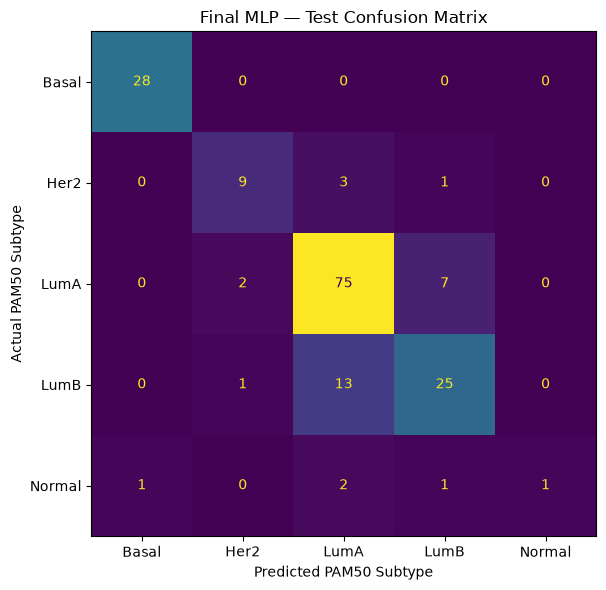

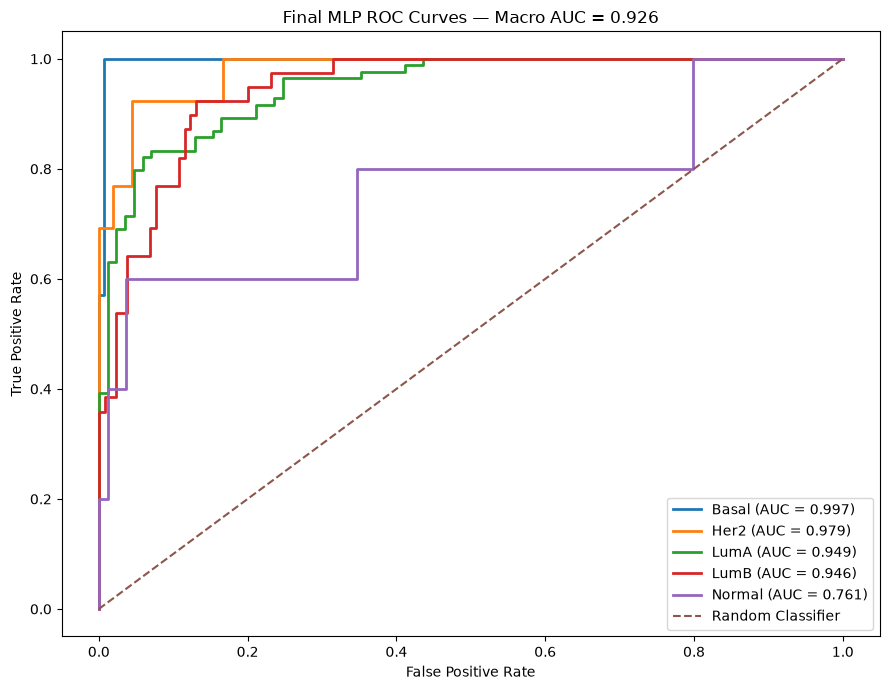

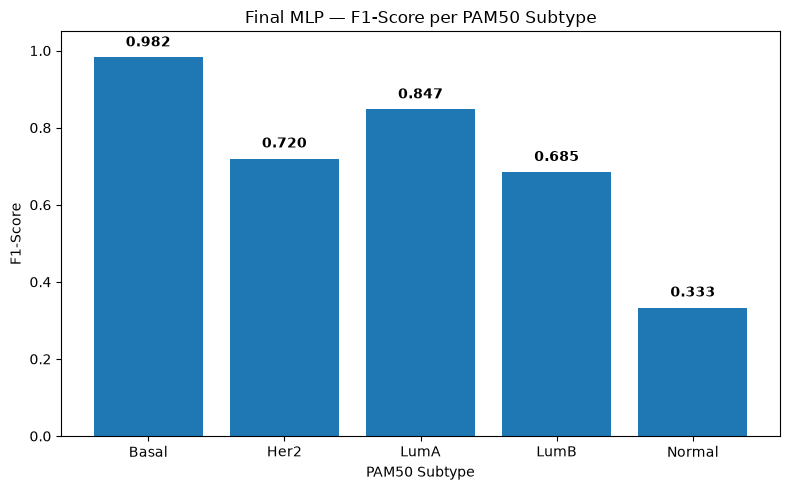


FINAL MLP — LumA vs LumB ANALYSIS


,Subtype,Support,Correct,F1-Score,Misclassified_as_Other_Luminal
0,LumA,84,75,0.8475,7
1,LumB,39,25,0.6849,13


LumA → LumB : 7
LumB → LumA : 13
LumA F1     : 0.8475
LumB F1     : 0.6849

FINAL MLP — MACRO-F1 BOOTSTRAP
Observed Macro-F1 : 0.7136
Bootstrap Mean    : 0.7074
Bootstrap STD     : 0.0563
95% Bootstrap CI  : [0.6077, 0.8180]

FINAL MLP — KEY RESULTS
Accuracy             : 0.8166
Balanced Accuracy    : 0.6852
Macro Precision      : 0.8515
Macro Recall         : 0.6852
------------------------------------------------------------------------------------------
★ Macro-F1           : 0.7136
★ Macro ROC-AUC      : 0.9263
MCC                  : 0.7189
------------------------------------------------------------------------------------------
LumA F1              : 0.8475
LumB F1              : 0.6849
LumA → LumB errors   : 7
LumB → LumA errors   : 13
------------------------------------------------------------------------------------------
95% Bootstrap CI     : [0.6077, 0.8180]

✅ CELL 20 COMPLETED — FINAL MLP TEST EVALUATION FINISHED


In [20]:
# ============================================================
# CELL 20 — FINAL MLP TEST EVALUATION
# TCGA-BRCA PAM50
#
# Metrics:
# - Accuracy
# - Balanced Accuracy
# - Precision
# - Recall
# - F1-Score
# - Macro-F1
# - Weighted F1
# - ROC-AUC Macro OvR
# - MCC
# - Per-class performance
# - Confusion Matrix
# - LumA vs LumB error analysis
# - 95% Stratified Bootstrap CI for Macro-F1
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "final_mlp_model",
    "X_test_final_dl",
    "y_test_final_dl",
    "label_encoder"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
        + "\nJalankan CELL 18 dan CELL 19 terlebih dahulu."
    )


# ============================================================
# 2. CLASS INFORMATION
# ============================================================

class_ids = np.arange(
    len(label_encoder.classes_)
)

class_names = np.asarray(
    label_encoder.classes_
)

print("=" * 90)
print("FINAL MLP — TEST EVALUATION")
print("=" * 90)

print(
    f"Test samples : {len(y_test_final_dl)}"
)

print(
    f"Classes      : {list(class_names)}"
)


# ============================================================
# 3. FINAL TEST PREDICTION
# ============================================================

y_test_prob_mlp = final_mlp_model.predict(
    X_test_final_dl,
    verbose=0
)

y_test_pred_mlp = np.argmax(
    y_test_prob_mlp,
    axis=1
)


# ============================================================
# 4. OVERALL METRICS
# ============================================================

test_accuracy_mlp = accuracy_score(
    y_test_final_dl,
    y_test_pred_mlp
)

test_balanced_accuracy_mlp = balanced_accuracy_score(
    y_test_final_dl,
    y_test_pred_mlp
)

test_precision_macro_mlp = precision_score(
    y_test_final_dl,
    y_test_pred_mlp,
    average="macro",
    zero_division=0
)

test_recall_macro_mlp = recall_score(
    y_test_final_dl,
    y_test_pred_mlp,
    average="macro",
    zero_division=0
)

test_macro_f1_mlp = f1_score(
    y_test_final_dl,
    y_test_pred_mlp,
    average="macro",
    zero_division=0
)

test_precision_weighted_mlp = precision_score(
    y_test_final_dl,
    y_test_pred_mlp,
    average="weighted",
    zero_division=0
)

test_recall_weighted_mlp = recall_score(
    y_test_final_dl,
    y_test_pred_mlp,
    average="weighted",
    zero_division=0
)

test_weighted_f1_mlp = f1_score(
    y_test_final_dl,
    y_test_pred_mlp,
    average="weighted",
    zero_division=0
)

test_mcc_mlp = matthews_corrcoef(
    y_test_final_dl,
    y_test_pred_mlp
)


# ============================================================
# 5. MULTICLASS ROC-AUC
# One-vs-Rest
# ============================================================

y_test_bin_mlp = label_binarize(
    y_test_final_dl,
    classes=class_ids
)

test_macro_auc_mlp = roc_auc_score(
    y_test_bin_mlp,
    y_test_prob_mlp,
    average="macro",
    multi_class="ovr"
)


# ============================================================
# 6. OVERALL PERFORMANCE TABLE
# ============================================================

mlp_test_summary = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro-F1",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1",
        "Macro ROC-AUC OvR",
        "MCC"
    ],

    "Score": [
        test_accuracy_mlp,
        test_balanced_accuracy_mlp,
        test_precision_macro_mlp,
        test_recall_macro_mlp,
        test_macro_f1_mlp,
        test_precision_weighted_mlp,
        test_recall_weighted_mlp,
        test_weighted_f1_mlp,
        test_macro_auc_mlp,
        test_mcc_mlp
    ]
})


print("\n" + "=" * 90)
print("FINAL MLP — OVERALL TEST PERFORMANCE")
print("=" * 90)

display(
    mlp_test_summary.round(4)
)


# ============================================================
# 7. PER-CLASS PERFORMANCE
# ============================================================

precision_per_class = precision_score(
    y_test_final_dl,
    y_test_pred_mlp,
    labels=class_ids,
    average=None,
    zero_division=0
)

recall_per_class = recall_score(
    y_test_final_dl,
    y_test_pred_mlp,
    labels=class_ids,
    average=None,
    zero_division=0
)

f1_per_class = f1_score(
    y_test_final_dl,
    y_test_pred_mlp,
    labels=class_ids,
    average=None,
    zero_division=0
)

support_per_class = np.array([
    np.sum(
        y_test_final_dl == class_id
    )
    for class_id in class_ids
])


# ============================================================
# 8. ROC-AUC PER CLASS
# ============================================================

auc_per_class = []

for i, class_name in enumerate(
    class_names
):

    class_auc = roc_auc_score(
        y_test_bin_mlp[:, i],
        y_test_prob_mlp[:, i]
    )

    auc_per_class.append(
        class_auc
    )


mlp_test_per_class = pd.DataFrame({

    "Subtype":
        class_names,

    "Precision":
        precision_per_class,

    "Recall":
        recall_per_class,

    "F1-Score":
        f1_per_class,

    "ROC-AUC":
        auc_per_class,

    "Support":
        support_per_class
})


print("\n" + "=" * 90)
print("FINAL MLP — PERFORMANCE PER PAM50 SUBTYPE")
print("=" * 90)

display(
    mlp_test_per_class.round(4)
)


# ============================================================
# 9. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 90)
print("FINAL MLP — CLASSIFICATION REPORT")
print("=" * 90)

print(
    classification_report(
        y_test_final_dl,
        y_test_pred_mlp,
        labels=class_ids,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# 10. CONFUSION MATRIX
# ============================================================

cm_test_mlp = confusion_matrix(
    y_test_final_dl,
    y_test_pred_mlp,
    labels=class_ids
)


cm_test_mlp_df = pd.DataFrame(
    cm_test_mlp,
    index=[
        f"Actual_{x}"
        for x in class_names
    ],
    columns=[
        f"Pred_{x}"
        for x in class_names
    ]
)


print("\n" + "=" * 90)
print("FINAL MLP — CONFUSION MATRIX")
print("=" * 90)

display(
    cm_test_mlp_df
)


# ============================================================
# 11. CONFUSION MATRIX FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test_mlp,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

plt.title(
    "Final MLP — Test Confusion Matrix"
)

plt.xlabel(
    "Predicted PAM50 Subtype"
)

plt.ylabel(
    "Actual PAM50 Subtype"
)

plt.tight_layout()

plt.savefig(
    "results/deep_learning/"
    "final_mlp_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. ROC CURVES
# ============================================================

plt.figure(
    figsize=(9, 7)
)

for i, class_name in enumerate(
    class_names
):

    fpr, tpr, _ = roc_curve(
        y_test_bin_mlp[:, i],
        y_test_prob_mlp[:, i]
    )

    class_auc = auc(
        fpr,
        tpr
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=(
            f"{class_name} "
            f"(AUC = {class_auc:.3f})"
        )
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    f"Final MLP ROC Curves — "
    f"Macro AUC = {test_macro_auc_mlp:.3f}"
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()

plt.savefig(
    "results/deep_learning/"
    "final_mlp_test_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 13. F1-SCORE PER SUBTYPE FIGURE
# ============================================================

plt.figure(
    figsize=(8, 5)
)

bars = plt.bar(
    class_names,
    f1_per_class
)

plt.ylim(
    0,
    1.05
)

plt.xlabel(
    "PAM50 Subtype"
)

plt.ylabel(
    "F1-Score"
)

plt.title(
    "Final MLP — F1-Score per PAM50 Subtype"
)

for bar, value in zip(
    bars,
    f1_per_class
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,

        value + 0.02,

        f"{value:.3f}",

        ha="center",
        va="bottom",
        fontweight="bold"
    )

plt.tight_layout()

plt.savefig(
    "results/deep_learning/"
    "final_mlp_f1_per_subtype.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 14. LumA vs LumB ERROR ANALYSIS
# ============================================================

LUMA_ID = int(
    label_encoder.transform(
        ["LumA"]
    )[0]
)

LUMB_ID = int(
    label_encoder.transform(
        ["LumB"]
    )[0]
)


luma_total = int(
    np.sum(
        y_test_final_dl == LUMA_ID
    )
)

lumb_total = int(
    np.sum(
        y_test_final_dl == LUMB_ID
    )
)


luma_correct = int(
    np.sum(
        (y_test_final_dl == LUMA_ID)
        &
        (y_test_pred_mlp == LUMA_ID)
    )
)

lumb_correct = int(
    np.sum(
        (y_test_final_dl == LUMB_ID)
        &
        (y_test_pred_mlp == LUMB_ID)
    )
)


luma_to_lumb = int(
    np.sum(
        (y_test_final_dl == LUMA_ID)
        &
        (y_test_pred_mlp == LUMB_ID)
    )
)

lumb_to_luma = int(
    np.sum(
        (y_test_final_dl == LUMB_ID)
        &
        (y_test_pred_mlp == LUMA_ID)
    )
)


luma_f1 = (
    f1_per_class[
        LUMA_ID
    ]
)

lumb_f1 = (
    f1_per_class[
        LUMB_ID
    ]
)


luminal_test_summary = pd.DataFrame({

    "Subtype": [
        "LumA",
        "LumB"
    ],

    "Support": [
        luma_total,
        lumb_total
    ],

    "Correct": [
        luma_correct,
        lumb_correct
    ],

    "F1-Score": [
        luma_f1,
        lumb_f1
    ],

    "Misclassified_as_Other_Luminal": [
        luma_to_lumb,
        lumb_to_luma
    ]
})


print("\n" + "=" * 90)
print("FINAL MLP — LumA vs LumB ANALYSIS")
print("=" * 90)

display(
    luminal_test_summary.round(4)
)


print(
    f"LumA → LumB : "
    f"{luma_to_lumb}"
)

print(
    f"LumB → LumA : "
    f"{lumb_to_luma}"
)

print(
    f"LumA F1     : "
    f"{luma_f1:.4f}"
)

print(
    f"LumB F1     : "
    f"{lumb_f1:.4f}"
)


# ============================================================
# 15. STRATIFIED BOOTSTRAP 95% CI
# MACRO-F1
# ============================================================

RANDOM_STATE = 42
N_BOOTSTRAP = 2000

rng = np.random.default_rng(
    RANDOM_STATE
)

bootstrap_macro_f1 = []

test_classes = np.unique(
    y_test_final_dl
)

class_indices = {

    cls: np.where(
        y_test_final_dl == cls
    )[0]

    for cls in test_classes
}


for _ in range(
    N_BOOTSTRAP
):

    sampled_indices = []

    for cls in test_classes:

        indices = class_indices[
            cls
        ]

        sampled = rng.choice(
            indices,
            size=len(indices),
            replace=True
        )

        sampled_indices.extend(
            sampled
        )

    sampled_indices = np.asarray(
        sampled_indices
    )

    boot_score = f1_score(
        y_test_final_dl[
            sampled_indices
        ],
        y_test_pred_mlp[
            sampled_indices
        ],
        average="macro",
        zero_division=0
    )

    bootstrap_macro_f1.append(
        boot_score
    )


bootstrap_macro_f1 = np.asarray(
    bootstrap_macro_f1
)


bootstrap_mean = np.mean(
    bootstrap_macro_f1
)

bootstrap_std = np.std(
    bootstrap_macro_f1
)

bootstrap_ci_lower = np.percentile(
    bootstrap_macro_f1,
    2.5
)

bootstrap_ci_upper = np.percentile(
    bootstrap_macro_f1,
    97.5
)


print("\n" + "=" * 90)
print("FINAL MLP — MACRO-F1 BOOTSTRAP")
print("=" * 90)

print(
    f"Observed Macro-F1 : "
    f"{test_macro_f1_mlp:.4f}"
)

print(
    f"Bootstrap Mean    : "
    f"{bootstrap_mean:.4f}"
)

print(
    f"Bootstrap STD     : "
    f"{bootstrap_std:.4f}"
)

print(
    f"95% Bootstrap CI  : "
    f"[{bootstrap_ci_lower:.4f}, "
    f"{bootstrap_ci_upper:.4f}]"
)


# ============================================================
# 16. FINAL PRESENTATION SUMMARY
# ============================================================

print("\n" + "=" * 90)
print("FINAL MLP — KEY RESULTS")
print("=" * 90)

print(
    f"Accuracy             : "
    f"{test_accuracy_mlp:.4f}"
)

print(
    f"Balanced Accuracy    : "
    f"{test_balanced_accuracy_mlp:.4f}"
)

print(
    f"Macro Precision      : "
    f"{test_precision_macro_mlp:.4f}"
)

print(
    f"Macro Recall         : "
    f"{test_recall_macro_mlp:.4f}"
)

print("-" * 90)

print(
    f"★ Macro-F1           : "
    f"{test_macro_f1_mlp:.4f}"
)

print(
    f"★ Macro ROC-AUC      : "
    f"{test_macro_auc_mlp:.4f}"
)

print(
    f"MCC                  : "
    f"{test_mcc_mlp:.4f}"
)

print("-" * 90)

print(
    f"LumA F1              : "
    f"{luma_f1:.4f}"
)

print(
    f"LumB F1              : "
    f"{lumb_f1:.4f}"
)

print(
    f"LumA → LumB errors   : "
    f"{luma_to_lumb}"
)

print(
    f"LumB → LumA errors   : "
    f"{lumb_to_luma}"
)

print("-" * 90)

print(
    f"95% Bootstrap CI     : "
    f"[{bootstrap_ci_lower:.4f}, "
    f"{bootstrap_ci_upper:.4f}]"
)


# ============================================================
# 17. SAVE ALL RESULTS
# ============================================================

os.makedirs(
    "results/deep_learning",
    exist_ok=True
)

mlp_test_summary.to_csv(
    "results/deep_learning/"
    "final_mlp_test_summary.csv",
    index=False
)

mlp_test_per_class.to_csv(
    "results/deep_learning/"
    "final_mlp_test_per_class.csv",
    index=False
)

cm_test_mlp_df.to_csv(
    "results/deep_learning/"
    "final_mlp_test_confusion_matrix.csv"
)

luminal_test_summary.to_csv(
    "results/deep_learning/"
    "final_mlp_luma_lumb_test.csv",
    index=False
)


bootstrap_df = pd.DataFrame({
    "Bootstrap_Macro_F1":
        bootstrap_macro_f1
})

bootstrap_df.to_csv(
    "results/deep_learning/"
    "final_mlp_macro_f1_bootstrap.csv",
    index=False
)


print("\n" + "=" * 90)
print("✅ CELL 20 COMPLETED — FINAL MLP TEST EVALUATION FINISHED")
print("=" * 90)

# CELL 21 — MLP HYPERPARAMETER SEARCH SETUP


In [21]:
# ============================================================
# CELL 21 — MLP HYPERPARAMETER SEARCH SETUP
# TCGA-BRCA PAM50
#
# IMPORTANT:
# - Hyperparameter tuning ONLY on X_train / y_train (675)
# - X_test / y_test NOT used
# - Feature selection fitted inside every CV fold
# - Scaling fitted inside every CV fold
# - Primary objective = Macro-F1
# ============================================================

import os
import gc
import random
import warnings
import numpy as np
import pandas as pd
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.model_selection import (
    StratifiedKFold,
    ParameterSampler
)

from sklearn.preprocessing import StandardScaler

from sklearn.utils.class_weight import (
    compute_class_weight
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)

os.makedirs(
    "results/deep_learning/tuning",
    exist_ok=True
)


# ============================================================
# VALIDATION MACRO-F1 CALLBACK
# ============================================================

class ValidationMacroF1(
    tf.keras.callbacks.Callback
):

    def __init__(
        self,
        x_val,
        y_val
    ):
        super().__init__()

        self.x_val = x_val
        self.y_val = np.asarray(y_val)

        self.macro_f1_history = []


    def on_epoch_end(
        self,
        epoch,
        logs=None
    ):

        if logs is None:
            logs = {}

        y_prob = self.model.predict(
            self.x_val,
            verbose=0
        )

        y_pred = np.argmax(
            y_prob,
            axis=1
        )

        score = f1_score(
            self.y_val,
            y_pred,
            average="macro",
            zero_division=0
        )

        self.macro_f1_history.append(
            score
        )

        logs["val_macro_f1"] = score


# ============================================================
# MODEL BUILDER
# ============================================================

def build_tunable_mlp(
    input_dim,
    n_classes,
    hidden1,
    hidden2,
    dropout1,
    dropout2,
    learning_rate,
    l2_value,
    random_state=42
):

    tf.keras.backend.clear_session()

    tf.keras.utils.set_random_seed(
        random_state
    )

    model = keras.Sequential([

        layers.Input(
            shape=(int(input_dim),)
        ),

        layers.Dense(
            int(hidden1),
            kernel_regularizer=regularizers.l2(
                float(l2_value)
            )
        ),

        layers.BatchNormalization(),

        layers.Activation(
            "relu"
        ),

        layers.Dropout(
            float(dropout1)
        ),

        layers.Dense(
            int(hidden2),
            kernel_regularizer=regularizers.l2(
                float(l2_value)
            )
        ),

        layers.BatchNormalization(),

        layers.Activation(
            "relu"
        ),

        layers.Dropout(
            float(dropout2)
        ),

        layers.Dense(
            int(n_classes),
            activation="softmax"
        )
    ])


    model.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=float(
                learning_rate
            )
        ),

        loss=(
            "sparse_categorical_crossentropy"
        ),

        metrics=[
            "accuracy"
        ]
    )

    return model


# ============================================================
# SEARCH SPACE
# ============================================================

mlp_search_space = {

    "top_k": [
        500,
        1000,
        2000
    ],

    "hidden1": [
        64,
        128,
        256
    ],

    "hidden2": [
        16,
        32,
        64
    ],

    "dropout1": [
        0.30,
        0.40,
        0.50
    ],

    "dropout2": [
        0.20,
        0.30,
        0.40
    ],

    "learning_rate": [
        0.0001,
        0.0005,
        0.001
    ],

    "l2_value": [
        0.00001,
        0.0001,
        0.001
    ],

    "batch_size": [
        16,
        32,
        64
    ],

    "class_weight_mode": [
        "balanced",
        "none"
    ]
}


# ============================================================
# SEARCH CONFIGURATION
# ============================================================

N_TRIALS = 15

CV_FOLDS = 5

MAX_EPOCHS_TUNING = 100

EARLY_STOPPING_PATIENCE = 12


print("=" * 90)
print("MLP HYPERPARAMETER SEARCH SETUP")
print("=" * 90)

print(
    f"Development samples : {len(X_train)}"
)

print(
    f"Features            : {X_train.shape[1]:,}"
)

print(
    f"Random trials       : {N_TRIALS}"
)

print(
    f"CV folds            : {CV_FOLDS}"
)

print(
    f"Maximum epochs      : {MAX_EPOCHS_TUNING}"
)

print(
    f"Early-stop patience : {EARLY_STOPPING_PATIENCE}"
)

print(
    f"Primary objective   : Macro-F1"
)

print(
    "\nEstimated model fits:",
    N_TRIALS * CV_FOLDS
)

print(
    "\n✅ CELL 21 COMPLETED — SEARCH SPACE READY"
)

MLP HYPERPARAMETER SEARCH SETUP
Development samples : 675
Features            : 20,530
Random trials       : 15
CV folds            : 5
Maximum epochs      : 100
Early-stop patience : 12
Primary objective   : Macro-F1

Estimated model fits: 75

✅ CELL 21 COMPLETED — SEARCH SPACE READY


# CELL 22 — RANDOM HYPERPARAMETER SEARCH


In [22]:
# ============================================================
# CELL 22 — RANDOM HYPERPARAMETER SEARCH
# STRATIFIED 5-FOLD CV
# TCGA-BRCA PAM50
# ============================================================

from sklearn.model_selection import (
    StratifiedKFold,
    ParameterSampler
)

import numpy as np
import pandas as pd
import tensorflow as tf
import gc


# ============================================================
# 1. GENERATE RANDOM CONFIGURATIONS
# ============================================================

parameter_samples = list(
    ParameterSampler(
        mlp_search_space,
        n_iter=N_TRIALS,
        random_state=RANDOM_STATE
    )
)


cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE
)


y_train_array_search = np.asarray(
    y_train,
    dtype=np.int32
)


# ============================================================
# 2. RESULT STORAGE
# ============================================================

all_fold_results = []

all_trial_results = []


# ============================================================
# 3. START RANDOM SEARCH
# ============================================================

print("=" * 100)
print("STARTING MLP RANDOM SEARCH")
print("=" * 100)


for trial_number, config in enumerate(
    parameter_samples,
    start=1
):

    print("\n" + "=" * 100)

    print(
        f"TRIAL {trial_number}/{N_TRIALS}"
    )

    print(config)

    print("=" * 100)


    trial_fold_results = []


    # ========================================================
    # CV LOOP
    # ========================================================

    for fold_number, (
        train_idx,
        val_idx
    ) in enumerate(
        cv.split(
            X_train,
            y_train_array_search
        ),
        start=1
    ):

        fold_seed = (
            RANDOM_STATE
            + trial_number * 100
            + fold_number
        )


        # ----------------------------------------------------
        # Fold datasets
        # ----------------------------------------------------

        X_fold_train = X_train.iloc[
            train_idx
        ].copy()

        X_fold_val = X_train.iloc[
            val_idx
        ].copy()

        y_fold_train = (
            y_train_array_search[
                train_idx
            ]
        )

        y_fold_val = (
            y_train_array_search[
                val_idx
            ]
        )


        # ----------------------------------------------------
        # Feature selection
        # FIT ONLY ON FOLD TRAIN
        # ----------------------------------------------------

        selector = TopVarianceGenes(
            k=int(
                config["top_k"]
            )
        )

        selector.fit(
            X_fold_train
        )

        X_fold_train_selected = (
            selector.transform(
                X_fold_train
            )
        )

        X_fold_val_selected = (
            selector.transform(
                X_fold_val
            )
        )


        # ----------------------------------------------------
        # Standardization
        # FIT ONLY ON FOLD TRAIN
        # ----------------------------------------------------

        scaler = StandardScaler()

        X_fold_train_scaled = (
            scaler
            .fit_transform(
                X_fold_train_selected
            )
            .astype(
                np.float32
            )
        )

        X_fold_val_scaled = (
            scaler
            .transform(
                X_fold_val_selected
            )
            .astype(
                np.float32
            )
        )


        # ----------------------------------------------------
        # Class weights
        # ----------------------------------------------------

        if (
            config[
                "class_weight_mode"
            ]
            == "balanced"
        ):

            fold_classes = np.unique(
                y_fold_train
            )

            fold_weights = compute_class_weight(
                class_weight="balanced",
                classes=fold_classes,
                y=y_fold_train
            )

            fold_class_weight = {

                int(c):
                    float(w)

                for c, w in zip(
                    fold_classes,
                    fold_weights
                )
            }

        else:

            fold_class_weight = None


        # ----------------------------------------------------
        # Build model
        # ----------------------------------------------------

        model = build_tunable_mlp(

            input_dim=int(
                config["top_k"]
            ),

            n_classes=len(
                label_encoder.classes_
            ),

            hidden1=config[
                "hidden1"
            ],

            hidden2=config[
                "hidden2"
            ],

            dropout1=config[
                "dropout1"
            ],

            dropout2=config[
                "dropout2"
            ],

            learning_rate=config[
                "learning_rate"
            ],

            l2_value=config[
                "l2_value"
            ],

            random_state=fold_seed
        )


        # ----------------------------------------------------
        # Callbacks
        # ----------------------------------------------------

        macro_f1_callback = (
            ValidationMacroF1(

                X_fold_val_scaled,
                y_fold_val
            )
        )


        early_stopping = (
            tf.keras.callbacks.EarlyStopping(

                monitor="val_macro_f1",

                mode="max",

                patience=(
                    EARLY_STOPPING_PATIENCE
                ),

                min_delta=0.001,

                restore_best_weights=True,

                verbose=0
            )
        )


        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------

        history_fold = model.fit(

            X_fold_train_scaled,
            y_fold_train,

            validation_data=(
                X_fold_val_scaled,
                y_fold_val
            ),

            epochs=(
                MAX_EPOCHS_TUNING
            ),

            batch_size=int(
                config["batch_size"]
            ),

            class_weight=(
                fold_class_weight
            ),

            callbacks=[
                macro_f1_callback,
                early_stopping
            ],

            verbose=0
        )


        # ----------------------------------------------------
        # Best epoch
        # ----------------------------------------------------

        f1_history = np.asarray(
            macro_f1_callback
            .macro_f1_history
        )

        best_epoch_fold = (
            int(
                np.argmax(
                    f1_history
                )
            )
            + 1
        )


        # ----------------------------------------------------
        # Validation prediction
        # ----------------------------------------------------

        y_fold_prob = model.predict(
            X_fold_val_scaled,
            verbose=0
        )

        y_fold_pred = np.argmax(
            y_fold_prob,
            axis=1
        )


        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        macro_f1 = f1_score(
            y_fold_val,
            y_fold_pred,
            average="macro",
            zero_division=0
        )

        accuracy = accuracy_score(
            y_fold_val,
            y_fold_pred
        )

        balanced_accuracy = (
            balanced_accuracy_score(
                y_fold_val,
                y_fold_pred
            )
        )

        mcc = matthews_corrcoef(
            y_fold_val,
            y_fold_pred
        )


        per_class_f1 = f1_score(
            y_fold_val,
            y_fold_pred,
            labels=np.arange(
                len(
                    label_encoder.classes_
                )
            ),
            average=None,
            zero_division=0
        )


        luma_id = int(
            label_encoder.transform(
                ["LumA"]
            )[0]
        )

        lumb_id = int(
            label_encoder.transform(
                ["LumB"]
            )[0]
        )


        fold_result = {

            "Trial":
                trial_number,

            "Fold":
                fold_number,

            "Macro_F1":
                macro_f1,

            "Accuracy":
                accuracy,

            "Balanced_Accuracy":
                balanced_accuracy,

            "MCC":
                mcc,

            "LumA_F1":
                per_class_f1[
                    luma_id
                ],

            "LumB_F1":
                per_class_f1[
                    lumb_id
                ],

            "Best_Epoch":
                best_epoch_fold
        }


        trial_fold_results.append(
            fold_result
        )

        all_fold_results.append(
            {
                **config,
                **fold_result
            }
        )


        print(
            f"Fold {fold_number} | "
            f"Macro-F1={macro_f1:.4f} | "
            f"LumA={per_class_f1[luma_id]:.4f} | "
            f"LumB={per_class_f1[lumb_id]:.4f} | "
            f"Epoch={best_epoch_fold}"
        )


        # ----------------------------------------------------
        # Cleanup
        # ----------------------------------------------------

        del model

        tf.keras.backend.clear_session()

        gc.collect()


    # ========================================================
    # TRIAL SUMMARY
    # ========================================================

    trial_df = pd.DataFrame(
        trial_fold_results
    )


    trial_summary = {

        "Trial":
            trial_number,

        **config,

        "Mean_Macro_F1":
            trial_df[
                "Macro_F1"
            ].mean(),

        "STD_Macro_F1":
            trial_df[
                "Macro_F1"
            ].std(),

        "Mean_Accuracy":
            trial_df[
                "Accuracy"
            ].mean(),

        "Mean_Balanced_Accuracy":
            trial_df[
                "Balanced_Accuracy"
            ].mean(),

        "Mean_MCC":
            trial_df[
                "MCC"
            ].mean(),

        "Mean_LumA_F1":
            trial_df[
                "LumA_F1"
            ].mean(),

        "Mean_LumB_F1":
            trial_df[
                "LumB_F1"
            ].mean(),

        "Mean_Best_Epoch":
            trial_df[
                "Best_Epoch"
            ].mean(),

        "Median_Best_Epoch":
            trial_df[
                "Best_Epoch"
            ].median()
    }


    all_trial_results.append(
        trial_summary
    )


    print("\nTRIAL SUMMARY")

    print(
        f"Mean Macro-F1 : "
        f"{trial_summary['Mean_Macro_F1']:.4f}"
    )

    print(
        f"STD Macro-F1  : "
        f"{trial_summary['STD_Macro_F1']:.4f}"
    )

    print(
        f"Mean LumA F1  : "
        f"{trial_summary['Mean_LumA_F1']:.4f}"
    )

    print(
        f"Mean LumB F1  : "
        f"{trial_summary['Mean_LumB_F1']:.4f}"
    )


    # --------------------------------------------------------
    # SAVE PROGRESS AFTER EACH TRIAL
    # --------------------------------------------------------

    pd.DataFrame(
        all_trial_results
    ).to_csv(

        "results/deep_learning/tuning/"
        "mlp_random_search_trials.csv",

        index=False
    )


# ============================================================
# 4. SAVE ALL FOLD RESULTS
# ============================================================

mlp_tuning_fold_results = pd.DataFrame(
    all_fold_results
)

mlp_tuning_results = pd.DataFrame(
    all_trial_results
)


mlp_tuning_fold_results.to_csv(

    "results/deep_learning/tuning/"
    "mlp_random_search_fold_results.csv",

    index=False
)


print("\n" + "=" * 100)
print("✅ CELL 22 COMPLETED — RANDOM SEARCH FINISHED")
print("=" * 100)

print(
    f"Total trials : "
    f"{len(mlp_tuning_results)}"
)

print(
    f"Total fits   : "
    f"{len(mlp_tuning_fold_results)}"
)

STARTING MLP RANDOM SEARCH

TRIAL 1/15
{'top_k': 1000, 'learning_rate': 0.001, 'l2_value': 1e-05, 'hidden2': 64, 'hidden1': 256, 'dropout2': 0.4, 'dropout1': 0.3, 'class_weight_mode': 'none', 'batch_size': 32}
Fold 1 | Macro-F1=0.7911 | LumA=0.9185 | LumB=0.8667 | Epoch=16
Fold 2 | Macro-F1=0.7012 | LumA=0.8889 | LumB=0.7812 | Epoch=18
Fold 3 | Macro-F1=0.8946 | LumA=0.8971 | LumB=0.7667 | Epoch=18
Fold 4 | Macro-F1=0.8295 | LumA=0.8955 | LumB=0.8125 | Epoch=16
Fold 5 | Macro-F1=0.7772 | LumA=0.8806 | LumB=0.7812 | Epoch=18

TRIAL SUMMARY
Mean Macro-F1 : 0.7987
STD Macro-F1  : 0.0710
Mean LumA F1  : 0.8961
Mean LumB F1  : 0.8017

TRIAL 2/15
{'top_k': 2000, 'learning_rate': 0.0005, 'l2_value': 0.001, 'hidden2': 32, 'hidden1': 128, 'dropout2': 0.2, 'dropout1': 0.4, 'class_weight_mode': 'balanced', 'batch_size': 16}
Fold 1 | Macro-F1=0.8653 | LumA=0.9291 | LumB=0.8788 | Epoch=9
Fold 2 | Macro-F1=0.8650 | LumA=0.8618 | LumB=0.8056 | Epoch=8
Fold 3 | Macro-F1=0.8177 | LumA=0.8800 | LumB=0.7

# CELL 23 — RANK MLP HYPERPARAMETER TRIALS


In [23]:
# ============================================================
# CELL 23 — RANK MLP HYPERPARAMETER TRIALS
# Primary ranking = Mean Macro-F1
# Secondary = LumB F1
# ============================================================

import pandas as pd
import numpy as np


# ============================================================
# 1. SORT TRIALS
# ============================================================

mlp_tuning_ranking = (

    mlp_tuning_results

    .sort_values(
        by=[
            "Mean_Macro_F1",
            "Mean_LumB_F1",
            "Mean_MCC"
        ],

        ascending=[
            False,
            False,
            False
        ]
    )

    .reset_index(
        drop=True
    )
)


mlp_tuning_ranking.insert(
    0,
    "Rank",
    np.arange(
        1,
        len(
            mlp_tuning_ranking
        ) + 1
    )
)


# ============================================================
# 2. DISPLAY RANKING
# ============================================================

ranking_columns = [

    "Rank",
    "Trial",

    "top_k",

    "hidden1",
    "hidden2",

    "dropout1",
    "dropout2",

    "learning_rate",
    "l2_value",

    "batch_size",
    "class_weight_mode",

    "Mean_Macro_F1",
    "STD_Macro_F1",

    "Mean_LumA_F1",
    "Mean_LumB_F1",

    "Mean_Accuracy",
    "Mean_Balanced_Accuracy",

    "Mean_MCC",

    "Median_Best_Epoch"
]


print("=" * 110)
print("MLP HYPERPARAMETER TUNING — FINAL RANKING")
print("=" * 110)

display(
    mlp_tuning_ranking[
        ranking_columns
    ]
    .round(4)
)


# ============================================================
# 3. TOP 5
# ============================================================

print("\n" + "=" * 110)
print("TOP 5 MLP CONFIGURATIONS")
print("=" * 110)

display(
    mlp_tuning_ranking[
        ranking_columns
    ]
    .head(5)
    .round(4)
)


# ============================================================
# 4. SAVE
# ============================================================

mlp_tuning_ranking.to_csv(

    "results/deep_learning/tuning/"
    "mlp_hyperparameter_ranking.csv",

    index=False
)


print(
    "\n✅ CELL 23 COMPLETED — "
    "HYPERPARAMETER RANKING READY"
)

MLP HYPERPARAMETER TUNING — FINAL RANKING


,Rank,Trial,top_k,hidden1,hidden2,dropout1,dropout2,learning_rate,l2_value,batch_size,class_weight_mode,Mean_Macro_F1,STD_Macro_F1,Mean_LumA_F1,Mean_LumB_F1,Mean_Accuracy,Mean_Balanced_Accuracy,Mean_MCC,Median_Best_Epoch
0,1,3,2000,64,32,0.4,0.3,0.0010,0.0001,32,balanced,0.8559,0.0391,0.9077,0.8101,0.8844,0.8736,0.8313,26.0
1,2,2,2000,128,32,0.4,0.2,0.0005,0.0010,16,balanced,0.8401,0.0252,0.8911,0.8136,0.8741,0.8677,0.8207,9.0
2,3,4,1000,128,16,0.4,0.2,0.0010,0.0000,32,balanced,0.8357,0.0323,0.9062,0.8126,0.8815,0.8525,0.8272,19.0
3,4,9,1000,256,64,0.3,0.3,0.0010,0.0000,16,balanced,0.8343,0.0415,0.8960,0.7914,0.8726,0.8383,0.8150,17.0
4,5,11,1000,256,64,0.4,0.3,0.0010,0.0001,32,balanced,0.8205,0.0511,0.8729,0.7760,0.8578,0.8357,0.7926,11.0
5,6,10,1000,64,32,0.3,0.2,0.0010,0.0010,32,balanced,0.8190,0.0525,0.8827,0.7614,0.8593,0.8314,0.7935,20.0
6,7,12,2000,256,32,0.3,0.4,0.0010,0.0010,64,none,0.8128,0.0765,0.8993,0.7953,0.8741,0.8080,0.8141,16.0
7,8,8,1000,256,32,0.5,0.3,0.0001,0.0000,32,balanced,0.8056,0.0636,0.8638,0.7479,0.8400,0.8463,0.7715,67.0
8,9,13,2000,256,16,0.3,0.3,0.0005,0.0010,64,none,0.8039,0.0639,0.8889,0.7880,0.8652,0.8090,0.8007,16.0
9,10,1,1000,256,64,0.3,0.4,0.0010,0.0000,32,none,0.7987,0.0710,0.8961,0.8017,0.8756,0.7851,0.8126,18.0



TOP 5 MLP CONFIGURATIONS


,Rank,Trial,top_k,hidden1,hidden2,dropout1,dropout2,learning_rate,l2_value,batch_size,class_weight_mode,Mean_Macro_F1,STD_Macro_F1,Mean_LumA_F1,Mean_LumB_F1,Mean_Accuracy,Mean_Balanced_Accuracy,Mean_MCC,Median_Best_Epoch
0,1,3,2000,64,32,0.4,0.3,0.0010,0.0001,32,balanced,0.8559,0.0391,0.9077,0.8101,0.8844,0.8736,0.8313,26.0
1,2,2,2000,128,32,0.4,0.2,0.0005,0.0010,16,balanced,0.8401,0.0252,0.8911,0.8136,0.8741,0.8677,0.8207,9.0
2,3,4,1000,128,16,0.4,0.2,0.0010,0.0000,32,balanced,0.8357,0.0323,0.9062,0.8126,0.8815,0.8525,0.8272,19.0
3,4,9,1000,256,64,0.3,0.3,0.0010,0.0000,16,balanced,0.8343,0.0415,0.8960,0.7914,0.8726,0.8383,0.8150,17.0
4,5,11,1000,256,64,0.4,0.3,0.0010,0.0001,32,balanced,0.8205,0.0511,0.8729,0.7760,0.8578,0.8357,0.7926,11.0



✅ CELL 23 COMPLETED — HYPERPARAMETER RANKING READY


# CELL 24 — SELECT BEST MLP CONFIGURATION


In [24]:
# ============================================================
# CELL 24 — SELECT BEST MLP CONFIGURATION
# FREEZE HYPERPARAMETERS
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# 1. BEST ROW
# ============================================================

best_mlp_row = (
    mlp_tuning_ranking
    .iloc[0]
)


# ============================================================
# 2. BEST CONFIGURATION
# ============================================================

best_mlp_config = {

    "top_k":
        int(
            best_mlp_row[
                "top_k"
            ]
        ),

    "hidden1":
        int(
            best_mlp_row[
                "hidden1"
            ]
        ),

    "hidden2":
        int(
            best_mlp_row[
                "hidden2"
            ]
        ),

    "dropout1":
        float(
            best_mlp_row[
                "dropout1"
            ]
        ),

    "dropout2":
        float(
            best_mlp_row[
                "dropout2"
            ]
        ),

    "learning_rate":
        float(
            best_mlp_row[
                "learning_rate"
            ]
        ),

    "l2_value":
        float(
            best_mlp_row[
                "l2_value"
            ]
        ),

    "batch_size":
        int(
            best_mlp_row[
                "batch_size"
            ]
        ),

    "class_weight_mode":
        str(
            best_mlp_row[
                "class_weight_mode"
            ]
        )
}


# ============================================================
# 3. FINAL EPOCH
# ============================================================

FINAL_TUNED_EPOCHS = int(
    round(
        best_mlp_row[
            "Median_Best_Epoch"
        ]
    )
)

FINAL_TUNED_EPOCHS = max(
    1,
    FINAL_TUNED_EPOCHS
)


# ============================================================
# 4. PRINT
# ============================================================

print("=" * 90)
print("BEST MLP HYPERPARAMETERS — FROZEN")
print("=" * 90)

for key, value in (
    best_mlp_config.items()
):

    print(
        f"{key:<20}: {value}"
    )


print("-" * 90)

print(
    f"Mean CV Macro-F1  : "
    f"{best_mlp_row['Mean_Macro_F1']:.4f}"
)

print(
    f"STD CV Macro-F1   : "
    f"{best_mlp_row['STD_Macro_F1']:.4f}"
)

print(
    f"Mean LumA F1      : "
    f"{best_mlp_row['Mean_LumA_F1']:.4f}"
)

print(
    f"Mean LumB F1      : "
    f"{best_mlp_row['Mean_LumB_F1']:.4f}"
)

print(
    f"Mean MCC           : "
    f"{best_mlp_row['Mean_MCC']:.4f}"
)

print(
    f"Final epochs       : "
    f"{FINAL_TUNED_EPOCHS}"
)


print("\nIMPORTANT:")

print(
    "✅ Hyperparameters selected ONLY using "
    "development cross-validation."
)

print(
    "✅ Test performance was NOT used "
    "to choose the winning trial."
)

print(
    "✅ Configuration is now FROZEN."
)

print(
    "\n✅ CELL 24 COMPLETED — BEST MLP CONFIGURATION SELECTED"
)

BEST MLP HYPERPARAMETERS — FROZEN
top_k               : 2000
hidden1             : 64
hidden2             : 32
dropout1            : 0.4
dropout2            : 0.3
learning_rate       : 0.001
l2_value            : 0.0001
batch_size          : 32
class_weight_mode   : balanced
------------------------------------------------------------------------------------------
Mean CV Macro-F1  : 0.8559
STD CV Macro-F1   : 0.0391
Mean LumA F1      : 0.9077
Mean LumB F1      : 0.8101
Mean MCC           : 0.8313
Final epochs       : 26

IMPORTANT:
✅ Hyperparameters selected ONLY using development cross-validation.
✅ Test performance was NOT used to choose the winning trial.
✅ Configuration is now FROZEN.

✅ CELL 24 COMPLETED — BEST MLP CONFIGURATION SELECTED


# CELL 25 — FINAL PREPROCESSING FOR TUNED MLP


In [25]:
# ============================================================
# CELL 25 — FINAL PREPROCESSING FOR TUNED MLP
# Fit selector and scaler on all 675 development samples
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.utils.class_weight import (
    compute_class_weight
)


# ============================================================
# 1. FEATURE SELECTION
# ============================================================

tuned_final_selector = (
    TopVarianceGenes(
        k=best_mlp_config[
            "top_k"
        ]
    )
)


tuned_final_selector.fit(
    X_train
)


X_train_tuned_mlp = (
    tuned_final_selector
    .transform(
        X_train
    )
)

X_test_tuned_mlp = (
    tuned_final_selector
    .transform(
        X_test
    )
)


# ============================================================
# 2. SCALING
# ============================================================

tuned_final_scaler = (
    StandardScaler()
)


X_train_tuned_mlp = (
    tuned_final_scaler
    .fit_transform(
        X_train_tuned_mlp
    )
    .astype(
        np.float32
    )
)


X_test_tuned_mlp = (
    tuned_final_scaler
    .transform(
        X_test_tuned_mlp
    )
    .astype(
        np.float32
    )
)


# ============================================================
# 3. TARGET ARRAYS
# ============================================================

y_train_tuned_mlp = np.asarray(
    y_train,
    dtype=np.int32
)

y_test_tuned_mlp = np.asarray(
    y_test,
    dtype=np.int32
)


# ============================================================
# 4. CLASS WEIGHTS
# ============================================================

if (
    best_mlp_config[
        "class_weight_mode"
    ]
    == "balanced"
):

    tuned_classes = np.unique(
        y_train_tuned_mlp
    )

    tuned_weights = (
        compute_class_weight(

            class_weight="balanced",

            classes=tuned_classes,

            y=y_train_tuned_mlp
        )
    )

    tuned_final_class_weight = {

        int(c):
            float(w)

        for c, w in zip(
            tuned_classes,
            tuned_weights
        )
    }

else:

    tuned_final_class_weight = None


# ============================================================
# 5. SELECTED GENES
# ============================================================

tuned_selected_genes = (
    tuned_final_selector
    .get_feature_names_out(
        X_train.columns
    )
)


# ============================================================
# 6. CHECK
# ============================================================

print("=" * 90)
print("TUNED FINAL MLP — DATA PREPARATION")
print("=" * 90)

print(
    f"Selected genes : "
    f"{len(tuned_selected_genes)}"
)

print(
    f"Train shape    : "
    f"{X_train_tuned_mlp.shape}"
)

print(
    f"Test shape     : "
    f"{X_test_tuned_mlp.shape}"
)

print(
    f"Train NaN      : "
    f"{np.isnan(X_train_tuned_mlp).sum()}"
)

print(
    f"Test NaN       : "
    f"{np.isnan(X_test_tuned_mlp).sum()}"
)

print(
    f"Train Inf      : "
    f"{np.isinf(X_train_tuned_mlp).sum()}"
)

print(
    f"Test Inf       : "
    f"{np.isinf(X_test_tuned_mlp).sum()}"
)

print(
    f"Class weight   : "
    f"{tuned_final_class_weight}"
)


# ============================================================
# 7. SAVE SELECTED GENES
# ============================================================

pd.DataFrame({

    "Rank":
        np.arange(
            1,
            len(
                tuned_selected_genes
            ) + 1
        ),

    "Gene":
        tuned_selected_genes

}).to_csv(

    "results/deep_learning/tuning/"
    "tuned_mlp_selected_genes.csv",

    index=False
)


print(
    "\n✅ CELL 25 COMPLETED — "
    "TUNED FINAL DATA READY"
)

TUNED FINAL MLP — DATA PREPARATION
Selected genes : 2000
Train shape    : (675, 2000)
Test shape     : (169, 2000)
Train NaN      : 0
Test NaN       : 0
Train Inf      : 0
Test Inf       : 0
Class weight   : {0: 1.1946902654867257, 1: 2.5, 2: 0.40059347181008903, 3: 0.8823529411764706, 4: 7.5}

✅ CELL 25 COMPLETED — TUNED FINAL DATA READY


# CELL 26 — TRAIN FINAL TUNED MLP


In [26]:
# ============================================================
# CELL 26 — TRAIN FINAL TUNED MLP
# All 675 development samples
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf


# ============================================================
# 1. RESET
# ============================================================

tf.keras.backend.clear_session()

tf.keras.utils.set_random_seed(
    RANDOM_STATE
)


# ============================================================
# 2. BUILD FINAL TUNED MODEL
# ============================================================

tuned_final_mlp_model = (
    build_tunable_mlp(

        input_dim=(
            X_train_tuned_mlp.shape[1]
        ),

        n_classes=len(
            label_encoder.classes_
        ),

        hidden1=(
            best_mlp_config[
                "hidden1"
            ]
        ),

        hidden2=(
            best_mlp_config[
                "hidden2"
            ]
        ),

        dropout1=(
            best_mlp_config[
                "dropout1"
            ]
        ),

        dropout2=(
            best_mlp_config[
                "dropout2"
            ]
        ),

        learning_rate=(
            best_mlp_config[
                "learning_rate"
            ]
        ),

        l2_value=(
            best_mlp_config[
                "l2_value"
            ]
        ),

        random_state=RANDOM_STATE
    )
)


# ============================================================
# 3. MODEL SUMMARY
# ============================================================

print("=" * 90)
print("FINAL TUNED MLP ARCHITECTURE")
print("=" * 90)

tuned_final_mlp_model.summary()


# ============================================================
# 4. TRAIN
# ============================================================

print("\n" + "=" * 90)
print("TRAINING FINAL TUNED MLP")
print("=" * 90)

print(
    f"Epochs     : "
    f"{FINAL_TUNED_EPOCHS}"
)

print(
    f"Batch size : "
    f"{best_mlp_config['batch_size']}"
)


tuned_final_history = (
    tuned_final_mlp_model.fit(

        X_train_tuned_mlp,

        y_train_tuned_mlp,

        epochs=(
            FINAL_TUNED_EPOCHS
        ),

        batch_size=(
            best_mlp_config[
                "batch_size"
            ]
        ),

        class_weight=(
            tuned_final_class_weight
        ),

        shuffle=True,

        verbose=1
    )
)


# ============================================================
# 5. SAVE MODEL
# ============================================================

tuned_final_mlp_model.save(

    "results/deep_learning/tuning/"
    "final_tuned_mlp.keras"
)


# ============================================================
# 6. SAVE HISTORY
# ============================================================

tuned_history_df = pd.DataFrame(
    tuned_final_history.history
)

tuned_history_df.insert(

    0,
    "Epoch",

    np.arange(
        1,
        len(
            tuned_history_df
        ) + 1
    )
)


tuned_history_df.to_csv(

    "results/deep_learning/tuning/"
    "final_tuned_mlp_history.csv",

    index=False
)


print("\n" + "=" * 90)
print("FINAL TRAINING SUMMARY")
print("=" * 90)

print(
    f"Epochs completed : "
    f"{len(tuned_history_df)}"
)

print(
    f"Training loss    : "
    f"{tuned_history_df['loss'].iloc[-1]:.4f}"
)

print(
    f"Training accuracy: "
    f"{tuned_history_df['accuracy'].iloc[-1]:.4f}"
)

print(
    "\n✅ CELL 26 COMPLETED — "
    "FINAL TUNED MLP TRAINED"
)

FINAL TUNED MLP ARCHITECTURE


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │       128,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,693 (510.52 KB)

 Trainable params: 130,501 (509.77 KB)

 Non-trainable params: 192 (768.00 B)


TRAINING FINAL TUNED MLP
Epochs     : 26
Batch size : 32
Epoch 1/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.3733 - loss: 1.2062
Epoch 2/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5481 - loss: 0.7883
Epoch 3/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6015 - loss: 0.6770
Epoch 4/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7096 - loss: 0.6079
Epoch 5/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7541 - loss: 0.5606
Epoch 6/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7941 - loss: 0.5389
Epoch 7/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7956 - loss: 0.4613
Epoch 8/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8207 - loss: 0.4509
Epoch 9/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8400 - loss: 0.3730
Epoch 10/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8770 - loss: 0.3276
Epoch 11/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8963 - loss: 0.3056
Epoch 12/26
22/2

# CELL 27 — TUNED MLP TEST EVALUATION


In [27]:
# ============================================================
# CELL 27 — TUNED MLP TEST EVALUATION
# + FINAL LINEAR SVM COMPARISON
#
# NOTE:
# Test set was previously inspected.
# Treat this as POST-HOC hold-out comparison.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)

from sklearn.preprocessing import (
    label_binarize
)


# ============================================================
# 1. CLASS INFO
# ============================================================

class_ids = np.arange(
    len(label_encoder.classes_)
)

class_names = np.asarray(
    label_encoder.classes_
)


# ============================================================
# 2. TUNED MLP PREDICTION
# ============================================================

y_test_prob_tuned_mlp = (
    tuned_final_mlp_model
    .predict(
        X_test_tuned_mlp,
        verbose=0
    )
)

y_test_pred_tuned_mlp = (
    np.argmax(
        y_test_prob_tuned_mlp,
        axis=1
    )
)


# ============================================================
# 3. TUNED MLP METRICS
# ============================================================

tuned_accuracy = accuracy_score(
    y_test_tuned_mlp,
    y_test_pred_tuned_mlp
)

tuned_balanced_accuracy = (
    balanced_accuracy_score(
        y_test_tuned_mlp,
        y_test_pred_tuned_mlp
    )
)

tuned_macro_precision = (
    precision_score(
        y_test_tuned_mlp,
        y_test_pred_tuned_mlp,
        average="macro",
        zero_division=0
    )
)

tuned_macro_recall = (
    recall_score(
        y_test_tuned_mlp,
        y_test_pred_tuned_mlp,
        average="macro",
        zero_division=0
    )
)

tuned_macro_f1 = f1_score(
    y_test_tuned_mlp,
    y_test_pred_tuned_mlp,
    average="macro",
    zero_division=0
)

tuned_mcc = matthews_corrcoef(
    y_test_tuned_mlp,
    y_test_pred_tuned_mlp
)


y_test_bin = label_binarize(
    y_test_tuned_mlp,
    classes=class_ids
)


tuned_auc_per_class = []

for i in class_ids:

    tuned_auc_per_class.append(

        roc_auc_score(
            y_test_bin[:, i],
            y_test_prob_tuned_mlp[:, i]
        )
    )


tuned_macro_auc = np.mean(
    tuned_auc_per_class
)


tuned_f1_per_class = f1_score(
    y_test_tuned_mlp,
    y_test_pred_tuned_mlp,
    labels=class_ids,
    average=None,
    zero_division=0
)


# ============================================================
# 4. TRAIN FINAL SVM REFERENCE
# Tuned SVM configuration from previous experiment
# C = 0.01, linear kernel
# ============================================================

svm_final_selector = TopVarianceGenes(
    k=2000
)

svm_final_selector.fit(
    X_train
)


X_train_final_svm = (
    svm_final_selector
    .transform(
        X_train
    )
)

X_test_final_svm = (
    svm_final_selector
    .transform(
        X_test
    )
)


svm_final_scaler = StandardScaler()


X_train_final_svm = (
    svm_final_scaler
    .fit_transform(
        X_train_final_svm
    )
)

X_test_final_svm = (
    svm_final_scaler
    .transform(
        X_test_final_svm
    )
)


final_svm_model = SVC(

    kernel="linear",

    C=0.01,

    class_weight=None,

    decision_function_shape="ovr",

    random_state=42
)


final_svm_model.fit(
    X_train_final_svm,
    np.asarray(
        y_train
    )
)


y_test_pred_final_svm = (
    final_svm_model.predict(
        X_test_final_svm
    )
)

y_test_score_final_svm = (
    final_svm_model
    .decision_function(
        X_test_final_svm
    )
)


# ============================================================
# 5. SVM METRICS
# ============================================================

svm_accuracy = accuracy_score(
    y_test,
    y_test_pred_final_svm
)

svm_balanced_accuracy = (
    balanced_accuracy_score(
        y_test,
        y_test_pred_final_svm
    )
)

svm_macro_precision = precision_score(
    y_test,
    y_test_pred_final_svm,
    average="macro",
    zero_division=0
)

svm_macro_recall = recall_score(
    y_test,
    y_test_pred_final_svm,
    average="macro",
    zero_division=0
)

svm_macro_f1 = f1_score(
    y_test,
    y_test_pred_final_svm,
    average="macro",
    zero_division=0
)

svm_mcc = matthews_corrcoef(
    y_test,
    y_test_pred_final_svm
)


svm_auc_per_class = []

for i in class_ids:

    svm_auc_per_class.append(

        roc_auc_score(
            y_test_bin[:, i],
            y_test_score_final_svm[:, i]
        )
    )


svm_macro_auc = np.mean(
    svm_auc_per_class
)


svm_f1_per_class = f1_score(
    y_test,
    y_test_pred_final_svm,
    labels=class_ids,
    average=None,
    zero_division=0
)


# ============================================================
# 6. OVERALL COMPARISON
# ============================================================

final_tuned_comparison = pd.DataFrame({

    "Model": [
        "Linear SVM",
        "Tuned MLP"
    ],

    "Accuracy": [
        svm_accuracy,
        tuned_accuracy
    ],

    "Balanced_Accuracy": [
        svm_balanced_accuracy,
        tuned_balanced_accuracy
    ],

    "Macro_Precision": [
        svm_macro_precision,
        tuned_macro_precision
    ],

    "Macro_Recall": [
        svm_macro_recall,
        tuned_macro_recall
    ],

    "Macro_F1": [
        svm_macro_f1,
        tuned_macro_f1
    ],

    "Macro_ROC_AUC": [
        svm_macro_auc,
        tuned_macro_auc
    ],

    "MCC": [
        svm_mcc,
        tuned_mcc
    ]
})


print("=" * 100)
print("POST-HOC HOLD-OUT COMPARISON — SVM vs TUNED MLP")
print("=" * 100)

display(
    final_tuned_comparison.round(4)
)


# ============================================================
# 7. PER-SUBTYPE COMPARISON
# ============================================================

final_per_class_comparison = pd.DataFrame({

    "Subtype":
        class_names,

    "SVM_F1":
        svm_f1_per_class,

    "Tuned_MLP_F1":
        tuned_f1_per_class,

    "Difference":
        tuned_f1_per_class
        - svm_f1_per_class,

    "Tuned_MLP_ROC_AUC":
        tuned_auc_per_class
})


print("\n" + "=" * 100)
print("FINAL F1 PER PAM50 SUBTYPE")
print("=" * 100)

display(
    final_per_class_comparison.round(4)
)


# ============================================================
# 8. LumA / LumB ANALYSIS
# ============================================================

LUMA_ID = int(
    label_encoder.transform(
        ["LumA"]
    )[0]
)

LUMB_ID = int(
    label_encoder.transform(
        ["LumB"]
    )[0]
)


svm_luma_to_lumb = int(
    np.sum(
        (np.asarray(y_test) == LUMA_ID)
        &
        (y_test_pred_final_svm == LUMB_ID)
    )
)

svm_lumb_to_luma = int(
    np.sum(
        (np.asarray(y_test) == LUMB_ID)
        &
        (y_test_pred_final_svm == LUMA_ID)
    )
)


mlp_luma_to_lumb = int(
    np.sum(
        (y_test_tuned_mlp == LUMA_ID)
        &
        (y_test_pred_tuned_mlp == LUMB_ID)
    )
)

mlp_lumb_to_luma = int(
    np.sum(
        (y_test_tuned_mlp == LUMB_ID)
        &
        (y_test_pred_tuned_mlp == LUMA_ID)
    )
)


luminal_final_comparison = pd.DataFrame({

    "Model": [
        "Linear SVM",
        "Tuned MLP"
    ],

    "LumA_F1": [
        svm_f1_per_class[
            LUMA_ID
        ],

        tuned_f1_per_class[
            LUMA_ID
        ]
    ],

    "LumB_F1": [
        svm_f1_per_class[
            LUMB_ID
        ],

        tuned_f1_per_class[
            LUMB_ID
        ]
    ],

    "LumA_to_LumB": [
        svm_luma_to_lumb,
        mlp_luma_to_lumb
    ],

    "LumB_to_LumA": [
        svm_lumb_to_luma,
        mlp_lumb_to_luma
    ]
})


print("\n" + "=" * 100)
print("LumA / LumB FINAL COMPARISON")
print("=" * 100)

display(
    luminal_final_comparison.round(4)
)


# ============================================================
# 9. TUNED MLP CONFUSION MATRIX
# ============================================================

tuned_mlp_cm = confusion_matrix(
    y_test_tuned_mlp,
    y_test_pred_tuned_mlp,
    labels=class_ids
)


tuned_mlp_cm_df = pd.DataFrame(

    tuned_mlp_cm,

    index=[
        f"Actual_{x}"
        for x in class_names
    ],

    columns=[
        f"Pred_{x}"
        for x in class_names
    ]
)


print("\n" + "=" * 100)
print("TUNED MLP CONFUSION MATRIX")
print("=" * 100)

display(
    tuned_mlp_cm_df
)


# ============================================================
# 10. SAVE RESULTS
# ============================================================

final_tuned_comparison.to_csv(

    "results/deep_learning/tuning/"
    "svm_vs_tuned_mlp_test.csv",

    index=False
)


final_per_class_comparison.to_csv(

    "results/deep_learning/tuning/"
    "svm_vs_tuned_mlp_per_class.csv",

    index=False
)


luminal_final_comparison.to_csv(

    "results/deep_learning/tuning/"
    "svm_vs_tuned_mlp_luminal.csv",

    index=False
)


tuned_mlp_cm_df.to_csv(

    "results/deep_learning/tuning/"
    "tuned_mlp_confusion_matrix.csv"
)


print("\n" + "=" * 100)
print("KEY RESULTS")
print("=" * 100)

print(
    f"SVM Macro-F1       : "
    f"{svm_macro_f1:.4f}"
)

print(
    f"Tuned MLP Macro-F1 : "
    f"{tuned_macro_f1:.4f}"
)

print("-" * 100)

print(
    f"SVM LumA F1        : "
    f"{svm_f1_per_class[LUMA_ID]:.4f}"
)

print(
    f"Tuned MLP LumA F1  : "
    f"{tuned_f1_per_class[LUMA_ID]:.4f}"
)

print(
    f"SVM LumB F1        : "
    f"{svm_f1_per_class[LUMB_ID]:.4f}"
)

print(
    f"Tuned MLP LumB F1  : "
    f"{tuned_f1_per_class[LUMB_ID]:.4f}"
)

print("-" * 100)

print(
    f"Tuned MLP Macro AUC: "
    f"{tuned_macro_auc:.4f}"
)

print(
    f"Tuned MLP MCC      : "
    f"{tuned_mcc:.4f}"
)

print(
    "\n✅ CELL 27 COMPLETED"
)

POST-HOC HOLD-OUT COMPARISON — SVM vs TUNED MLP


,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Macro_ROC_AUC,MCC
0,Linear SVM,0.8047,0.6750,0.8397,0.6750,0.7027,0.9148,0.7005
1,Tuned MLP,0.8225,0.7507,0.7385,0.7507,0.7434,0.9221,0.7352



FINAL F1 PER PAM50 SUBTYPE


,Subtype,SVM_F1,Tuned_MLP_F1,Difference,Tuned_MLP_ROC_AUC
0,Basal,0.9825,0.9259,-0.0565,0.9959
1,Her2,0.7200,0.7857,0.0657,0.9892
2,LumA,0.8475,0.8554,0.0080,0.9489
3,LumB,0.6301,0.7500,0.1199,0.9387
4,Normal,0.3333,0.4000,0.0667,0.7378



LumA / LumB FINAL COMPARISON


,Model,LumA_F1,LumB_F1,LumA_to_LumB,LumB_to_LumA
0,Linear SVM,0.8475,0.6301,8,14
1,Tuned MLP,0.8554,0.7500,10,8



TUNED MLP CONFUSION MATRIX


,Pred_Basal,Pred_Her2,Pred_LumA,Pred_LumB,Pred_Normal
Actual_Basal,25,1,0,0,2
Actual_Her2,0,11,2,0,0
Actual_LumA,0,2,71,10,1
Actual_LumB,0,1,8,30,0
Actual_Normal,1,0,1,1,2



KEY RESULTS
SVM Macro-F1       : 0.7027
Tuned MLP Macro-F1 : 0.7434
----------------------------------------------------------------------------------------------------
SVM LumA F1        : 0.8475
Tuned MLP LumA F1  : 0.8554
SVM LumB F1        : 0.6301
Tuned MLP LumB F1  : 0.7500
----------------------------------------------------------------------------------------------------
Tuned MLP Macro AUC: 0.9221
Tuned MLP MCC      : 0.7352

✅ CELL 27 COMPLETED


# CELL 28 — PAIRED BOOTSTRAP COMPARISON


In [28]:
# ============================================================
# CELL 28 — PAIRED BOOTSTRAP COMPARISON
# LINEAR SVM vs TUNED MLP
#
# Purpose:
# - Estimate uncertainty of Macro-F1 difference
# - Same bootstrap samples used for both models
# - Report 95% CI for:
#       SVM Macro-F1
#       Tuned MLP Macro-F1
#       Difference (MLP - SVM)
#
# IMPORTANT:
# This is a post-hoc comparison because the hold-out test set
# has already been inspected earlier in the workflow.
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import f1_score


# ============================================================
# 1. CHECK REQUIRED VARIABLES
# ============================================================

required_variables = [
    "y_test",
    "y_test_pred_final_svm",
    "y_test_pred_tuned_mlp",
    "label_encoder"
]

missing_variables = [
    var
    for var in required_variables
    if var not in globals()
]

if missing_variables:

    raise RuntimeError(
        "Variabel berikut belum tersedia: "
        + ", ".join(missing_variables)
        + "\nJalankan CELL 27 terlebih dahulu."
    )


# ============================================================
# 2. CONFIGURATION
# ============================================================

RANDOM_STATE = 42

N_BOOTSTRAP = 5000

rng = np.random.default_rng(
    RANDOM_STATE
)


# ============================================================
# 3. ARRAYS
# ============================================================

y_true = np.asarray(
    y_test,
    dtype=np.int32
)

y_pred_svm = np.asarray(
    y_test_pred_final_svm,
    dtype=np.int32
)

y_pred_mlp = np.asarray(
    y_test_pred_tuned_mlp,
    dtype=np.int32
)


# ============================================================
# 4. OBSERVED SCORES
# ============================================================

observed_svm_f1 = f1_score(
    y_true,
    y_pred_svm,
    average="macro",
    zero_division=0
)

observed_mlp_f1 = f1_score(
    y_true,
    y_pred_mlp,
    average="macro",
    zero_division=0
)

observed_difference = (
    observed_mlp_f1
    - observed_svm_f1
)


# ============================================================
# 5. STRATIFIED BOOTSTRAP SETUP
# ============================================================

classes = np.unique(
    y_true
)

class_indices = {

    class_id:
        np.where(
            y_true == class_id
        )[0]

    for class_id in classes
}


bootstrap_svm = []

bootstrap_mlp = []

bootstrap_difference = []


# ============================================================
# 6. PAIRED STRATIFIED BOOTSTRAP
# ============================================================

for _ in range(
    N_BOOTSTRAP
):

    sampled_indices = []

    for class_id in classes:

        indices = class_indices[
            class_id
        ]

        sampled = rng.choice(
            indices,
            size=len(indices),
            replace=True
        )

        sampled_indices.extend(
            sampled
        )


    sampled_indices = np.asarray(
        sampled_indices,
        dtype=int
    )


    boot_true = y_true[
        sampled_indices
    ]

    boot_svm = y_pred_svm[
        sampled_indices
    ]

    boot_mlp = y_pred_mlp[
        sampled_indices
    ]


    svm_score = f1_score(
        boot_true,
        boot_svm,
        average="macro",
        zero_division=0
    )

    mlp_score = f1_score(
        boot_true,
        boot_mlp,
        average="macro",
        zero_division=0
    )

    difference = (
        mlp_score
        - svm_score
    )


    bootstrap_svm.append(
        svm_score
    )

    bootstrap_mlp.append(
        mlp_score
    )

    bootstrap_difference.append(
        difference
    )


bootstrap_svm = np.asarray(
    bootstrap_svm
)

bootstrap_mlp = np.asarray(
    bootstrap_mlp
)

bootstrap_difference = np.asarray(
    bootstrap_difference
)


# ============================================================
# 7. CONFIDENCE INTERVAL FUNCTION
# ============================================================

def bootstrap_summary(
    values
):

    return {

        "Mean":
            np.mean(values),

        "STD":
            np.std(
                values,
                ddof=1
            ),

        "CI_Lower":
            np.percentile(
                values,
                2.5
            ),

        "CI_Upper":
            np.percentile(
                values,
                97.5
            )
    }


svm_boot_summary = bootstrap_summary(
    bootstrap_svm
)

mlp_boot_summary = bootstrap_summary(
    bootstrap_mlp
)

difference_boot_summary = bootstrap_summary(
    bootstrap_difference
)


# ============================================================
# 8. RESULTS TABLE
# ============================================================

bootstrap_comparison_df = pd.DataFrame([

    {
        "Metric":
            "Linear SVM Macro-F1",

        "Observed":
            observed_svm_f1,

        **svm_boot_summary
    },

    {
        "Metric":
            "Tuned MLP Macro-F1",

        "Observed":
            observed_mlp_f1,

        **mlp_boot_summary
    },

    {
        "Metric":
            "Difference (MLP - SVM)",

        "Observed":
            observed_difference,

        **difference_boot_summary
    }
])


print("=" * 100)
print("PAIRED STRATIFIED BOOTSTRAP — SVM vs TUNED MLP")
print("=" * 100)

display(
    bootstrap_comparison_df.round(4)
)


# ============================================================
# 9. PROBABILITY MLP > SVM
# ============================================================

probability_mlp_better = np.mean(
    bootstrap_difference > 0
)

probability_equal = np.mean(
    bootstrap_difference == 0
)

probability_svm_better = np.mean(
    bootstrap_difference < 0
)


print("\n" + "=" * 100)
print("BOOTSTRAP COMPARISON")
print("=" * 100)

print(
    f"Observed SVM Macro-F1       : "
    f"{observed_svm_f1:.4f}"
)

print(
    f"Observed Tuned MLP Macro-F1 : "
    f"{observed_mlp_f1:.4f}"
)

print(
    f"Observed difference         : "
    f"{observed_difference:+.4f}"
)

print("-" * 100)

print(
    "95% CI difference "
    "(MLP - SVM): "
    f"[{difference_boot_summary['CI_Lower']:.4f}, "
    f"{difference_boot_summary['CI_Upper']:.4f}]"
)

print("-" * 100)

print(
    f"Bootstrap P(MLP > SVM) : "
    f"{probability_mlp_better:.4f}"
)

print(
    f"Bootstrap P(equal)     : "
    f"{probability_equal:.4f}"
)

print(
    f"Bootstrap P(SVM > MLP) : "
    f"{probability_svm_better:.4f}"
)


# ============================================================
# 10. INTERPRETATION FLAG
# ============================================================

ci_lower = (
    difference_boot_summary[
        "CI_Lower"
    ]
)

ci_upper = (
    difference_boot_summary[
        "CI_Upper"
    ]
)


print("\n" + "=" * 100)
print("INTERPRETATION")
print("=" * 100)


if ci_lower > 0:

    print(
        "✅ 95% bootstrap CI for the Macro-F1 "
        "difference is entirely above zero."
    )

    print(
        "The tuned MLP advantage is consistent "
        "across the bootstrap resamples."
    )

elif ci_upper < 0:

    print(
        "⚠️ 95% bootstrap CI is entirely below zero."
    )

    print(
        "Linear SVM performs better in the "
        "bootstrap comparison."
    )

else:

    print(
        "⚠️ 95% bootstrap CI includes zero."
    )

    print(
        "The observed Tuned MLP advantage should "
        "not be interpreted as a statistically "
        "conclusive improvement."
    )


# ============================================================
# 11. SAVE
# ============================================================

os.makedirs(
    "results/deep_learning/tuning",
    exist_ok=True
)


bootstrap_comparison_df.to_csv(

    "results/deep_learning/tuning/"
    "paired_bootstrap_svm_vs_tuned_mlp.csv",

    index=False
)


pd.DataFrame({

    "SVM_Macro_F1":
        bootstrap_svm,

    "Tuned_MLP_Macro_F1":
        bootstrap_mlp,

    "Difference_MLP_minus_SVM":
        bootstrap_difference

}).to_csv(

    "results/deep_learning/tuning/"
    "paired_bootstrap_distributions.csv",

    index=False
)


print("\n" + "=" * 100)
print("✅ CELL 28 COMPLETED — PAIRED BOOTSTRAP FINISHED")
print("=" * 100)

PAIRED STRATIFIED BOOTSTRAP — SVM vs TUNED MLP


,Metric,Observed,Mean,STD,CI_Lower,CI_Upper
0,Linear SVM Macro-F1,0.7027,0.6963,0.0574,0.5925,0.8081
1,Tuned MLP Macro-F1,0.7434,0.7415,0.0493,0.6459,0.8360
2,Difference (MLP - SVM),0.0407,0.0451,0.0501,-0.0406,0.1518



BOOTSTRAP COMPARISON
Observed SVM Macro-F1       : 0.7027
Observed Tuned MLP Macro-F1 : 0.7434
Observed difference         : +0.0407
----------------------------------------------------------------------------------------------------
95% CI difference (MLP - SVM): [-0.0406, 0.1518]
----------------------------------------------------------------------------------------------------
Bootstrap P(MLP > SVM) : 0.8120
Bootstrap P(equal)     : 0.0000
Bootstrap P(SVM > MLP) : 0.1880

INTERPRETATION
⚠️ 95% bootstrap CI includes zero.
The observed Tuned MLP advantage should not be interpreted as a statistically conclusive improvement.

✅ CELL 28 COMPLETED — PAIRED BOOTSTRAP FINISHED


# CELL 29 — FINAL MODEL SUMMARY


In [29]:
# ============================================================
# CELL 29 — FINAL MODEL SUMMARY
# LINEAR SVM vs TUNED MLP
# TCGA-BRCA PAM50
# ============================================================

import os
import numpy as np
import pandas as pd


# ============================================================
# 1. FINAL OVERALL PERFORMANCE
# ============================================================

final_model_summary = pd.DataFrame({

    "Model": [
        "Linear SVM",
        "Tuned MLP"
    ],

    "Accuracy": [
        svm_accuracy,
        tuned_accuracy
    ],

    "Balanced_Accuracy": [
        svm_balanced_accuracy,
        tuned_balanced_accuracy
    ],

    "Macro_Precision": [
        svm_macro_precision,
        tuned_macro_precision
    ],

    "Macro_Recall": [
        svm_macro_recall,
        tuned_macro_recall
    ],

    "Macro_F1": [
        svm_macro_f1,
        tuned_macro_f1
    ],

    "Macro_ROC_AUC": [
        svm_macro_auc,
        tuned_macro_auc
    ],

    "MCC": [
        svm_mcc,
        tuned_mcc
    ]
})


# ============================================================
# 2. DIFFERENCE
# ============================================================

metric_columns = [
    "Accuracy",
    "Balanced_Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1",
    "Macro_ROC_AUC",
    "MCC"
]


difference_row = {
    "Model": "Difference (MLP - SVM)"
}


for metric in metric_columns:

    difference_row[metric] = (
        final_model_summary
        .loc[
            final_model_summary["Model"]
            == "Tuned MLP",
            metric
        ]
        .iloc[0]

        -

        final_model_summary
        .loc[
            final_model_summary["Model"]
            == "Linear SVM",
            metric
        ]
        .iloc[0]
    )


final_model_summary_with_difference = pd.concat(

    [
        final_model_summary,
        pd.DataFrame(
            [difference_row]
        )
    ],

    ignore_index=True
)


# ============================================================
# 3. DISPLAY
# ============================================================

print("=" * 105)
print("FINAL MODEL PERFORMANCE — SVM vs TUNED MLP")
print("=" * 105)

display(
    final_model_summary_with_difference
    .round(4)
)


# ============================================================
# 4. PER-SUBTYPE FINAL COMPARISON
# ============================================================

final_subtype_summary = pd.DataFrame({

    "Subtype":
        class_names,

    "SVM_F1":
        svm_f1_per_class,

    "Tuned_MLP_F1":
        tuned_f1_per_class
})


final_subtype_summary[
    "Difference"
] = (

    final_subtype_summary[
        "Tuned_MLP_F1"
    ]

    -

    final_subtype_summary[
        "SVM_F1"
    ]
)


print("\n" + "=" * 105)
print("FINAL F1-SCORE PER PAM50 SUBTYPE")
print("=" * 105)

display(
    final_subtype_summary.round(4)
)


# ============================================================
# 5. LumA / LumB SUMMARY
# ============================================================

final_luminal_summary = pd.DataFrame({

    "Metric": [
        "LumA F1",
        "LumB F1",
        "LumA → LumB",
        "LumB → LumA",
        "Total LumA↔LumB Errors"
    ],

    "Linear SVM": [
        svm_f1_per_class[LUMA_ID],
        svm_f1_per_class[LUMB_ID],
        svm_luma_to_lumb,
        svm_lumb_to_luma,
        (
            svm_luma_to_lumb
            + svm_lumb_to_luma
        )
    ],

    "Tuned MLP": [
        tuned_f1_per_class[LUMA_ID],
        tuned_f1_per_class[LUMB_ID],
        mlp_luma_to_lumb,
        mlp_lumb_to_luma,
        (
            mlp_luma_to_lumb
            + mlp_lumb_to_luma
        )
    ]
})


final_luminal_summary[
    "Difference"
] = (

    final_luminal_summary[
        "Tuned MLP"
    ]

    -

    final_luminal_summary[
        "Linear SVM"
    ]
)


print("\n" + "=" * 105)
print("FINAL LumA / LumB SUMMARY")
print("=" * 105)

display(
    final_luminal_summary.round(4)
)


# ============================================================
# 6. BOOTSTRAP SUMMARY
# ============================================================

final_bootstrap_summary = pd.DataFrame({

    "Metric": [
        "Observed Macro-F1",
        "Bootstrap Mean",
        "Bootstrap STD",
        "95% CI Lower",
        "95% CI Upper"
    ],

    "Linear SVM": [
        observed_svm_f1,
        svm_boot_summary["Mean"],
        svm_boot_summary["STD"],
        svm_boot_summary["CI_Lower"],
        svm_boot_summary["CI_Upper"]
    ],

    "Tuned MLP": [
        observed_mlp_f1,
        mlp_boot_summary["Mean"],
        mlp_boot_summary["STD"],
        mlp_boot_summary["CI_Lower"],
        mlp_boot_summary["CI_Upper"]
    ],

    "MLP_minus_SVM": [
        observed_difference,
        difference_boot_summary["Mean"],
        difference_boot_summary["STD"],
        difference_boot_summary["CI_Lower"],
        difference_boot_summary["CI_Upper"]
    ]
})


print("\n" + "=" * 105)
print("FINAL BOOTSTRAP SUMMARY")
print("=" * 105)

display(
    final_bootstrap_summary.round(4)
)


# ============================================================
# 7. MODEL DECISION
# ============================================================

print("\n" + "=" * 105)
print("FINAL MODEL DECISION")
print("=" * 105)

if tuned_macro_f1 > svm_macro_f1:

    print(
        "★ Highest observed Macro-F1 : Tuned MLP"
    )

    print(
        f"  Tuned MLP = {tuned_macro_f1:.4f}"
    )

    print(
        f"  Linear SVM = {svm_macro_f1:.4f}"
    )

else:

    print(
        "★ Highest observed Macro-F1 : Linear SVM"
    )


print(
    "\nMacro-F1 improvement:"
)

print(
    f"{observed_difference:+.4f}"
)


print(
    "\nPaired bootstrap 95% CI:"
)

print(
    f"["
    f"{difference_boot_summary['CI_Lower']:.4f}, "
    f"{difference_boot_summary['CI_Upper']:.4f}"
    f"]"
)


if (
    difference_boot_summary[
        "CI_Lower"
    ] > 0
):

    print(
        "\n✅ Difference excludes zero."
    )

else:

    print(
        "\n⚠️ Difference includes zero."
    )

    print(
        "The Tuned MLP improvement is "
        "not statistically conclusive."
    )


# ============================================================
# 8. KEY LumB RESULT
# ============================================================

print("\n" + "=" * 105)
print("KEY LumB RESULT")
print("=" * 105)

print(
    f"SVM LumB F1       : "
    f"{svm_f1_per_class[LUMB_ID]:.4f}"
)

print(
    f"Tuned MLP LumB F1 : "
    f"{tuned_f1_per_class[LUMB_ID]:.4f}"
)

print(
    f"Improvement        : "
    f"{(
        tuned_f1_per_class[LUMB_ID]
        -
        svm_f1_per_class[LUMB_ID]
    ):+.4f}"
)

print(
    f"\nSVM LumB → LumA   : "
    f"{svm_lumb_to_luma}"
)

print(
    f"Tuned MLP LumB → LumA: "
    f"{mlp_lumb_to_luma}"
)


# ============================================================
# 9. SAVE FINAL TABLES
# ============================================================

os.makedirs(
    "results/final_results",
    exist_ok=True
)


final_model_summary_with_difference.to_csv(

    "results/final_results/"
    "final_svm_vs_tuned_mlp.csv",

    index=False
)


final_subtype_summary.to_csv(

    "results/final_results/"
    "final_per_subtype_f1.csv",

    index=False
)


final_luminal_summary.to_csv(

    "results/final_results/"
    "final_luma_lumb_summary.csv",

    index=False
)


final_bootstrap_summary.to_csv(

    "results/final_results/"
    "final_bootstrap_summary.csv",

    index=False
)


print("\n" + "=" * 105)
print("✅ CELL 29 COMPLETED — FINAL MODEL RESULTS LOCKED")
print("=" * 105)

FINAL MODEL PERFORMANCE — SVM vs TUNED MLP


,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Macro_ROC_AUC,MCC
0,Linear SVM,0.8047,0.6750,0.8397,0.6750,0.7027,0.9148,0.7005
1,Tuned MLP,0.8225,0.7507,0.7385,0.7507,0.7434,0.9221,0.7352
2,Difference (MLP - SVM),0.0178,0.0757,-0.1012,0.0757,0.0407,0.0073,0.0348



FINAL F1-SCORE PER PAM50 SUBTYPE


,Subtype,SVM_F1,Tuned_MLP_F1,Difference
0,Basal,0.9825,0.9259,-0.0565
1,Her2,0.7200,0.7857,0.0657
2,LumA,0.8475,0.8554,0.0080
3,LumB,0.6301,0.7500,0.1199
4,Normal,0.3333,0.4000,0.0667



FINAL LumA / LumB SUMMARY


,Metric,Linear SVM,Tuned MLP,Difference
0,LumA F1,0.8475,0.8554,0.0080
1,LumB F1,0.6301,0.7500,0.1199
2,LumA → LumB,8.0000,10.0000,2.0000
3,LumB → LumA,14.0000,8.0000,-6.0000
4,Total LumA↔LumB Errors,22.0000,18.0000,-4.0000



FINAL BOOTSTRAP SUMMARY


,Metric,Linear SVM,Tuned MLP,MLP_minus_SVM
0,Observed Macro-F1,0.7027,0.7434,0.0407
1,Bootstrap Mean,0.6963,0.7415,0.0451
2,Bootstrap STD,0.0574,0.0493,0.0501
3,95% CI Lower,0.5925,0.6459,-0.0406
4,95% CI Upper,0.8081,0.8360,0.1518



FINAL MODEL DECISION
★ Highest observed Macro-F1 : Tuned MLP
  Tuned MLP = 0.7434
  Linear SVM = 0.7027

Macro-F1 improvement:
+0.0407

Paired bootstrap 95% CI:
[-0.0406, 0.1518]

⚠️ Difference includes zero.
The Tuned MLP improvement is not statistically conclusive.

KEY LumB RESULT
SVM LumB F1       : 0.6301
Tuned MLP LumB F1 : 0.7500
Improvement        : +0.1199

SVM LumB → LumA   : 14
Tuned MLP LumB → LumA: 8

✅ CELL 29 COMPLETED — FINAL MODEL RESULTS LOCKED


# CELL 30 — FINAL PPT PRESENTATION


GENERATING FINAL FIGURES FOR PPT PRESENTATION


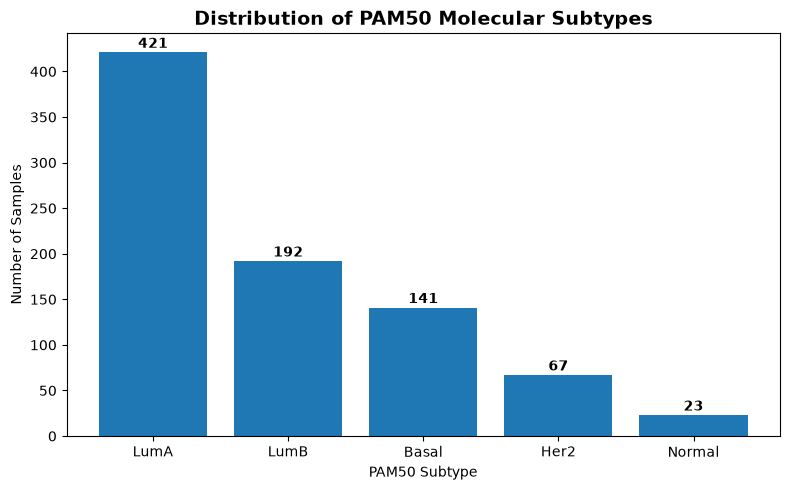

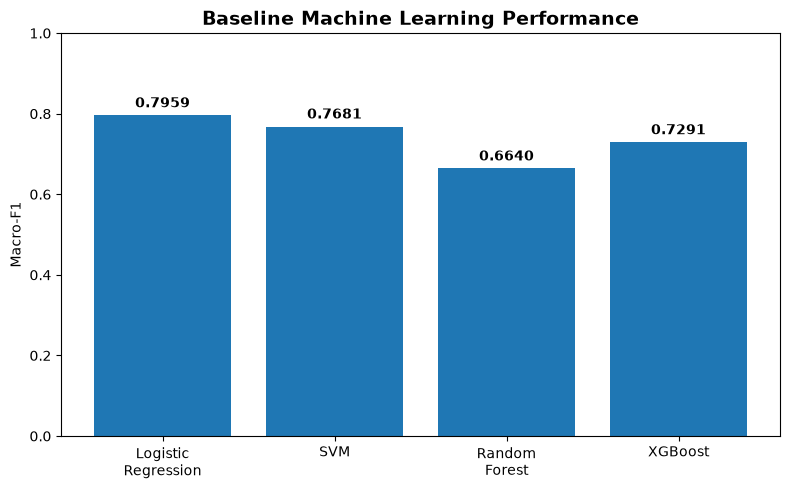

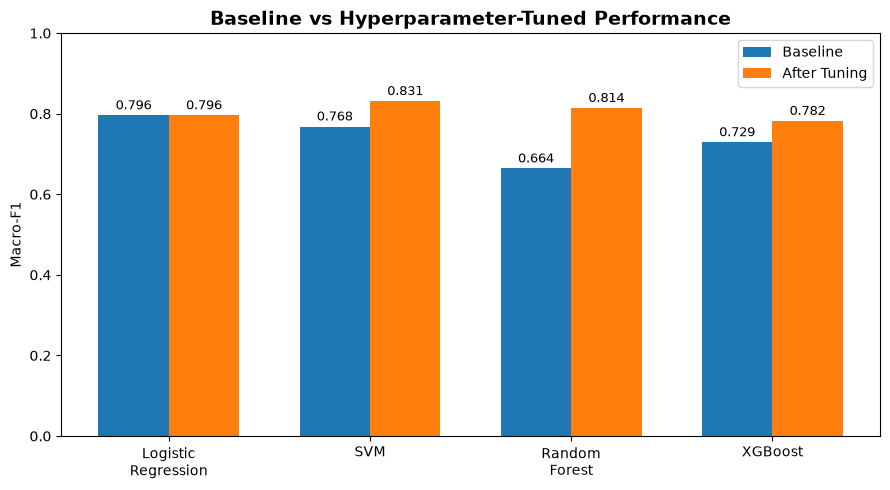

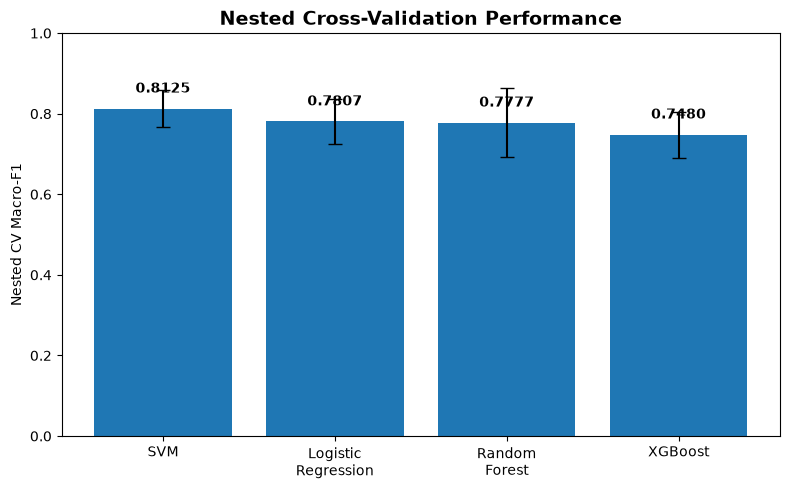

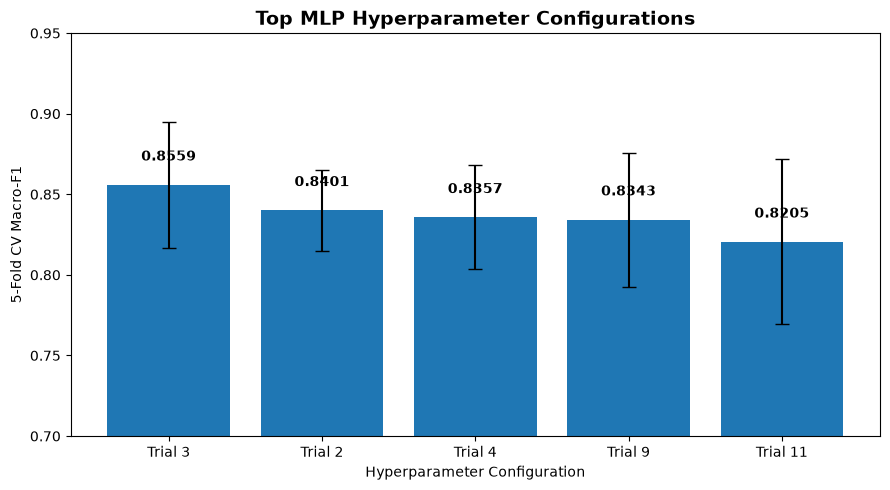

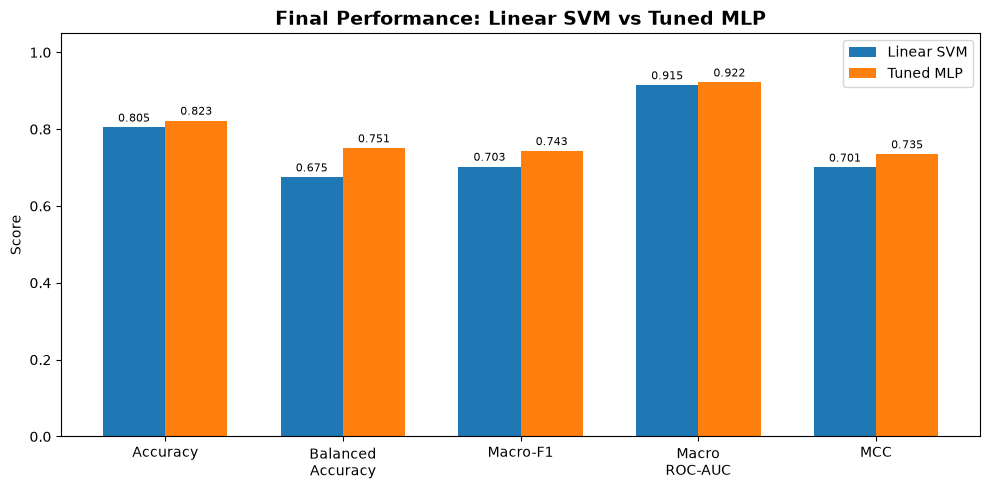

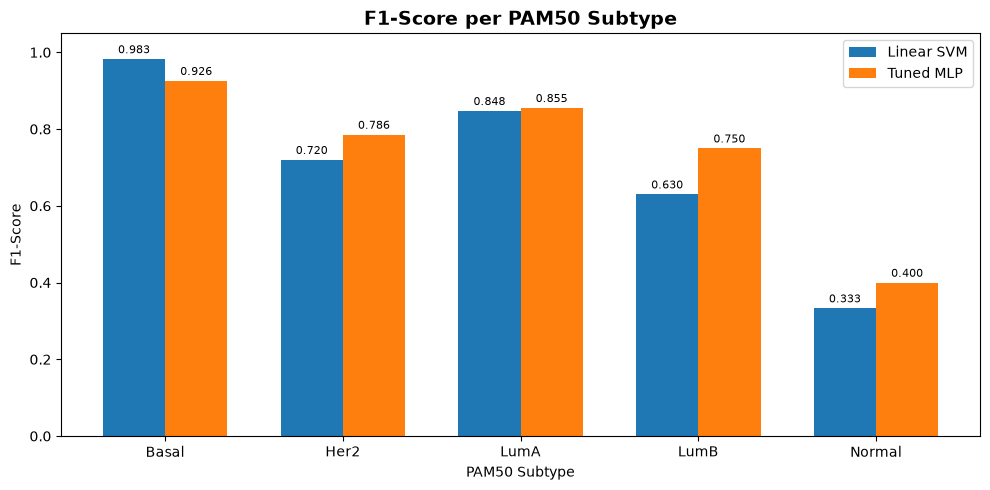

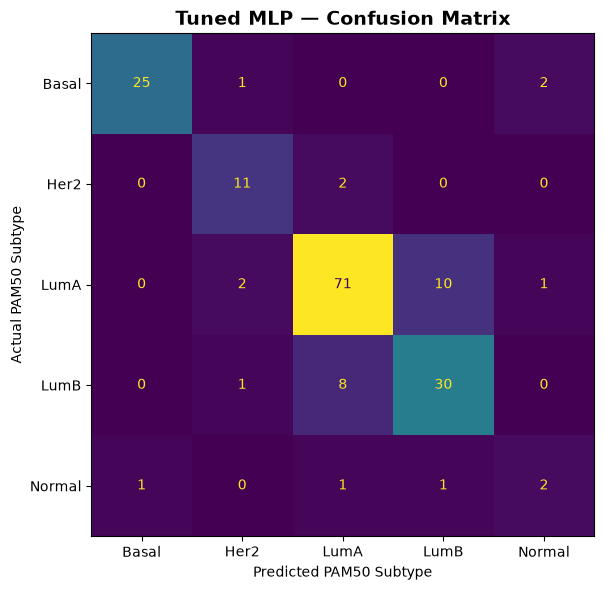

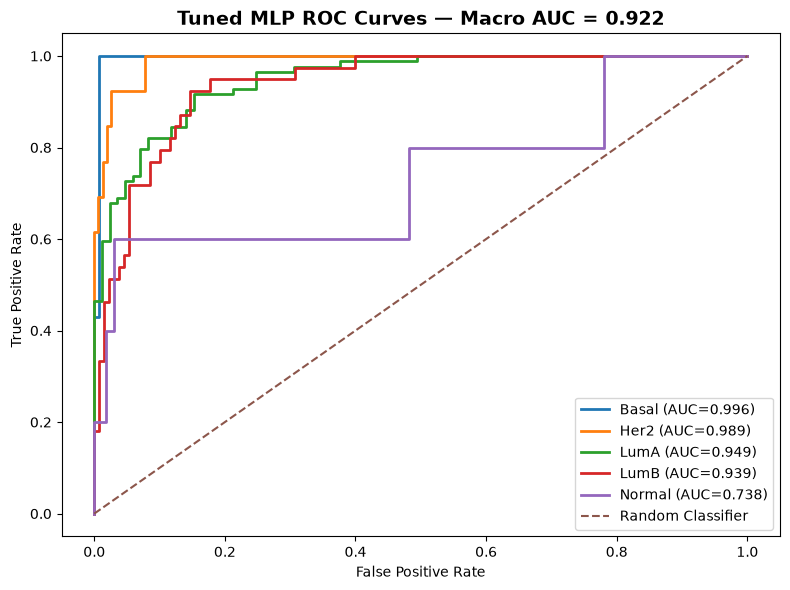

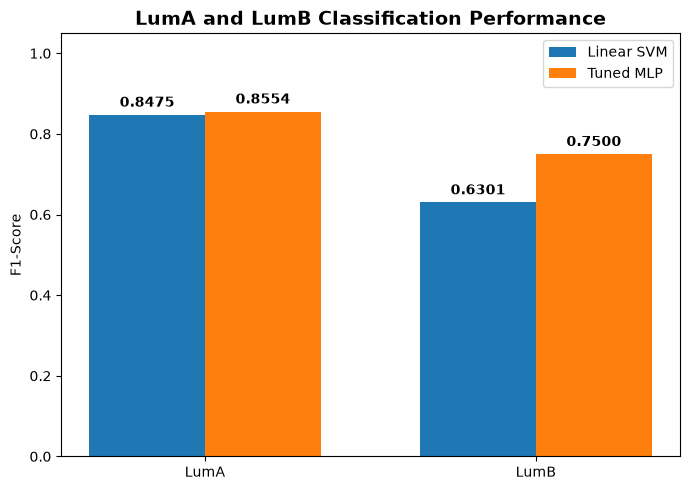

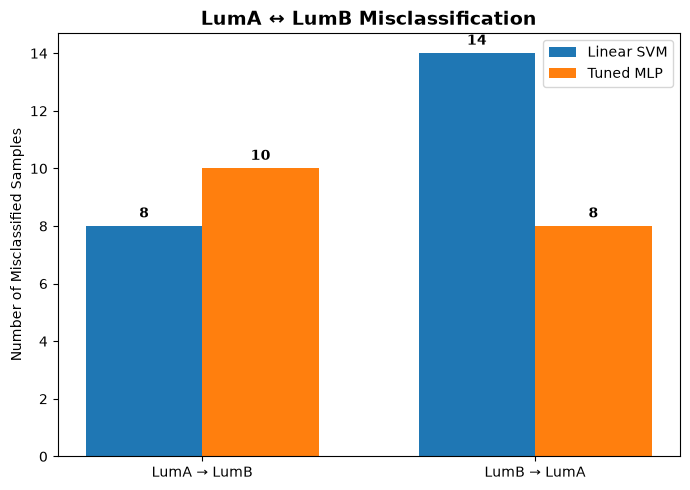

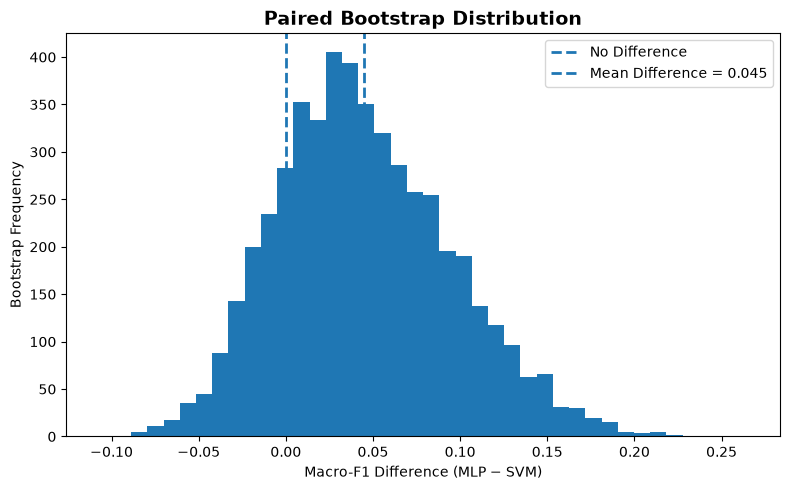

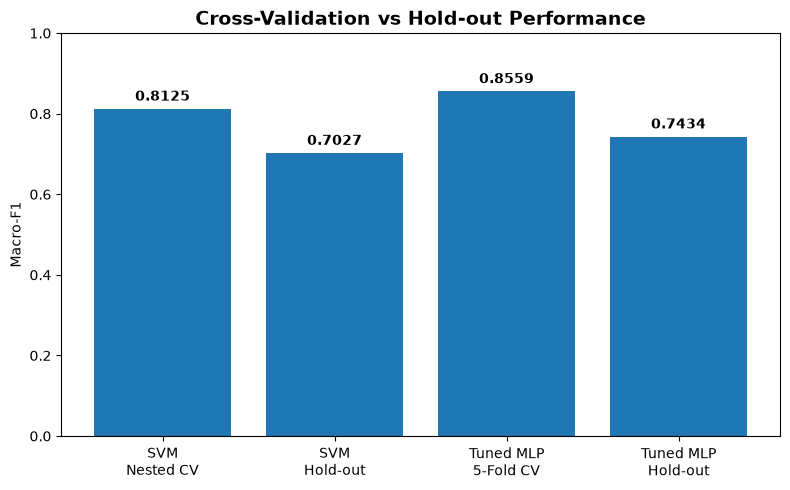


⚠️ Figure 14 skipped: luminal_train / MYBL2 not available.

⚠️ Figure 15 skipped: luminal_train not available.


FINAL PPT FIGURE CHECKLIST
01. ✅ READY            01_pam50_distribution.png                  → Dataset / Distribusi PAM50
02. ✅ READY            02_baseline_models.png                     → Baseline Machine Learning
03. ✅ READY            03_baseline_vs_tuning.png                  → Hyperparameter Tuning Classical ML
04. ✅ READY            04_nested_cv_models.png                    → Nested Cross-Validation
05. ✅ READY            05_mlp_hyperparameter_tuning.png           → Hyperparameter Tuning MLP
06. ✅ READY            06_svm_vs_tuned_mlp.png                    → Final SVM vs Tuned MLP
07. ✅ READY            07_f1_per_subtype_comparison.png           → F1-Score per PAM50 Subtype
08. ✅ READY            08_tuned_mlp_confusion_matrix.png          → Tuned MLP Confusion Matrix
09. ✅ READY            09_tuned_mlp_roc.png                       → Tuned MLP ROC-AUC
10. ✅ READY   

In [30]:
# ============================================================
# CELL 30 — FINAL PPT PRESENTATION
# GENERATE ALL REQUIRED FIGURES
# TCGA-BRCA PAM50 — ML + DEEP LEARNING
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

OUTPUT_DIR = "results/ppt_final_figures"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


print("=" * 100)
print("GENERATING FINAL FIGURES FOR PPT PRESENTATION")
print("=" * 100)


# ============================================================
# FIGURE 1 — PAM50 CLASS DISTRIBUTION
# ============================================================

subtype_counts = pd.Series({
    "LumA": 421,
    "LumB": 192,
    "Basal": 141,
    "Her2": 67,
    "Normal": 23
})


plt.figure(
    figsize=(8, 5)
)

bars = plt.bar(
    subtype_counts.index,
    subtype_counts.values
)


plt.title(
    "Distribution of PAM50 Molecular Subtypes",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "PAM50 Subtype"
)

plt.ylabel(
    "Number of Samples"
)


for bar, value in zip(
    bars,
    subtype_counts.values
):

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        value + 5,

        str(value),

        ha="center",

        fontweight="bold"
    )


plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/01_pam50_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2 — BASELINE CLASSICAL ML PERFORMANCE
# ============================================================

baseline_models = [

    "Logistic\nRegression",
    "SVM",
    "Random\nForest",
    "XGBoost"
]


baseline_macro_f1 = [

    0.7959,
    0.7681,
    0.6640,
    0.7291
]


plt.figure(
    figsize=(8, 5)
)

bars = plt.bar(
    baseline_models,
    baseline_macro_f1
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "Macro-F1"
)

plt.title(
    "Baseline Machine Learning Performance",
    fontsize=14,
    fontweight="bold"
)


for bar, value in zip(
    bars,
    baseline_macro_f1
):

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        value + 0.02,

        f"{value:.4f}",

        ha="center",

        fontweight="bold"
    )


plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/02_baseline_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 3 — BASELINE VS TUNED CLASSICAL ML
# ============================================================

models = [

    "Logistic\nRegression",
    "SVM",
    "Random\nForest",
    "XGBoost"
]


baseline = np.array([

    0.7959,
    0.7681,
    0.6640,
    0.7291
])


tuned = np.array([

    0.7959,
    0.8312,
    0.8140,
    0.7820
])


x = np.arange(
    len(models)
)

width = 0.35


plt.figure(
    figsize=(9, 5)
)


bars1 = plt.bar(

    x - width / 2,

    baseline,

    width,

    label="Baseline"
)


bars2 = plt.bar(

    x + width / 2,

    tuned,

    width,

    label="After Tuning"
)


plt.xticks(
    x,
    models
)

plt.ylim(
    0,
    1
)

plt.ylabel(
    "Macro-F1"
)

plt.title(
    "Baseline vs Hyperparameter-Tuned Performance",
    fontsize=14,
    fontweight="bold"
)

plt.legend()


for bars in [
    bars1,
    bars2
]:

    for bar in bars:

        value = bar.get_height()

        plt.text(

            bar.get_x()
            + bar.get_width() / 2,

            value + 0.015,

            f"{value:.3f}",

            ha="center",

            fontsize=9
        )


plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/03_baseline_vs_tuning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 4 — NESTED CV CLASSICAL ML
# ============================================================

nested_models = [

    "SVM",
    "Logistic\nRegression",
    "Random\nForest",
    "XGBoost"
]


nested_f1 = [

    0.8125,
    0.7807,
    0.7777,
    0.7480
]


nested_sd = [

    0.0452,
    0.0551,
    0.0860,
    0.0571
]


plt.figure(
    figsize=(8, 5)
)


bars = plt.bar(

    nested_models,
    nested_f1,

    yerr=nested_sd,

    capsize=5
)


plt.ylim(
    0,
    1
)

plt.ylabel(
    "Nested CV Macro-F1"
)

plt.title(
    "Nested Cross-Validation Performance",
    fontsize=14,
    fontweight="bold"
)


for bar, value in zip(
    bars,
    nested_f1
):

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        value + 0.04,

        f"{value:.4f}",

        ha="center",

        fontweight="bold"
    )


plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/04_nested_cv_models.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 5 — TOP 5 MLP HYPERPARAMETER TRIALS
# ============================================================

if "mlp_tuning_ranking" in globals():

    top5_mlp = (
        mlp_tuning_ranking
        .head(5)
        .copy()
    )


    trial_labels = [

        f"Trial {int(x)}"

        for x in top5_mlp[
            "Trial"
        ]
    ]


    values = top5_mlp[
        "Mean_Macro_F1"
    ].values


    errors = top5_mlp[
        "STD_Macro_F1"
    ].values


else:

    trial_labels = [

        "Trial 3",
        "Trial 2",
        "Trial 4",
        "Trial 9",
        "Trial 11"
    ]


    values = np.array([

        0.8559,
        0.8401,
        0.8357,
        0.8343,
        0.8205
    ])


    errors = np.array([

        0.0391,
        0.0252,
        0.0323,
        0.0415,
        0.0511
    ])


plt.figure(
    figsize=(9, 5)
)


bars = plt.bar(

    trial_labels,
    values,

    yerr=errors,

    capsize=5
)


plt.ylim(
    0.70,
    0.95
)

plt.xlabel(
    "Hyperparameter Configuration"
)

plt.ylabel(
    "5-Fold CV Macro-F1"
)

plt.title(
    "Top MLP Hyperparameter Configurations",
    fontsize=14,
    fontweight="bold"
)


for bar, value in zip(
    bars,
    values
):

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        value + 0.015,

        f"{value:.4f}",

        ha="center",

        fontweight="bold"
    )


plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/05_mlp_hyperparameter_tuning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 6 — SVM VS TUNED MLP
# FINAL HOLD-OUT PERFORMANCE
# ============================================================

comparison_metrics = [

    "Accuracy",
    "Balanced\nAccuracy",
    "Macro-F1",
    "Macro\nROC-AUC",
    "MCC"
]


svm_scores = np.array([

    0.8047,
    0.6750,
    0.7027,
    0.9148,
    0.7005
])


mlp_scores = np.array([

    0.8225,
    0.7507,
    0.7434,
    0.9221,
    0.7352
])


x = np.arange(
    len(
        comparison_metrics
    )
)

width = 0.35


plt.figure(
    figsize=(10, 5)
)


bars1 = plt.bar(

    x - width / 2,

    svm_scores,

    width,

    label="Linear SVM"
)


bars2 = plt.bar(

    x + width / 2,

    mlp_scores,

    width,

    label="Tuned MLP"
)


plt.xticks(
    x,
    comparison_metrics
)

plt.ylim(
    0,
    1.05
)

plt.ylabel(
    "Score"
)

plt.title(
    "Final Performance: Linear SVM vs Tuned MLP",
    fontsize=14,
    fontweight="bold"
)

plt.legend()


for bars in [
    bars1,
    bars2
]:

    for bar in bars:

        value = bar.get_height()

        plt.text(

            bar.get_x()
            + bar.get_width() / 2,

            value + 0.015,

            f"{value:.3f}",

            ha="center",

            fontsize=8
        )


plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/06_svm_vs_tuned_mlp.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 7 — F1 PER SUBTYPE
# SVM VS TUNED MLP
# ============================================================

class_names = np.array([

    "Basal",
    "Her2",
    "LumA",
    "LumB",
    "Normal"
])


svm_f1 = np.array([

    0.9825,
    0.7200,
    0.8475,
    0.6301,
    0.3333
])


mlp_f1 = np.array([

    0.9259,
    0.7857,
    0.8554,
    0.7500,
    0.4000
])


x = np.arange(
    len(class_names)
)

width = 0.35


plt.figure(
    figsize=(10, 5)
)


bars1 = plt.bar(

    x - width / 2,

    svm_f1,

    width,

    label="Linear SVM"
)


bars2 = plt.bar(

    x + width / 2,

    mlp_f1,

    width,

    label="Tuned MLP"
)


plt.xticks(
    x,
    class_names
)

plt.ylim(
    0,
    1.05
)

plt.xlabel(
    "PAM50 Subtype"
)

plt.ylabel(
    "F1-Score"
)

plt.title(
    "F1-Score per PAM50 Subtype",
    fontsize=14,
    fontweight="bold"
)

plt.legend()


for bars in [
    bars1,
    bars2
]:

    for bar in bars:

        value = bar.get_height()

        plt.text(

            bar.get_x()
            + bar.get_width() / 2,

            value + 0.015,

            f"{value:.3f}",

            ha="center",

            fontsize=8
        )


plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/07_f1_per_subtype_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 8 — TUNED MLP CONFUSION MATRIX
# ============================================================

tuned_confusion_matrix = np.array([

    [25, 1, 0, 0, 2],

    [0, 11, 2, 0, 0],

    [0, 2, 71, 10, 1],

    [0, 1, 8, 30, 0],

    [1, 0, 1, 1, 2]
])


fig, ax = plt.subplots(
    figsize=(7, 6)
)


disp = ConfusionMatrixDisplay(

    confusion_matrix=(
        tuned_confusion_matrix
    ),

    display_labels=(
        class_names
    )
)


disp.plot(

    ax=ax,

    values_format="d",

    colorbar=False
)


plt.title(
    "Tuned MLP — Confusion Matrix",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel(
    "Predicted PAM50 Subtype"
)

plt.ylabel(
    "Actual PAM50 Subtype"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/08_tuned_mlp_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 9 — TUNED MLP ROC CURVES
# Uses actual predictions if available
# ============================================================

if (
    "y_test_tuned_mlp" in globals()
    and
    "y_test_prob_tuned_mlp" in globals()
):

    class_ids = np.arange(
        len(class_names)
    )


    y_test_bin = label_binarize(

        y_test_tuned_mlp,

        classes=class_ids
    )


    plt.figure(
        figsize=(8, 6)
    )


    auc_values = []


    for i, class_name in enumerate(
        class_names
    ):

        fpr, tpr, _ = roc_curve(

            y_test_bin[:, i],

            y_test_prob_tuned_mlp[:, i]
        )


        class_auc = auc(
            fpr,
            tpr
        )


        auc_values.append(
            class_auc
        )


        plt.plot(

            fpr,

            tpr,

            linewidth=2,

            label=(
                f"{class_name} "
                f"(AUC={class_auc:.3f})"
            )
        )


    macro_auc = np.mean(
        auc_values
    )


    plt.plot(

        [0, 1],

        [0, 1],

        linestyle="--",

        label="Random Classifier"
    )


    plt.xlabel(
        "False Positive Rate"
    )

    plt.ylabel(
        "True Positive Rate"
    )

    plt.title(

        f"Tuned MLP ROC Curves — "
        f"Macro AUC = {macro_auc:.3f}",

        fontsize=14,

        fontweight="bold"
    )


    plt.legend(
        loc="lower right"
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/09_tuned_mlp_roc.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


else:

    # --------------------------------------------------------
    # Fallback: AUC bar chart
    # --------------------------------------------------------

    auc_values = np.array([

        0.9959,
        0.9892,
        0.9489,
        0.9387,
        0.7378
    ])


    plt.figure(
        figsize=(8, 5)
    )


    bars = plt.bar(

        class_names,

        auc_values
    )


    plt.ylim(
        0,
        1.05
    )

    plt.ylabel(
        "ROC-AUC"
    )

    plt.xlabel(
        "PAM50 Subtype"
    )

    plt.title(
        "Tuned MLP — ROC-AUC per PAM50 Subtype",
        fontsize=14,
        fontweight="bold"
    )


    for bar, value in zip(
        bars,
        auc_values
    ):

        plt.text(

            bar.get_x()
            + bar.get_width() / 2,

            value + 0.015,

            f"{value:.3f}",

            ha="center",

            fontweight="bold"
        )


    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/09_tuned_mlp_auc_per_subtype.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# FIGURE 10 — LumA / LumB F1 COMPARISON
# ============================================================

luminal_subtypes = [

    "LumA",
    "LumB"
]


svm_luminal_f1 = [

    0.8475,
    0.6301
]


mlp_luminal_f1 = [

    0.8554,
    0.7500
]


x = np.arange(
    len(
        luminal_subtypes
    )
)

width = 0.35


plt.figure(
    figsize=(7, 5)
)


bars1 = plt.bar(

    x - width / 2,

    svm_luminal_f1,

    width,

    label="Linear SVM"
)


bars2 = plt.bar(

    x + width / 2,

    mlp_luminal_f1,

    width,

    label="Tuned MLP"
)


plt.xticks(
    x,
    luminal_subtypes
)

plt.ylim(
    0,
    1.05
)

plt.ylabel(
    "F1-Score"
)

plt.title(
    "LumA and LumB Classification Performance",
    fontsize=14,
    fontweight="bold"
)

plt.legend()


for bars in [
    bars1,
    bars2
]:

    for bar in bars:

        value = bar.get_height()

        plt.text(

            bar.get_x()
            + bar.get_width() / 2,

            value + 0.02,

            f"{value:.4f}",

            ha="center",

            fontweight="bold"
        )


plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/10_luma_lumb_f1_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 11 — LumA ↔ LumB MISCLASSIFICATION
# ============================================================

error_types = [

    "LumA → LumB",
    "LumB → LumA"
]


svm_errors = [

    8,
    14
]


mlp_errors = [

    10,
    8
]


x = np.arange(
    len(
        error_types
    )
)

width = 0.35


plt.figure(
    figsize=(7, 5)
)


bars1 = plt.bar(

    x - width / 2,

    svm_errors,

    width,

    label="Linear SVM"
)


bars2 = plt.bar(

    x + width / 2,

    mlp_errors,

    width,

    label="Tuned MLP"
)


plt.xticks(
    x,
    error_types
)

plt.ylabel(
    "Number of Misclassified Samples"
)

plt.title(
    "LumA ↔ LumB Misclassification",
    fontsize=14,
    fontweight="bold"
)

plt.legend()


for bars in [
    bars1,
    bars2
]:

    for bar in bars:

        value = int(
            bar.get_height()
        )

        plt.text(

            bar.get_x()
            + bar.get_width() / 2,

            value + 0.3,

            str(value),

            ha="center",

            fontweight="bold"
        )


plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/11_luminal_misclassification.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 12 — PAIRED BOOTSTRAP DIFFERENCE
# ============================================================

if "bootstrap_difference" in globals():

    plt.figure(
        figsize=(8, 5)
    )


    plt.hist(

        bootstrap_difference,

        bins=40
    )


    plt.axvline(

        0,

        linestyle="--",

        linewidth=2,

        label="No Difference"
    )


    plt.axvline(

        np.mean(
            bootstrap_difference
        ),

        linestyle="--",

        linewidth=2,

        label=(
            "Mean Difference "
            f"= {np.mean(bootstrap_difference):.3f}"
        )
    )


    plt.xlabel(
        "Macro-F1 Difference (MLP − SVM)"
    )

    plt.ylabel(
        "Bootstrap Frequency"
    )

    plt.title(
        "Paired Bootstrap Distribution",
        fontsize=14,
        fontweight="bold"
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/12_paired_bootstrap_difference.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


else:

    print(
        "\n⚠️ Figure 12 skipped: "
        "bootstrap_difference not found."
    )


# ============================================================
# FIGURE 13 — CV VS HOLD-OUT PERFORMANCE
# ============================================================

model_stage = [

    "SVM\nNested CV",
    "SVM\nHold-out",
    "Tuned MLP\n5-Fold CV",
    "Tuned MLP\nHold-out"
]


model_stage_f1 = [

    0.8125,
    0.7027,
    0.8559,
    0.7434
]


plt.figure(
    figsize=(8, 5)
)


bars = plt.bar(

    model_stage,

    model_stage_f1
)


plt.ylim(
    0,
    1
)

plt.ylabel(
    "Macro-F1"
)

plt.title(
    "Cross-Validation vs Hold-out Performance",
    fontsize=14,
    fontweight="bold"
)


for bar, value in zip(
    bars,
    model_stage_f1
):

    plt.text(

        bar.get_x()
        + bar.get_width() / 2,

        value + 0.02,

        f"{value:.4f}",

        ha="center",

        fontweight="bold"
    )


plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/13_cv_vs_holdout.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 14 — MYBL2 LumA vs LumB
# OPTIONAL
# ============================================================

if (
    "luminal_train" in globals()
    and
    "MYBL2" in luminal_train.columns
):

    luma_values = (

        luminal_train.loc[

            luminal_train[
                "Subtype"
            ] == "LumA",

            "MYBL2"
        ]

        .dropna()
    )


    lumb_values = (

        luminal_train.loc[

            luminal_train[
                "Subtype"
            ] == "LumB",

            "MYBL2"
        ]

        .dropna()
    )


    plt.figure(
        figsize=(6, 5)
    )


    plt.boxplot(

        [
            luma_values,
            lumb_values
        ],

        tick_labels=[
            "LumA",
            "LumB"
        ]
    )


    plt.ylabel(
        "MYBL2 Expression"
    )

    plt.title(
        "MYBL2 Expression: LumA vs LumB",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_DIR}/14_MYBL2_LumA_vs_LumB.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


else:

    print(
        "\n⚠️ Figure 14 skipped: "
        "luminal_train / MYBL2 not available."
    )


# ============================================================
# FIGURE 15 — TOP INFORMATIVE GENES LumA VS LumB
# OPTIONAL
# ============================================================

if "luminal_train" in globals():

    genes_to_plot = [

        "MYBL2",
        "YBX2",
        "CDCA7",
        "CHRNA5"
    ]


    genes_to_plot = [

        gene

        for gene in genes_to_plot

        if gene
        in luminal_train.columns
    ]


    if len(
        genes_to_plot
    ) > 0:

        fig, axes = plt.subplots(

            2,
            2,

            figsize=(9, 7)
        )


        axes = axes.flatten()


        for ax, gene in zip(
            axes,
            genes_to_plot
        ):

            luma = (

                luminal_train.loc[

                    luminal_train[
                        "Subtype"
                    ] == "LumA",

                    gene
                ]

                .dropna()
            )


            lumb = (

                luminal_train.loc[

                    luminal_train[
                        "Subtype"
                    ] == "LumB",

                    gene
                ]

                .dropna()
            )


            ax.boxplot(

                [
                    luma,
                    lumb
                ],

                tick_labels=[
                    "LumA",
                    "LumB"
                ]
            )


            ax.set_title(

                gene,

                fontweight="bold"
            )


            ax.set_ylabel(
                "Expression"
            )


        for i in range(

            len(
                genes_to_plot
            ),

            len(
                axes
            )
        ):

            axes[i].axis(
                "off"
            )


        fig.suptitle(

            "Top Informative Genes — LumA vs LumB",

            fontsize=14,

            fontweight="bold"
        )


        plt.tight_layout(

            rect=[
                0,
                0,
                1,
                0.95
            ]
        )


        plt.savefig(
            f"{OUTPUT_DIR}/15_top_genes_LumA_vs_LumB.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()


else:

    print(
        "\n⚠️ Figure 15 skipped: "
        "luminal_train not available."
    )


# ============================================================
# FINAL PPT IMAGE CHECKLIST
# ============================================================

print("\n")

print("=" * 110)
print("FINAL PPT FIGURE CHECKLIST")
print("=" * 110)


ppt_images = [

    (
        "01_pam50_distribution.png",
        "Dataset / Distribusi PAM50"
    ),

    (
        "02_baseline_models.png",
        "Baseline Machine Learning"
    ),

    (
        "03_baseline_vs_tuning.png",
        "Hyperparameter Tuning Classical ML"
    ),

    (
        "04_nested_cv_models.png",
        "Nested Cross-Validation"
    ),

    (
        "05_mlp_hyperparameter_tuning.png",
        "Hyperparameter Tuning MLP"
    ),

    (
        "06_svm_vs_tuned_mlp.png",
        "Final SVM vs Tuned MLP"
    ),

    (
        "07_f1_per_subtype_comparison.png",
        "F1-Score per PAM50 Subtype"
    ),

    (
        "08_tuned_mlp_confusion_matrix.png",
        "Tuned MLP Confusion Matrix"
    ),

    (
        "09_tuned_mlp_roc.png",
        "Tuned MLP ROC-AUC"
    ),

    (
        "10_luma_lumb_f1_comparison.png",
        "LumA vs LumB Performance"
    ),

    (
        "11_luminal_misclassification.png",
        "LumA ↔ LumB Misclassification"
    ),

    (
        "12_paired_bootstrap_difference.png",
        "Paired Bootstrap SVM vs MLP"
    ),

    (
        "13_cv_vs_holdout.png",
        "CV vs Hold-out Generalization"
    ),

    (
        "14_MYBL2_LumA_vs_LumB.png",
        "MYBL2 Interpretation"
    ),

    (
        "15_top_genes_LumA_vs_LumB.png",
        "Top Informative Genes"
    )
]


for number, (
    filename,
    slide
) in enumerate(
    ppt_images,
    start=1
):

    path = os.path.join(
        OUTPUT_DIR,
        filename
    )


    # ROC has fallback filename
    if (
        filename
        == "09_tuned_mlp_roc.png"
        and
        not os.path.exists(path)
    ):

        fallback_path = os.path.join(

            OUTPUT_DIR,

            "09_tuned_mlp_auc_per_subtype.png"
        )

        exists = os.path.exists(
            fallback_path
        )

    else:

        exists = os.path.exists(
            path
        )


    status = (

        "✅ READY"

        if exists

        else "⚠️ NOT GENERATED"
    )


    print(

        f"{number:02d}. "
        f"{status:<18} "
        f"{filename:<42} "
        f"→ {slide}"
    )


print("\n" + "=" * 110)

print(
    "FIGURES SAVED IN:"
)

print(
    OUTPUT_DIR
)

print("=" * 110)

print(
    "✅ CELL 30 COMPLETED — "
    "FINAL PPT FIGURES GENERATED"
)

# CELL 31 — FINAL MLP TRAINING, EVALUATION & MODEL SAVING

FINAL MLP TRAINING
Top genes       : 2000
Hidden layers   : 64 32
Dropout         : 0.4 0.3
Learning rate   : 0.001
L2 regularization: 0.0001
Batch size      : 32
Epochs          : 26

Training samples : 675
Test samples     : 169
Available genes  : 20530
PAM50 classes    : [np.str_('Basal'), np.str_('Her2'), np.str_('LumA'), np.str_('LumB'), np.str_('Normal')]

Fitting TopVarianceGenes on X_train...
Selected training shape: (675, 2000)
Selected test shape    : (169, 2000)
Example selected genes : ['CPB1', 'CLEC3A', 'SCGB2A2', 'SCGB1D2', 'GSTM1', 'TFF1', 'S100A7', 'PIP', 'SERPINA6', 'CYP2B7P1']

Fitting StandardScaler...
Scaled training: (675, 2000)
Scaled test    : (169, 2000)

Class weights:
Basal: 1.1947
Her2: 2.5000
LumA: 0.4006
LumB: 0.8824
Normal: 7.5000

Model architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │       128,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pam50_output (Dense)            │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,693 (510.52 KB)

 Trainable params: 130,501 (509.77 KB)

 Non-trainable params: 192 (768.00 B)

... (2 outputs left out)


Classification report:


,precision,recall,f1-score,support
Basal,0.9643,0.9643,0.9643,28.0000
Her2,0.7857,0.8462,0.8148,13.0000
LumA,0.8427,0.8929,0.8671,84.0000
LumB,0.7812,0.6410,0.7042,39.0000
Normal,0.5000,0.6000,0.5455,5.0000
accuracy,0.8343,0.8343,0.8343,0.8343
macro avg,0.7748,0.7889,0.7792,169.0000
weighted avg,0.8341,0.8343,0.8321,169.0000



Confusion matrix:


,Pred_Basal,Pred_Her2,Pred_LumA,Pred_LumB,Pred_Normal
Actual_Basal,27,0,0,0,1
Actual_Her2,0,11,2,0,0
Actual_LumA,0,1,75,6,2
Actual_LumB,0,2,12,25,0
Actual_Normal,1,0,0,1,3


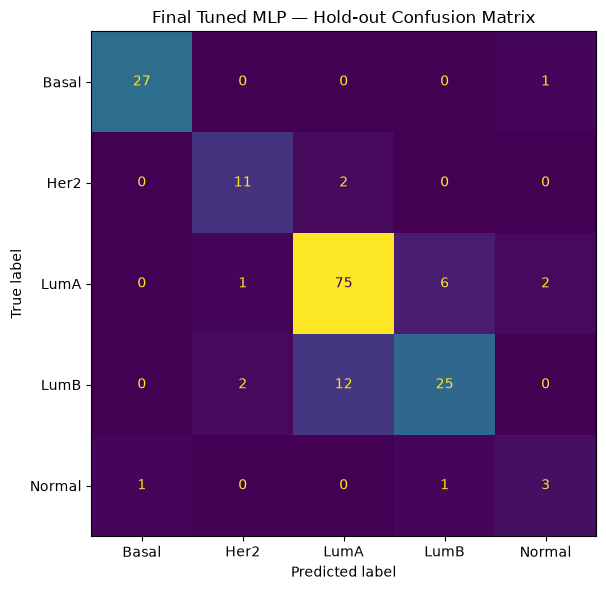


Saving final model and artifacts...

SAVED FINAL MODEL FILES
✓ final_mlp_classification_report.csv (0.5 KB)
✓ final_mlp_confusion_matrix.png (80.8 KB)
✓ final_mlp_metrics.csv (0.3 KB)
✓ final_mlp_test_predictions.csv (2.5 KB)
✓ final_mlp_training_history.csv (1.0 KB)
✓ label_mapping.json (0.1 KB)
✓ model_config.json (0.3 KB)
✓ selected_gene_names.json (22.3 KB)
✓ standard_scaler.joblib (47.4 KB)
✓ tuned_mlp_final.keras (1571.2 KB)

CELL 31 COMPLETED
Final model directory: results/final_model


In [31]:
# ============================================================
# CELL 31 — FINAL MLP TRAINING, EVALUATION & MODEL SAVING
# TCGA-BRCA PAM50
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ============================================================
# 1. CONFIGURATION
# ============================================================

FINAL_TOP_K = 2000
FINAL_HIDDEN1 = 64
FINAL_HIDDEN2 = 32

FINAL_DROPOUT1 = 0.40
FINAL_DROPOUT2 = 0.30

FINAL_LEARNING_RATE = 0.001
FINAL_L2 = 0.0001

FINAL_BATCH_SIZE = 32
FINAL_EPOCHS = 26

RANDOM_STATE = 42

OUTPUT_DIR = "results/final_model"
os.makedirs(OUTPUT_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(RANDOM_STATE)

print("=" * 80)
print("FINAL MLP TRAINING")
print("=" * 80)

print("Top genes       :", FINAL_TOP_K)
print("Hidden layers   :", FINAL_HIDDEN1, FINAL_HIDDEN2)
print("Dropout         :", FINAL_DROPOUT1, FINAL_DROPOUT2)
print("Learning rate   :", FINAL_LEARNING_RATE)
print("L2 regularization:", FINAL_L2)
print("Batch size      :", FINAL_BATCH_SIZE)
print("Epochs          :", FINAL_EPOCHS)


# ============================================================
# 2. CHECK REQUIRED DATA
# ============================================================

required_variables = [
    "X_train",
    "X_test",
    "y_train",
    "y_test",
    "class_names",
    "TopVarianceGenes"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Variabel belum tersedia: "
        + ", ".join(missing_variables)
    )

if not isinstance(X_train, pd.DataFrame):
    raise TypeError(
        "X_train harus berupa pandas DataFrame "
        "agar nama gen dapat disimpan."
    )

if not X_train.columns.is_unique:
    raise ValueError(
        "Nama gen pada X_train tidak unik."
    )

if X_train.shape[1] < FINAL_TOP_K:
    raise ValueError(
        f"Jumlah fitur hanya {X_train.shape[1]}, "
        f"kurang dari {FINAL_TOP_K}."
    )

y_train_array = np.asarray(
    y_train,
    dtype=np.int32
).ravel()

y_test_array = np.asarray(
    y_test,
    dtype=np.int32
).ravel()

class_names = np.asarray(class_names)

class_ids = np.arange(
    len(class_names)
)

assert len(X_train) == len(y_train_array)
assert len(X_test) == len(y_test_array)

assert set(np.unique(y_train_array)) == set(class_ids)

print("\nTraining samples :", len(X_train))
print("Test samples     :", len(X_test))
print("Available genes  :", X_train.shape[1])
print("PAM50 classes    :", list(class_names))


# ============================================================
# 3. FIT FEATURE SELECTION ON TRAINING DATA ONLY
# ============================================================

print("\nFitting TopVarianceGenes on X_train...")

final_selector = TopVarianceGenes(
    k=FINAL_TOP_K
)

final_selector.fit(X_train)

X_train_selected = final_selector.transform(
    X_train
)

X_test_selected = final_selector.transform(
    X_test
)

X_train_selected = np.asarray(
    X_train_selected,
    dtype=np.float32
)

X_test_selected = np.asarray(
    X_test_selected,
    dtype=np.float32
)

# Recover the selected gene names in the same order
# used by the transform operation.

if hasattr(final_selector, "get_feature_names_out"):

    selected_gene_names = list(
        final_selector.get_feature_names_out(
            input_features=np.asarray(
                X_train.columns,
                dtype=object
            )
        )
    )

elif hasattr(final_selector, "selected_indices_"):

    selected_indices = np.asarray(
        final_selector.selected_indices_,
        dtype=int
    )

    selected_gene_names = list(
        X_train.columns[selected_indices]
    )

else:

    raise AttributeError(
        "TopVarianceGenes tidak menyediakan "
        "get_feature_names_out atau selected_indices_."
    )

assert len(selected_gene_names) == FINAL_TOP_K
assert X_train_selected.shape[1] == FINAL_TOP_K
assert X_test_selected.shape[1] == FINAL_TOP_K

print("Selected training shape:", X_train_selected.shape)
print("Selected test shape    :", X_test_selected.shape)
print("Example selected genes :", selected_gene_names[:10])


# ============================================================
# 4. FIT SCALER ON TRAINING DATA ONLY
# ============================================================

print("\nFitting StandardScaler...")

scaler_final = StandardScaler()

X_train_scaled = scaler_final.fit_transform(
    X_train_selected
).astype(np.float32)

X_test_scaled = scaler_final.transform(
    X_test_selected
).astype(np.float32)

print("Scaled training:", X_train_scaled.shape)
print("Scaled test    :", X_test_scaled.shape)


# ============================================================
# 5. CALCULATE CLASS WEIGHTS
# ============================================================

classes_present = np.unique(
    y_train_array
)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_present,
    y=y_train_array
)

final_class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(
        classes_present,
        weights
    )
}

print("\nClass weights:")

for class_id, weight in final_class_weights.items():

    print(
        f"{class_names[class_id]}: {weight:.4f}"
    )


# ============================================================
# 6. BUILD THE TUNED MLP ARCHITECTURE
# ============================================================

tf.keras.backend.clear_session()

tf.keras.utils.set_random_seed(
    RANDOM_STATE
)

final_mlp_model = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(FINAL_TOP_K,),
        name="gene_expression_input"
    ),

    tf.keras.layers.Dense(
        FINAL_HIDDEN1,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(
            FINAL_L2
        )
    ),

    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Dropout(
        FINAL_DROPOUT1
    ),

    tf.keras.layers.Dense(
        FINAL_HIDDEN2,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(
            FINAL_L2
        )
    ),

    tf.keras.layers.BatchNormalization(),

    tf.keras.layers.Dropout(
        FINAL_DROPOUT2
    ),

    tf.keras.layers.Dense(
        len(class_names),
        activation="softmax",
        name="pam50_output"
    )

])


final_mlp_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=FINAL_LEARNING_RATE
    ),

    loss="sparse_categorical_crossentropy",

    metrics=[
        "accuracy"
    ]

)


print("\nModel architecture:")

final_mlp_model.summary()


# ============================================================
# 7. TRAIN ON ALL TRAINING SAMPLES
# ============================================================

print("\nTraining final MLP...")

final_history = final_mlp_model.fit(

    X_train_scaled,

    y_train_array,

    epochs=FINAL_EPOCHS,

    batch_size=FINAL_BATCH_SIZE,

    class_weight=final_class_weights,

    shuffle=True,

    verbose=1

)

print("\nFinal MLP training completed.")


# ============================================================
# 8. PREDICT ON HOLD-OUT TEST SET
# ============================================================

print("\nEvaluating on hold-out test set...")

final_mlp_prob = final_mlp_model.predict(
    X_test_scaled,
    verbose=0
)

final_mlp_pred = np.argmax(
    final_mlp_prob,
    axis=1
)


# ============================================================
# 9. CALCULATE FINAL METRICS
# ============================================================

final_metrics = {

    "Model": "Tuned MLP - Final Refit",

    "Accuracy": accuracy_score(
        y_test_array,
        final_mlp_pred
    ),

    "Balanced_Accuracy": balanced_accuracy_score(
        y_test_array,
        final_mlp_pred
    ),

    "Macro_Precision": precision_score(
        y_test_array,
        final_mlp_pred,
        average="macro",
        zero_division=0
    ),

    "Macro_Recall": recall_score(
        y_test_array,
        final_mlp_pred,
        average="macro",
        zero_division=0
    ),

    "Macro_F1": f1_score(
        y_test_array,
        final_mlp_pred,
        average="macro",
        zero_division=0
    ),

    "Weighted_F1": f1_score(
        y_test_array,
        final_mlp_pred,
        average="weighted",
        zero_division=0
    ),

    "MCC": matthews_corrcoef(
        y_test_array,
        final_mlp_pred
    ),

    "Macro_ROC_AUC": roc_auc_score(
        y_test_array,
        final_mlp_prob,
        labels=class_ids,
        multi_class="ovr",
        average="macro"
    )

}


final_metrics_df = pd.DataFrame([
    final_metrics
])

print("\n" + "=" * 90)
print("FINAL MLP HOLD-OUT PERFORMANCE")
print("=" * 90)

display(
    final_metrics_df.round(4)
)


# ============================================================
# 10. CLASSIFICATION REPORT
# ============================================================

final_report = classification_report(

    y_test_array,

    final_mlp_pred,

    labels=class_ids,

    target_names=[
        str(name)
        for name in class_names
    ],

    output_dict=True,

    zero_division=0

)

final_report_df = pd.DataFrame(
    final_report
).T

print("\nClassification report:")

display(
    final_report_df.round(4)
)


# ============================================================
# 11. CONFUSION MATRIX
# ============================================================

final_cm = confusion_matrix(

    y_test_array,

    final_mlp_pred,

    labels=class_ids

)

print("\nConfusion matrix:")

display(
    pd.DataFrame(
        final_cm,
        index=[
            f"Actual_{name}"
            for name in class_names
        ],
        columns=[
            f"Pred_{name}"
            for name in class_names
        ]
    )
)


fig, ax = plt.subplots(
    figsize=(7, 6)
)

ConfusionMatrixDisplay(

    confusion_matrix=final_cm,

    display_labels=class_names

).plot(

    ax=ax,

    values_format="d",

    colorbar=False

)

ax.set_title(
    "Final Tuned MLP — Hold-out Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/final_mlp_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 12. SAVE FINAL MODEL AND PREPROCESSING ARTIFACTS
# ============================================================

print("\nSaving final model and artifacts...")

# Keras model
final_mlp_model.save(
    f"{OUTPUT_DIR}/tuned_mlp_final.keras"
)

# Scaler fitted on X_train only
joblib.dump(
    scaler_final,
    f"{OUTPUT_DIR}/standard_scaler.joblib"
)

# Gene names in the exact order expected by the model
with open(
    f"{OUTPUT_DIR}/selected_gene_names.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        [str(gene) for gene in selected_gene_names],
        file,
        ensure_ascii=False,
        indent=2
    )

# Class ID to PAM50 label mapping
label_mapping = {
    str(class_id): str(class_name)
    for class_id, class_name in enumerate(class_names)
}

with open(
    f"{OUTPUT_DIR}/label_mapping.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        label_mapping,
        file,
        ensure_ascii=False,
        indent=2
    )

# Hyperparameter configuration
final_config = {

    "model": "Multilayer Perceptron",

    "top_k_genes": FINAL_TOP_K,

    "hidden1": FINAL_HIDDEN1,

    "hidden2": FINAL_HIDDEN2,

    "dropout1": FINAL_DROPOUT1,

    "dropout2": FINAL_DROPOUT2,

    "learning_rate": FINAL_LEARNING_RATE,

    "l2_value": FINAL_L2,

    "batch_size": FINAL_BATCH_SIZE,

    "epochs": FINAL_EPOCHS,

    "class_weight_mode": "balanced",

    "random_state": RANDOM_STATE,

    "training_samples": int(len(X_train)),

    "test_samples": int(len(X_test))

}

with open(
    f"{OUTPUT_DIR}/model_config.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        final_config,
        file,
        ensure_ascii=False,
        indent=2
    )


# Save metrics and predictions
final_metrics_df.to_csv(
    f"{OUTPUT_DIR}/final_mlp_metrics.csv",
    index=False
)

final_report_df.to_csv(
    f"{OUTPUT_DIR}/final_mlp_classification_report.csv"
)

pd.DataFrame(
    final_history.history
).to_csv(
    f"{OUTPUT_DIR}/final_mlp_training_history.csv",
    index=False
)

pd.DataFrame({

    "Actual_Encoded": y_test_array,

    "Actual_Subtype": [
        class_names[i]
        for i in y_test_array
    ],

    "Predicted_Encoded": final_mlp_pred,

    "Predicted_Subtype": [
        class_names[i]
        for i in final_mlp_pred
    ]

}).to_csv(
    f"{OUTPUT_DIR}/final_mlp_test_predictions.csv",
    index=False
)


# ============================================================
# 13. VERIFY SAVED FILES
# ============================================================

print("\n" + "=" * 90)
print("SAVED FINAL MODEL FILES")
print("=" * 90)

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):

    path = os.path.join(
        OUTPUT_DIR,
        filename
    )

    if os.path.isfile(path):

        print(
            f"✓ {filename} "
            f"({os.path.getsize(path) / 1024:.1f} KB)"
        )


print("\n" + "=" * 90)
print("CELL 31 COMPLETED")
print("=" * 90)

print(
    "Final model directory:",
    OUTPUT_DIR
)

# CELL 31B — FINAL MLP TANPA BATCH NORMALIZATION

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │       128,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pam50_output (Dense)            │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,309 (509.02 KB)

 Trainable params: 130,309 (509.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.4163 - loss: 1.2076   
Epoch 2/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 989us/step - accuracy: 0.6533 - loss: 0.7151
Epoch 3/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7541 - loss: 0.5632
Epoch 4/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7600 - loss: 0.6480
Epoch 5/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7452 - loss: 0.6697
Epoch 6/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8296 - loss: 0.5060
Epoch 7/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7822 - loss: 0.4495
Epoch 8/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8178 - loss: 0.4958
Epoch 9/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8400 - loss: 0.3114
Epoch 10/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8711 - loss: 0.2744
Epoch 11/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8919 - loss: 0.2373
Epoch 12/26
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8770

,Model,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,MCC,Macro_ROC_AUC
0,Tuned MLP - Final Refit,0.8225,0.7916,0.7553,0.7916,0.7715,0.822,0.7355,0.9281


,precision,recall,f1-score,support
Basal,0.9655,1.0000,0.9825,28.0000
Her2,0.7333,0.8462,0.7857,13.0000
LumA,0.8554,0.8452,0.8503,84.0000
LumB,0.7222,0.6667,0.6933,39.0000
Normal,0.5000,0.6000,0.5455,5.0000
accuracy,0.8225,0.8225,0.8225,0.8225
macro avg,0.7553,0.7916,0.7715,169.0000
weighted avg,0.8230,0.8225,0.8220,169.0000


,Predicted_Basal,Predicted_Her2,Predicted_LumA,Predicted_LumB,Predicted_Normal
Actual_Basal,28,0,0,0,0
Actual_Her2,0,11,1,1,0
Actual_LumA,0,2,71,8,3
Actual_LumB,0,2,11,26,0
Actual_Normal,1,0,0,1,3


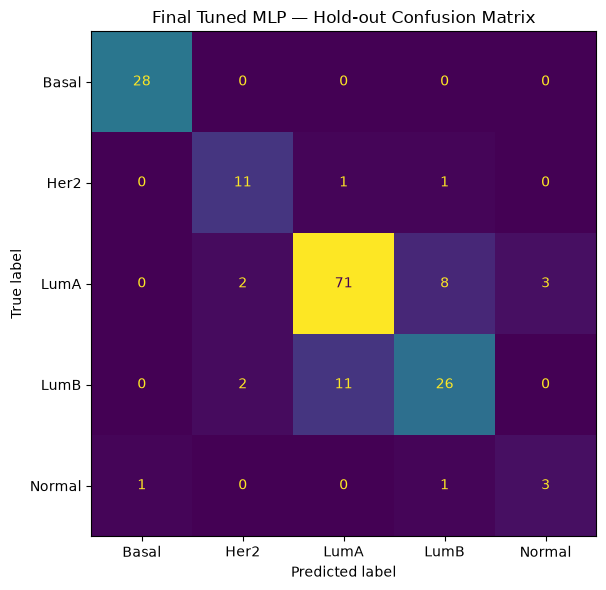


CELL 31B selesai. Model dan hasil evaluasi telah diperbarui.


In [32]:
# ============================================================
# CELL 31B — FINAL MLP TANPA BATCH NORMALIZATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Tetapkan seed
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

class_ids = np.arange(len(class_names))

# 2. Bangun arsitektur sesuai konfigurasi tuning
final_mlp_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(2000,), name="gene_expression_input"),

    tf.keras.layers.Dense(
        64,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(0.0001)
    ),
    tf.keras.layers.Dropout(0.40),

    tf.keras.layers.Dense(
        32,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(0.0001)
    ),
    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Dense(
        len(class_names),
        activation="softmax",
        name="pam50_output"
    )
])

final_mlp_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

final_mlp_model.summary()

# 3. Latih ulang menggunakan seluruh data training
final_history = final_mlp_model.fit(
    X_train_scaled,
    y_train_array,
    epochs=26,
    batch_size=32,
    class_weight=final_class_weights,
    shuffle=True,
    verbose=1
)

# 4. Prediksi data hold-out
final_mlp_prob = final_mlp_model.predict(
    X_test_scaled,
    verbose=0
)

final_mlp_pred = np.argmax(final_mlp_prob, axis=1)

# 5. Hitung metrik evaluasi
final_metrics = {
    "Model": "Tuned MLP - Final Refit",
    "Accuracy": accuracy_score(y_test_array, final_mlp_pred),
    "Balanced_Accuracy": balanced_accuracy_score(
        y_test_array, final_mlp_pred
    ),
    "Macro_Precision": precision_score(
        y_test_array, final_mlp_pred,
        average="macro", zero_division=0
    ),
    "Macro_Recall": recall_score(
        y_test_array, final_mlp_pred,
        average="macro", zero_division=0
    ),
    "Macro_F1": f1_score(
        y_test_array, final_mlp_pred,
        average="macro", zero_division=0
    ),
    "Weighted_F1": f1_score(
        y_test_array, final_mlp_pred,
        average="weighted", zero_division=0
    ),
    "MCC": matthews_corrcoef(
        y_test_array, final_mlp_pred
    ),
    "Macro_ROC_AUC": roc_auc_score(
        y_test_array,
        final_mlp_prob,
        labels=class_ids,
        multi_class="ovr",
        average="macro"
    )
}

final_metrics_df = pd.DataFrame([final_metrics])

print("\nHASIL FINAL MLP")
display(final_metrics_df.round(4))

# 6. Laporan per kelas
final_report_df = pd.DataFrame(
    classification_report(
        y_test_array,
        final_mlp_pred,
        labels=class_ids,
        target_names=[str(c) for c in class_names],
        output_dict=True,
        zero_division=0
    )
).T

display(final_report_df.round(4))

# 7. Confusion matrix
final_cm = confusion_matrix(
    y_test_array,
    final_mlp_pred,
    labels=class_ids
)

display(pd.DataFrame(
    final_cm,
    index=[f"Actual_{c}" for c in class_names],
    columns=[f"Predicted_{c}" for c in class_names]
))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=class_names
).plot(ax=ax, values_format="d", colorbar=False)

ax.set_title("Final Tuned MLP — Hold-out Confusion Matrix")
plt.tight_layout()
plt.savefig(
    f"{OUTPUT_DIR}/final_mlp_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 8. Simpan ulang model dan hasil evaluasi
final_mlp_model.save(
    f"{OUTPUT_DIR}/tuned_mlp_final.keras"
)

final_metrics_df.to_csv(
    f"{OUTPUT_DIR}/final_mlp_metrics.csv",
    index=False
)

final_report_df.to_csv(
    f"{OUTPUT_DIR}/final_mlp_classification_report.csv"
)

pd.DataFrame(final_history.history).to_csv(
    f"{OUTPUT_DIR}/final_mlp_training_history.csv",
    index=False
)

pd.DataFrame({
    "Actual_Encoded": y_test_array,
    "Actual_Subtype": [class_names[i] for i in y_test_array],
    "Predicted_Encoded": final_mlp_pred,
    "Predicted_Subtype": [class_names[i] for i in final_mlp_pred]
}).to_csv(
    f"{OUTPUT_DIR}/final_mlp_test_predictions.csv",
    index=False
)

# Perbarui konfigurasi model yang disimpan
final_config.update({
    "batch_normalization": False,
    "top_k_genes": 2000,
    "hidden1": 64,
    "hidden2": 32,
    "dropout1": 0.40,
    "dropout2": 0.30,
    "learning_rate": 0.001,
    "l2_value": 0.0001,
    "batch_size": 32,
    "epochs": 26
})

with open(
    f"{OUTPUT_DIR}/model_config.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(final_config, file, ensure_ascii=False, indent=2)

print("\nCELL 31B selesai. Model dan hasil evaluasi telah diperbarui.")

# CELL 32 — VALIDASI MODEL TERSIMPAN

In [33]:
# ============================================================
# CELL 32 — VALIDASI MODEL TERSIMPAN
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)

MODEL_DIR = "results/final_model"

MODEL_PATH = os.path.join(
    MODEL_DIR, "tuned_mlp_final.keras"
)

SCALER_PATH = os.path.join(
    MODEL_DIR, "standard_scaler.joblib"
)

GENES_PATH = os.path.join(
    MODEL_DIR, "selected_gene_names.json"
)

LABELS_PATH = os.path.join(
    MODEL_DIR, "label_mapping.json"
)

# 1. Pastikan semua artefak tersedia
required_files = [
    MODEL_PATH,
    SCALER_PATH,
    GENES_PATH,
    LABELS_PATH
]

missing_files = [
    path for path in required_files
    if not os.path.exists(path)
]

if missing_files:
    raise FileNotFoundError(
        "File berikut tidak ditemukan:\n"
        + "\n".join(missing_files)
    )

# 2. Muat ulang model dan preprocessing
loaded_model = tf.keras.models.load_model(
    MODEL_PATH
)

loaded_scaler = joblib.load(
    SCALER_PATH
)

with open(
    GENES_PATH, "r", encoding="utf-8"
) as file:
    loaded_gene_names = json.load(file)

with open(
    LABELS_PATH, "r", encoding="utf-8"
) as file:
    loaded_label_mapping = json.load(file)

print("Model dan preprocessing berhasil dimuat.")
print("Jumlah gen tersimpan:", len(loaded_gene_names))
print("Pemetaan kelas:", loaded_label_mapping)

# 3. Pastikan seluruh gen tersedia pada data uji
missing_genes = [
    gene for gene in loaded_gene_names
    if gene not in X_test.columns
]

if missing_genes:
    raise ValueError(
        f"Ada {len(missing_genes)} gen yang tidak ditemukan "
        "dalam X_test. Periksa nama dan format gen."
    )

# 4. Susun gen dengan urutan yang sama seperti saat training
X_test_reload = X_test.loc[
    :, loaded_gene_names
].to_numpy(dtype=np.float32)

# 5. Terapkan scaler yang telah disimpan
X_test_reload_scaled = loaded_scaler.transform(
    X_test_reload
).astype(np.float32)

# 6. Prediksi menggunakan model yang dimuat ulang
loaded_prob = loaded_model.predict(
    X_test_reload_scaled,
    verbose=0
)

loaded_pred = np.argmax(
    loaded_prob,
    axis=1
)

# 7. Bandingkan hasil sebelum dan sesudah model dimuat ulang
prediction_match = np.array_equal(
    final_mlp_pred,
    loaded_pred
)

probability_match = np.allclose(
    final_mlp_prob,
    loaded_prob,
    rtol=1e-5,
    atol=1e-6
)

print("\n" + "=" * 65)
print("HASIL VALIDASI MODEL")
print("=" * 65)

print("Jumlah fitur input       :", X_test_reload_scaled.shape[1])
print("Jumlah sampel uji        :", len(y_test_array))
print("Prediksi label konsisten :", prediction_match)
print("Probabilitas konsisten   :", probability_match)

# 8. Evaluasi ulang hasil prediksi dari model tersimpan
class_ids = np.arange(len(class_names))

loaded_metrics = {
    "Accuracy": accuracy_score(
        y_test_array, loaded_pred
    ),
    "Balanced_Accuracy": balanced_accuracy_score(
        y_test_array, loaded_pred
    ),
    "Macro_F1": f1_score(
        y_test_array,
        loaded_pred,
        labels=class_ids,
        average="macro",
        zero_division=0
    ),
    "Macro_ROC_AUC": roc_auc_score(
        y_test_array,
        loaded_prob,
        labels=class_ids,
        multi_class="ovr",
        average="macro"
    ),
    "MCC": matthews_corrcoef(
        y_test_array, loaded_pred
    )
}

display(
    pd.DataFrame([loaded_metrics]).round(4)
)

# 9. Simpan ulang artefak preprocessing yang digunakan
joblib.dump(
    loaded_scaler,
    SCALER_PATH
)

with open(
    GENES_PATH, "w", encoding="utf-8"
) as file:
    json.dump(
        loaded_gene_names,
        file,
        ensure_ascii=False,
        indent=2
    )

# 10. Status akhir
if prediction_match and probability_match:
    print("\nVALIDASI BERHASIL.")
    print("Model tersimpan konsisten dengan prediksi sebelumnya.")
else:
    print("\nPERINGATAN: hasil prediksi tidak sepenuhnya konsisten.")
    print("Periksa kembali preprocessing dan urutan fitur.")

Model dan preprocessing berhasil dimuat.
Jumlah gen tersimpan: 2000
Pemetaan kelas: {'0': 'Basal', '1': 'Her2', '2': 'LumA', '3': 'LumB', '4': 'Normal'}

HASIL VALIDASI MODEL
Jumlah fitur input       : 2000
Jumlah sampel uji        : 169
Prediksi label konsisten : True
Probabilitas konsisten   : True


,Accuracy,Balanced_Accuracy,Macro_F1,Macro_ROC_AUC,MCC
0,0.8225,0.7916,0.7715,0.9281,0.7355



VALIDASI BERHASIL.
Model tersimpan konsisten dengan prediksi sebelumnya.


# CELL 33 — FUNGSI PREDIKSI PAM50 UNTUK STREAMLIT

In [34]:

# ============================================================
# CELL 33 — FUNGSI PREDIKSI PAM50 UNTUK STREAMLIT
# ============================================================

import numpy as np
import pandas as pd

def predict_pam50_from_expression(
    expression_df,
    model=loaded_model,
    scaler=loaded_scaler,
    gene_names=loaded_gene_names,
    label_mapping=loaded_label_mapping
):
    """
    Memprediksi subtipe PAM50 berdasarkan ekspresi gen.

    Parameter
    ---------
    expression_df : pandas DataFrame
        Baris = sampel, kolom = nama gen.

    Returns
    -------
    pandas DataFrame
        Prediksi subtipe, confidence, dan probabilitas
        untuk setiap kelas PAM50.
    """

    if not isinstance(expression_df, pd.DataFrame):
        raise TypeError(
            "Input harus berupa pandas DataFrame."
        )

    if expression_df.empty:
        raise ValueError(
            "Data ekspresi gen tidak boleh kosong."
        )

    # 1. Pastikan semua gen yang diperlukan tersedia
    missing_genes = [
        gene for gene in gene_names
        if gene not in expression_df.columns
    ]

    if missing_genes:
        raise ValueError(
            f"Data tidak memiliki {len(missing_genes)} "
            "gen yang diperlukan model. "
            f"Contoh: {missing_genes[:10]}"
        )

    # 2. Ambil gen dengan urutan yang sama seperti training
    X_input = expression_df.loc[
        :, gene_names
    ].apply(
        pd.to_numeric,
        errors="coerce"
    )

    # 3. Periksa nilai kosong dan nilai tak hingga
    X_array = X_input.to_numpy(dtype=np.float32)

    if not np.isfinite(X_array).all():
        raise ValueError(
            "Data mengandung nilai kosong, nonnumerik, "
            "atau tak hingga pada gen terpilih."
        )

    # 4. Terapkan scaler hasil training
    X_scaled = scaler.transform(
        X_array
    ).astype(np.float32)

    # 5. Prediksi probabilitas
    probabilities = model.predict(
        X_scaled,
        verbose=0
    )

    predicted_ids = np.argmax(
        probabilities,
        axis=1
    )

    # 6. Susun hasil prediksi
    class_names = [
        label_mapping[str(i)]
        for i in range(len(label_mapping))
    ]

    results = pd.DataFrame(
        {
            "Predicted_Subtype": [
                label_mapping[str(i)]
                for i in predicted_ids
            ],
            "Confidence": probabilities.max(axis=1)
        },
        index=expression_df.index
    )

    # 7. Tambahkan probabilitas setiap subtipe
    for i, subtype in enumerate(class_names):
        results[f"Probability_{subtype}"] = (
            probabilities[:, i]
        )

    return results


# ============================================================
# UJI FUNGSI PADA DATA TEST
# ============================================================

test_predictions = predict_pam50_from_expression(
    X_test
)

print("Jumlah sampel yang diprediksi:", len(test_predictions))
print("\nContoh hasil prediksi:")

display(
    test_predictions.head(10).round(4)
)

print("\nDistribusi hasil prediksi:")

display(
    test_predictions["Predicted_Subtype"]
    .value_counts()
    .reindex(
        [loaded_label_mapping[str(i)]
         for i in range(len(loaded_label_mapping))],
        fill_value=0
    )
    .rename_axis("Subtipe PAM50")
    .to_frame("Jumlah Prediksi")
)

print("\nCELL 33 selesai.")


Jumlah sampel yang diprediksi: 169

Contoh hasil prediksi:


,Predicted_Subtype,Confidence,Probability_Basal,Probability_Her2,Probability_LumA,Probability_LumB,Probability_Normal
TCGA-BH-A0DS-01,LumA,0.9776,0.0000,0.0000,0.9776,0.0222,0.0001
TCGA-EW-A1J6-01,LumB,0.9947,0.0002,0.0000,0.0050,0.9947,0.0000
TCGA-A2-A0YK-01,Normal,0.8138,0.0000,0.0000,0.1862,0.0000,0.8138
TCGA-D8-A1XV-01,LumB,0.9335,0.0000,0.0000,0.0664,0.9335,0.0000
TCGA-D8-A147-01,Basal,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000
TCGA-E2-A10E-01,LumA,0.9997,0.0000,0.0000,0.9997,0.0003,0.0000
TCGA-EW-A1OW-01,Basal,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000
TCGA-E9-A1RH-01,Her2,0.9999,0.0001,0.9999,0.0000,0.0000,0.0000
TCGA-D8-A1JD-01,LumB,0.9998,0.0000,0.0000,0.0002,0.9998,0.0000
TCGA-AN-A0FX-01,Basal,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000



Distribusi hasil prediksi:


,Jumlah Prediksi
Subtipe PAM50,
Basal,29
Her2,15
LumA,83
LumB,36
Normal,6



CELL 33 selesai.


In [35]:
import tensorflow as tf
import sys

print("Versi TensorFlow:", tf.__version__)
print("Versi Python:", sys.version)

Versi TensorFlow: 2.21.0
Versi Python: 3.13.16 (main, Sep 30 2026, 18:57:20) [Clang 21.0.0 (clang-2100.3.34.2)]


In [36]:
import sys

print("Python executable:", sys.executable)

!{sys.executable} -m pip install streamlit pandas numpy scikit-learn joblib

Python executable: /Users/cacan/Skripsi/Code/.venv313/bin/python

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [37]:

# ============================================================
# CELL — MEMBUAT CONTOH DATA UNTUK UPLOAD KE STREAMLIT
# TCGA-BRCA PAM50 Classifier
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. LOKASI FILE MODEL
# ------------------------------------------------------------

MODEL_DIR = Path("results/final_model")

# Gunakan lokasi proyek jika notebook tidak dibuka dari folder Code
if not MODEL_DIR.exists():
    MODEL_DIR = Path(
        "/Users/cacan/Skripsi/Code/results/final_model"
    )

GENES_PATH = MODEL_DIR / "selected_gene_names.json"

if not GENES_PATH.exists():
    raise FileNotFoundError(
        f"File daftar gen tidak ditemukan: {GENES_PATH}\n"
        "Periksa lokasi folder results/final_model."
    )

with open(GENES_PATH, "r", encoding="utf-8") as f:
    gene_names = json.load(f)

gene_names = [str(gene) for gene in gene_names]

print(f"Jumlah gen yang dibutuhkan model: {len(gene_names):,}")


# ------------------------------------------------------------
# 2. CARI DATAFRAME EKSPRESI GEN DI NOTEBOOK
# ------------------------------------------------------------

required_genes = set(gene_names)
candidates = []

# Hindari dataframe yang kemungkinan sudah di-scaling
# atau berisi hasil prediksi, label, dan data target.
excluded_terms = (
    "scaled", "standardized", "transformed",
    "prediction", "probability", "clinical",
    "y_train", "y_test", "label", "target"
)

preferred_terms = (
    "expression", "tcga", "brca",
    "rna", "matrix", "gene"
)

for variable_name, obj in list(globals().items()):

    if not isinstance(obj, pd.DataFrame):
        continue

    name_lower = variable_name.lower()

    if any(term in name_lower for term in excluded_terms):
        continue

    df = obj.copy()
    df.columns = df.columns.astype(str)
    df.index = df.index.astype(str)

    columns = set(df.columns)
    index_values = set(df.index)

    # Format 1: sampel di baris, gen di kolom
    if required_genes.issubset(columns):
        sample_df = df.loc[:, gene_names].copy()
        orientation = "Sampel pada baris, gen pada kolom"

    # Format 2: gen di baris, sampel di kolom
    elif required_genes.issubset(index_values):
        sample_df = df.loc[gene_names, :].T.copy()
        sample_df.columns = sample_df.columns.astype(str)
        orientation = "Gen pada baris, sampel pada kolom"

    else:
        continue

    # Prioritaskan dataframe yang namanya menunjukkan
    # bahwa dataframe tersebut adalah data ekspresi gen.
    preference = sum(
        term in name_lower for term in preferred_terms
    )

    score = preference * 10**12 + df.size

    candidates.append({
        "name": variable_name,
        "data": sample_df,
        "orientation": orientation,
        "score": score
    })


# ------------------------------------------------------------
# 3. VALIDASI DATA SUMBER
# ------------------------------------------------------------

if not candidates:
    available_dfs = [
        name for name, obj in globals().items()
        if isinstance(obj, pd.DataFrame)
    ]

    raise ValueError(
        "Tidak ditemukan DataFrame yang memiliki seluruh gen "
        "terpilih.\n"
        f"DataFrame yang tersedia: {available_dfs}\n"
        "Pastikan data ekspresi gen asli sudah dimuat di notebook."
    )

# Pilih kandidat terbaik
candidates.sort(key=lambda item: item["score"], reverse=True)

source = candidates[0]
sample_df = source["data"].copy()

print(f"Data sumber yang digunakan : {source['name']}")
print(f"Orientasi data             : {source['orientation']}")


# ------------------------------------------------------------
# 4. PASTIKAN NILAI EKSPRESI VALID
# ------------------------------------------------------------

sample_df = sample_df.loc[:, gene_names].apply(
    pd.to_numeric,
    errors="coerce"
)

values = sample_df.to_numpy(dtype=np.float64)

valid_rows = np.isfinite(values).all(axis=1)
sample_df = sample_df.loc[valid_rows].copy()

if sample_df.empty:
    raise ValueError(
        "Tidak ada sampel dengan nilai ekspresi yang valid. "
        "Periksa data sumber yang dipilih."
    )

if len(sample_df) < 5:
    print(
        f"Catatan: hanya tersedia {len(sample_df)} "
        "sampel valid."
    )


# ------------------------------------------------------------
# 5. AMBIL MAKSIMAL 5 SAMPEL
# ------------------------------------------------------------

n_samples = min(5, len(sample_df))

sample_upload = sample_df.sample(
    n=n_samples,
    random_state=42
).copy()

# Nama indeks akan menjadi kolom pertama pada file CSV
sample_upload.index.name = "Sample_ID"


# ------------------------------------------------------------
# 6. SIMPAN FILE CSV
# ------------------------------------------------------------

OUTPUT_PATH = MODEL_DIR.parent.parent / "sample_upload_streamlit.csv"

sample_upload.to_csv(
    OUTPUT_PATH,
    index=True,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 7. TAMPILKAN RINGKASAN
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("FILE SAMPEL BERHASIL DIBUAT")
print("=" * 55)

print(f"Lokasi file : {OUTPUT_PATH}")
print(f"Jumlah sampel: {sample_upload.shape[0]}")
print(f"Jumlah gen   : {len(gene_names)}")
print(f"Ukuran tabel : {sample_upload.shape}")

print("\nID sampel yang dipilih:")
print(sample_upload.index.tolist())

print("\nCuplikan data:")
display(sample_upload.iloc[:, :8])

print("\nFile siap diunggah ke Streamlit.")


Jumlah gen yang dibutuhkan model: 2,000
Data sumber yang digunakan : expression_raw
Orientasi data             : Gen pada baris, sampel pada kolom

FILE SAMPEL BERHASIL DIBUAT
Lokasi file : sample_upload_streamlit.csv
Jumlah sampel: 5
Jumlah gen   : 2000
Ukuran tabel : (5, 2000)

ID sampel yang dipilih:
['TCGA-AN-A0XT-01', 'TCGA-D8-A145-01', 'TCGA-D8-A1XA-01', 'TCGA-AN-A04D-01', 'TCGA-AN-A04A-01']

Cuplikan data:


sample,CPB1,CLEC3A,SCGB2A2,SCGB1D2,GSTM1,TFF1,S100A7,PIP
Sample_ID,,,,,,,,
TCGA-AN-A0XT-01,9.8173,0.0000,13.9645,12.7586,2.4098,10.8472,0.5174,6.0190
TCGA-D8-A145-01,8.9238,13.2457,9.3925,6.8731,11.6014,9.2753,11.0458,11.6814
TCGA-D8-A1XA-01,11.3552,0.0000,4.5430,3.1880,10.3334,3.4779,0.0000,12.6065
TCGA-AN-A04D-01,1.2867,1.1055,3.7108,0.3650,6.8601,0.0000,2.3309,2.2459
TCGA-AN-A04A-01,15.3851,14.6350,12.5662,11.1657,9.3524,11.7963,9.0114,7.6046



File siap diunggah ke Streamlit.


DISTRIBUSI SAMPEL PADA DATASET AKHIR


,Subtipe Molekuler PAM50,Jumlah Sampel,Persentase (%)
0,Basal,141,16.71
1,Her2,67,7.94
2,LumA,421,49.88
3,LumB,192,22.75
4,Normal,23,2.73


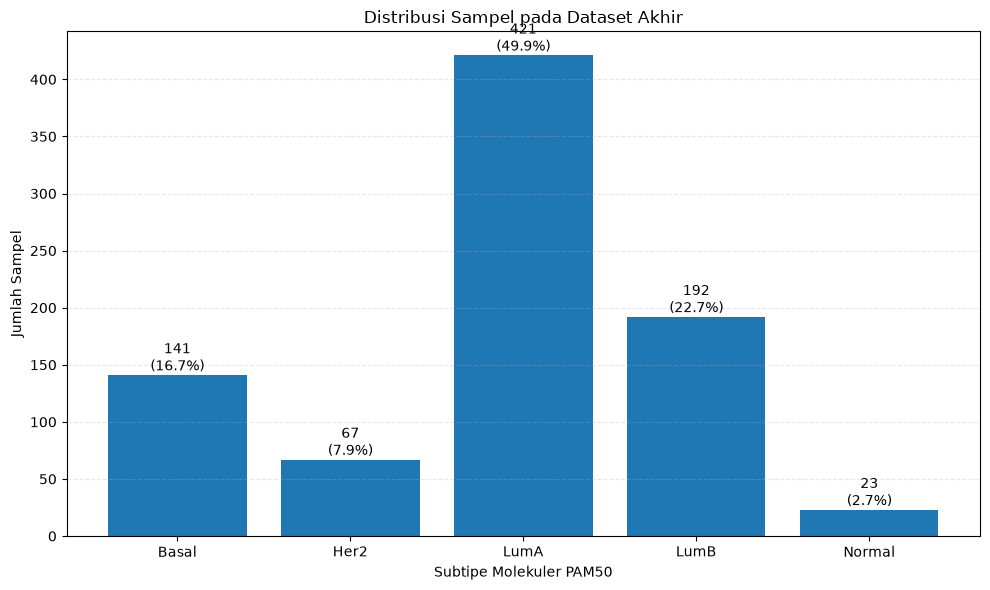


Total sampel: 844
Diagram berhasil disimpan.


In [42]:
# ============================================================
# DIAGRAM BATANG DISTRIBUSI SAMPEL PADA DATASET AKHIR
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Menghitung distribusi sampel setiap kelas
class_distribution = pd.Series(y).value_counts()

# 2. Menyesuaikan urutan kelas berdasarkan class_names
distribution = class_distribution.reindex(
    range(len(class_names)),
    fill_value=0
)

# 3. Membuat tabel distribusi sampel
distribution_df = pd.DataFrame({
    "Subtipe Molekuler PAM50": class_names,
    "Jumlah Sampel": distribution.values
})

distribution_df["Persentase (%)"] = (
    distribution_df["Jumlah Sampel"]
    / distribution_df["Jumlah Sampel"].sum()
    * 100
)

# 4. Menampilkan tabel distribusi
print("DISTRIBUSI SAMPEL PADA DATASET AKHIR")
display(distribution_df.round(2))

# 5. Membuat diagram batang
plt.figure(figsize=(10, 6))

bars = plt.bar(
    distribution_df["Subtipe Molekuler PAM50"],
    distribution_df["Jumlah Sampel"]
)

# 6. Menambahkan jumlah dan persentase di atas batang
for bar, count, percentage in zip(
    bars,
    distribution_df["Jumlah Sampel"],
    distribution_df["Persentase (%)"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.xlabel("Subtipe Molekuler PAM50")
plt.ylabel("Jumlah Sampel")
plt.title("Distribusi Sampel pada Dataset Akhir")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

# 7. Menyimpan diagram
plt.savefig(
    "results/distribusi_sampel_dataset_akhir.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nTotal sampel:", distribution_df["Jumlah Sampel"].sum())
print("Diagram berhasil disimpan.")

In [46]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


Hasil Stratified 5-Fold Cross-Validation:


,Model,Mean Macro-F1,Std Macro-F1
0,Logistic Regression,0.7809,0.0667
1,SVM,0.8312,0.0434
2,Random Forest,0.6995,0.0480
3,XGBoost,0.7310,0.0535


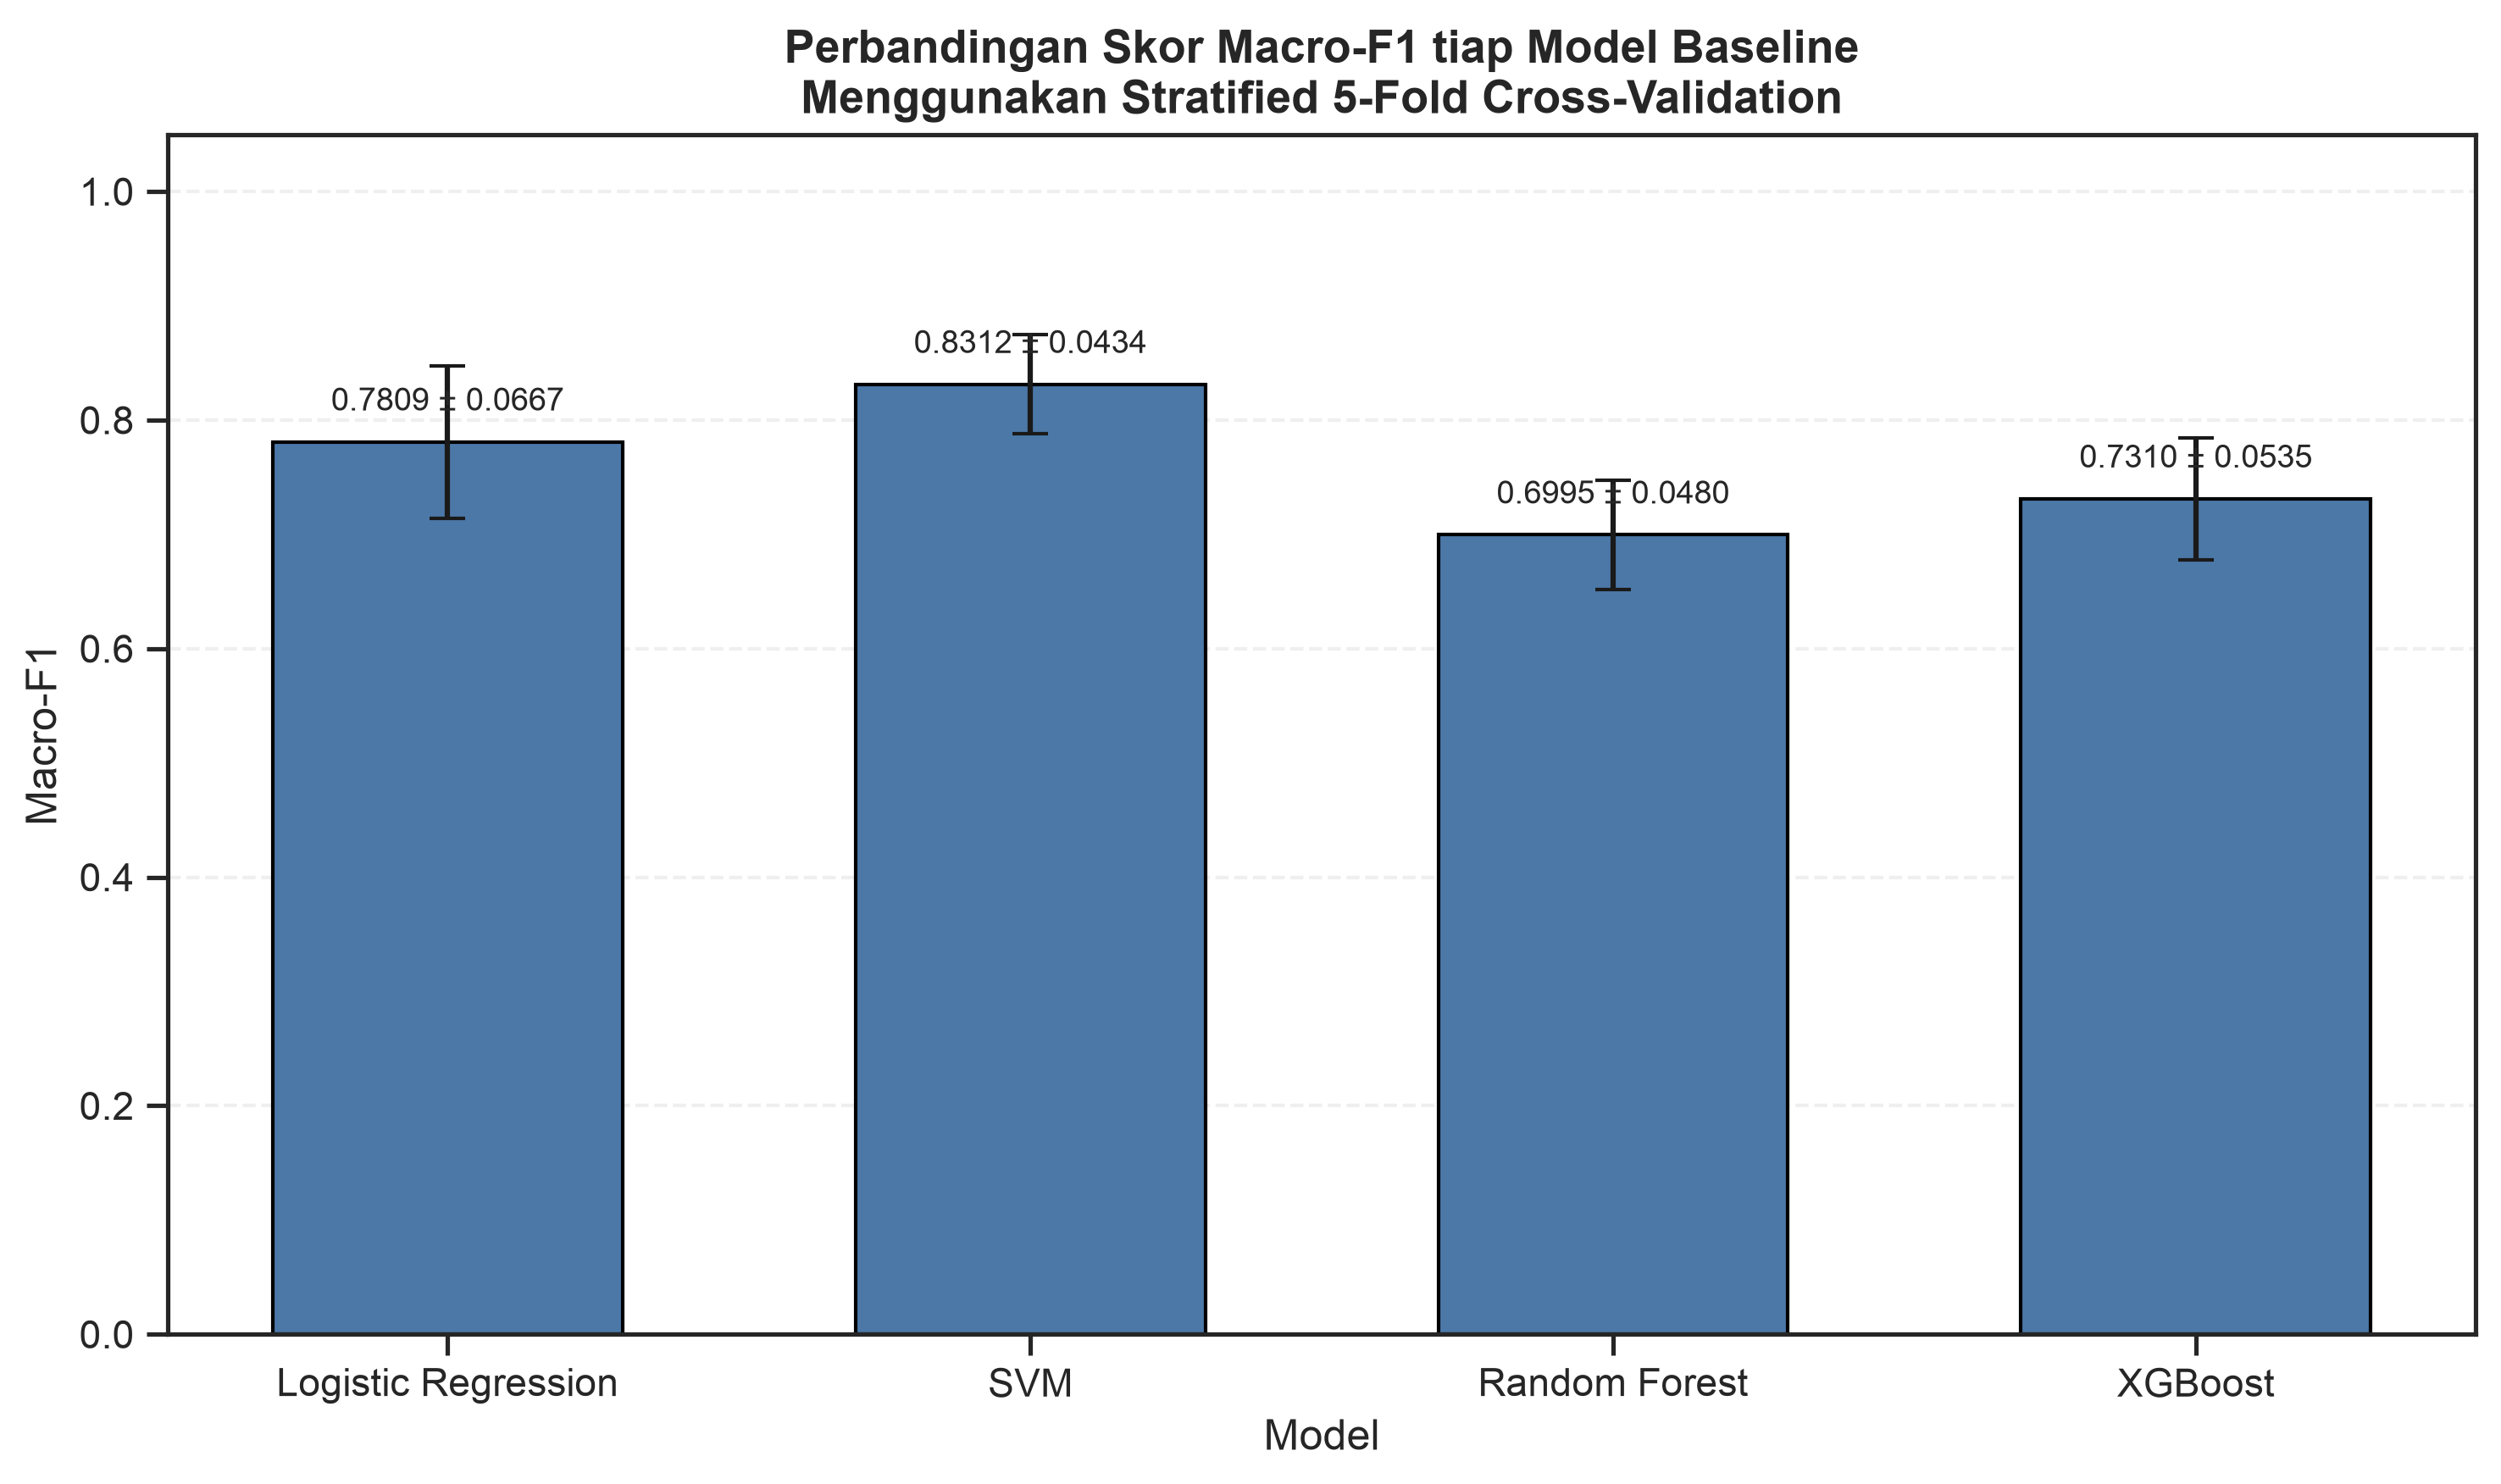

In [49]:
# ============================================================
# PERBANDINGAN MACRO-F1 MODEL BASELINE
# Stratified 5-Fold Cross-Validation
# ============================================================

# Pastikan variabel dan transformer dari sel sebelumnya tersedia.
required_variables = ["X_train", "y_train", "TopVarianceGenes"]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Jalankan sel yang menyiapkan data training dan "
        "TopVarianceGenes terlebih dahulu: "
        + ", ".join(missing_variables)
    )


# ------------------------------------------------------------
# Konfigurasi cross-validation dan preprocessing
# ------------------------------------------------------------

cv_baseline = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

k_genes = min(TOP_K_GENES, X_train.shape[1])

baseline_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        random_state=RANDOM_STATE
    ),
    "SVM": SVC(
        kernel="linear",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1
    )
}

if XGBOOST_AVAILABLE:
    baseline_models["XGBoost"] = XGBClassifier(
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=1
    )


# ------------------------------------------------------------
# Jalankan evaluasi CV
# ------------------------------------------------------------

baseline_cv_rows = []

for model_name, estimator in baseline_models.items():

    steps = [
        ("gene_selector", TopVarianceGenes(k=k_genes))
    ]

    # Scaling diperlukan untuk Logistic Regression dan SVM.
    if model_name in {"Logistic Regression", "SVM"}:
        steps.append(("scaler", StandardScaler()))

    steps.append(("classifier", estimator))
    model_pipeline = Pipeline(steps)

    cv_scores = cross_validate(
        model_pipeline,
        X_train,
        y_train,
        cv=cv_baseline,
        scoring="f1_macro",
        n_jobs=1,
        return_train_score=False
    )

    fold_scores = cv_scores["test_score"]

    baseline_cv_rows.append({
        "Model": model_name,
        "Mean Macro-F1": fold_scores.mean(),
        "Std Macro-F1": fold_scores.std(ddof=1),
        "Fold Scores": fold_scores
    })

baseline_cv_df = pd.DataFrame(baseline_cv_rows)

print("Hasil Stratified 5-Fold Cross-Validation:")
display(
    baseline_cv_df[
        ["Model", "Mean Macro-F1", "Std Macro-F1"]
    ].round(4)
)


# ------------------------------------------------------------
# Plot perbandingan Macro-F1
# ------------------------------------------------------------

plt.figure(figsize=(10, 6), dpi=300)

bars = plt.bar(
    baseline_cv_df["Model"],
    baseline_cv_df["Mean Macro-F1"],
    yerr=baseline_cv_df["Std Macro-F1"],
    capsize=5,
    color="#4C78A8",
    edgecolor="black",
    width=0.6
)

for bar, mean_score, std_score in zip(
    bars,
    baseline_cv_df["Mean Macro-F1"],
    baseline_cv_df["Std Macro-F1"]
):
    plt.annotate(
        f"{mean_score:.4f} ± {std_score:.4f}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title(
    "Perbandingan Skor Macro-F1 tiap Model Baseline\n"
    "Menggunakan Stratified 5-Fold Cross-Validation",
    fontsize=13,
    fontweight="bold"
)
plt.xlabel("Model")
plt.ylabel("Macro-F1")
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "results/figures/baseline_stratified_5fold_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

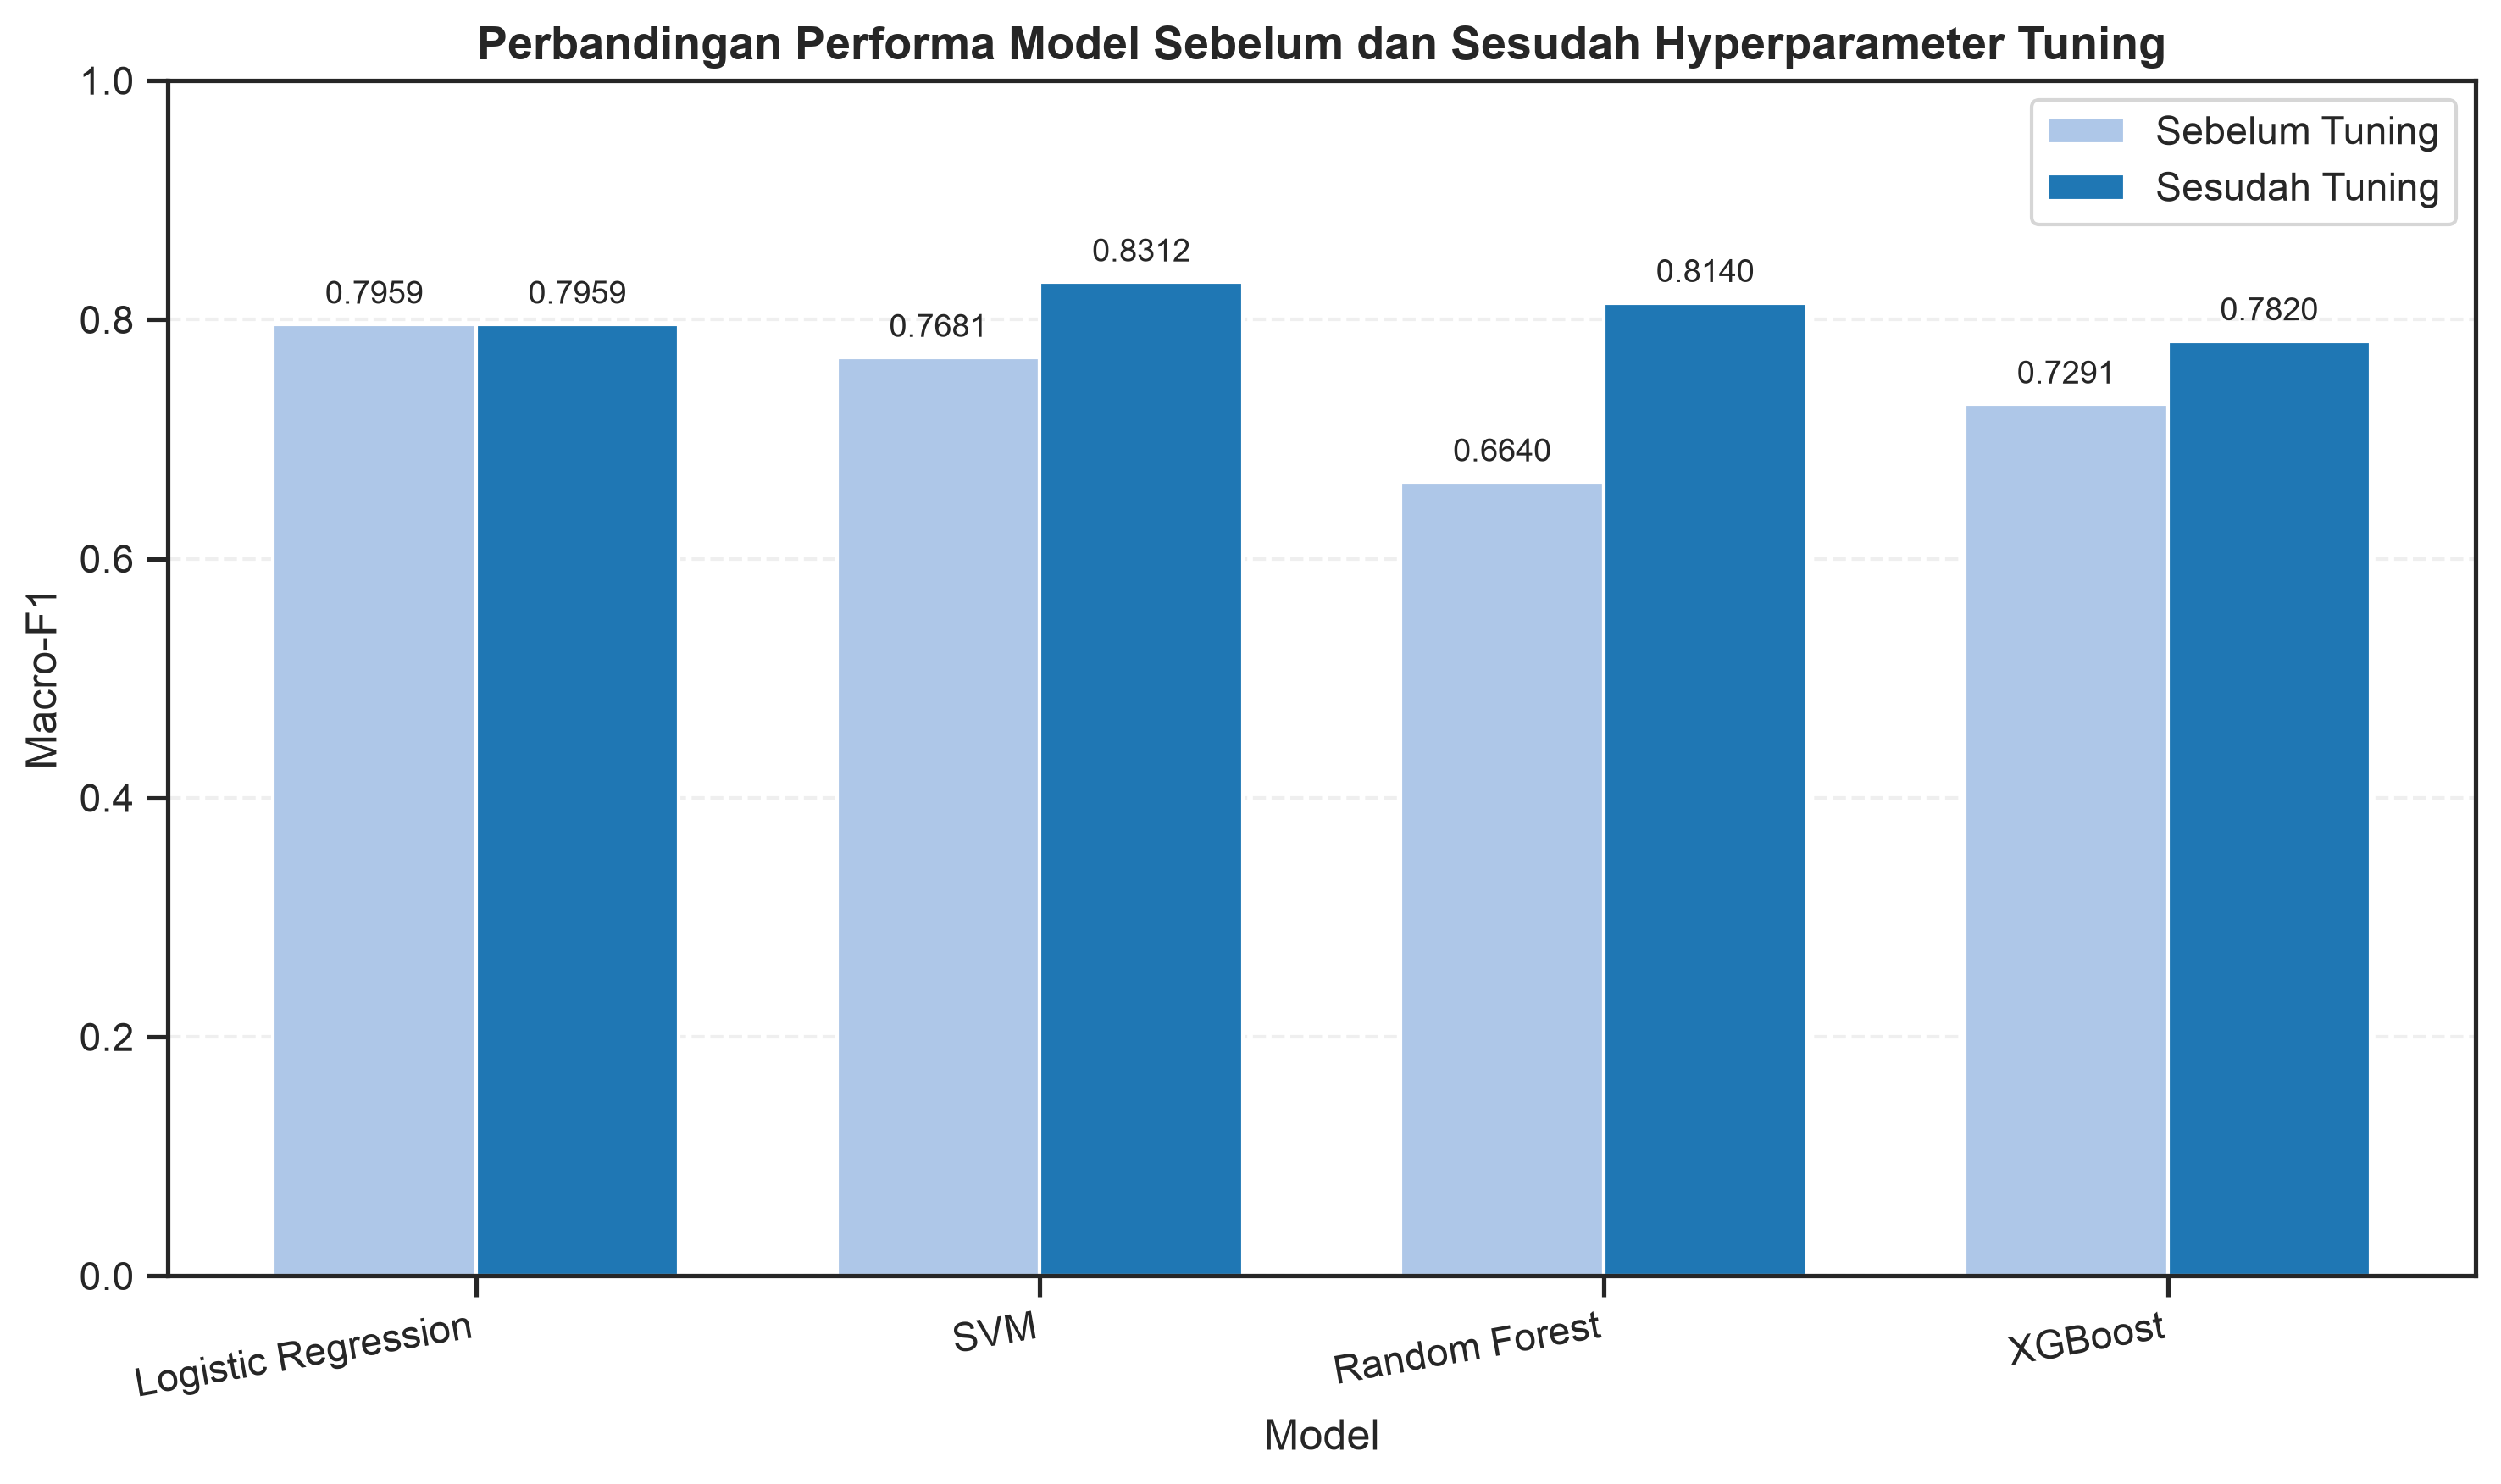

,Model,Sebelum Tuning,Sesudah Tuning
0,Logistic Regression,0.7959,0.7959
1,SVM,0.7681,0.8312
2,Random Forest,0.6640,0.8140
3,XGBoost,0.7291,0.7820


In [50]:
# ============================================================
# GRAFIK PERBANDINGAN PERFORMA SEBELUM & SESUDAH TUNING
# Macro-F1 model baseline vs model setelah hyperparameter tuning
# ============================================================

# Nilai Macro-F1 berdasarkan hasil yang tercantum di notebook
model_names = [
    "Logistic Regression",
    "SVM",
    "Random Forest",
    "XGBoost"
]

macro_f1_before = [0.7959, 0.7681, 0.6640, 0.7291]
macro_f1_after  = [0.7959, 0.8312, 0.8140, 0.7820]

comparison_df = pd.DataFrame({
    "Model": model_names,
    "Sebelum Tuning": macro_f1_before,
    "Sesudah Tuning": macro_f1_after
})

# Plot batang berkelompok
x = np.arange(len(model_names))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

bars_before = ax.bar(
    x - bar_width / 2,
    macro_f1_before,
    bar_width,
    label="Sebelum Tuning",
    color="#aec7e8"
)

bars_after = ax.bar(
    x + bar_width / 2,
    macro_f1_after,
    bar_width,
    label="Sesudah Tuning",
    color="#1f77b4"
)

# Tampilkan nilai di atas batang
for bars in (bars_before, bars_after):
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.4f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_title(
    "Perbandingan Performa Model Sebelum dan Sesudah Hyperparameter Tuning",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_xticks(x)
ax.set_xticklabels(model_names, rotation=10, ha="right")
ax.set_ylim(0, 1.0)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    "results/figures/perbandingan_performa_sebelum_sesudah_tuning.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(comparison_df)

In [51]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

# ============================================================
# ESTIMASI MACRO-F1 MENGGUNAKAN NESTED CROSS-VALIDATION
# Outer CV: evaluasi
# Inner CV: pemilihan hyperparameter
# ============================================================


from sklearn.model_selection import (
    StratifiedKFold,
    GridSearchCV
)


# ------------------------------------------------------------
# 1. Data development saja — hold-out test tidak dipakai
# ------------------------------------------------------------

X_nested = X_train
y_nested = np.asarray(y_train)

n_outer = 5
n_inner = 3

outer_cv = StratifiedKFold(
    n_splits=n_outer,
    shuffle=True,
    random_state=RANDOM_STATE
)

inner_cv = StratifiedKFold(
    n_splits=n_inner,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ------------------------------------------------------------
# 2. Model dan ruang hyperparameter
# Selector dan scaler di dalam Pipeline mencegah leakage.
# ------------------------------------------------------------

k_genes = min(TOP_K_GENES, X_nested.shape[1])

model_specs = {
    "Logistic Regression": {
        "estimator": LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_STATE
        ),
        "params": {
            "classifier__C": [0.1, 1.0, 10.0],
            "classifier__class_weight": [None, "balanced"]
        }
    },

    "SVM": {
        "estimator": SVC(
            kernel="linear",
            random_state=RANDOM_STATE
        ),
        "params": {
            "classifier__C": [0.01, 0.1, 1.0],
            "classifier__class_weight": [None, "balanced"]
        }
    },

    "Random Forest": {
        "estimator": RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        "params": {
            "classifier__n_estimators": [200, 400],
            "classifier__max_features": ["sqrt"],
            "classifier__min_samples_leaf": [1, 2],
            "classifier__class_weight": [None, "balanced"]
        }
    }
}

if XGBOOST_AVAILABLE:
    model_specs["XGBoost"] = {
        "estimator": XGBClassifier(
            objective="multi:softprob",
            num_class=len(label_encoder.classes_),
            eval_metric="mlogloss",
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        "params": {
            "classifier__n_estimators": [200, 400],
            "classifier__max_depth": [2, 4],
            "classifier__learning_rate": [0.05, 0.1]
        }
    }


# ------------------------------------------------------------
# 3. Jalankan nested cross-validation
# ------------------------------------------------------------

fold_results = []

for model_name, spec in model_specs.items():

    print(f"\nNested CV: {model_name}")

    for fold, (train_idx, valid_idx) in enumerate(
        outer_cv.split(X_nested, y_nested),
        start=1
    ):
        pipeline = Pipeline([
            ("gene_selector", TopVarianceGenes(k=k_genes)),
            ("scaler", StandardScaler()),
            ("classifier", spec["estimator"])
        ])

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=spec["params"],
            scoring="f1_macro",
            cv=inner_cv,
            refit=True,
            n_jobs=1,
            error_score="raise"
        )

        X_outer_train = X_nested.iloc[train_idx]
        X_outer_valid = X_nested.iloc[valid_idx]
        y_outer_train = y_nested[train_idx]
        y_outer_valid = y_nested[valid_idx]

        search.fit(X_outer_train, y_outer_train)
        y_outer_pred = search.predict(X_outer_valid)

        outer_macro_f1 = f1_score(
            y_outer_valid,
            y_outer_pred,
            average="macro",
            zero_division=0
        )

        fold_results.append({
            "Model": model_name,
            "Outer_Fold": fold,
            "Macro_F1": outer_macro_f1,
            "Best_Inner_CV_Macro_F1": search.best_score_,
            "Best_Parameters": search.best_params_
        })

        print(
            f"  Fold {fold}: Macro-F1={outer_macro_f1:.4f}"
        )


# ------------------------------------------------------------
# 4. Ringkasan mean dan standar deviasi antar outer fold
# ------------------------------------------------------------

nested_cv_results = pd.DataFrame(fold_results)

nested_cv_summary = (
    nested_cv_results
    .groupby("Model")["Macro_F1"]
    .agg(
        Mean_Macro_F1="mean",
        Std_Macro_F1="std"
    )
    .reset_index()
    .sort_values("Mean_Macro_F1", ascending=False)
)

print("\nRINGKASAN NESTED CROSS-VALIDATION")
display(nested_cv_summary.round(4))

print("Skor Macro-F1 per outer fold:")
display(
    nested_cv_results[
        ["Model", "Outer_Fold", "Macro_F1"]
    ].pivot(
        index="Outer_Fold",
        columns="Model",
        values="Macro_F1"
    ).round(4)
)


# ------------------------------------------------------------
# 5. Simpan hasil
# ------------------------------------------------------------

nested_cv_results.to_csv(
    "results/tables/nested_cv_fold_results.csv",
    index=False
)

nested_cv_summary.to_csv(
    "results/tables/nested_cv_macro_f1_summary.csv",
    index=False
)

print("\nHasil disimpan di results/tables/.")


Nested CV: Logistic Regression
  Fold 1: Macro-F1=0.7740
  Fold 2: Macro-F1=0.7800
  Fold 3: Macro-F1=0.8535
  Fold 4: Macro-F1=0.8279
  Fold 5: Macro-F1=0.8127

Nested CV: SVM
  Fold 1: Macro-F1=0.8109
  Fold 2: Macro-F1=0.8186
  Fold 3: Macro-F1=0.8915
  Fold 4: Macro-F1=0.8557
  Fold 5: Macro-F1=0.7792

Nested CV: Random Forest
  Fold 1: Macro-F1=0.6842
  Fold 2: Macro-F1=0.7919
  Fold 3: Macro-F1=0.8888
  Fold 4: Macro-F1=0.7972
  Fold 5: Macro-F1=0.7634

Nested CV: XGBoost
  Fold 1: Macro-F1=0.7112
  Fold 2: Macro-F1=0.6547
  Fold 3: Macro-F1=0.7554
  Fold 4: Macro-F1=0.7798
  Fold 5: Macro-F1=0.7633

RINGKASAN NESTED CROSS-VALIDATION


,Model,Mean_Macro_F1,Std_Macro_F1
2,SVM,0.8312,0.0434
0,Logistic Regression,0.8096,0.0332
1,Random Forest,0.7851,0.0735
3,XGBoost,0.7329,0.0505


Skor Macro-F1 per outer fold:


Model,Logistic Regression,Random Forest,SVM,XGBoost
Outer_Fold,,,,
1,0.7740,0.6842,0.8109,0.7112
2,0.7800,0.7919,0.8186,0.6547
3,0.8535,0.8888,0.8915,0.7554
4,0.8279,0.7972,0.8557,0.7798
5,0.8127,0.7634,0.7792,0.7633



Hasil disimpan di results/tables/.


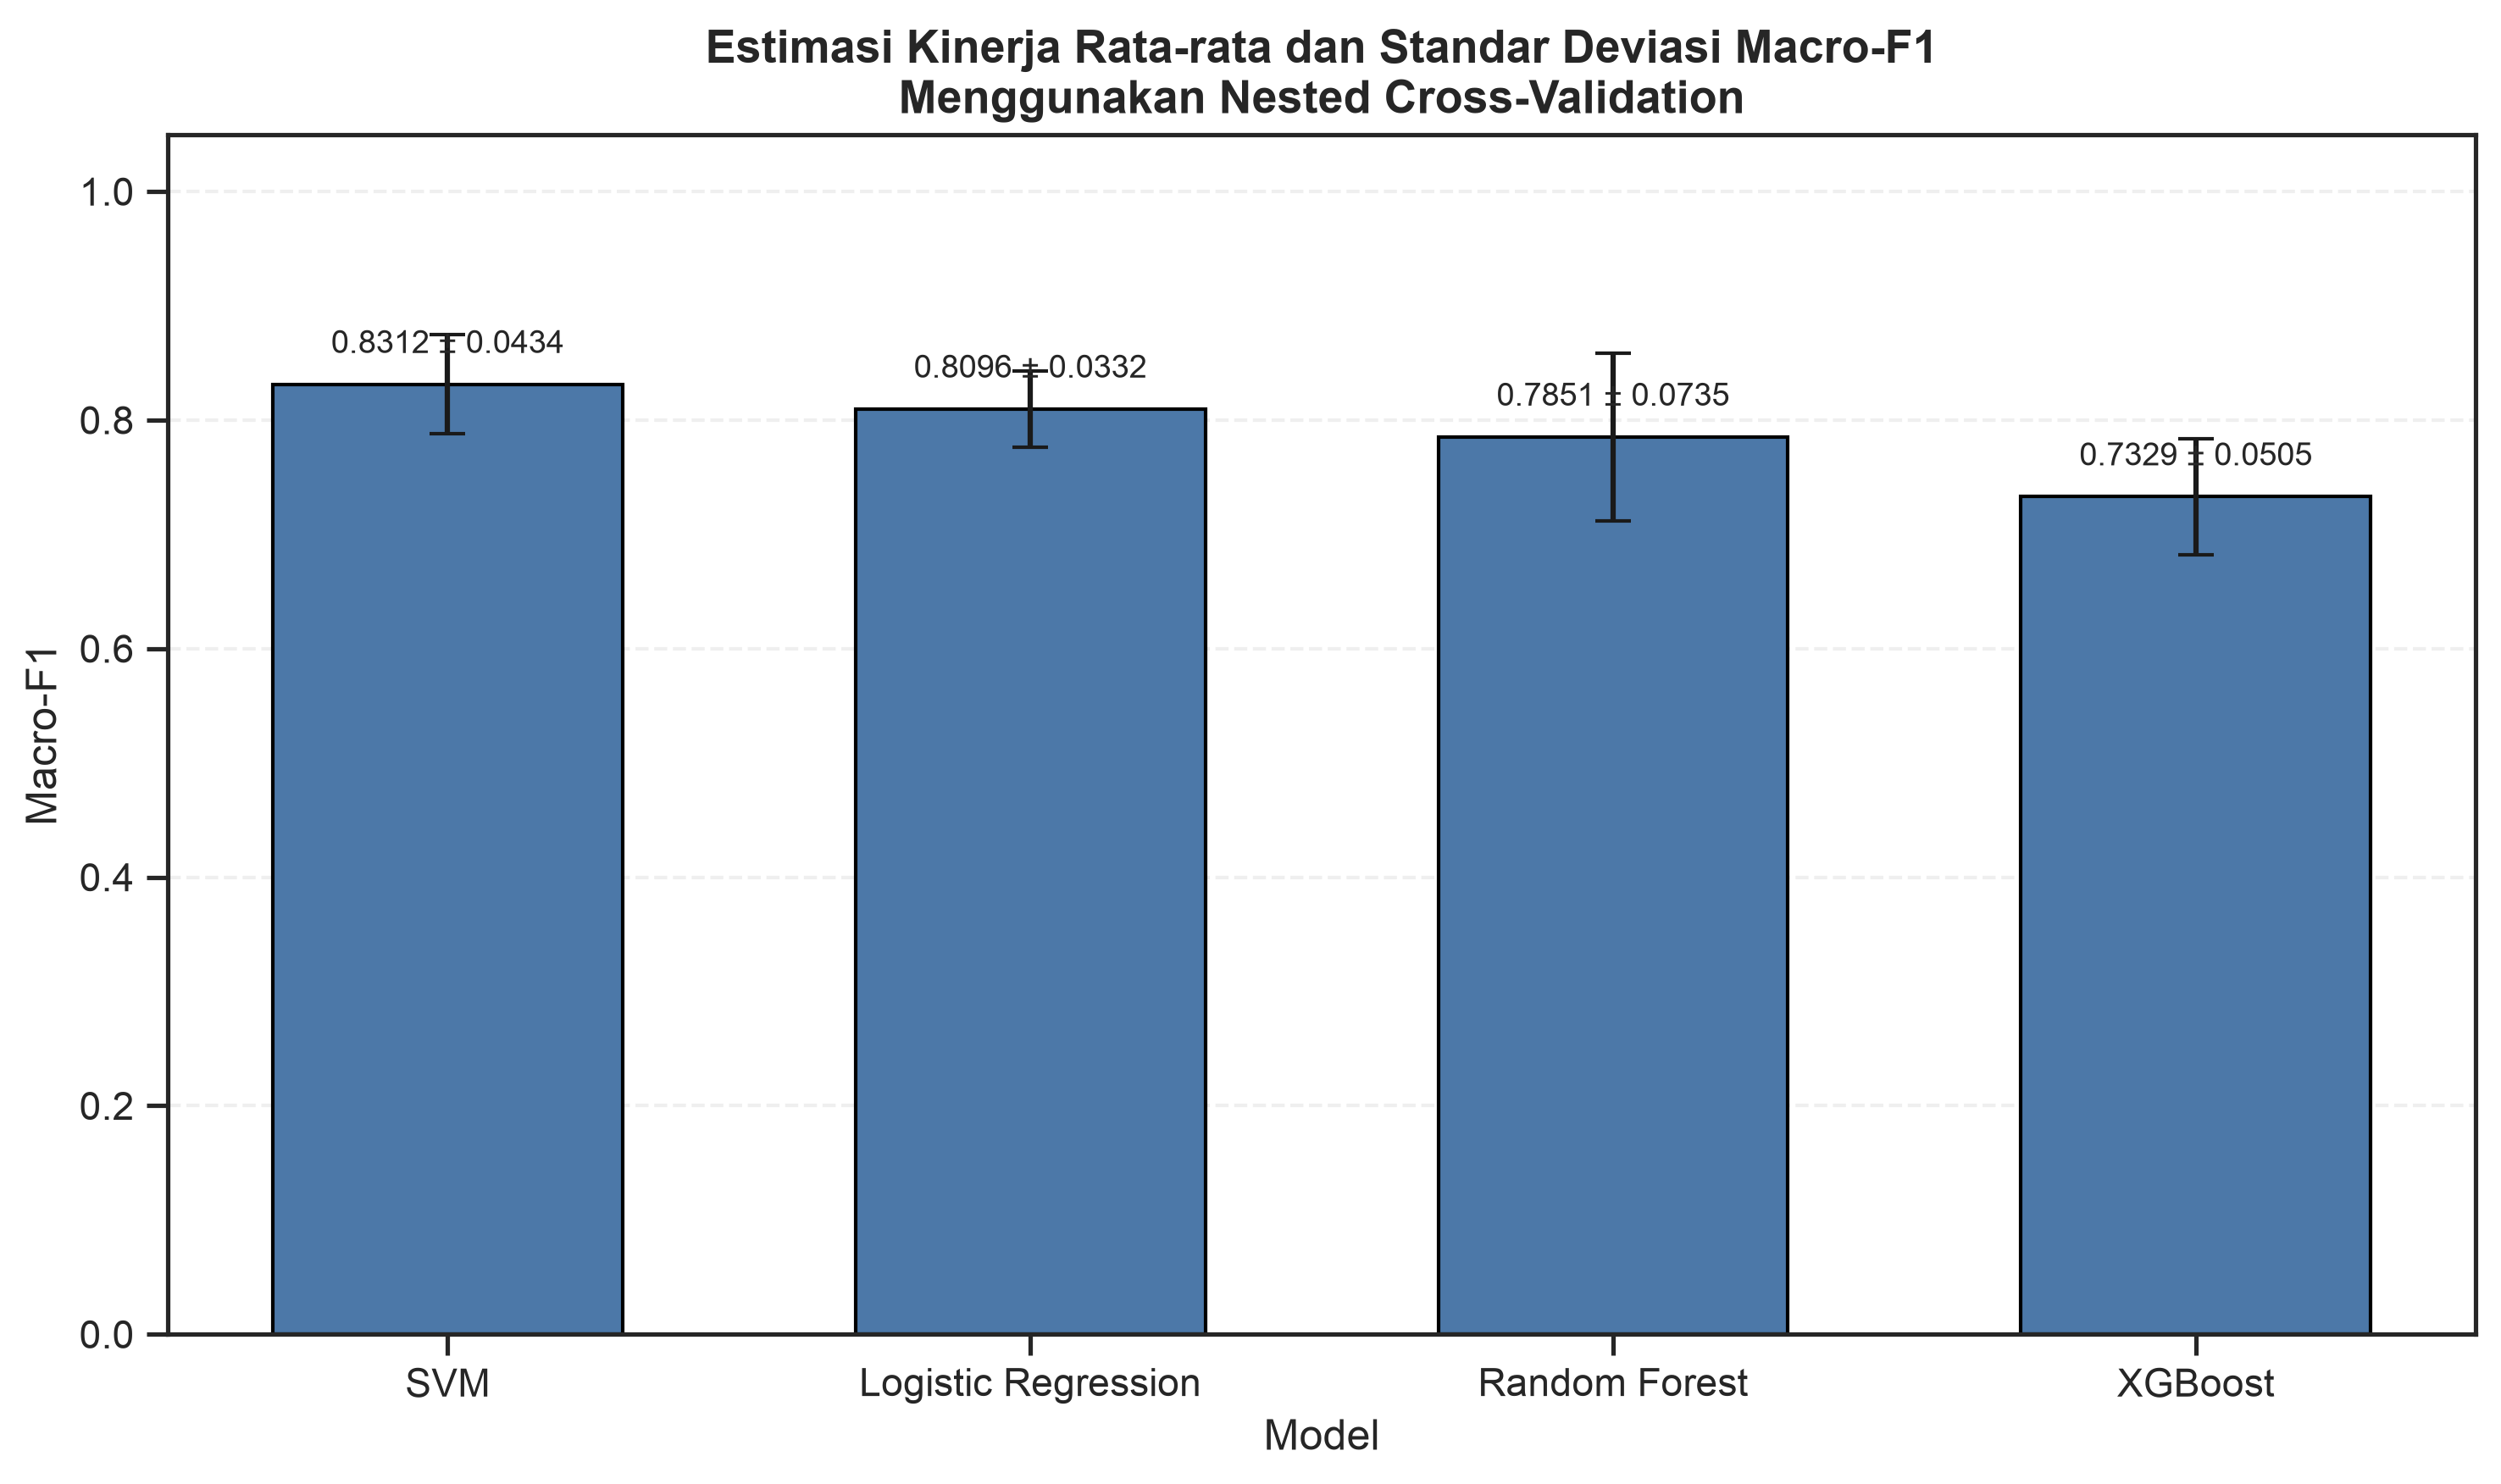

In [52]:
# ============================================================
# ESTIMASI RATA-RATA ± STANDAR DEVIASI MACRO-F1
# NESTED CROSS-VALIDATION
# ============================================================

plot_data = nested_cv_summary.sort_values(
    "Mean_Macro_F1",
    ascending=False
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

bars = ax.bar(
    plot_data["Model"],
    plot_data["Mean_Macro_F1"],
    yerr=plot_data["Std_Macro_F1"],
    capsize=5,
    color="#4C78A8",
    edgecolor="black",
    width=0.6
)

for bar, mean_score, std_score in zip(
    bars,
    plot_data["Mean_Macro_F1"],
    plot_data["Std_Macro_F1"]
):
    ax.annotate(
        f"{mean_score:.4f} ± {std_score:.4f}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Estimasi Kinerja Rata-rata dan Standar Deviasi Macro-F1\n"
    "Menggunakan Nested Cross-Validation",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/figures/nested_cv_macro_f1_mean_std.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

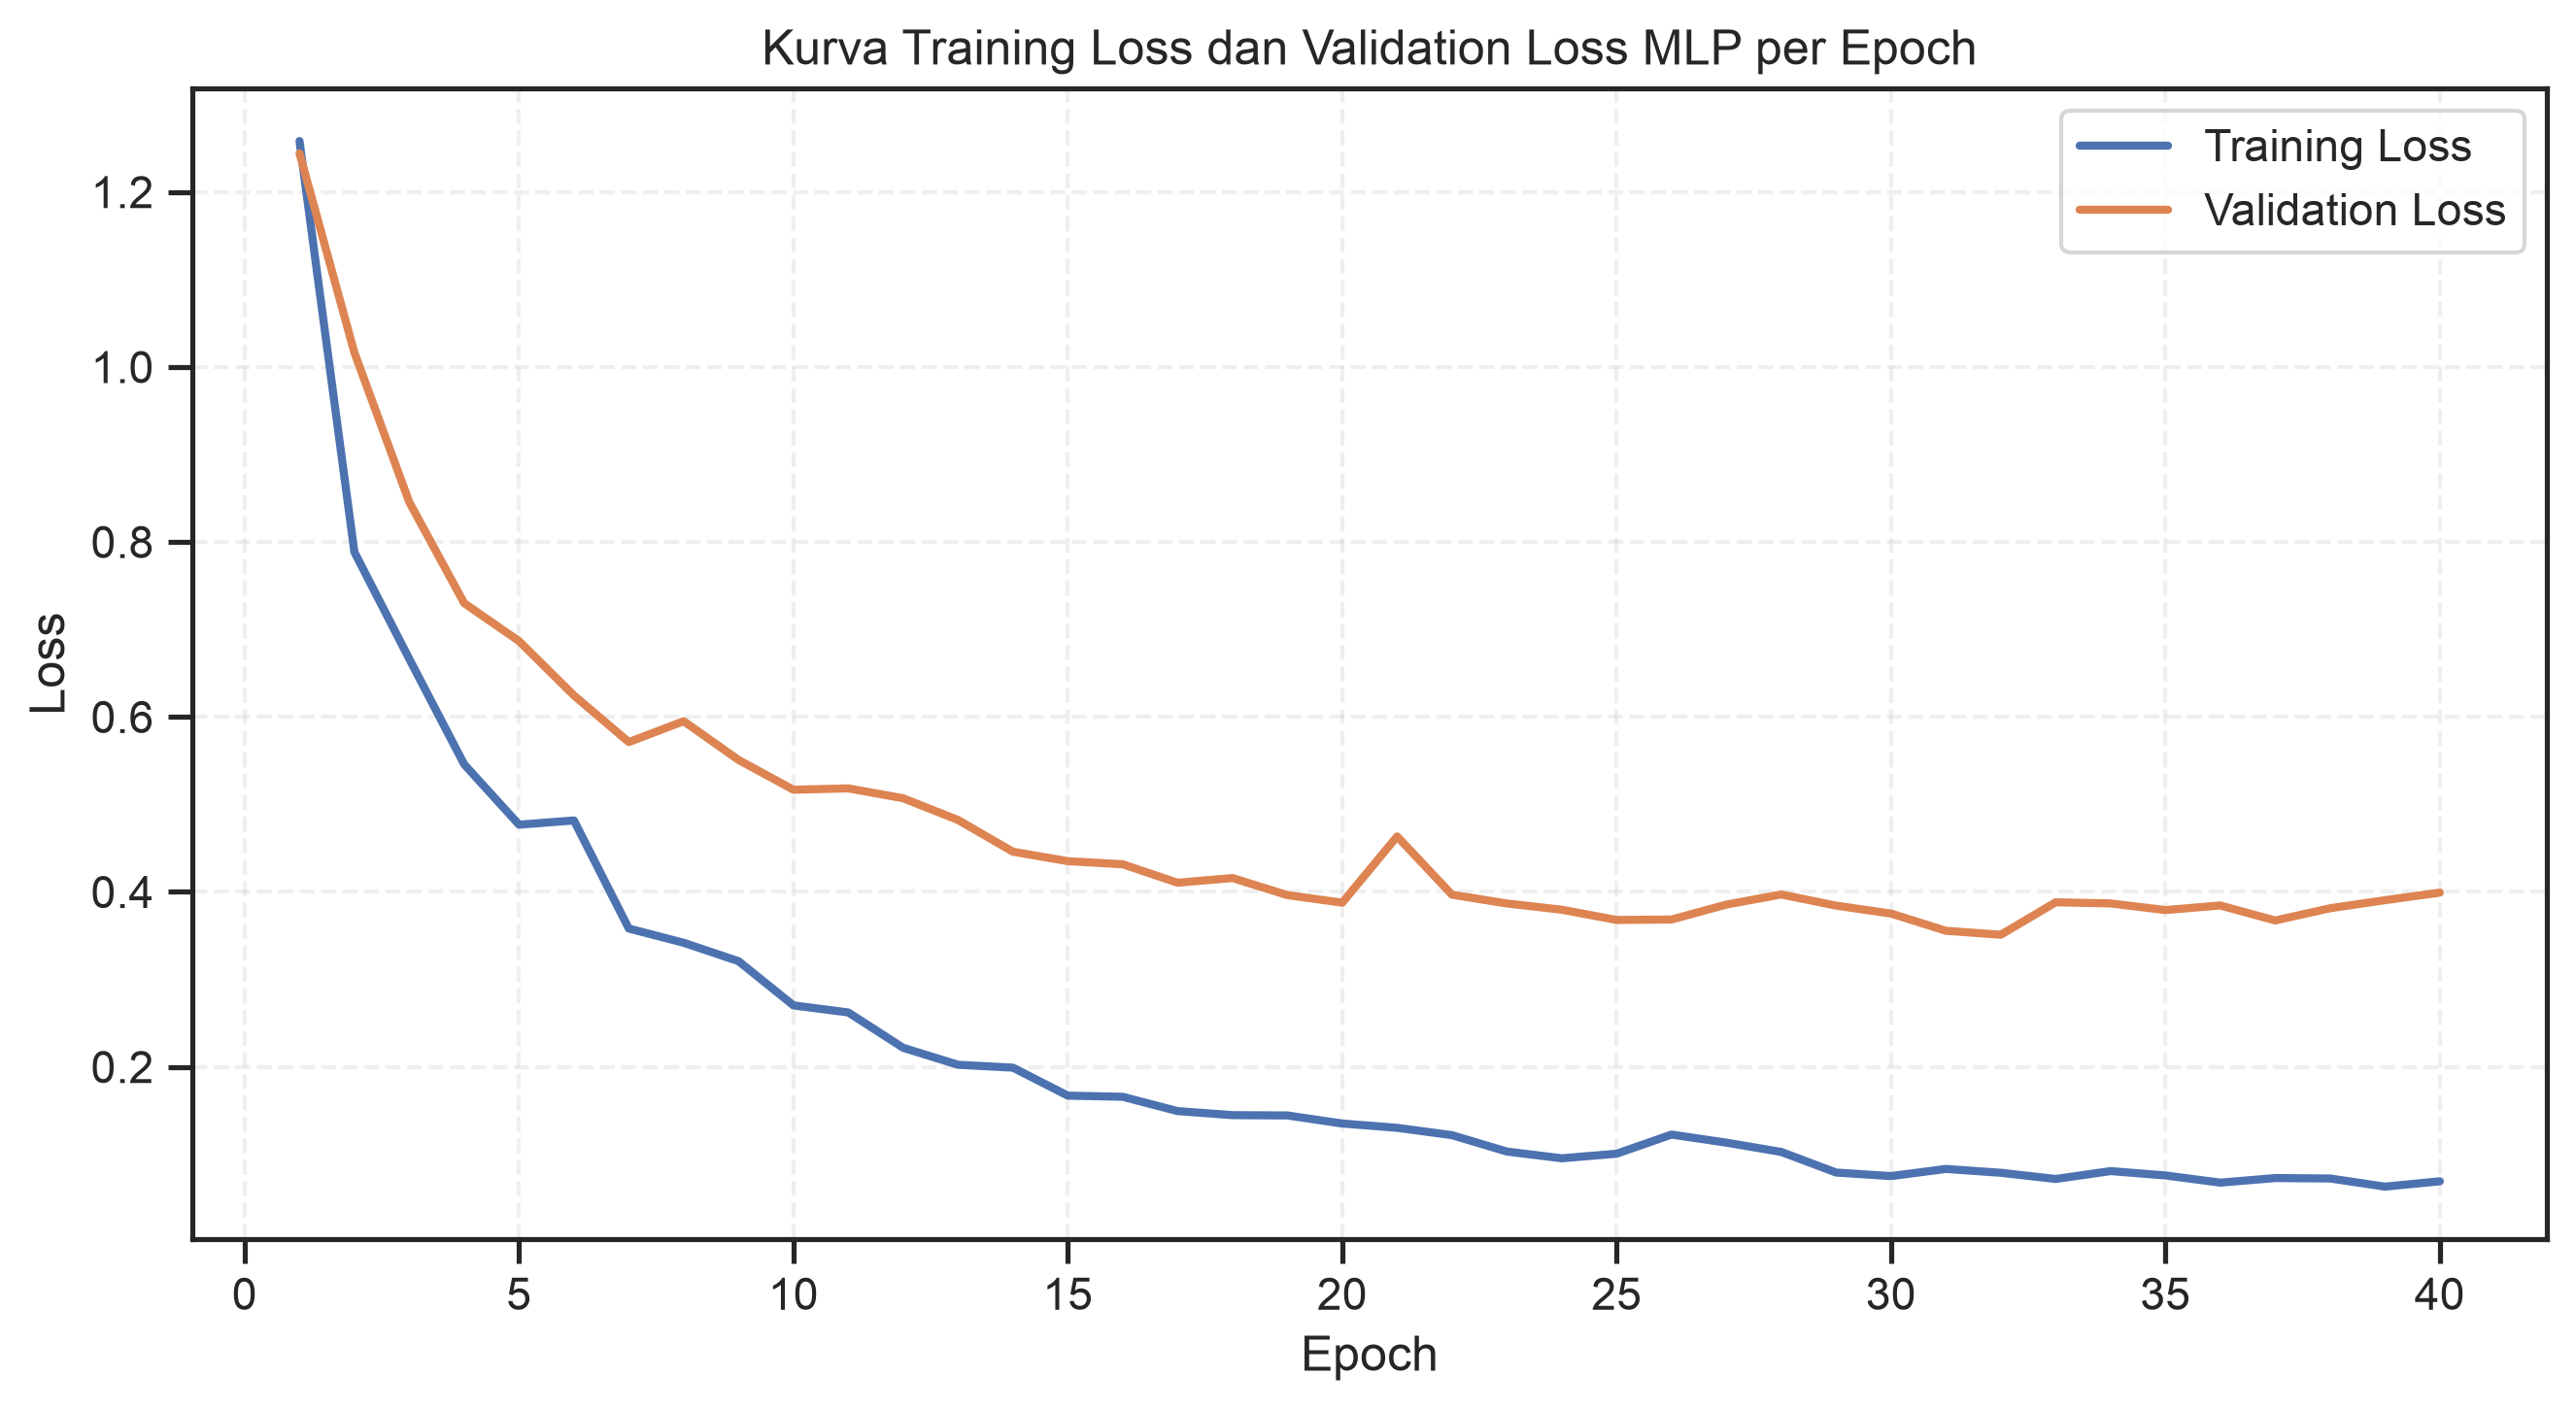

In [53]:
# Pastikan history berasal dari pelatihan dengan validation_data
if "val_loss" not in history.history:
    raise ValueError(
        "Riwayat val_loss tidak ditemukan. "
        "Pastikan model dilatih dengan validation_data."
    )

epochs = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(9, 5), dpi=300)
plt.plot(epochs, history.history["loss"], label="Training Loss", linewidth=2)
plt.plot(epochs, history.history["val_loss"], label="Validation Loss", linewidth=2)

plt.title("Kurva Training Loss dan Validation Loss MLP per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "results/figures/mlp_training_validation_loss.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

,Subtipe PAM50,MLP,SVM
0,Basal,0.9787,0.9787
1,Her2,0.9167,0.9091
2,LumA,0.9313,0.8824
3,LumB,0.8254,0.7213
4,Normal,0.4000,0.5000


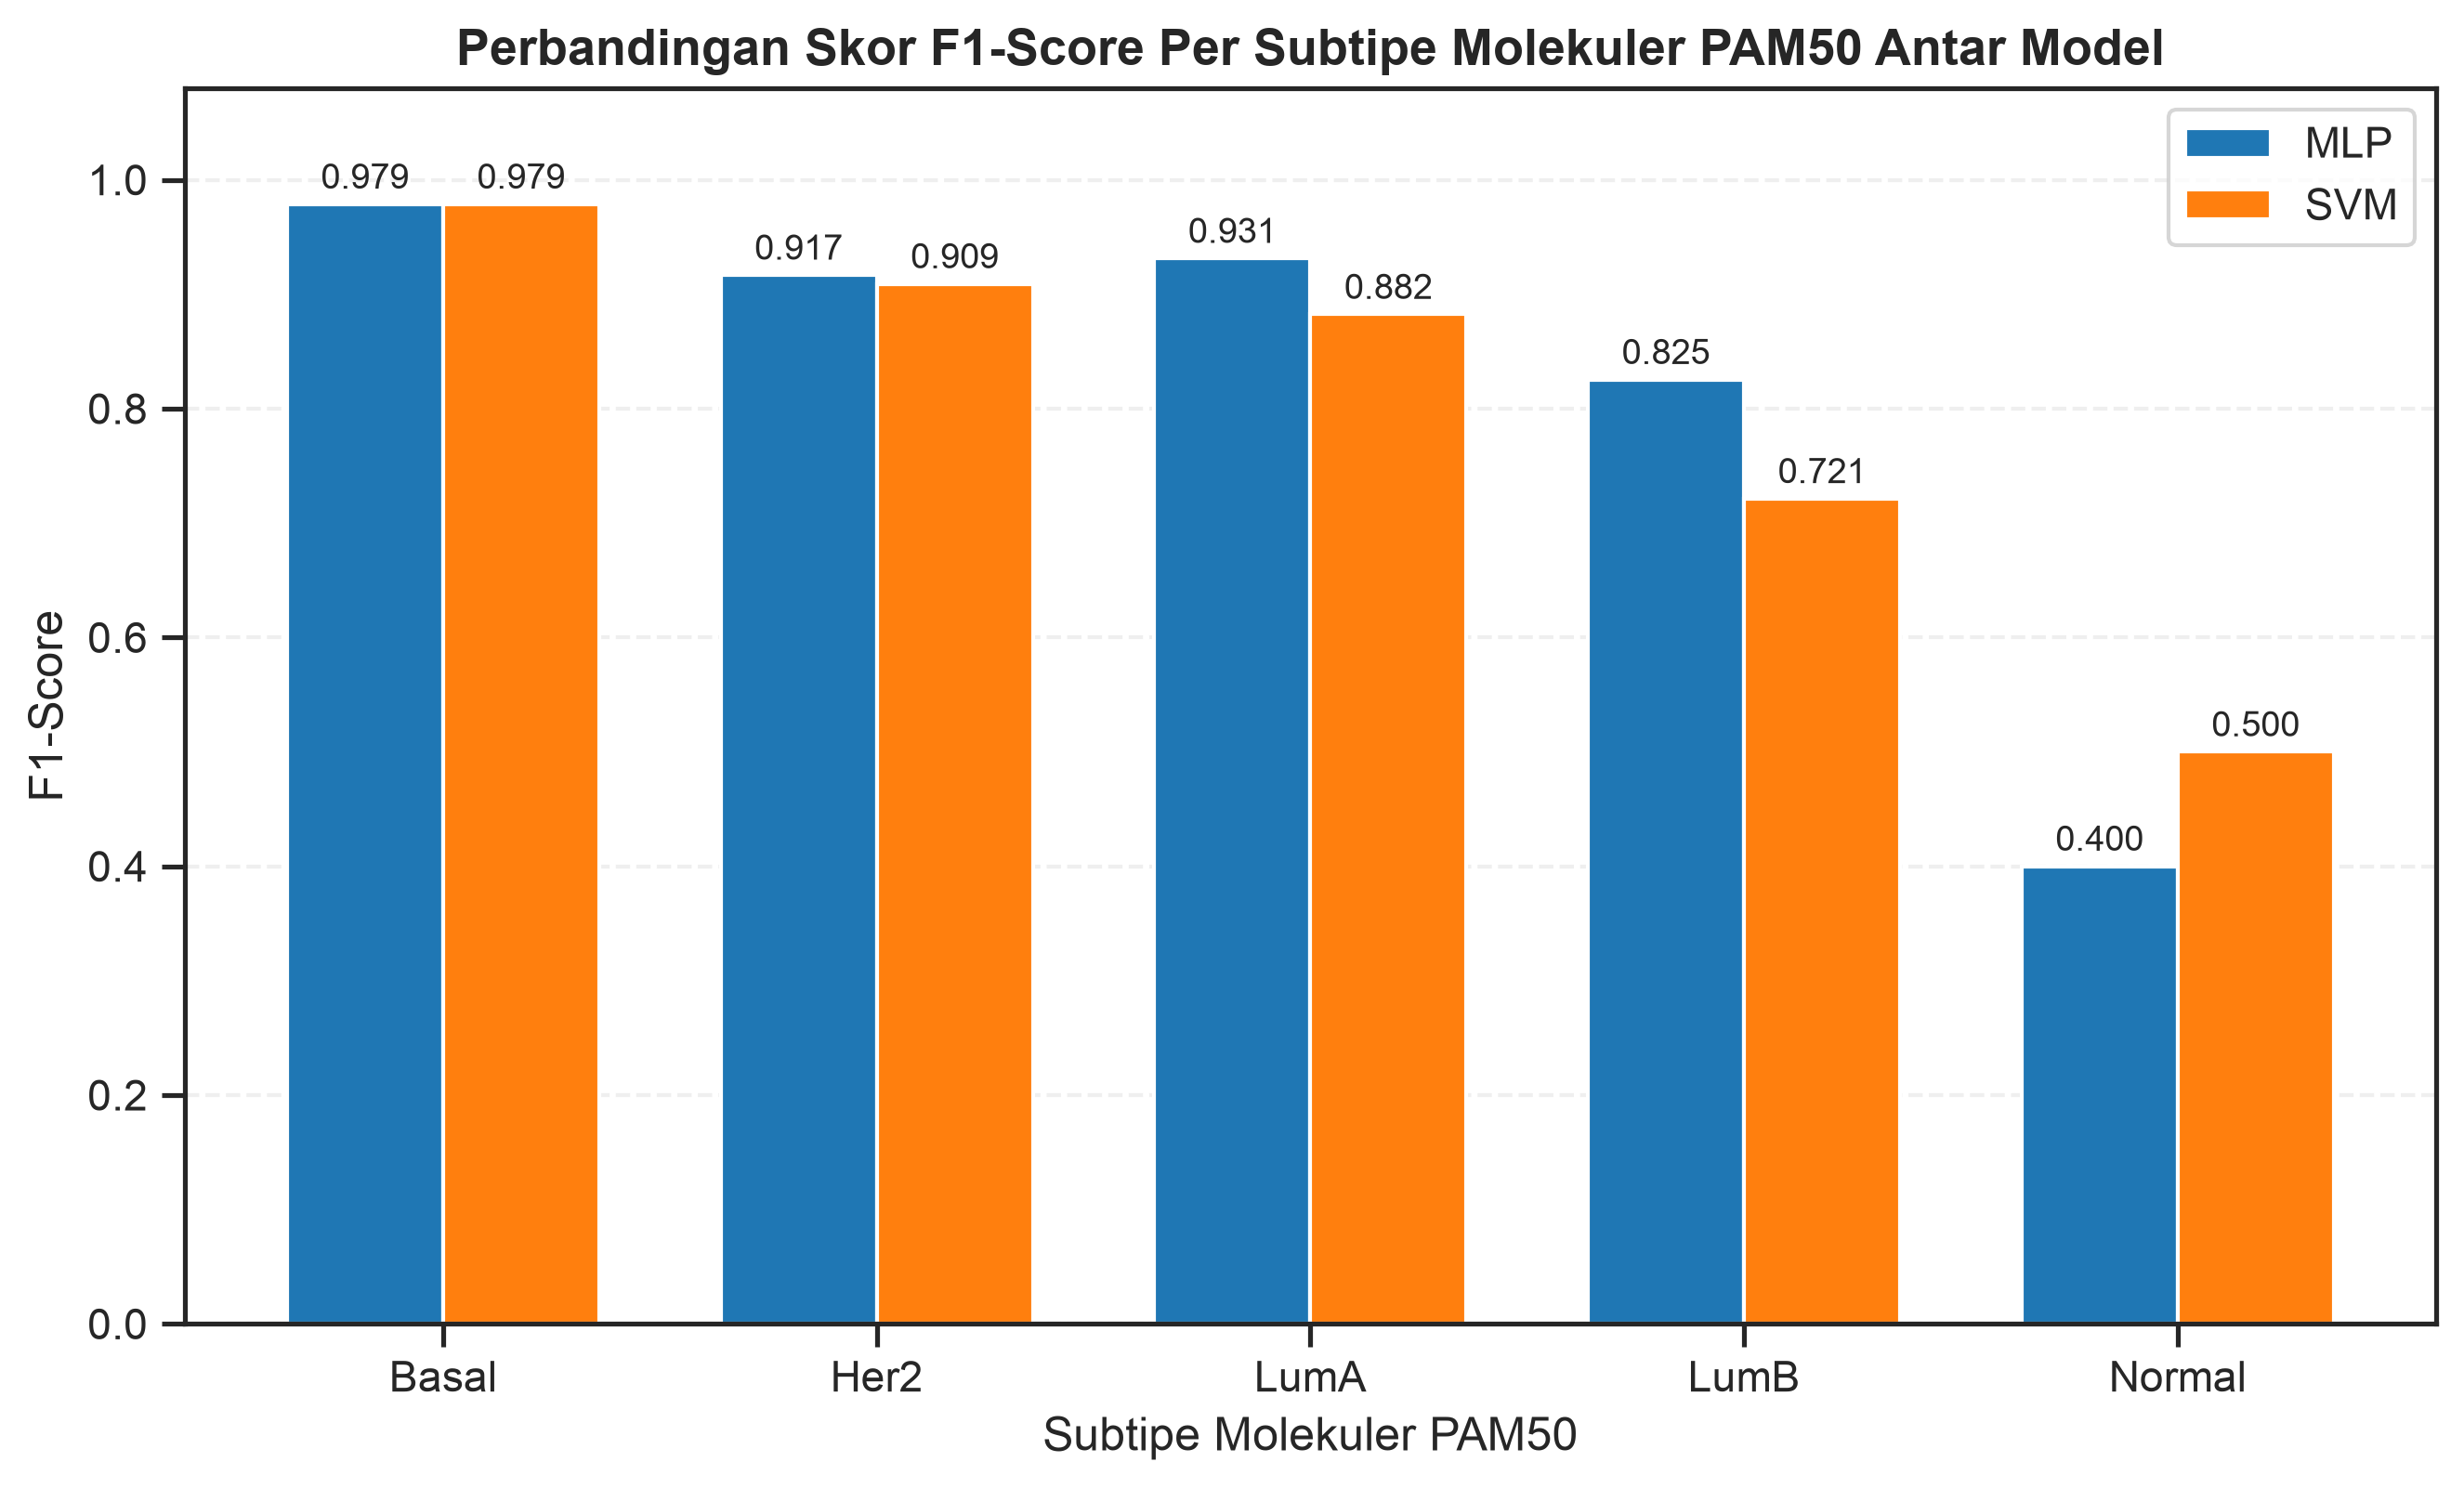

In [54]:
# F1-Score per subtipe
pam50_classes = np.asarray(label_encoder.classes_)
class_ids = np.arange(len(pam50_classes))

f1_mlp = f1_score(
    y_val_dl_array,
    y_val_pred_mlp,
    labels=class_ids,
    average=None,
    zero_division=0
)

f1_svm = f1_score(
    y_val_dl_array,
    y_val_pred_svm,
    labels=class_ids,
    average=None,
    zero_division=0
)

f1_comparison_df = pd.DataFrame({
    "Subtipe PAM50": pam50_classes,
    "MLP": f1_mlp,
    "SVM": f1_svm
})

display(f1_comparison_df.round(4))

# Grafik batang berkelompok
x = np.arange(len(pam50_classes))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=300)

bars_mlp = ax.bar(
    x - bar_width / 2,
    f1_mlp,
    bar_width,
    label="MLP",
    color="#1f77b4"
)

bars_svm = ax.bar(
    x + bar_width / 2,
    f1_svm,
    bar_width,
    label="SVM",
    color="#ff7f0e"
)

for bars in (bars_mlp, bars_svm):
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.3f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

ax.set_title(
    "Perbandingan Skor F1-Score Per Subtipe Molekuler PAM50 Antar Model",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Subtipe Molekuler PAM50")
ax.set_ylabel("F1-Score")
ax.set_xticks(x)
ax.set_xticklabels(pam50_classes)
ax.set_ylim(0, 1.08)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()
plt.tight_layout()

plt.savefig(
    "results/figures/perbandingan_f1_per_subtipe_pam50.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

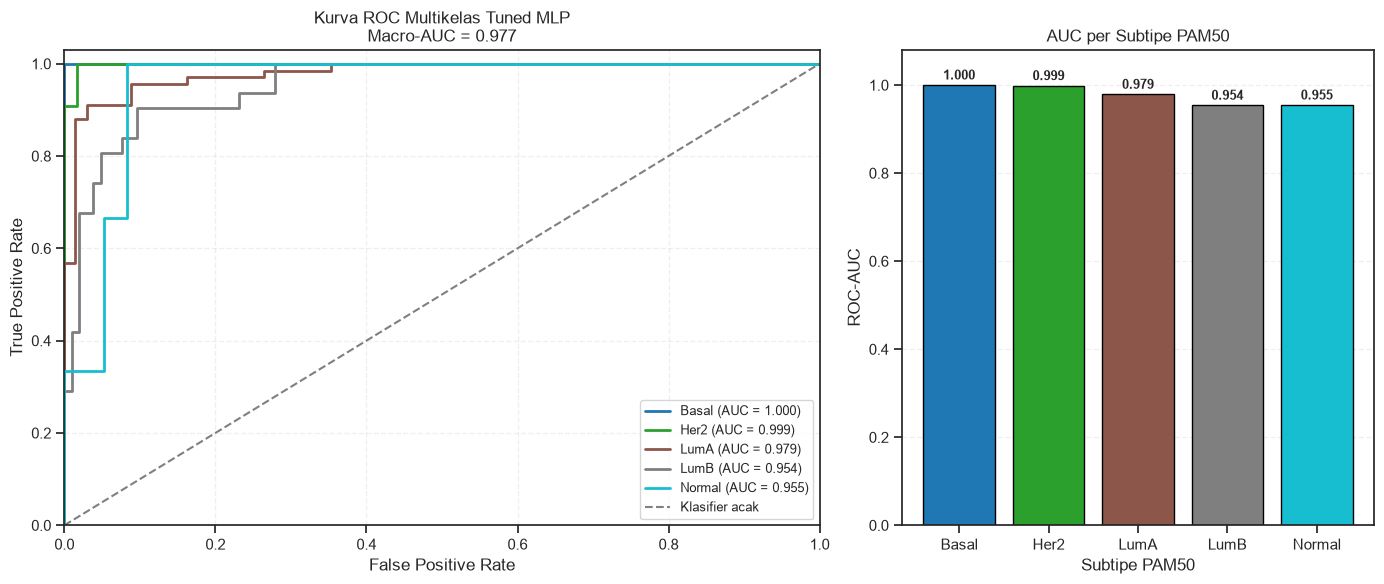

Macro-AUC: 0.9772


In [55]:
# ============================================================
# ROC MULTIKELAS DAN AUC PER SUBTIPE PAM50 — TUNED MLP
# ============================================================

# Pastikan urutan kolom probabilitas sama dengan urutan kelas
roc_class_names = np.asarray(label_encoder.classes_)
y_true_bin_roc = np.asarray(y_val_bin)
y_score_roc = np.asarray(y_val_prob_mlp)

if y_true_bin_roc.shape != y_score_roc.shape:
    raise ValueError(
        f"Bentuk y_val_bin {y_true_bin_roc.shape} tidak cocok "
        f"dengan probabilitas model {y_score_roc.shape}."
    )

# Hitung kurva ROC dan AUC one-vs-rest untuk tiap subtipe
roc_results = {}

for class_id, subtype in enumerate(roc_class_names):
    fpr, tpr, _ = roc_curve(
        y_true_bin_roc[:, class_id],
        y_score_roc[:, class_id]
    )

    class_auc = auc(fpr, tpr)
    roc_results[subtype] = {
        "fpr": fpr,
        "tpr": tpr,
        "auc": class_auc
    }

macro_auc = np.mean([
    result["auc"] for result in roc_results.values()
])

# Buat gambar: kurva ROC dan diagram AUC per subtipe
fig, (ax_roc, ax_auc) = plt.subplots(
    1, 2,
    figsize=(14, 6),
    gridspec_kw={"width_ratios": [1.6, 1]}
)

colors = plt.cm.tab10(
    np.linspace(0, 1, len(roc_class_names))
)

for color, subtype in zip(colors, roc_class_names):
    result = roc_results[subtype]

    ax_roc.plot(
        result["fpr"],
        result["tpr"],
        color=color,
        linewidth=2,
        label=f"{subtype} (AUC = {result['auc']:.3f})"
    )

ax_roc.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1.5,
    label="Klasifier acak"
)

ax_roc.set(
    title=f"Kurva ROC Multikelas Tuned MLP\nMacro-AUC = {macro_auc:.3f}",
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    xlim=(0, 1),
    ylim=(0, 1.03)
)
ax_roc.grid(linestyle="--", alpha=0.3)
ax_roc.legend(loc="lower right", fontsize=9)

auc_values = [
    roc_results[subtype]["auc"]
    for subtype in roc_class_names
]

bars = ax_auc.bar(
    roc_class_names,
    auc_values,
    color=colors,
    edgecolor="black"
)

ax_auc.set(
    title="AUC per Subtipe PAM50",
    xlabel="Subtipe PAM50",
    ylabel="ROC-AUC",
    ylim=(0, 1.08)
)
ax_auc.grid(axis="y", linestyle="--", alpha=0.3)

for bar, score in zip(bars, auc_values):
    ax_auc.annotate(
        f"{score:.3f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

fig.tight_layout()
fig.savefig(
    "results/figures/tuned_mlp_multiclass_roc_auc.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"Macro-AUC: {macro_auc:.4f}")

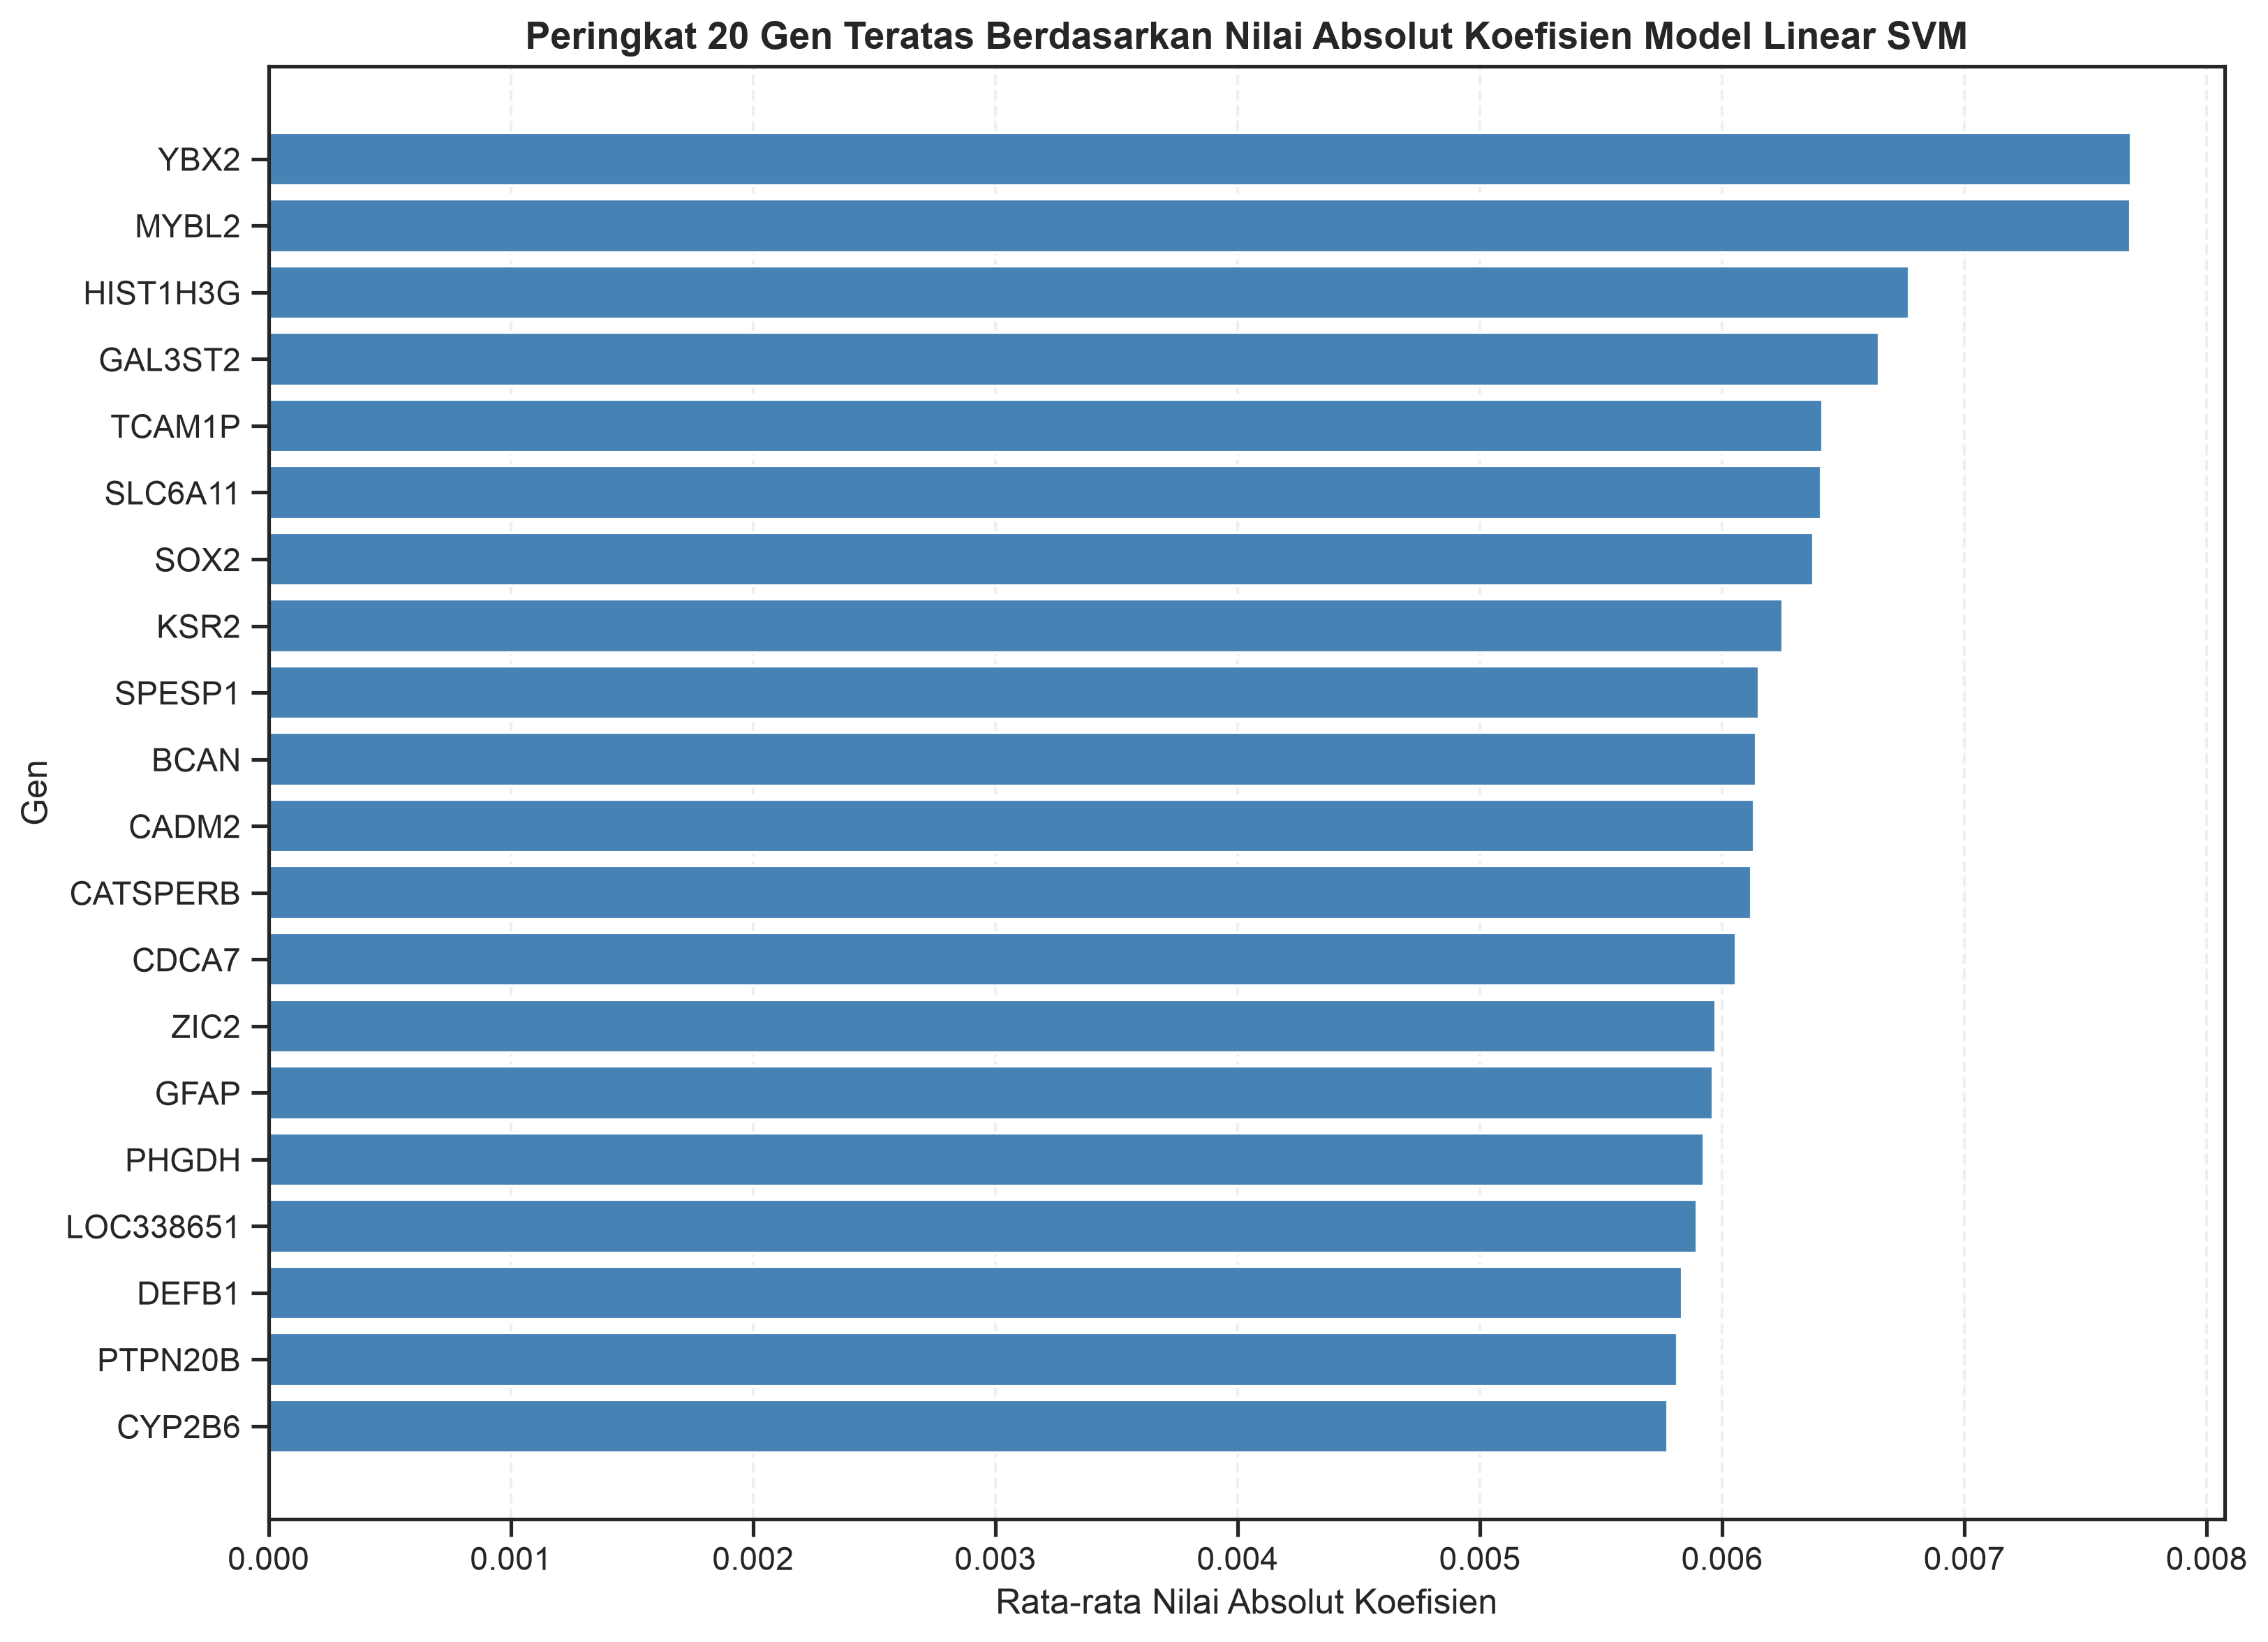

,Peringkat,Gen,Nilai Absolut Koefisien
0,1,YBX2,0.007689
1,2,MYBL2,0.007684
2,3,HIST1H3G,0.006773
3,4,GAL3ST2,0.006647
4,5,TCAM1P,0.006413
5,6,SLC6A11,0.006409
6,7,SOX2,0.006377
7,8,KSR2,0.006250
8,9,SPESP1,0.006153
9,10,BCAN,0.006141


In [56]:
# ============================================================
# PERINGKAT 20 GEN TERATAS BERDASARKAN KOEFISIEN LINEAR SVM
# ============================================================

# Nama gen sesuai urutan fitur yang digunakan saat melatih SVM
svm_gene_names = svm_final_selector.get_feature_names_out(
    input_features=X_train.columns
)

svm_coef = np.asarray(final_svm_model.coef_)

if svm_coef.shape[1] != len(svm_gene_names):
    raise ValueError(
        "Jumlah koefisien SVM tidak sesuai dengan jumlah nama gen."
    )

# Rata-rata nilai absolut koefisien pada seluruh pasangan kelas
mean_abs_coef = np.mean(np.abs(svm_coef), axis=0)

gene_ranking = (
    pd.DataFrame({
        "Gen": svm_gene_names,
        "Nilai Absolut Koefisien": mean_abs_coef
    })
    .sort_values("Nilai Absolut Koefisien", ascending=False)
    .reset_index(drop=True)
)

gene_ranking.insert(0, "Peringkat", np.arange(1, len(gene_ranking) + 1))
top_20_genes = gene_ranking.head(20).sort_values(
    "Nilai Absolut Koefisien",
    ascending=True
)

# Tampilkan grafik
plt.figure(figsize=(11, 8), dpi=300)
bars = plt.barh(
    top_20_genes["Gen"],
    top_20_genes["Nilai Absolut Koefisien"],
    color="steelblue"
)

plt.title(
    "Peringkat 20 Gen Teratas Berdasarkan Nilai Absolut Koefisien Model Linear SVM",
    fontsize=13,
    fontweight="bold"
)
plt.xlabel("Rata-rata Nilai Absolut Koefisien")
plt.ylabel("Gen")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "results/figures/top_20_gen_linear_svm.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(gene_ranking.head(20))

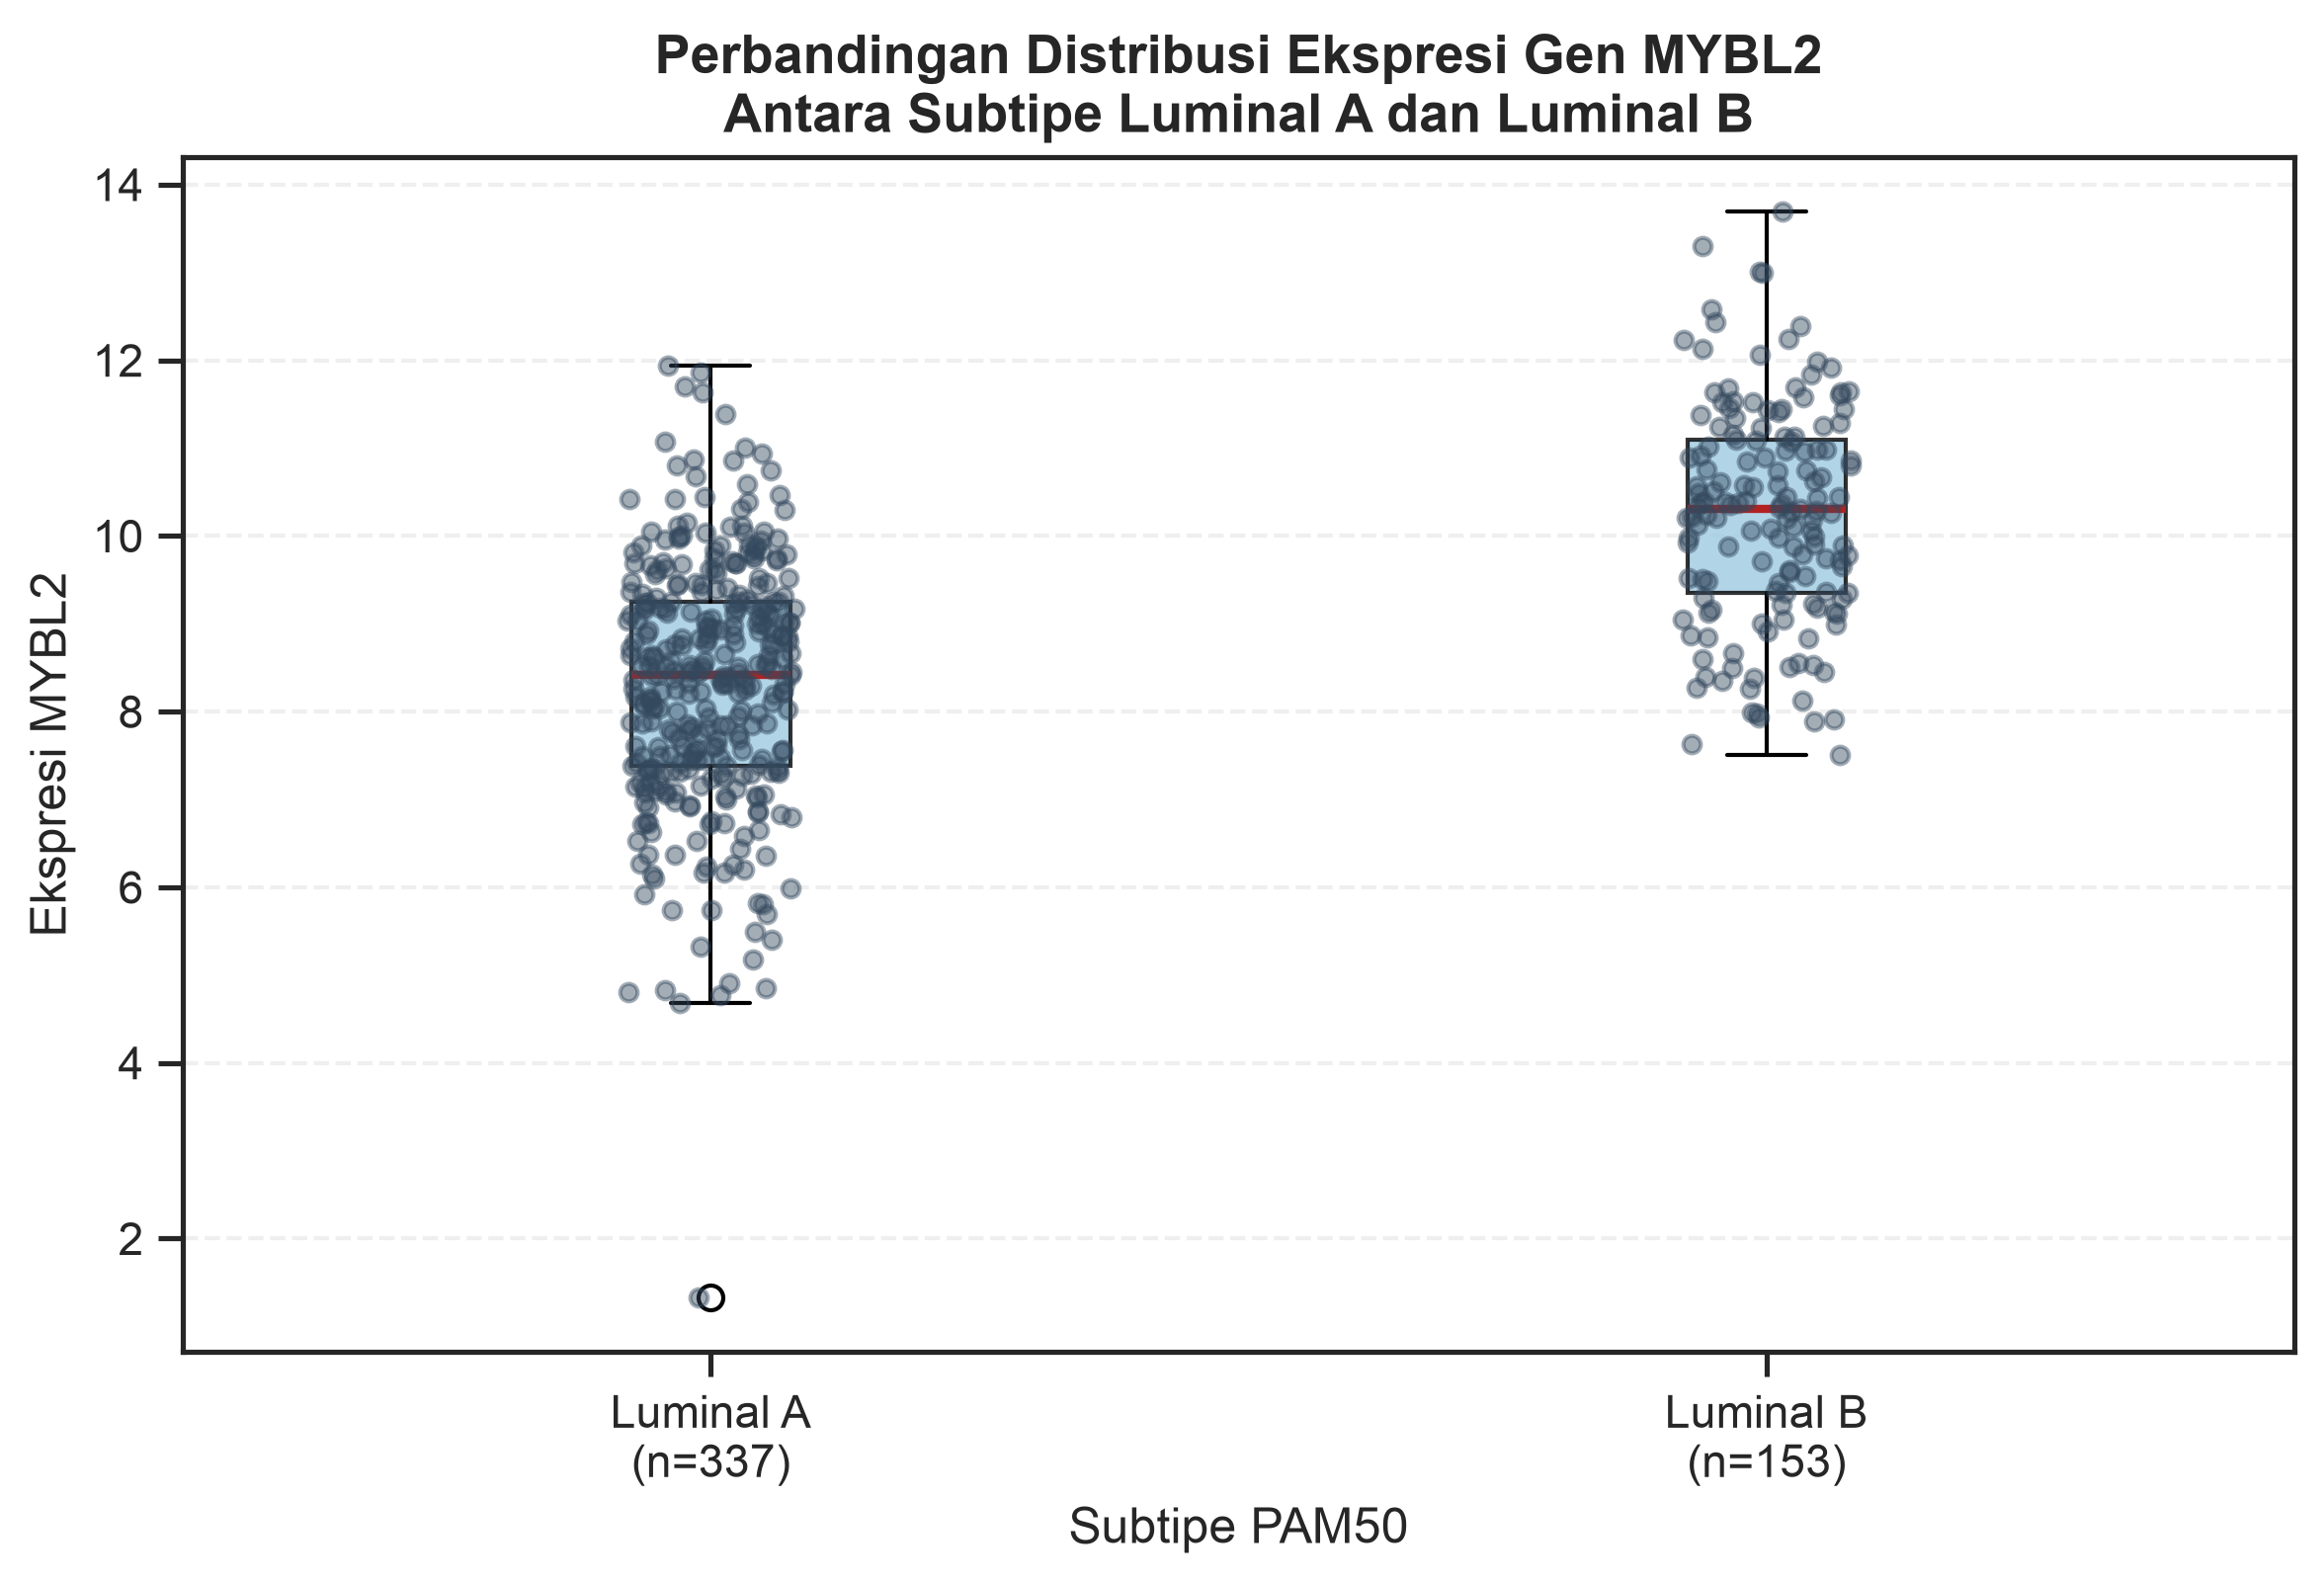

In [57]:
import numpy as np
import pandas as pd

# ============================================================
# DISTRIBUSI EKSPRESI MYBL2: LUMINAL A vs LUMINAL B
# ============================================================

import matplotlib.pyplot as plt

gene_name = "MYBL2"

# Pastikan gen tersedia pada data
if gene_name not in X_train.columns:
    raise KeyError(
        f"Gen {gene_name} tidak ditemukan pada X_train."
    )

# Selaraskan ekspresi dan label berdasarkan indeks sampel
plot_df = pd.DataFrame({
    "MYBL2": pd.to_numeric(X_train[gene_name], errors="coerce"),
    "Subtype": label_encoder.inverse_transform(
        np.asarray(y_train, dtype=int)
    )
}, index=X_train.index)

plot_df = plot_df[
    plot_df["Subtype"].isin(["LumA", "LumB"])
].dropna()

lum_a = plot_df.loc[plot_df["Subtype"] == "LumA", "MYBL2"].to_numpy()
lum_b = plot_df.loc[plot_df["Subtype"] == "LumB", "MYBL2"].to_numpy()

# Boxplot dan titik sampel
fig, ax = plt.subplots(figsize=(8, 5.5), dpi=300)

ax.boxplot(
    [lum_a, lum_b],
    tick_labels=[f"Luminal A\n(n={len(lum_a)})", f"Luminal B\n(n={len(lum_b)})"],
    patch_artist=True,
    boxprops={"facecolor": "#9ecae1", "alpha": 0.8},
    medianprops={"color": "#b22222", "linewidth": 2}
)

rng = np.random.default_rng(42)
for x_pos, values in enumerate([lum_a, lum_b], start=1):
    jitter = rng.uniform(-0.08, 0.08, size=len(values))
    ax.scatter(
        x_pos + jitter,
        values,
        color="#34495e",
        alpha=0.45,
        s=18,
        zorder=3
    )

ax.set_title(
    "Perbandingan Distribusi Ekspresi Gen MYBL2\n"
    "Antara Subtipe Luminal A dan Luminal B",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Subtipe PAM50")
ax.set_ylabel("Ekspresi MYBL2")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/figures/distribusi_ekspresi_MYBL2_LumA_LumB.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

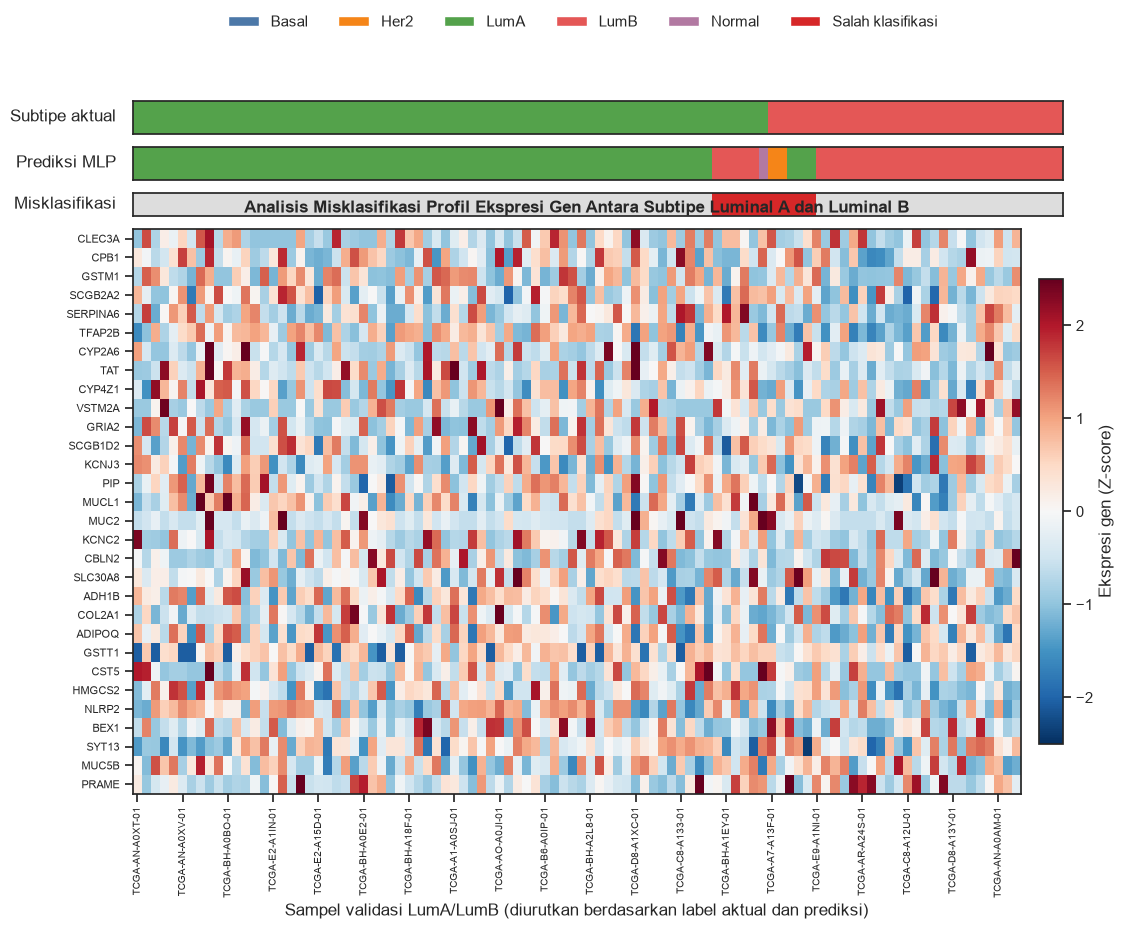

Sampel LumA/LumB yang ditampilkan: 98 (misklasifikasi: 11)


In [58]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ============================================================
# ANALISIS MISKLASIFIKASI PROFIL EKSPRESI GEN LumA vs LumB
# MLP — Data validasi
# ============================================================


# Pastikan variabel dari sel sebelumnya tersedia
required_variables = [
    "X_val_dl_selected",
    "y_val_dl",
    "y_val_pred_mlp",
    "label_encoder"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Jalankan sel preprocessing dan prediksi validasi terlebih dahulu: "
        + ", ".join(missing_variables)
    )

# Pastikan prediksi sejajar dengan sampel
if len(X_val_dl_selected) != len(y_val_pred_mlp):
    raise ValueError("Jumlah sampel dan prediksi tidak sama.")

luma_id, lumb_id = label_encoder.transform(["LumA", "LumB"])

plot_df = X_val_dl_selected.copy()
plot_df["Aktual"] = np.asarray(y_val_dl)
plot_df["Prediksi"] = np.asarray(y_val_pred_mlp)

# Tampilkan sampel dengan label aktual LumA/LumB
plot_df = plot_df[
    plot_df["Aktual"].isin([luma_id, lumb_id])
].copy()

# Urutkan menurut subtipe aktual, lalu prediksi
plot_df["_Urutan"] = (
    plot_df["Aktual"] * 10 + plot_df["Prediksi"]
)
plot_df = plot_df.sort_values("_Urutan")

if plot_df.empty:
    raise ValueError("Tidak ditemukan sampel aktual LumA atau LumB.")

# Pilih gen dengan variasi terbesar pada sampel yang ditampilkan
expression = plot_df.drop(
    columns=["Aktual", "Prediksi", "_Urutan"]
)

n_genes = min(30, expression.shape[1])
top_genes = expression.var(axis=0).nlargest(n_genes).index

# Z-score per gen agar pola ekspresi dapat dibandingkan
heatmap_data = expression[top_genes].T
row_std = heatmap_data.std(axis=1).replace(0, 1)
heatmap_z = heatmap_data.sub(
    heatmap_data.mean(axis=1), axis=0
).div(row_std, axis=0).fillna(0)

# Batasi skala warna agar nilai ekstrem tidak mendominasi
heatmap_z = heatmap_z.clip(-2.5, 2.5)

class_colors = {
    "Basal": "#4C78A8",
    "Her2": "#F58518",
    "LumA": "#54A24B",
    "LumB": "#E45756",
    "Normal": "#B279A2"
}
class_names = list(label_encoder.classes_)
class_cmap = ListedColormap(
    [class_colors.get(name, "#999999") for name in class_names]
)

actual_ids = plot_df["Aktual"].to_numpy(dtype=int)
predicted_ids = plot_df["Prediksi"].to_numpy(dtype=int)
errors = (actual_ids != predicted_ids).astype(int)

fig = plt.figure(figsize=(max(12, len(plot_df) * 0.11), 9))
grid = fig.add_gridspec(
    4, 1,
    height_ratios=[0.35, 0.35, 0.25, 6],
    hspace=0.08
)

annotation_data = [
    (actual_ids, "Subtipe aktual", class_cmap, len(class_names)),
    (predicted_ids, "Prediksi MLP", class_cmap, len(class_names)),
    (errors, "Misklasifikasi", ListedColormap(["#DDDDDD", "#D62728"]), 2)
]

for row, (values, label, cmap, n_colors) in enumerate(annotation_data):
    ax = fig.add_subplot(grid[row])
    ax.imshow(
        values.reshape(1, -1),
        aspect="auto",
        cmap=cmap,
        vmin=-0.5,
        vmax=n_colors - 0.5,
        interpolation="nearest"
    )
    ax.set_ylabel(label, rotation=0, ha="right", va="center", labelpad=12)
    ax.set_xticks([])
    ax.set_yticks([])

ax_heat = fig.add_subplot(grid[3])
image = ax_heat.imshow(
    heatmap_z.to_numpy(),
    aspect="auto",
    interpolation="nearest",
    cmap="RdBu_r",
    vmin=-2.5,
    vmax=2.5
)

ax_heat.set_yticks(np.arange(len(top_genes)))
ax_heat.set_yticklabels(top_genes, fontsize=8)
ax_heat.set_xlabel("Sampel validasi LumA/LumB (diurutkan berdasarkan label aktual dan prediksi)")
ax_heat.set_title(
    "Analisis Misklasifikasi Profil Ekspresi Gen Antara Subtipe Luminal A dan Luminal B",
    fontweight="bold",
    pad=12
)

# Tampilkan sebagian ID sampel agar label tidak bertumpuk
sample_ids = plot_df.index.astype(str).to_numpy()
tick_step = max(1, len(sample_ids) // 18)
tick_positions = np.arange(0, len(sample_ids), tick_step)
ax_heat.set_xticks(tick_positions)
ax_heat.set_xticklabels(
    sample_ids[tick_positions],
    rotation=90,
    fontsize=7
)

colorbar = fig.colorbar(image, ax=ax_heat, fraction=0.025, pad=0.02)
colorbar.set_label("Ekspresi gen (Z-score)")

legend_items = [
    Patch(facecolor=class_colors.get(name, "#999999"), label=name)
    for name in class_names
]
legend_items.append(Patch(facecolor="#D62728", label="Salah klasifikasi"))

fig.legend(
    handles=legend_items,
    loc="upper center",
    ncol=len(legend_items),
    bbox_to_anchor=(0.5, 0.99),
    frameon=False
)

plt.tight_layout(rect=[0.08, 0.02, 0.98, 0.94])
plt.savefig(
    "results/figures/analisis_misklasifikasi_profil_ekspresi_LumA_LumB.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(
    f"Sampel LumA/LumB yang ditampilkan: {len(plot_df)} "
    f"(misklasifikasi: {errors.sum()})"
)

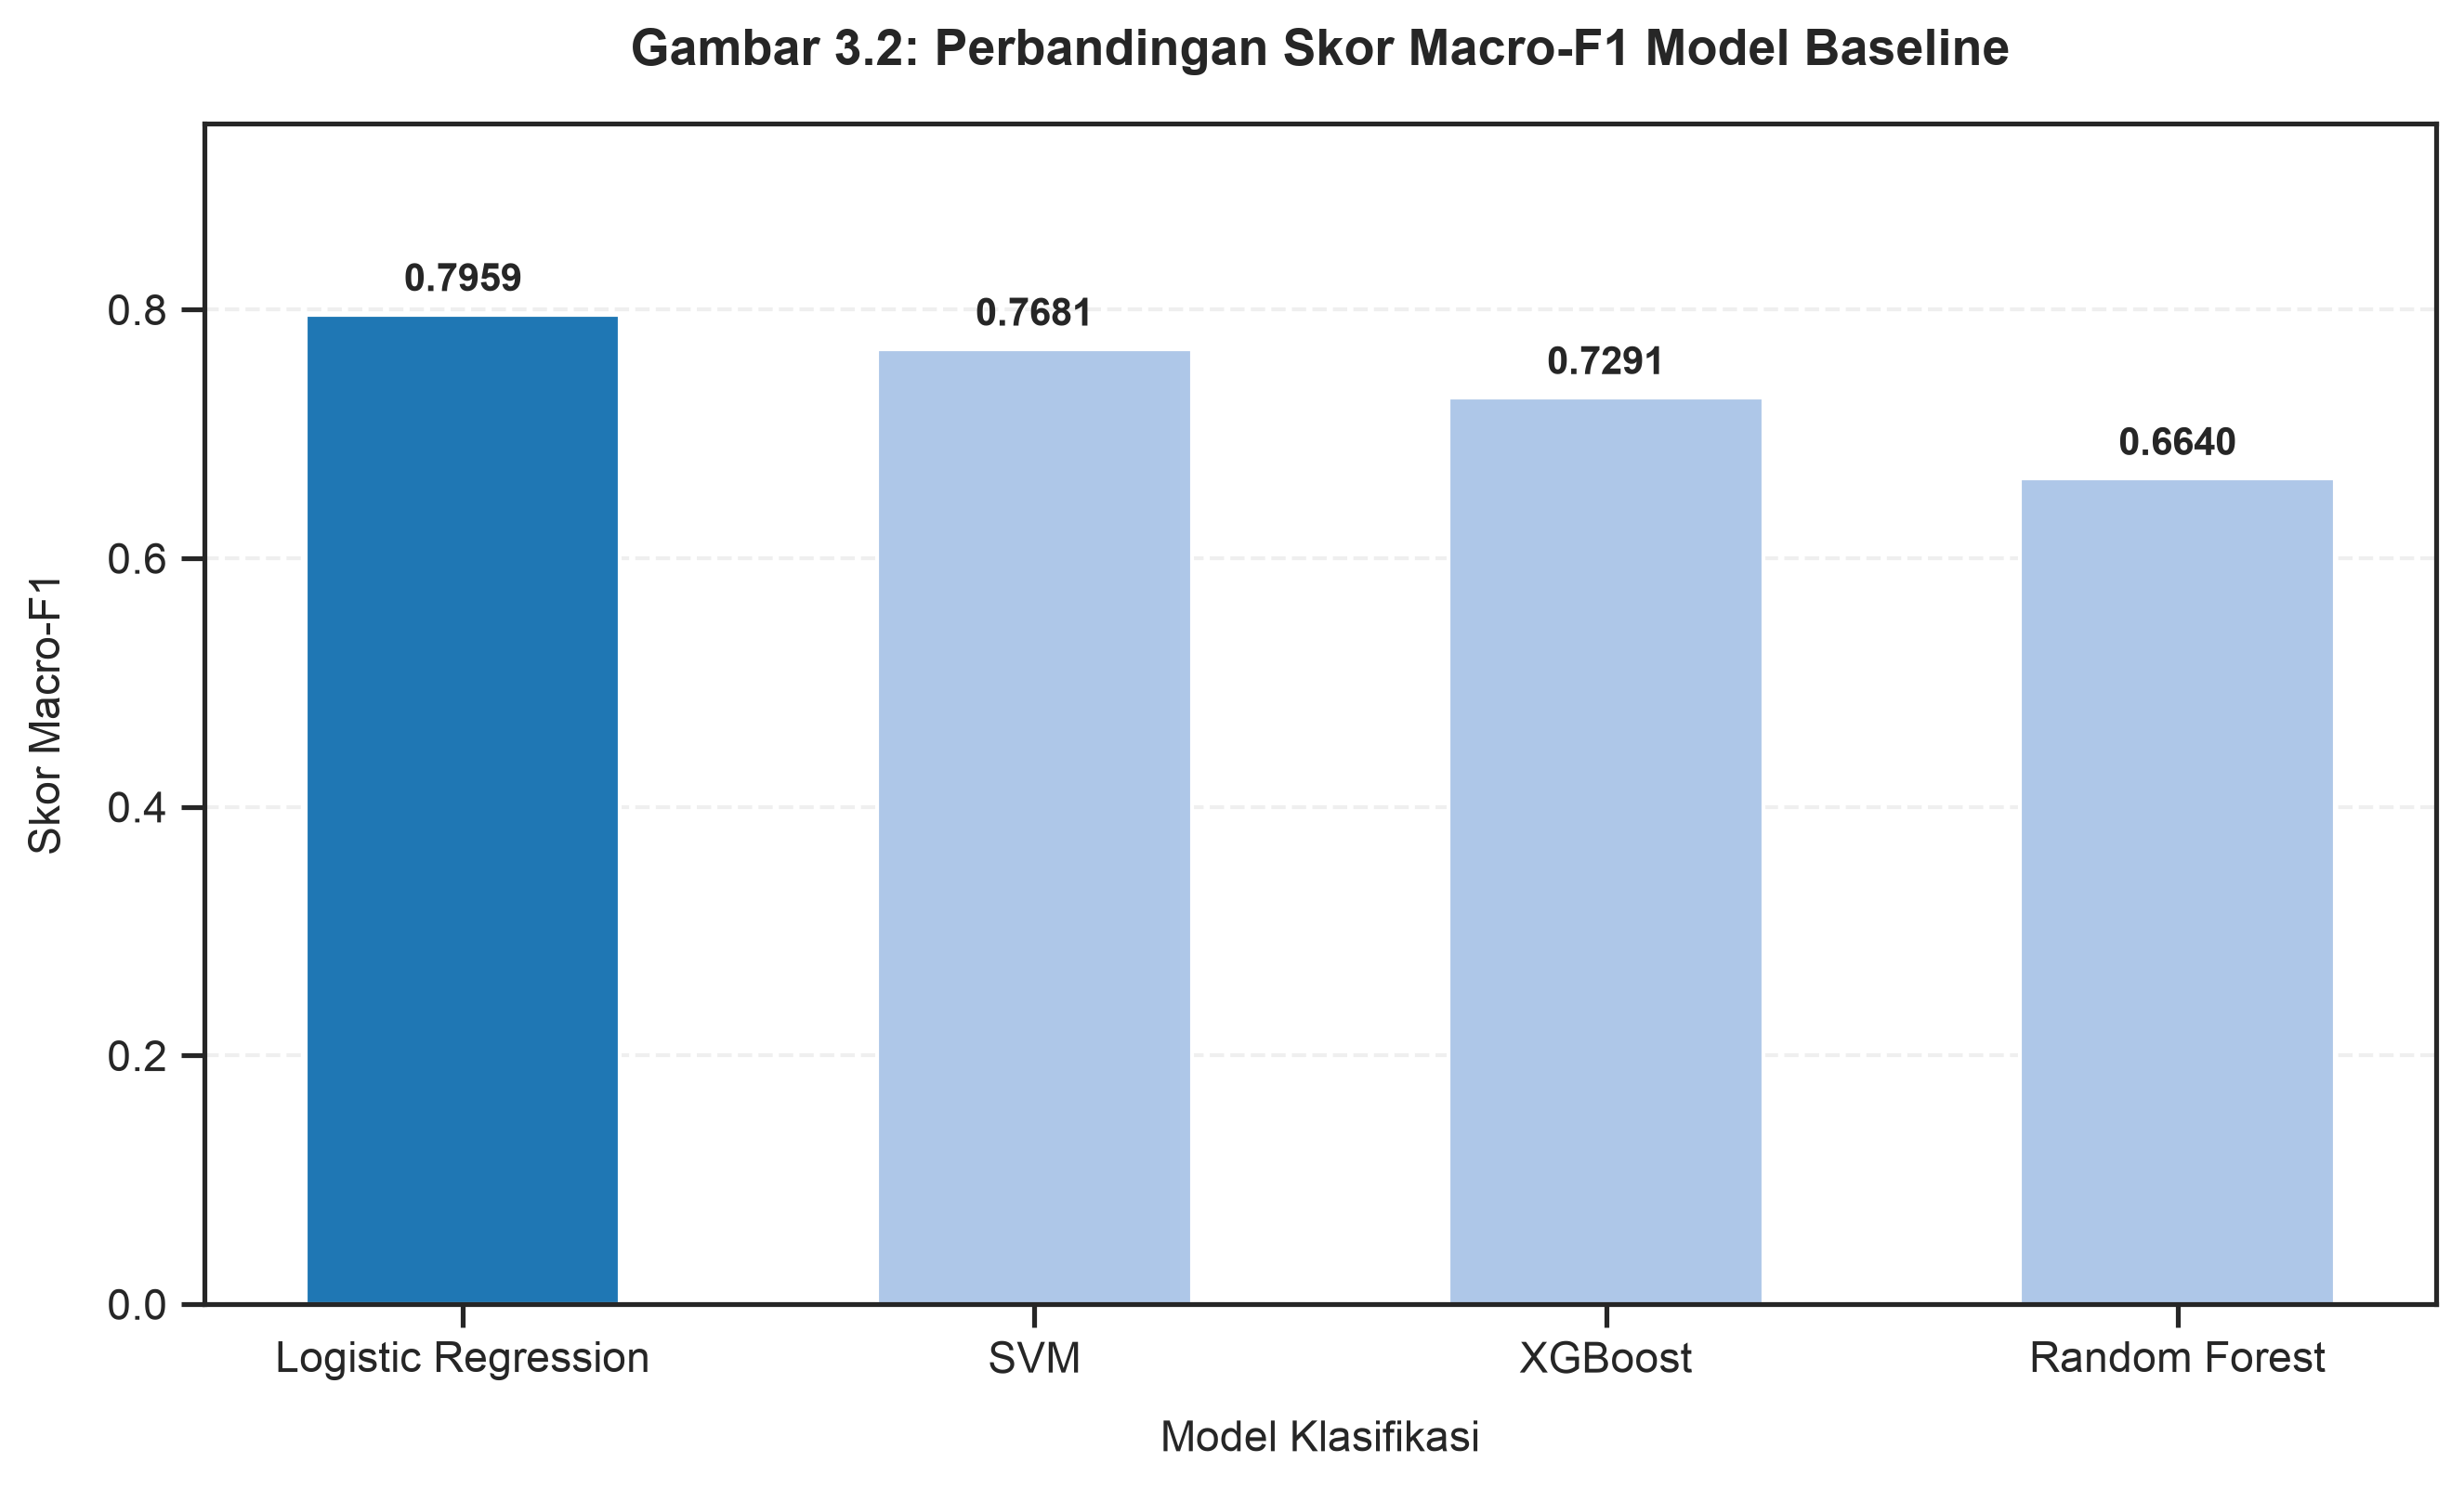

In [48]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Menyiapkan data berdasarkan hasil evaluasi model baseline
data_baseline = {
    'Model': ['Logistic Regression', 'SVM', 'XGBoost', 'Random Forest'],
    'Macro-F1': [0.7959, 0.7681, 0.7291, 0.6640]
}

df_baseline = pd.DataFrame(data_baseline)

# 2. Pengaturan ukuran visualisasi
plt.figure(figsize=(9, 5.5), dpi=300)

# 3. Membuat diagram batang (bar chart)
bars = plt.bar(
    df_baseline['Model'], 
    df_baseline['Macro-F1'], 
    color=['#1f77b4', '#aec7e8', '#aec7e8', '#aec7e8'], # Menonjolkan model terbaik
    width=0.55
)

# 4. Menambahkan nilai numerik di atas setiap batang
for bar in bars:
    height = bar.get_height()
    plt.annotate(
        f'{height:.4f}',
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 4),  # offset 4 points ke atas
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

# 5. Judul dan label sumbu sesuai format naskah skripsi
plt.title('Gambar 3.2: Perbandingan Skor Macro-F1 Model Baseline', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Model Klasifikasi', fontsize=11, labelpad=10)
plt.ylabel('Skor Macro-F1', fontsize=11, labelpad=10)

# Pengaturan batas sumbu Y dan grid
plt.ylim(0, 0.95)
plt.grid(axis='y', linestyle='--', alpha=0.3)

# 6. Merapikan tata letak dan menampilkan grafik
plt.tight_layout()
plt.show()

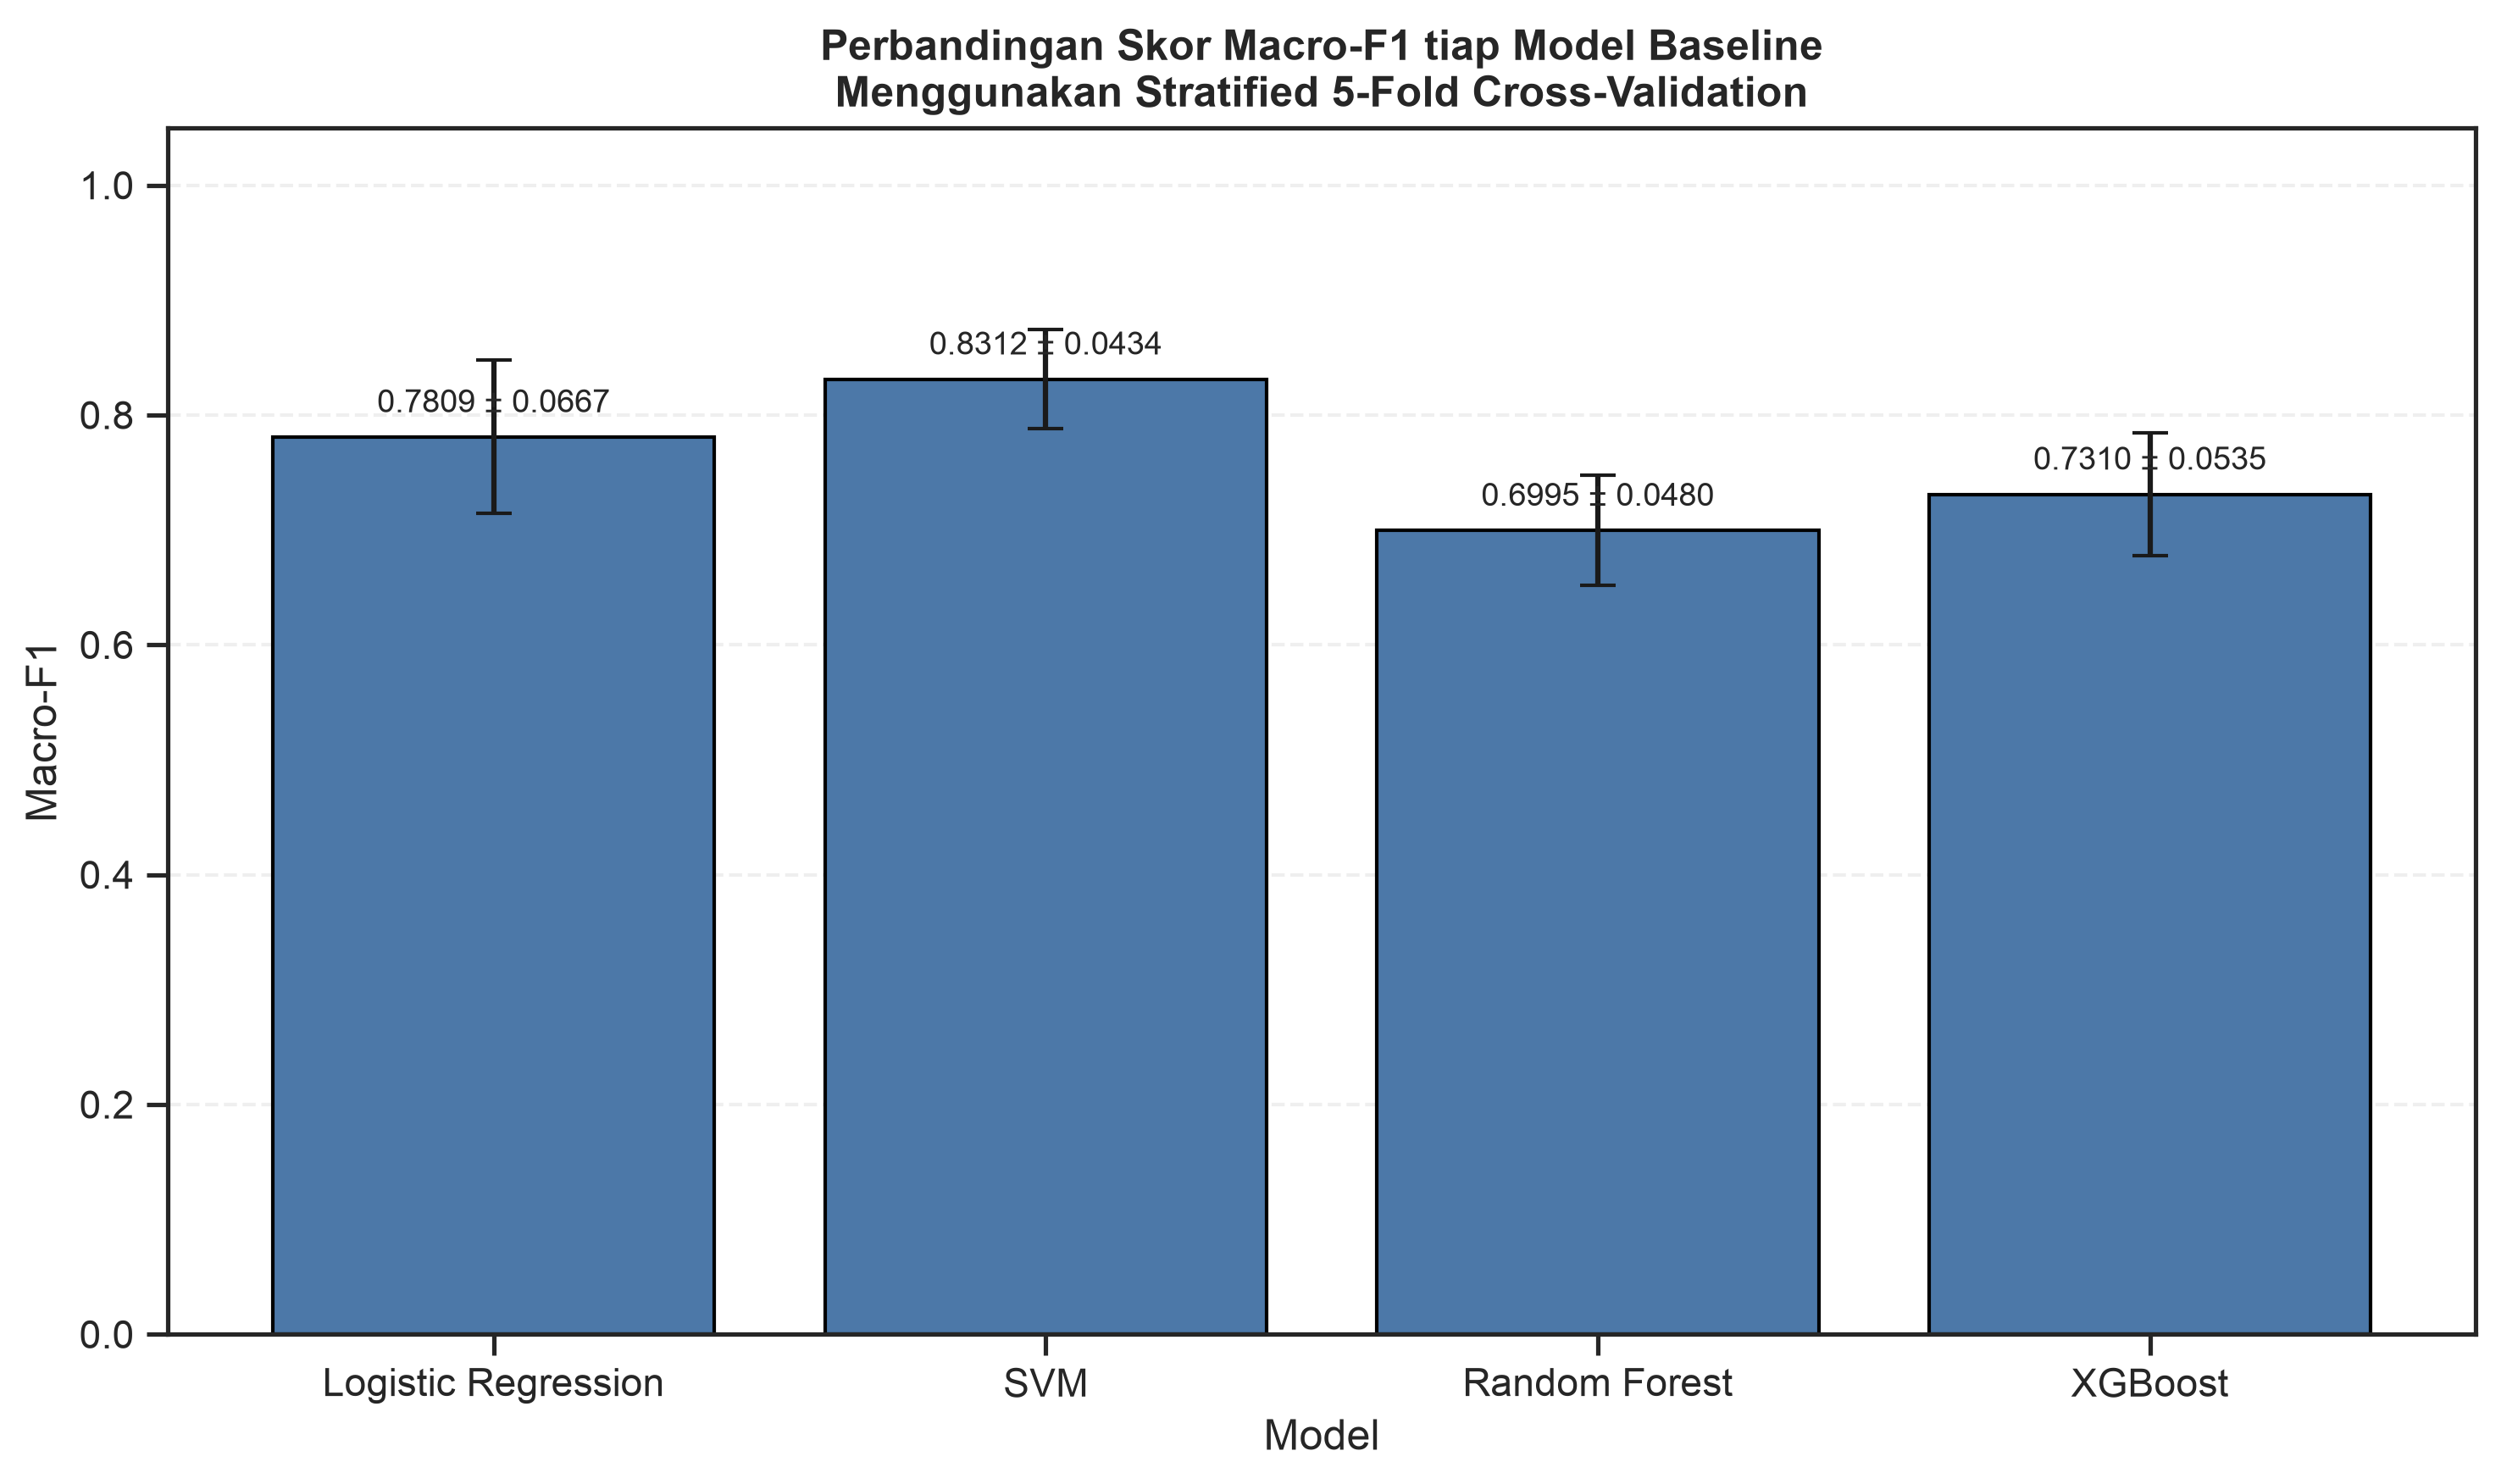

In [59]:
# ============================================================
# PERBANDINGAN MACRO-F1 MODEL BASELINE
# Stratified 5-Fold Cross-Validation
# ============================================================

if "baseline_cv_df" not in globals():
    raise RuntimeError(
        "baseline_cv_df belum tersedia. Jalankan sel evaluasi "
        "Stratified 5-Fold Cross-Validation terlebih dahulu."
    )

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

bars = ax.bar(
    baseline_cv_df["Model"],
    baseline_cv_df["Mean Macro-F1"],
    yerr=baseline_cv_df["Std Macro-F1"],
    capsize=5,
    color="#4C78A8",
    edgecolor="black"
)

for bar, mean_score, std_score in zip(
    bars,
    baseline_cv_df["Mean Macro-F1"],
    baseline_cv_df["Std Macro-F1"]
):
    ax.annotate(
        f"{mean_score:.4f} ± {std_score:.4f}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title(
    "Perbandingan Skor Macro-F1 tiap Model Baseline\n"
    "Menggunakan Stratified 5-Fold Cross-Validation",
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/figures/baseline_stratified_5fold_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

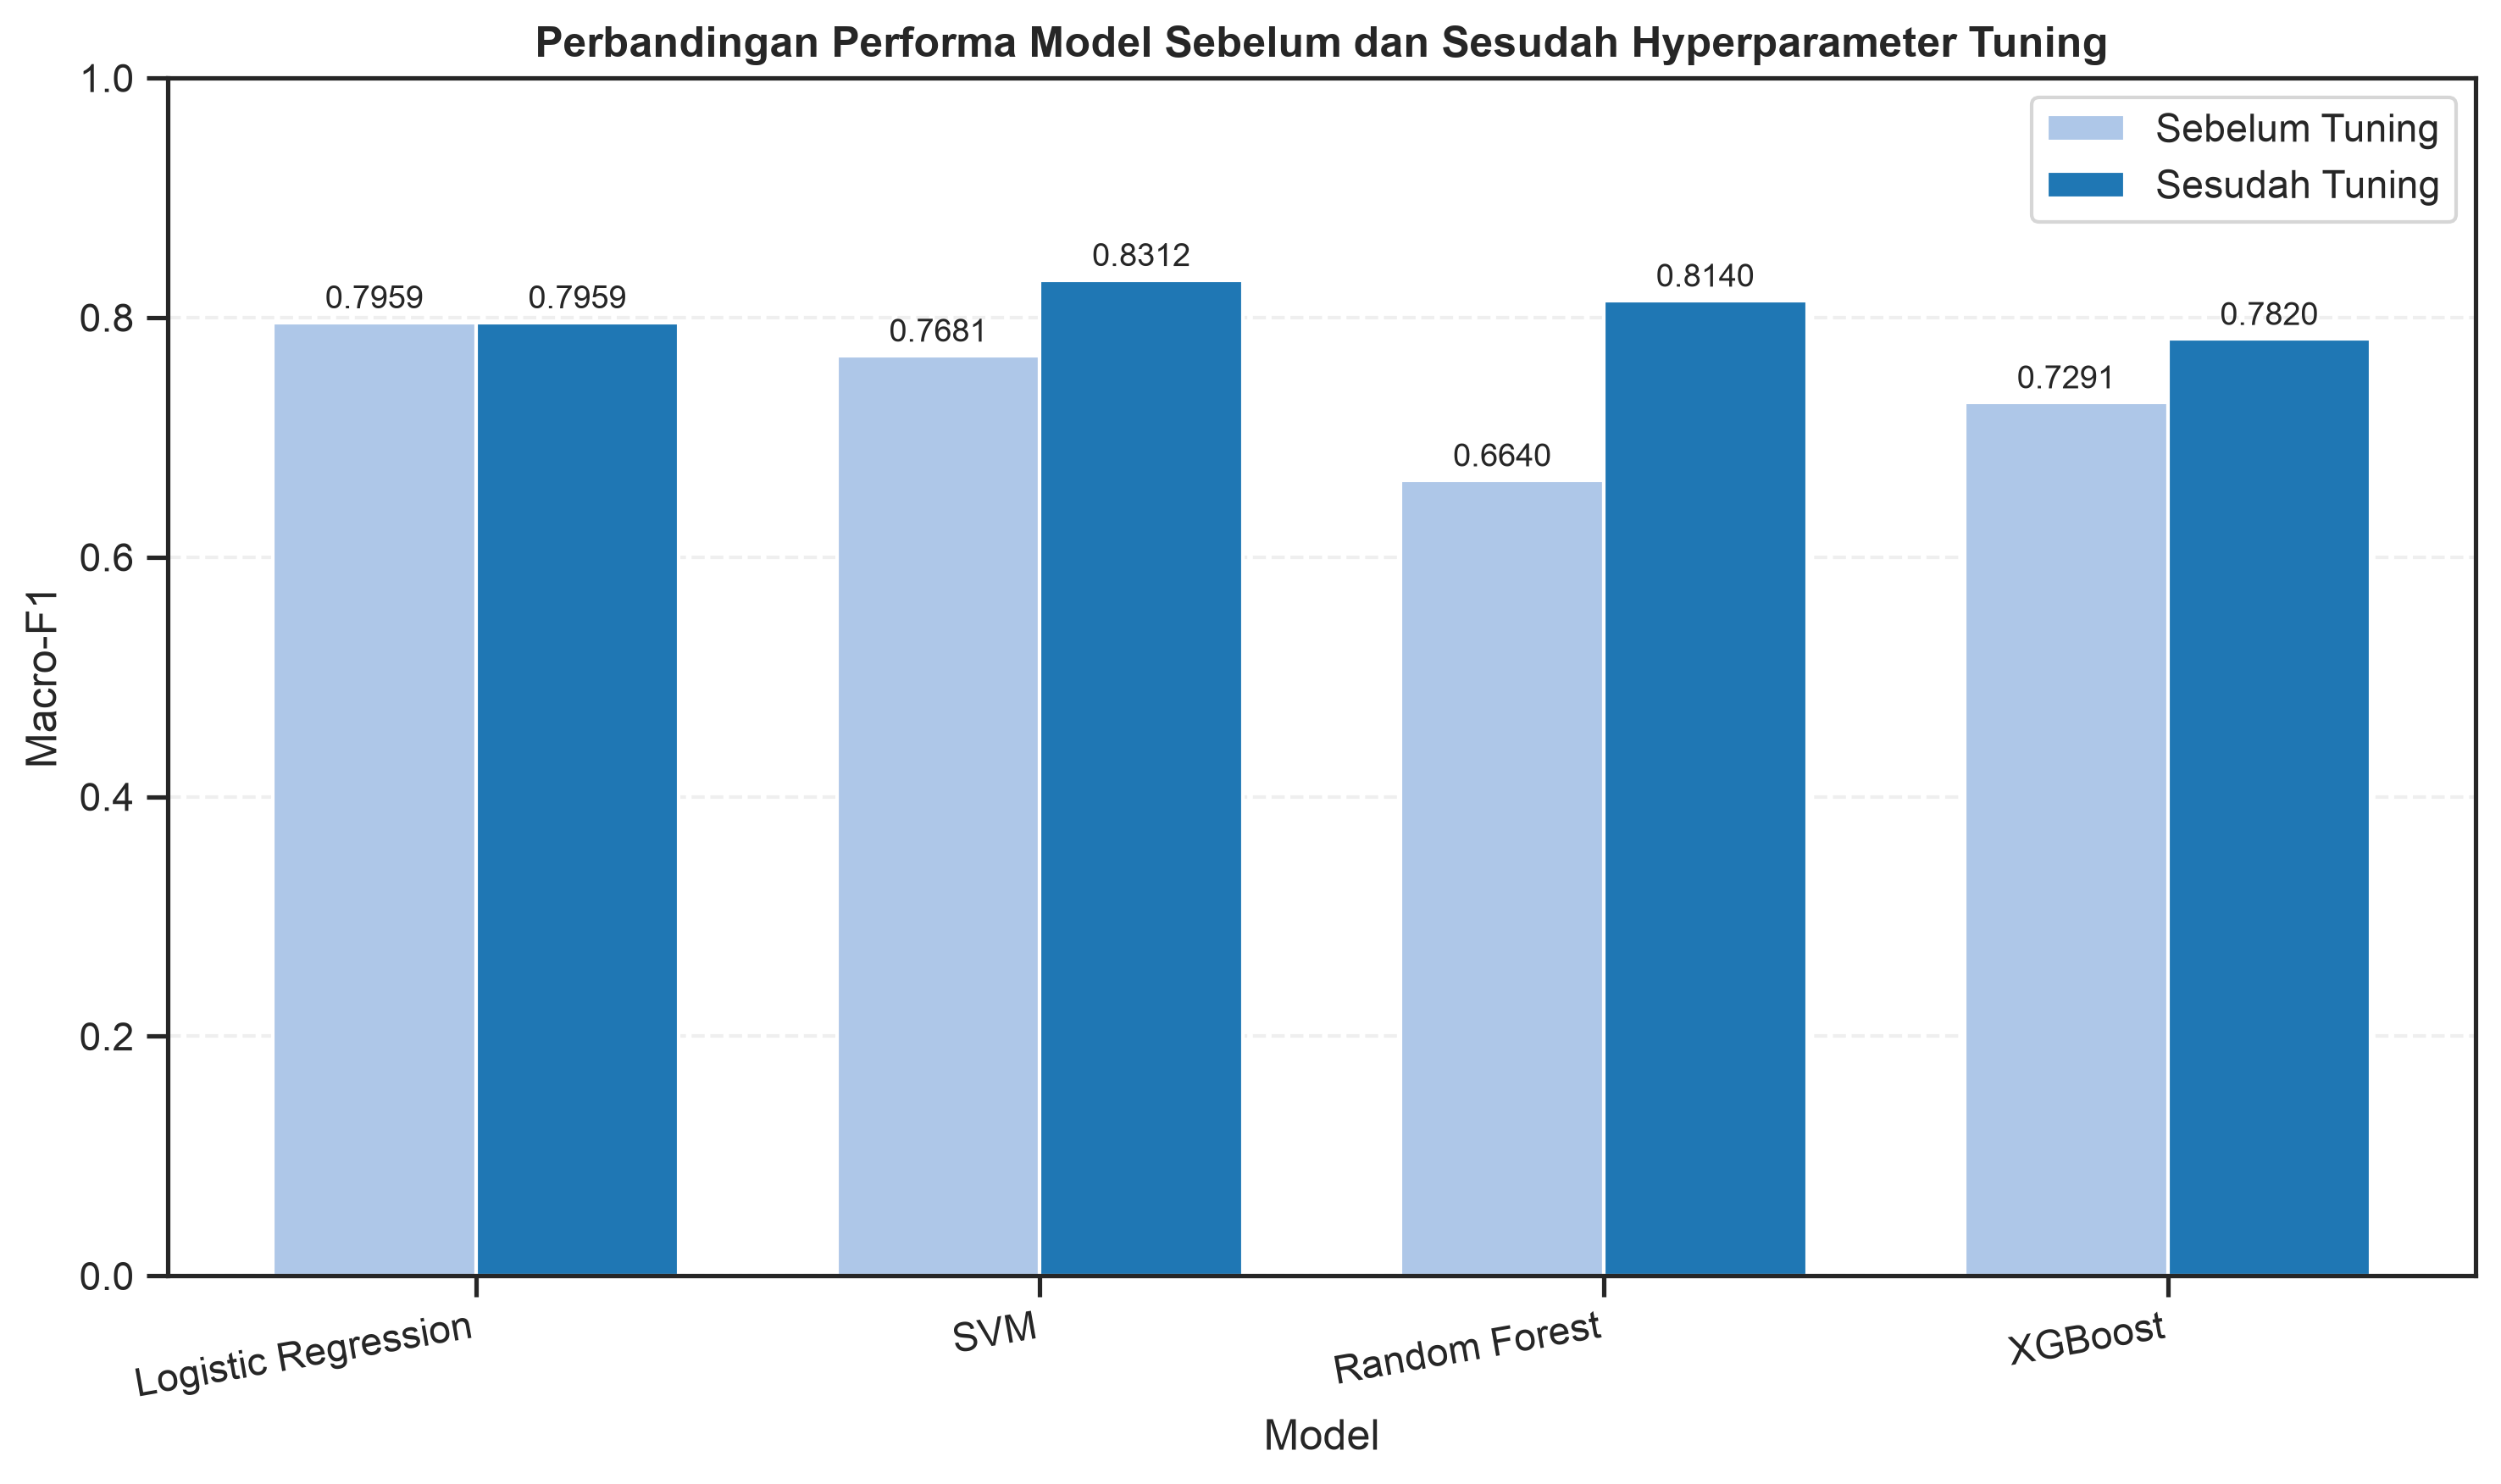

In [60]:
# ============================================================
# PERBANDINGAN PERFORMA SEBELUM DAN SESUDAH TUNING
# ============================================================

tuning_plot_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "Random Forest",
        "XGBoost"
    ],
    "Sebelum Tuning": [0.7959, 0.7681, 0.6640, 0.7291],
    "Sesudah Tuning": [0.7959, 0.8312, 0.8140, 0.7820]
})

x = np.arange(len(tuning_plot_df))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

bars_before = ax.bar(
    x - bar_width / 2,
    tuning_plot_df["Sebelum Tuning"],
    bar_width,
    label="Sebelum Tuning",
    color="#aec7e8"
)

bars_after = ax.bar(
    x + bar_width / 2,
    tuning_plot_df["Sesudah Tuning"],
    bar_width,
    label="Sesudah Tuning",
    color="#1f77b4"
)

for bars in (bars_before, bars_after):
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.4f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

ax.set_title(
    "Perbandingan Performa Model Sebelum dan Sesudah Hyperparameter Tuning",
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_xticks(x)
ax.set_xticklabels(tuning_plot_df["Model"], rotation=10, ha="right")
ax.set_ylim(0, 1.0)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    "results/figures/perbandingan_performa_sebelum_sesudah_tuning.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

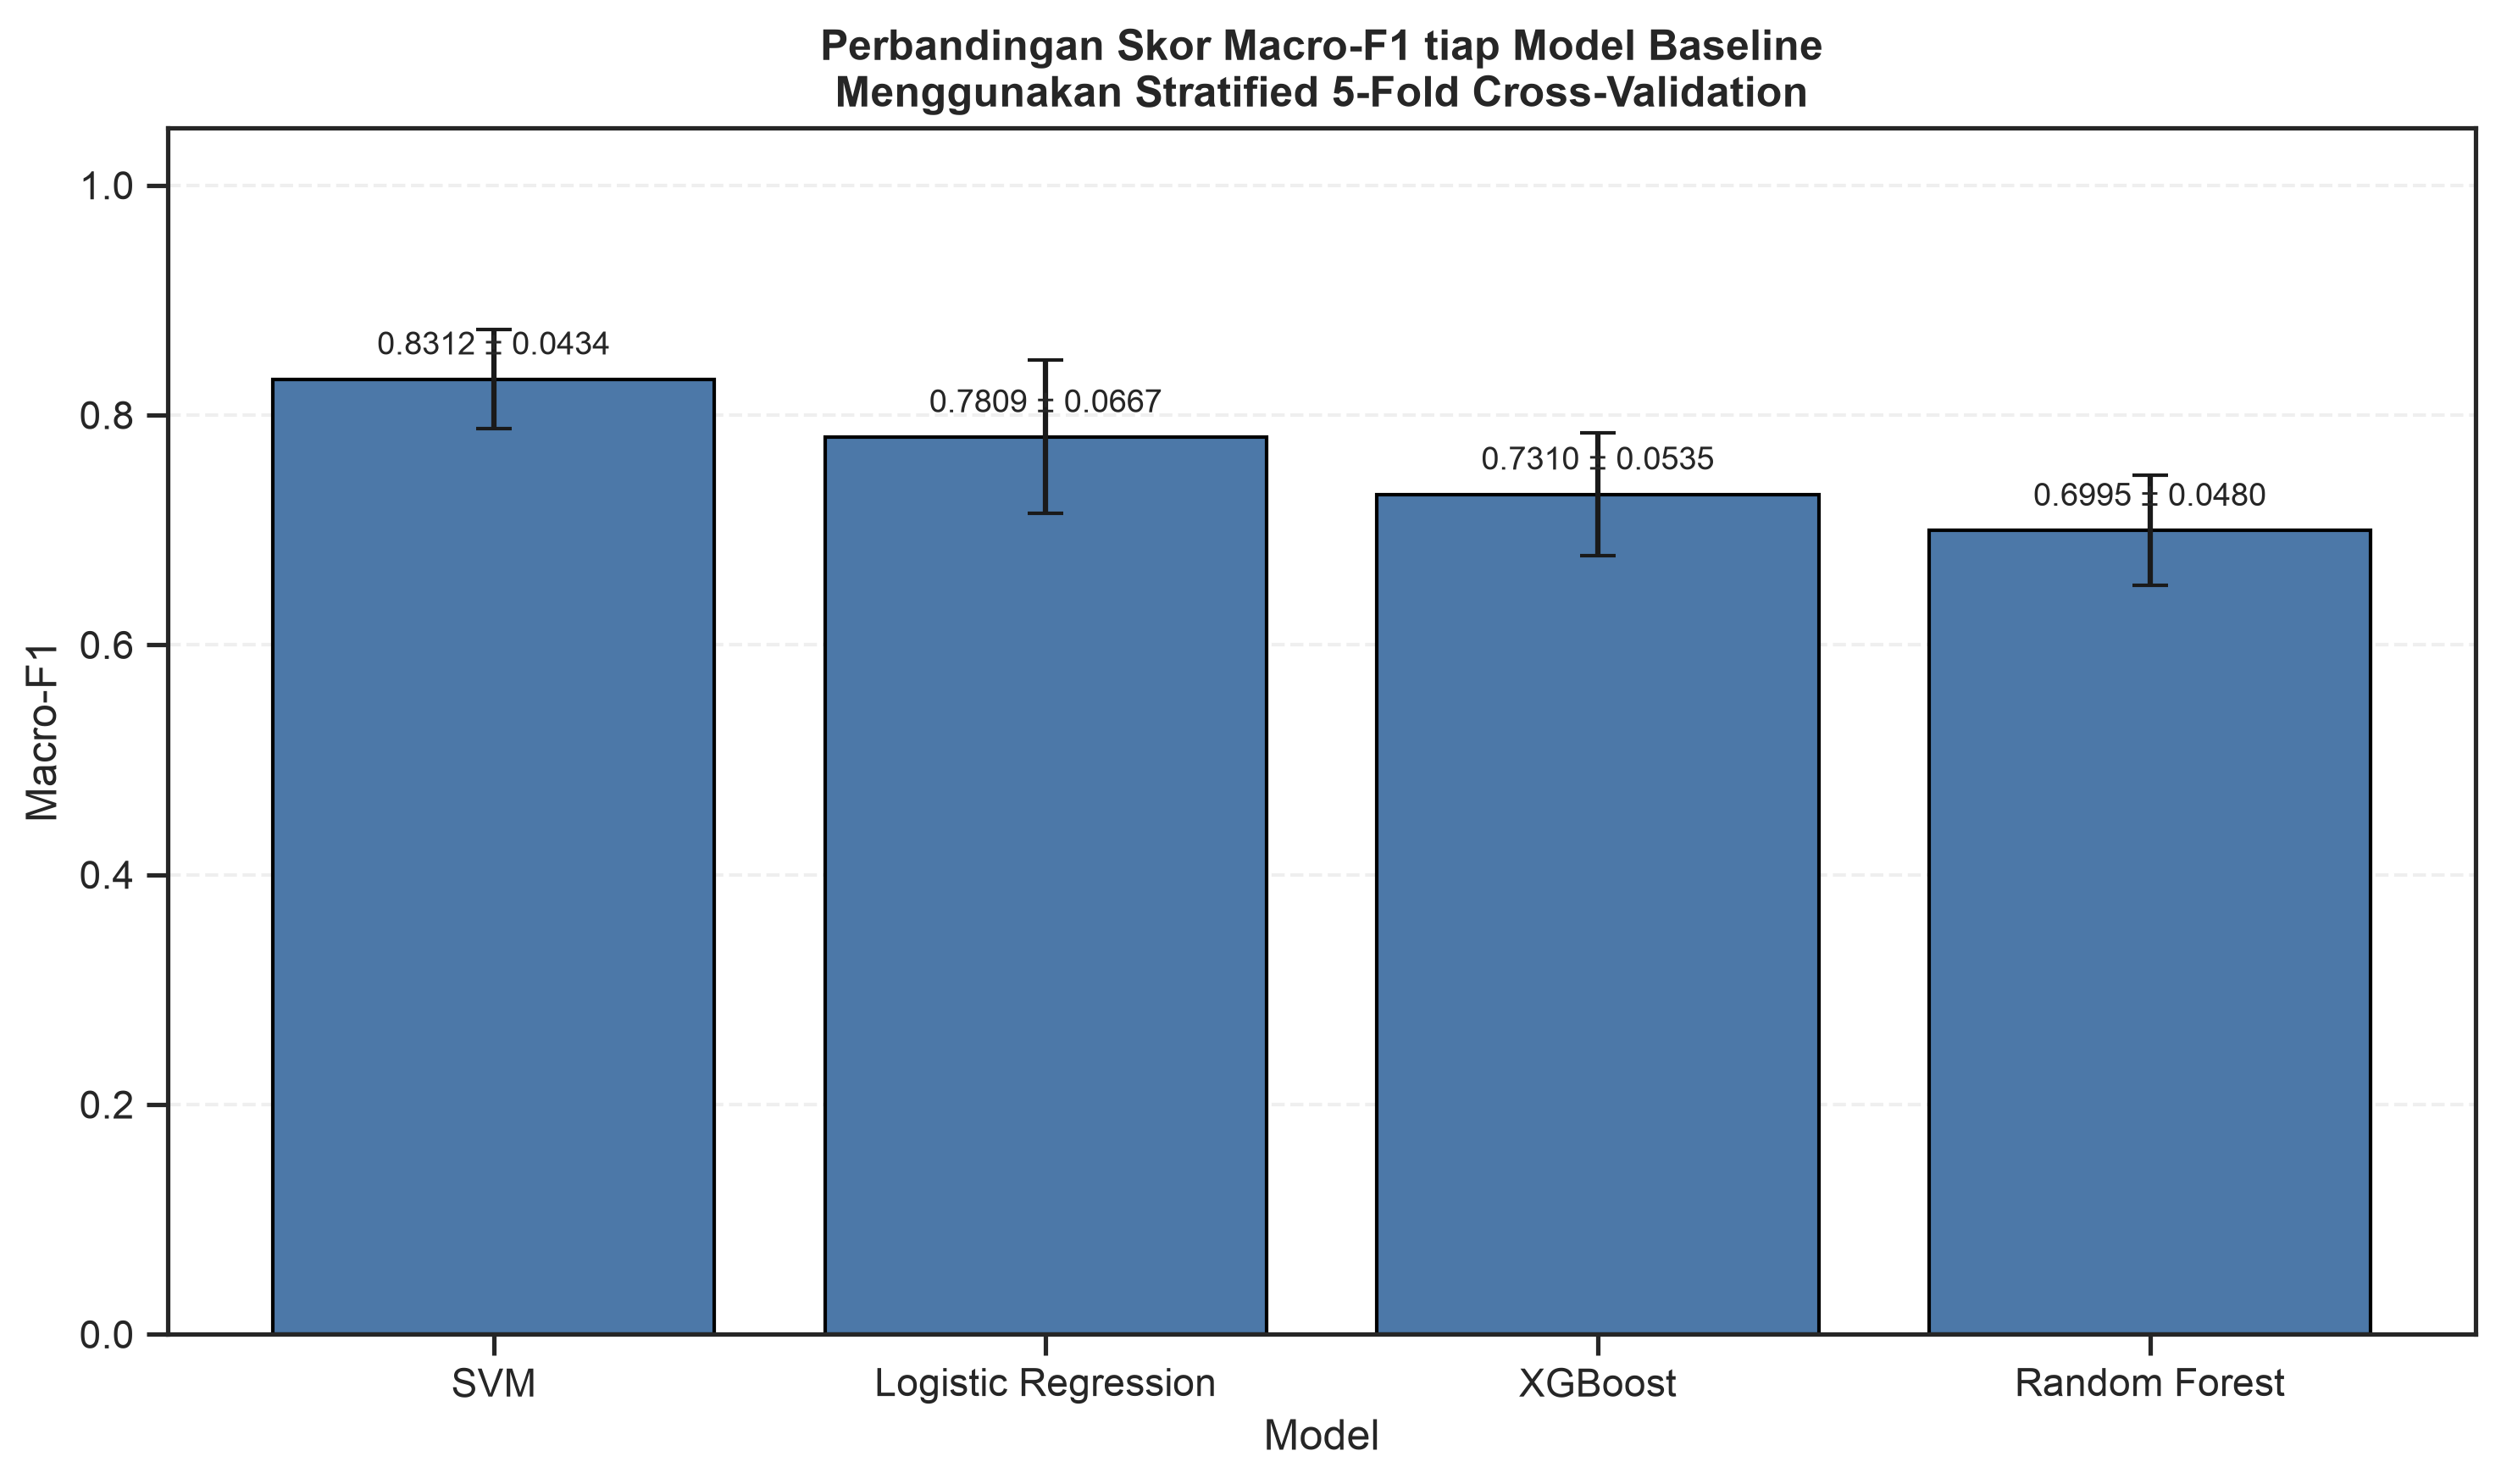

In [61]:
# ============================================================
# PERBANDINGAN MACRO-F1 MODEL BASELINE
# Stratified 5-Fold Cross-Validation
# ============================================================

if "baseline_cv_df" not in globals():
    raise RuntimeError(
        "baseline_cv_df belum tersedia. Jalankan sel evaluasi "
        "Stratified 5-Fold Cross-Validation terlebih dahulu."
    )

plot_df = baseline_cv_df.sort_values(
    "Mean Macro-F1",
    ascending=False
).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

bars = ax.bar(
    plot_df["Model"],
    plot_df["Mean Macro-F1"],
    yerr=plot_df["Std Macro-F1"],
    capsize=5,
    color="#4C78A8",
    edgecolor="black"
)

for bar, mean_score, std_score in zip(
    bars,
    plot_df["Mean Macro-F1"],
    plot_df["Std Macro-F1"]
):
    ax.annotate(
        f"{mean_score:.4f} ± {std_score:.4f}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title(
    "Perbandingan Skor Macro-F1 tiap Model Baseline\n"
    "Menggunakan Stratified 5-Fold Cross-Validation",
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/figures/baseline_stratified_5fold_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

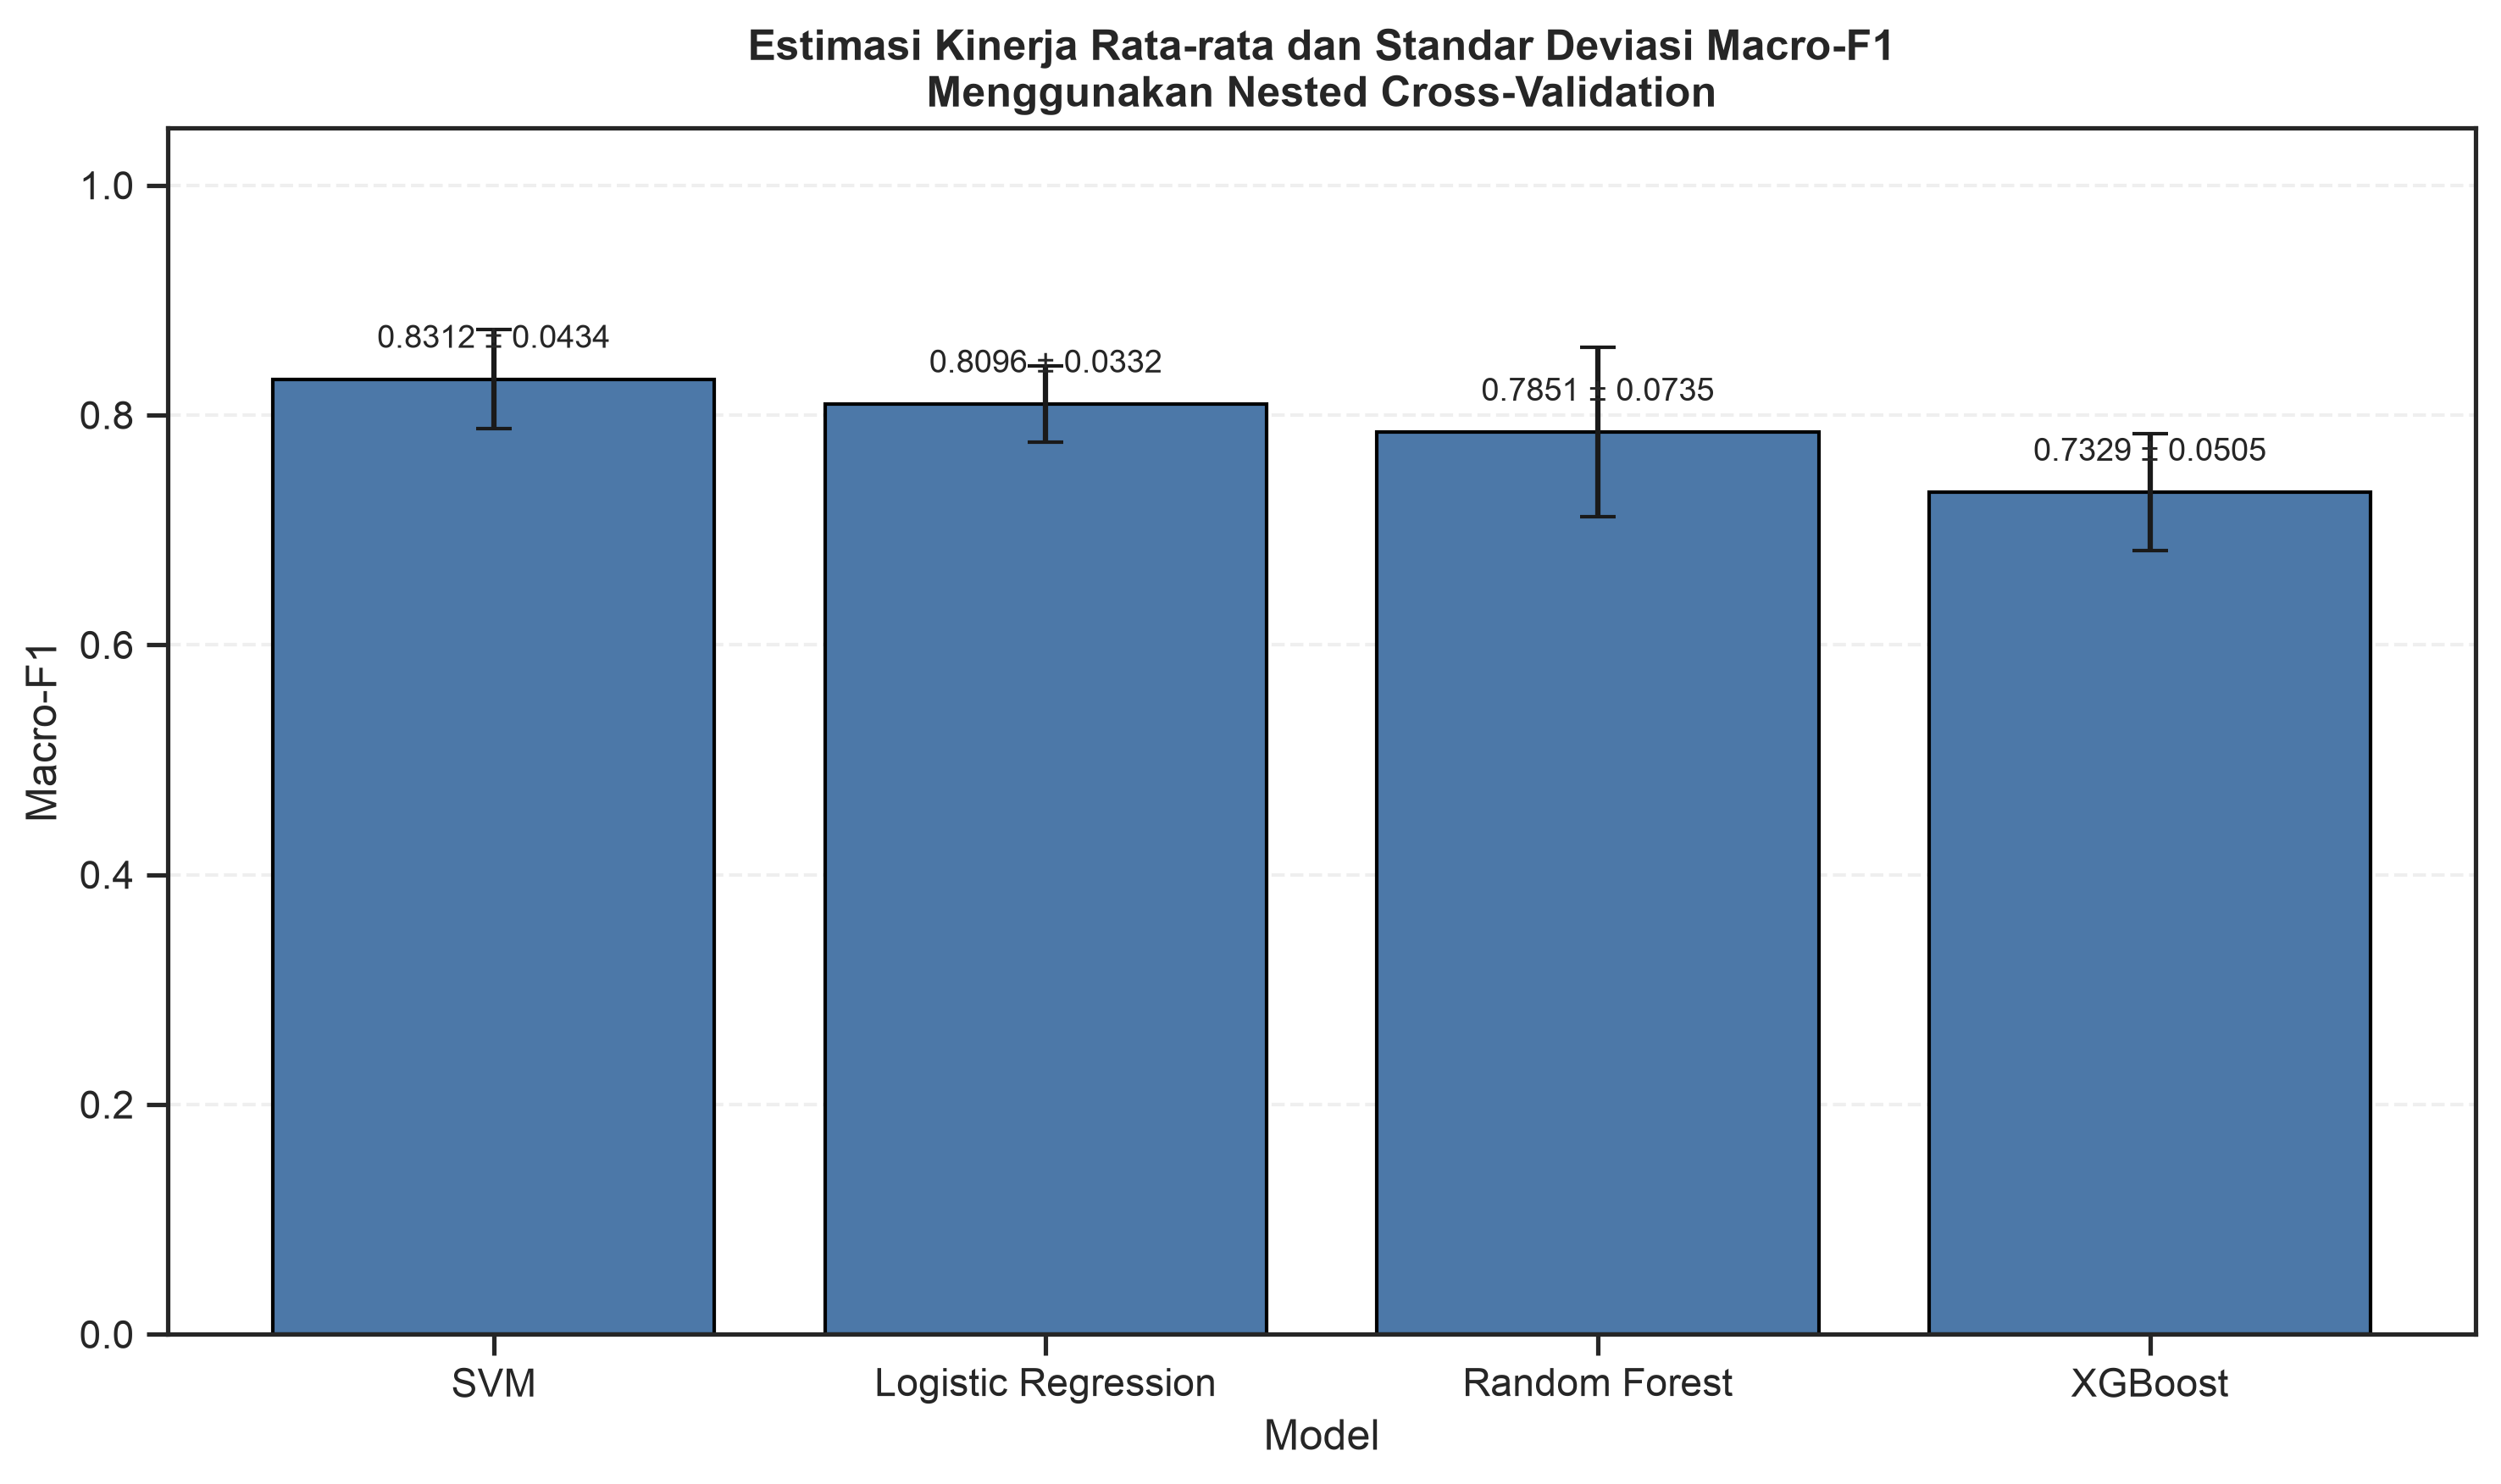

In [62]:
# ============================================================
# ESTIMASI RATA-RATA ± STANDAR DEVIASI MACRO-F1
# MENGGUNAKAN NESTED CROSS-VALIDATION
# ============================================================

plot_data = nested_cv_summary.sort_values(
    "Mean_Macro_F1",
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

bars = ax.bar(
    plot_data["Model"],
    plot_data["Mean_Macro_F1"],
    yerr=plot_data["Std_Macro_F1"],
    capsize=5,
    color="#4C78A8",
    edgecolor="black"
)

for bar, mean_score, std_score in zip(
    bars,
    plot_data["Mean_Macro_F1"],
    plot_data["Std_Macro_F1"]
):
    ax.annotate(
        f"{mean_score:.4f} ± {std_score:.4f}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Estimasi Kinerja Rata-rata dan Standar Deviasi Macro-F1\n"
    "Menggunakan Nested Cross-Validation",
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/figures/nested_cv_macro_f1_mean_std.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

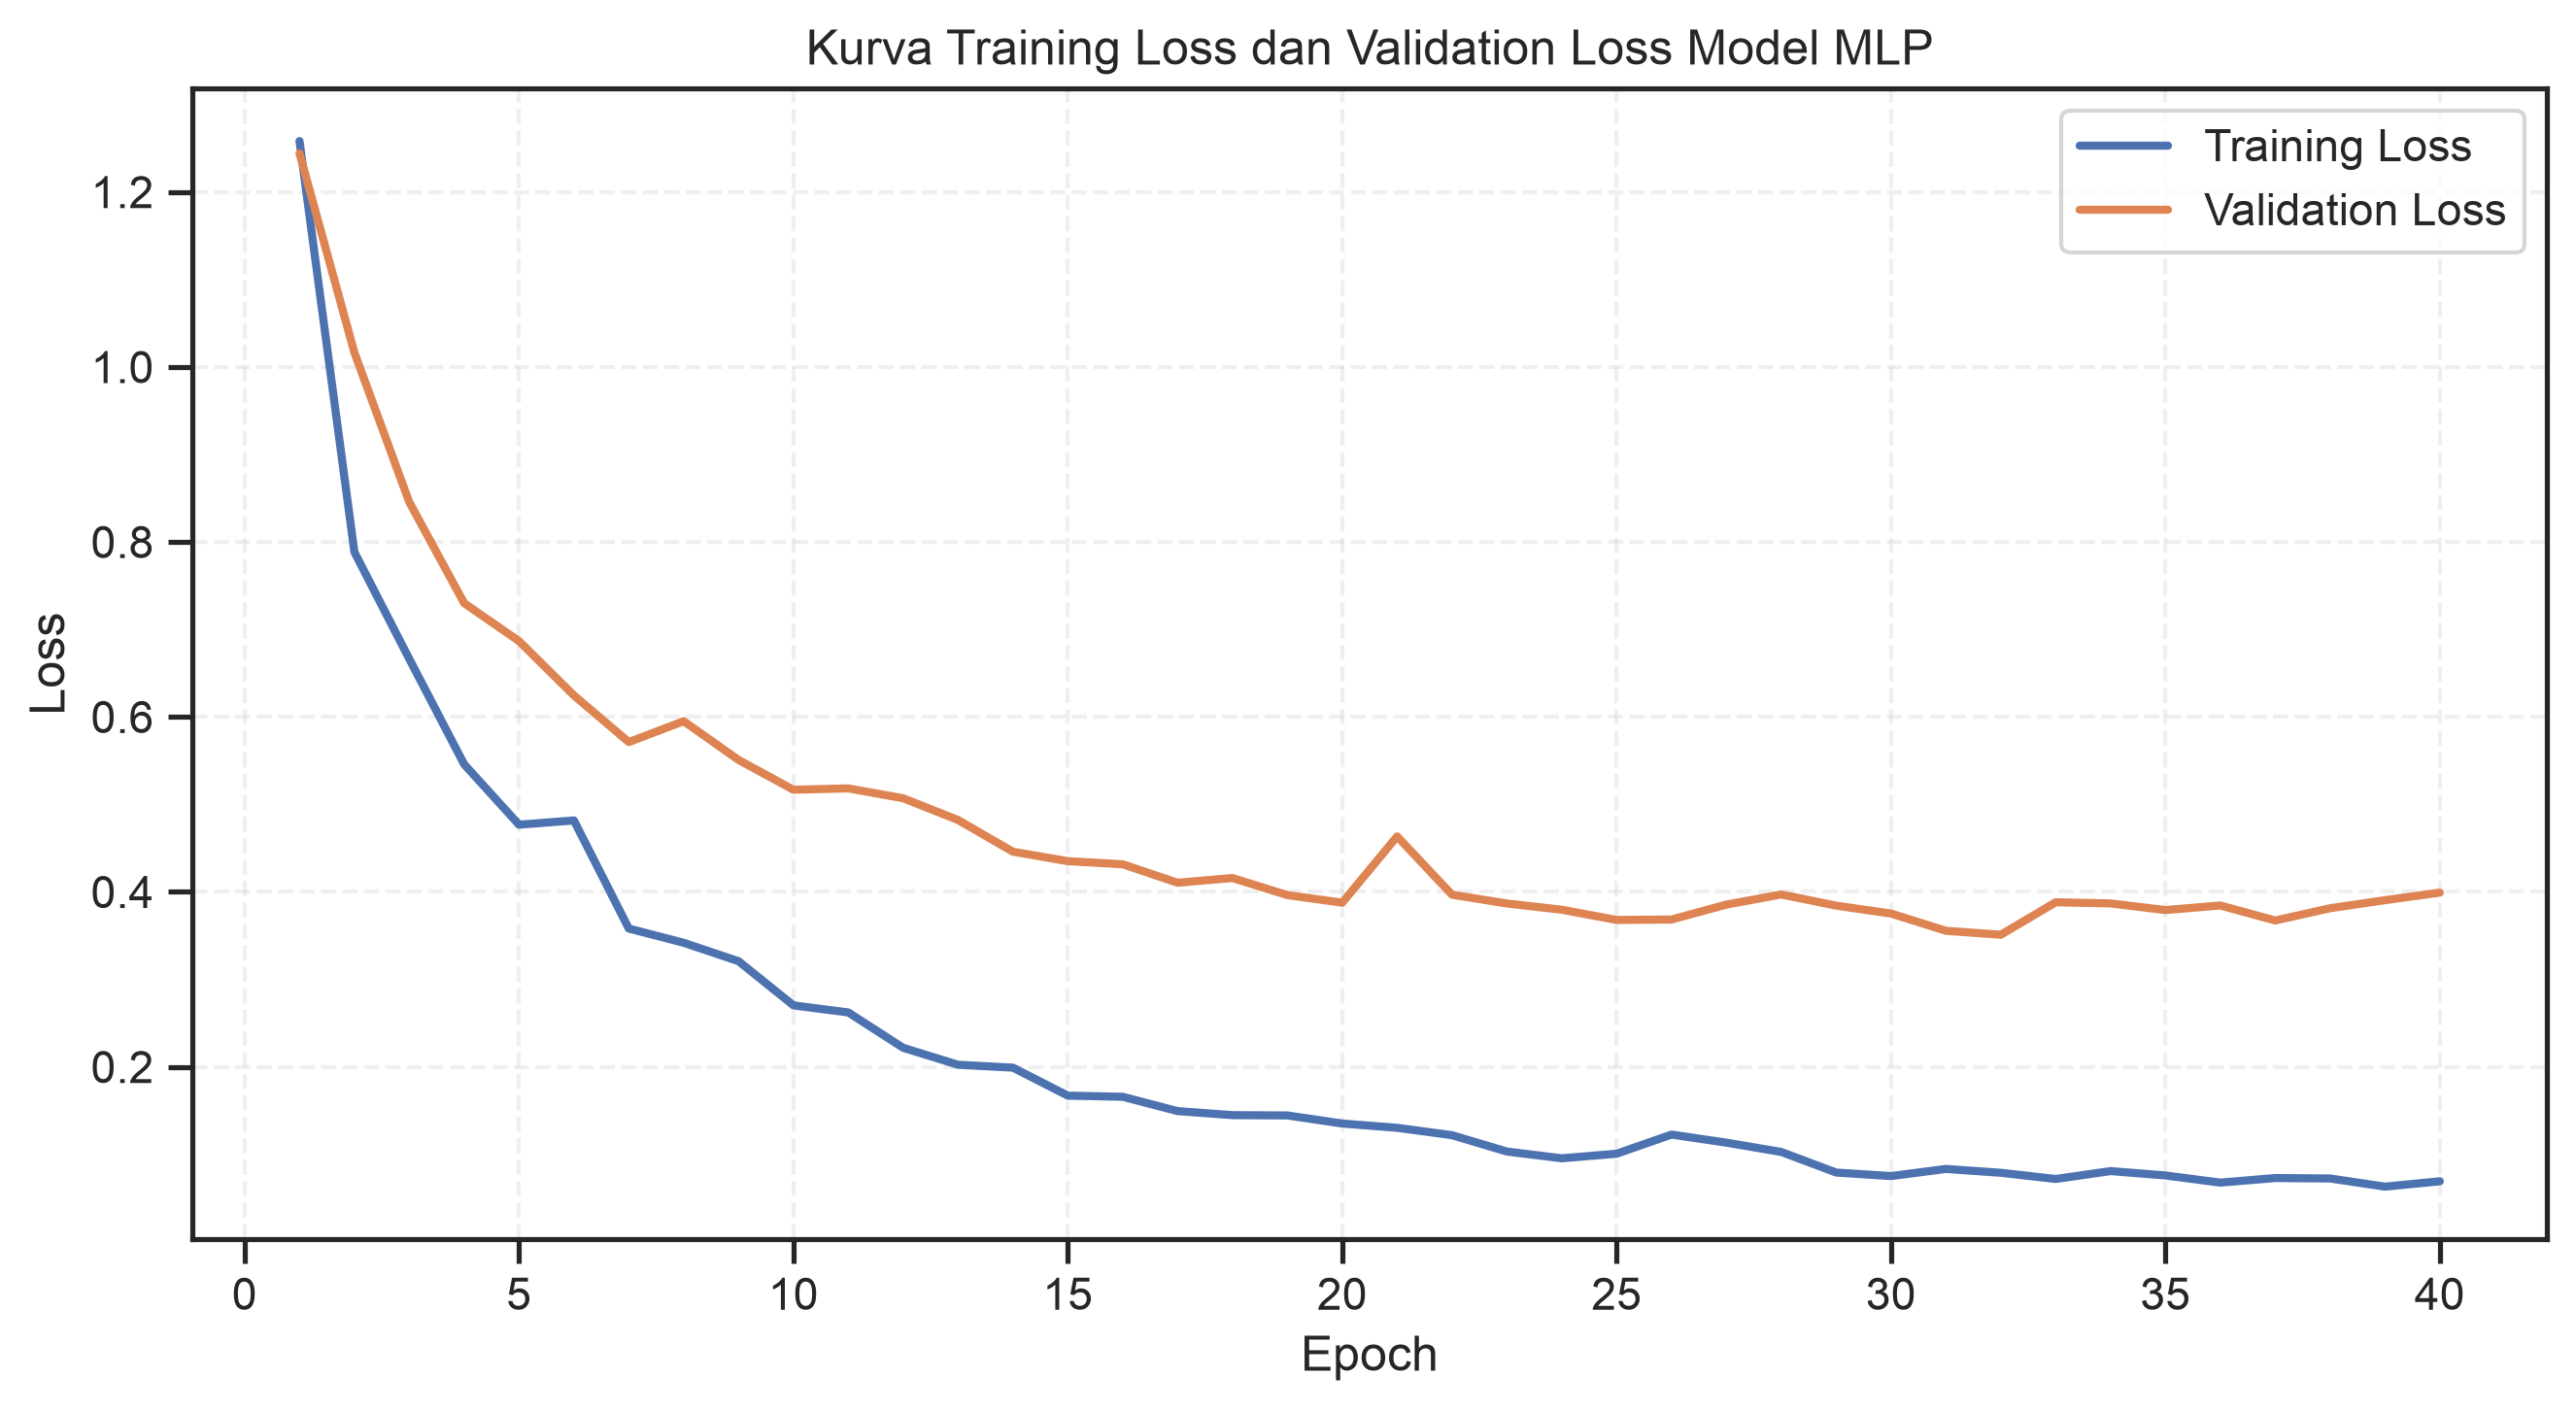

In [63]:
# ============================================================
# KURVA TRAINING LOSS DAN VALIDATION LOSS MODEL MLP
# ============================================================

if "history" not in globals() or "val_loss" not in history.history:
    raise RuntimeError(
        "Riwayat validation loss tidak ditemukan. "
        "Pastikan MLP dilatih menggunakan validation_data."
    )

epochs = np.arange(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(9, 5), dpi=300)
plt.plot(epochs, history.history["loss"], label="Training Loss", linewidth=2)
plt.plot(epochs, history.history["val_loss"], label="Validation Loss", linewidth=2)

plt.title("Kurva Training Loss dan Validation Loss Model MLP")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()

os.makedirs("results/figures", exist_ok=True)
plt.savefig(
    "results/figures/kurva_training_validation_loss_mlp.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

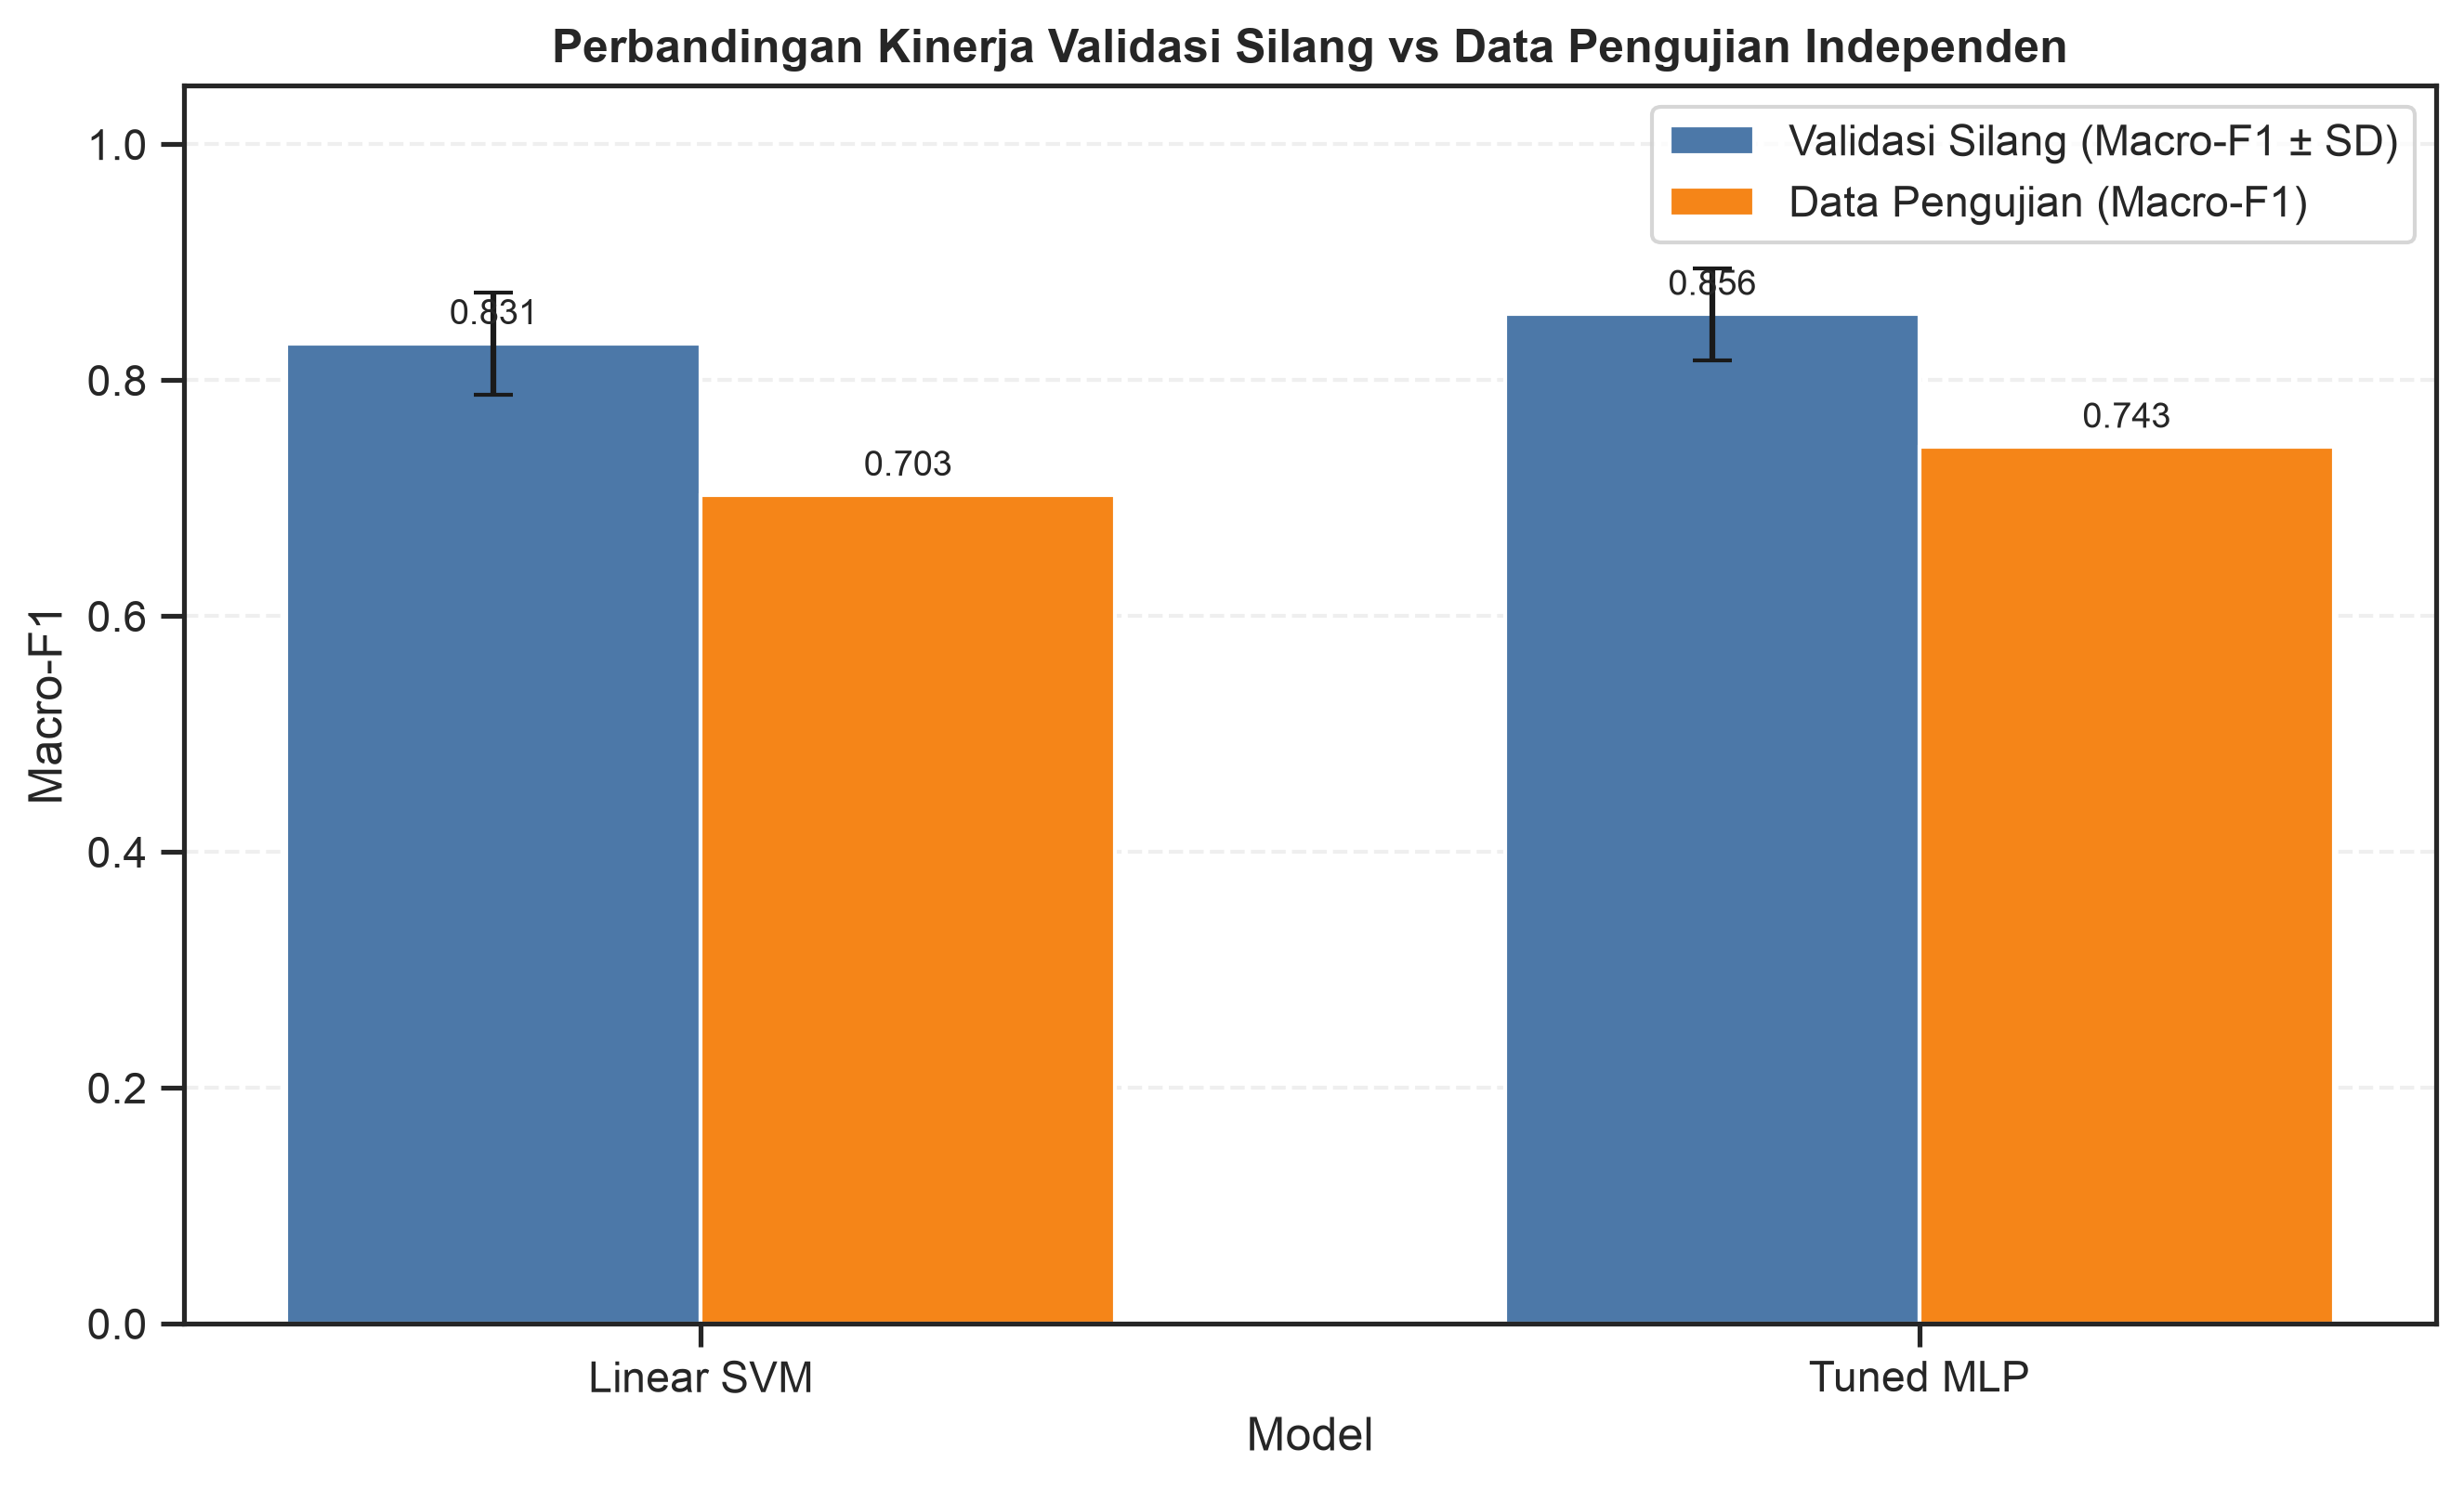

,Model,Validasi Silang,SD Validasi Silang,Data Pengujian
0,Linear SVM,0.8312,0.0434,0.7027
1,Tuned MLP,0.8559,0.0391,0.7434


Catatan: notebook mencatat bahwa hold-out test telah diperiksa sebelumnya; interpretasikan perbandingan ini sebagai post-hoc.


In [64]:
import os
import numpy as np
import pandas as pd

# ============================================================
# PERBANDINGAN KINERJA VALIDASI SILANG VS DATA PENGUJIAN
# Macro-F1 — Linear SVM vs Tuned MLP
# ============================================================

import matplotlib.pyplot as plt

# Ambil skor CV SVM dari nested cross-validation
if "nested_cv_summary" not in globals():
    raise RuntimeError(
        "nested_cv_summary belum tersedia. "
        "Jalankan sel nested cross-validation terlebih dahulu."
    )

svm_cv_row = nested_cv_summary.loc[
    nested_cv_summary["Model"].str.contains("SVM", case=False, regex=False)
]

if svm_cv_row.empty:
    raise ValueError("Skor CV SVM tidak ditemukan di nested_cv_summary.")

svm_cv_f1 = float(svm_cv_row["Mean_Macro_F1"].iloc[0])
svm_cv_std = float(svm_cv_row["Std_Macro_F1"].iloc[0])

# Ambil skor CV MLP dari hasil random search
if "mlp_tuning_ranking" not in globals():
    raise RuntimeError(
        "mlp_tuning_ranking belum tersedia. "
        "Jalankan sel pemeringkatan hyperparameter MLP terlebih dahulu."
    )

mlp_cv_f1 = float(
    mlp_tuning_ranking.iloc[0]["Mean_Macro_F1"]
)
mlp_cv_std = float(
    mlp_tuning_ranking.iloc[0]["STD_Macro_F1"]
)

# Skor hold-out dari evaluasi akhir
required_scores = ["svm_macro_f1", "tuned_macro_f1"]
missing_scores = [
    name for name in required_scores
    if name not in globals()
]

if missing_scores:
    raise RuntimeError(
        "Skor pengujian belum tersedia: "
        + ", ".join(missing_scores)
        + ". Jalankan evaluasi akhir SVM dan MLP terlebih dahulu."
    )

comparison_df = pd.DataFrame({
    "Model": ["Linear SVM", "Tuned MLP"],
    "Validasi Silang": [svm_cv_f1, mlp_cv_f1],
    "SD Validasi Silang": [svm_cv_std, mlp_cv_std],
    "Data Pengujian": [
        float(svm_macro_f1),
        float(tuned_macro_f1)
    ]
})

# Plot berkelompok
x = np.arange(len(comparison_df))
bar_width = 0.34

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=300)

cv_bars = ax.bar(
    x - bar_width / 2,
    comparison_df["Validasi Silang"],
    bar_width,
    yerr=comparison_df["SD Validasi Silang"],
    capsize=5,
    label="Validasi Silang (Macro-F1 ± SD)",
    color="#4C78A8"
)

test_bars = ax.bar(
    x + bar_width / 2,
    comparison_df["Data Pengujian"],
    bar_width,
    label="Data Pengujian (Macro-F1)",
    color="#F58518"
)

for bars in (cv_bars, test_bars):
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.3f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

ax.set_title(
    "Perbandingan Kinerja Validasi Silang vs Data Pengujian Independen",
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Model"])
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()
fig.tight_layout()

os.makedirs("results/figures", exist_ok=True)
fig.savefig(
    "results/figures/perbandingan_cv_vs_data_pengujian.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(comparison_df.round(4))

print(
    "Catatan: notebook mencatat bahwa hold-out test telah "
    "diperiksa sebelumnya; interpretasikan perbandingan ini sebagai post-hoc."
)

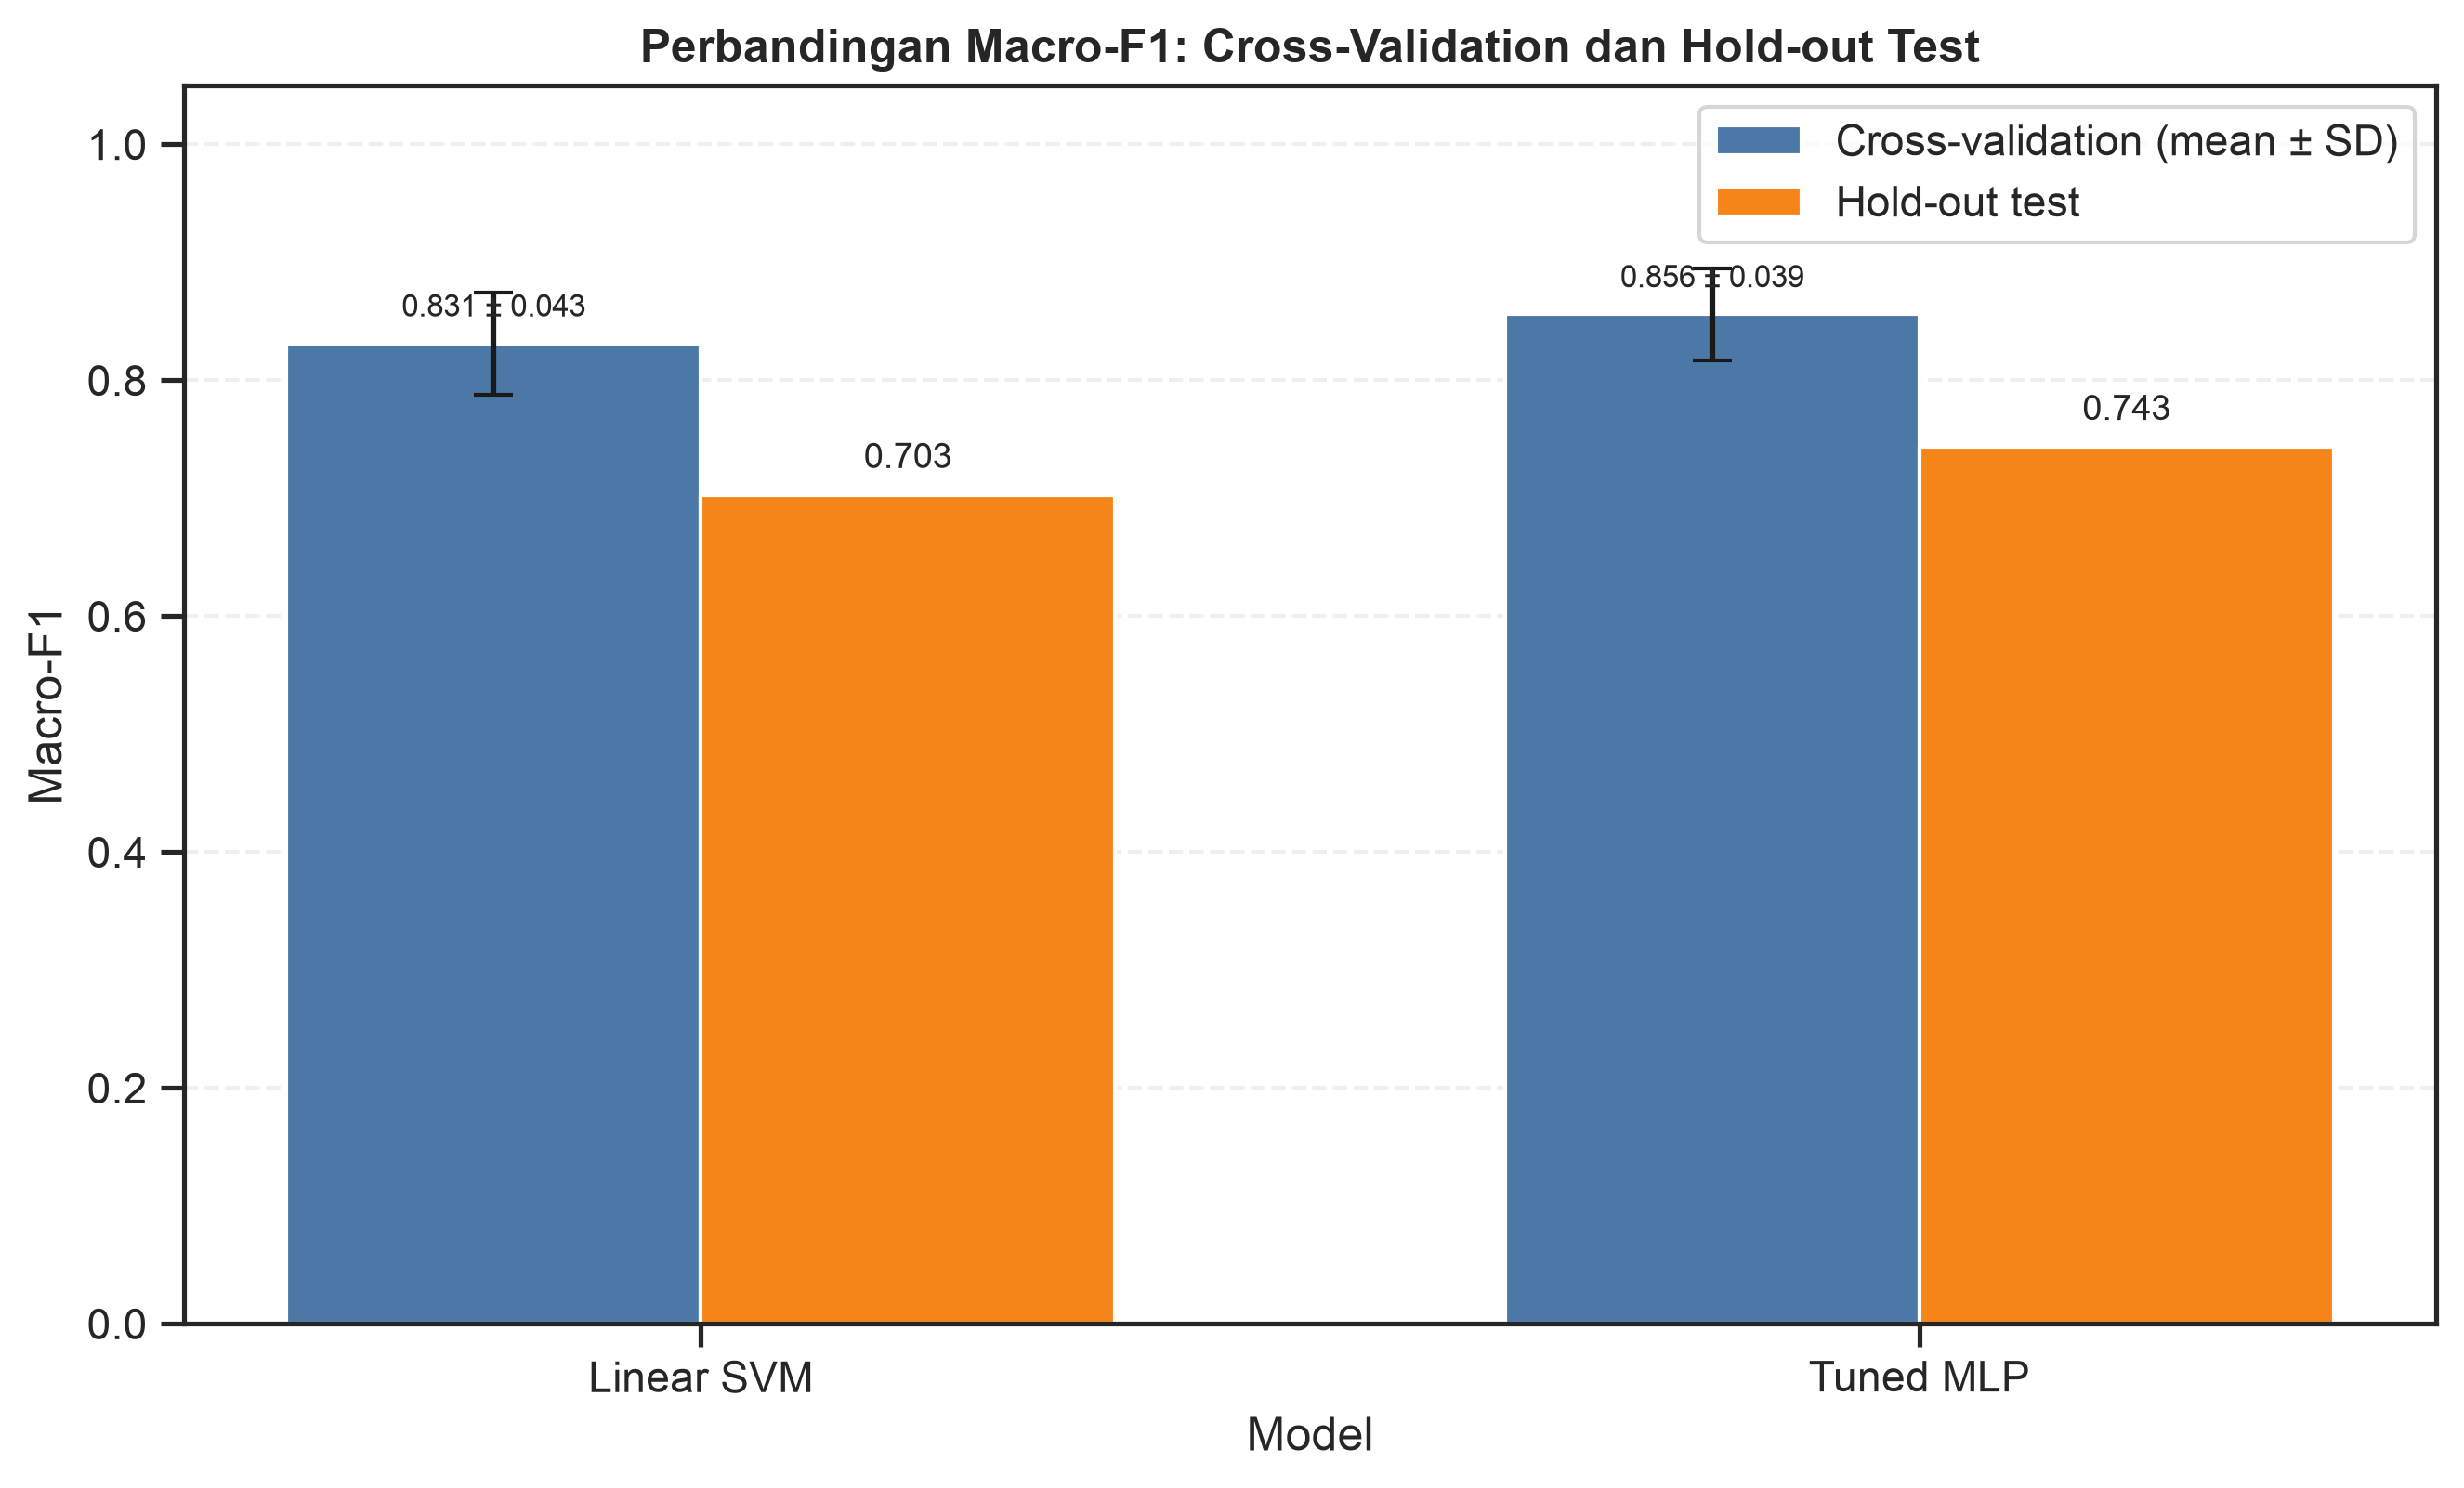

In [65]:
# ============================================================
# PERBANDINGAN MACRO-F1: CROSS-VALIDATION vs HOLD-OUT TEST
# ============================================================

required_variables = [
    "nested_cv_summary",
    "mlp_tuning_ranking",
    "svm_macro_f1",
    "tuned_macro_f1"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Variabel hasil belum tersedia: " + ", ".join(missing)
    )

# Ambil skor CV SVM dari nested cross-validation
svm_cv_row = nested_cv_summary[
    nested_cv_summary["Model"].str.contains("SVM", case=False)
]

if svm_cv_row.empty:
    raise ValueError("Hasil CV untuk SVM tidak ditemukan.")

svm_cv_mean = float(svm_cv_row["Mean_Macro_F1"].iloc[0])
svm_cv_std = float(svm_cv_row["Std_Macro_F1"].iloc[0])

# Ambil skor CV MLP terbaik dari random search
best_mlp_row = mlp_tuning_ranking.iloc[0]
mlp_cv_mean = float(best_mlp_row["Mean_Macro_F1"])
mlp_cv_std = float(best_mlp_row["STD_Macro_F1"])

models = ["Linear SVM", "Tuned MLP"]
cv_scores = [svm_cv_mean, mlp_cv_mean]
cv_errors = [svm_cv_std, mlp_cv_std]
holdout_scores = [float(svm_macro_f1), float(tuned_macro_f1)]

x = np.arange(len(models))
bar_width = 0.34

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=300)

cv_bars = ax.bar(
    x - bar_width / 2,
    cv_scores,
    bar_width,
    yerr=cv_errors,
    capsize=5,
    label="Cross-validation (mean ± SD)",
    color="#4C78A8"
)

holdout_bars = ax.bar(
    x + bar_width / 2,
    holdout_scores,
    bar_width,
    label="Hold-out test",
    color="#F58518"
)

for bar, mean_score, std_score in zip(cv_bars, cv_scores, cv_errors):
    ax.annotate(
        f"{mean_score:.3f} ± {std_score:.3f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=8
    )

for bar in holdout_bars:
    ax.annotate(
        f"{bar.get_height():.3f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title(
    "Perbandingan Macro-F1: Cross-Validation dan Hold-out Test",
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    "results/figures/perbandingan_cv_vs_holdout_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

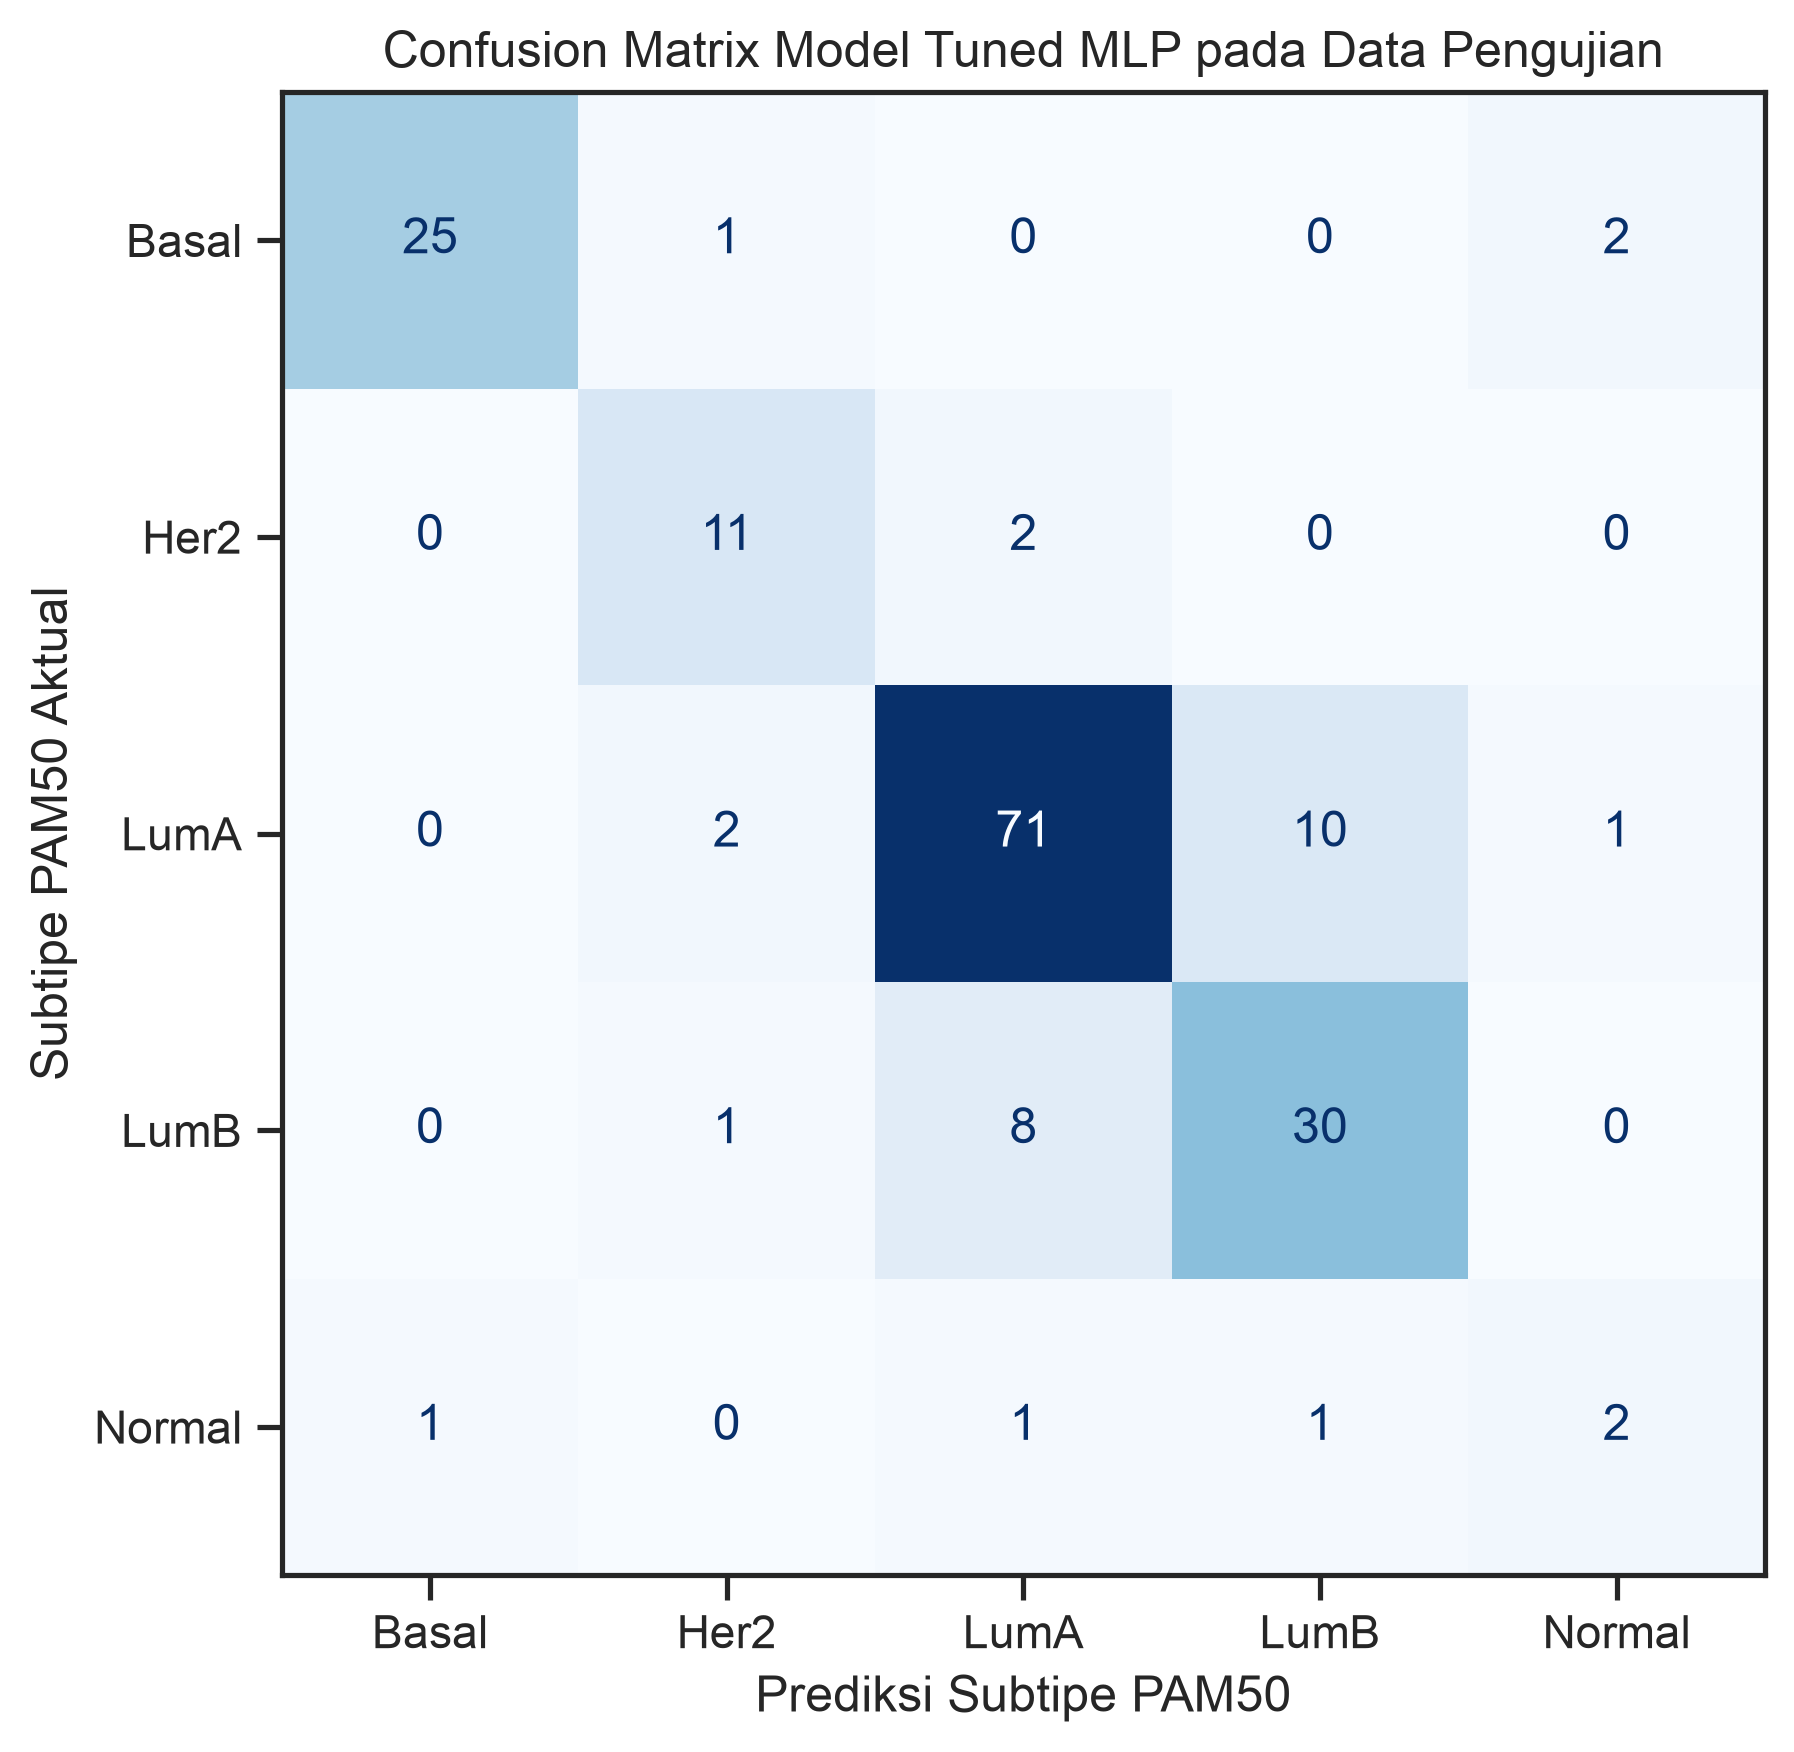

In [66]:
# Confusion Matrix Model Tuned MLP pada Data Pengujian

y_true_test = np.asarray(y_test)
y_pred_test = np.asarray(y_test_pred_tuned_mlp)
class_ids = np.arange(len(label_encoder.classes_))
class_names = label_encoder.classes_

cm_tuned_mlp_test = confusion_matrix(
    y_true_test,
    y_pred_test,
    labels=class_ids
)

fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned_mlp_test,
    display_labels=class_names
).plot(
    ax=ax,
    values_format="d",
    colorbar=False,
    cmap="Blues"
)

ax.set_title("Confusion Matrix Model Tuned MLP pada Data Pengujian")
ax.set_xlabel("Prediksi Subtipe PAM50")
ax.set_ylabel("Subtipe PAM50 Aktual")

plt.tight_layout()
plt.savefig(
    "results/figures/confusion_matrix_tuned_mlp_data_pengujian.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

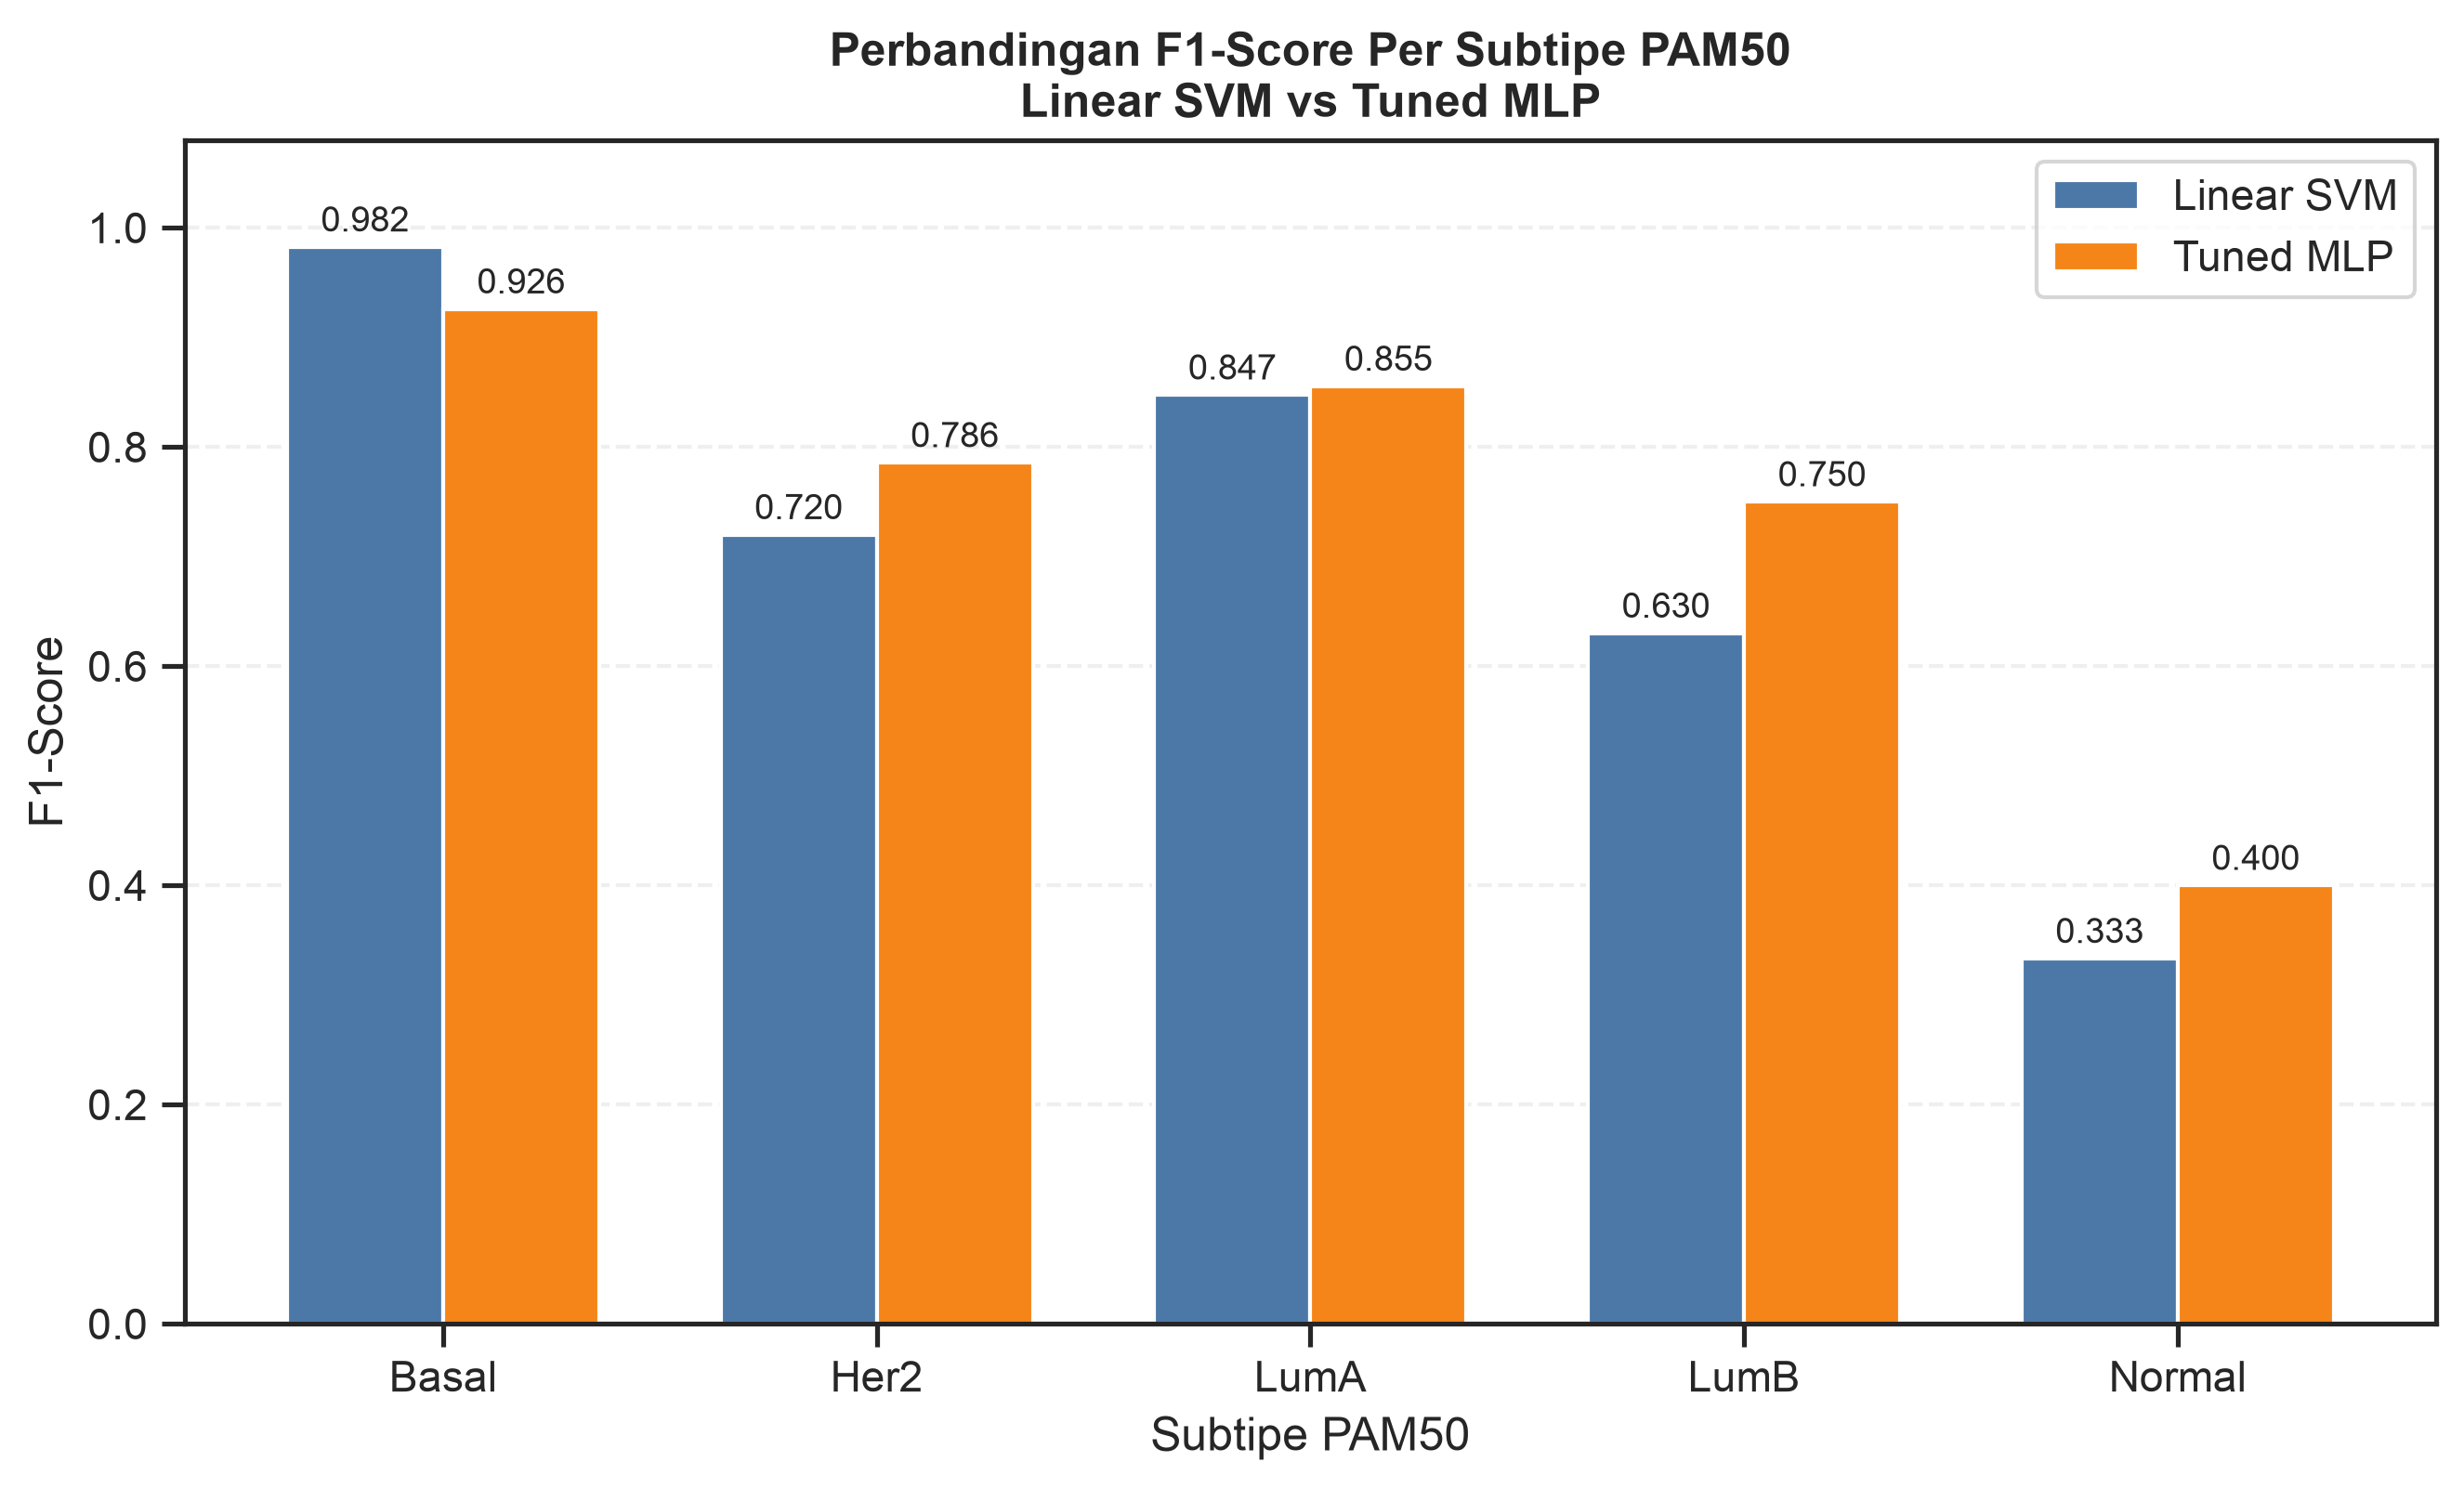

In [67]:
# ============================================================
# PERBANDINGAN F1-SCORE PER SUBTIPE PAM50
# LINEAR SVM vs TUNED MLP
# ============================================================

required_variables = [
    "class_names",
    "svm_f1_per_class",
    "tuned_f1_per_class"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Variabel belum tersedia: " + ", ".join(missing)
    )

class_names = np.asarray(class_names)
svm_scores = np.asarray(svm_f1_per_class)
mlp_scores = np.asarray(tuned_f1_per_class)

if not (
    len(class_names) == len(svm_scores) == len(mlp_scores)
):
    raise ValueError("Jumlah kelas dan skor F1 tidak cocok.")

x = np.arange(len(class_names))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=300)

bars_svm = ax.bar(
    x - bar_width / 2,
    svm_scores,
    bar_width,
    label="Linear SVM",
    color="#4C78A8"
)

bars_mlp = ax.bar(
    x + bar_width / 2,
    mlp_scores,
    bar_width,
    label="Tuned MLP",
    color="#F58518"
)

for bars in (bars_svm, bars_mlp):
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.3f}",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

ax.set_title(
    "Perbandingan F1-Score Per Subtipe PAM50\n"
    "Linear SVM vs Tuned MLP",
    fontweight="bold"
)
ax.set_xlabel("Subtipe PAM50")
ax.set_ylabel("F1-Score")
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.set_ylim(0, 1.08)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    "results/figures/f1_per_subtype_linear_svm_vs_tuned_mlp.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

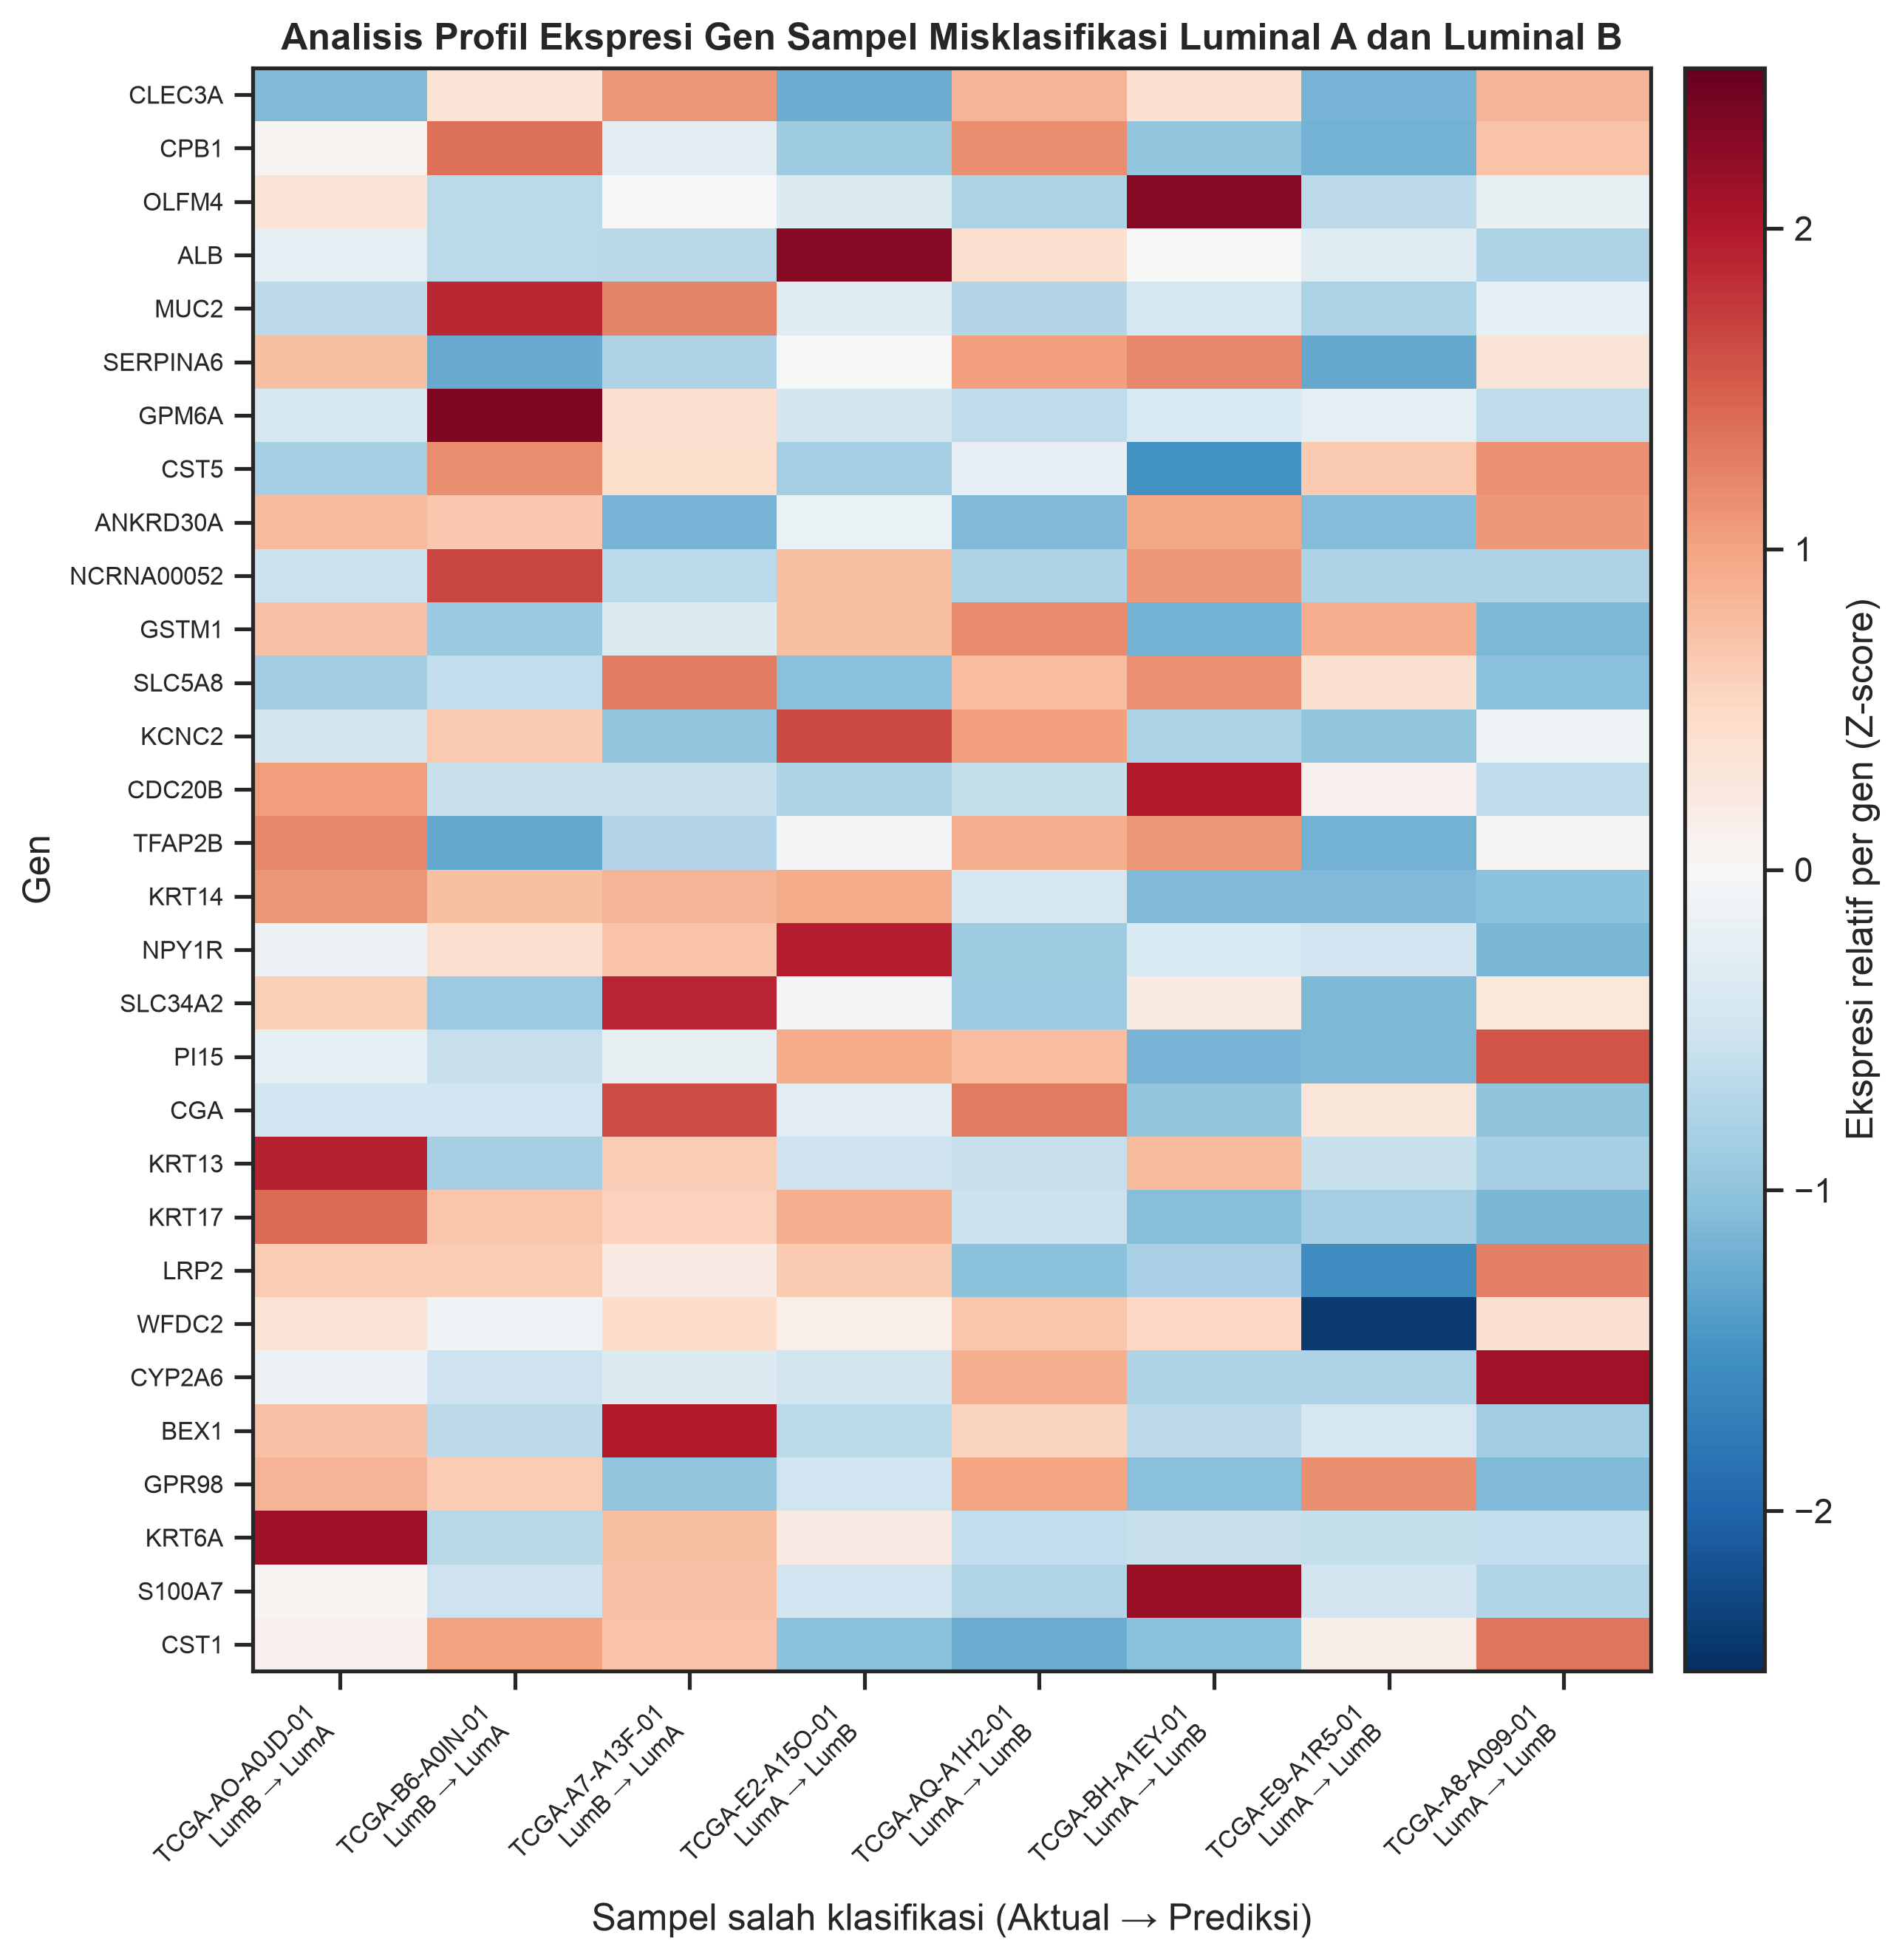

Jumlah sampel LumA ↔ LumB salah klasifikasi: 8
Gambar disimpan di results/figures/.


In [68]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ============================================================
# ANALISIS PROFIL EKSPRESI GEN — SAMPEL LumA / LumB SALAH KLASIFIKASI
# MLP — Data validasi
# ============================================================


# Pastikan variabel yang diperlukan tersedia
required_variables = [
    "X_val_dl_selected",
    "y_val_dl_array",
    "y_val_pred_mlp",
    "label_encoder"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Variabel belum tersedia: " + ", ".join(missing)
    )

y_true = np.asarray(y_val_dl_array)
y_pred = np.asarray(y_val_pred_mlp)

if len(X_val_dl_selected) != len(y_true) or len(y_true) != len(y_pred):
    raise ValueError("Jumlah sampel pada fitur, label aktual, dan prediksi tidak sama.")

luma_id, lumb_id = label_encoder.transform(["LumA", "LumB"])

# Ambil kesalahan silang LumA ↔ LumB saja
is_luminal_cross_error = (
    (((y_true == luma_id) & (y_pred == lumb_id)) |
     ((y_true == lumb_id) & (y_pred == luma_id)))
)

error_positions = np.flatnonzero(is_luminal_cross_error)

if len(error_positions) == 0:
    print("Tidak ditemukan sampel LumA ↔ LumB yang salah diklasifikasikan.")
else:
    # Ekspresi sampel yang salah diklasifikasikan
    error_expression = X_val_dl_selected.iloc[error_positions].copy()
    error_expression = error_expression.apply(
        pd.to_numeric, errors="coerce"
    )

    # Pilih gen dengan varians tertinggi pada sampel tersebut
    n_genes = min(30, error_expression.shape[1])
    top_genes = error_expression.var(axis=0).nlargest(n_genes).index

    # Z-score per gen untuk memperjelas pola relatif
    heatmap_data = error_expression[top_genes].T
    row_std = heatmap_data.std(axis=1).replace(0, 1)
    heatmap_z = (
        heatmap_data
        .sub(heatmap_data.mean(axis=1), axis=0)
        .div(row_std, axis=0)
        .fillna(0)
        .clip(-2.5, 2.5)
    )

    subtype_names = np.asarray(label_encoder.classes_)
    actual_names = subtype_names[y_true[error_positions]]
    predicted_names = subtype_names[y_pred[error_positions]]
    sample_ids = error_expression.index.astype(str)

    # Heatmap ekspresi
    fig, ax = plt.subplots(
        figsize=(max(9, len(error_positions) * 0.8), 9),
        dpi=300
    )

    image = ax.imshow(
        heatmap_z.to_numpy(),
        aspect="auto",
        interpolation="nearest",
        cmap="RdBu_r",
        vmin=-2.5,
        vmax=2.5
    )

    ax.set_yticks(np.arange(len(top_genes)))
    ax.set_yticklabels(top_genes, fontsize=8)

    ax.set_xticks(np.arange(len(error_positions)))
    ax.set_xticklabels(
        [
            f"{sample_id}\n{actual} → {predicted}"
            for sample_id, actual, predicted
            in zip(sample_ids, actual_names, predicted_names)
        ],
        rotation=45,
        ha="right",
        fontsize=8
    )

    ax.set_xlabel("Sampel salah klasifikasi (Aktual → Prediksi)")
    ax.set_ylabel("Gen")
    ax.set_title(
        "Analisis Profil Ekspresi Gen Sampel Misklasifikasi "
        "Luminal A dan Luminal B",
        fontweight="bold"
    )

    colorbar = fig.colorbar(image, ax=ax, pad=0.02)
    colorbar.set_label("Ekspresi relatif per gen (Z-score)")

    plt.tight_layout()
    plt.savefig(
        "results/figures/analisis_profil_ekspresi_sampel_misklasifikasi_LumA_LumB.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    print(f"Jumlah sampel LumA ↔ LumB salah klasifikasi: {len(error_positions)}")
    print("Gambar disimpan di results/figures/.")

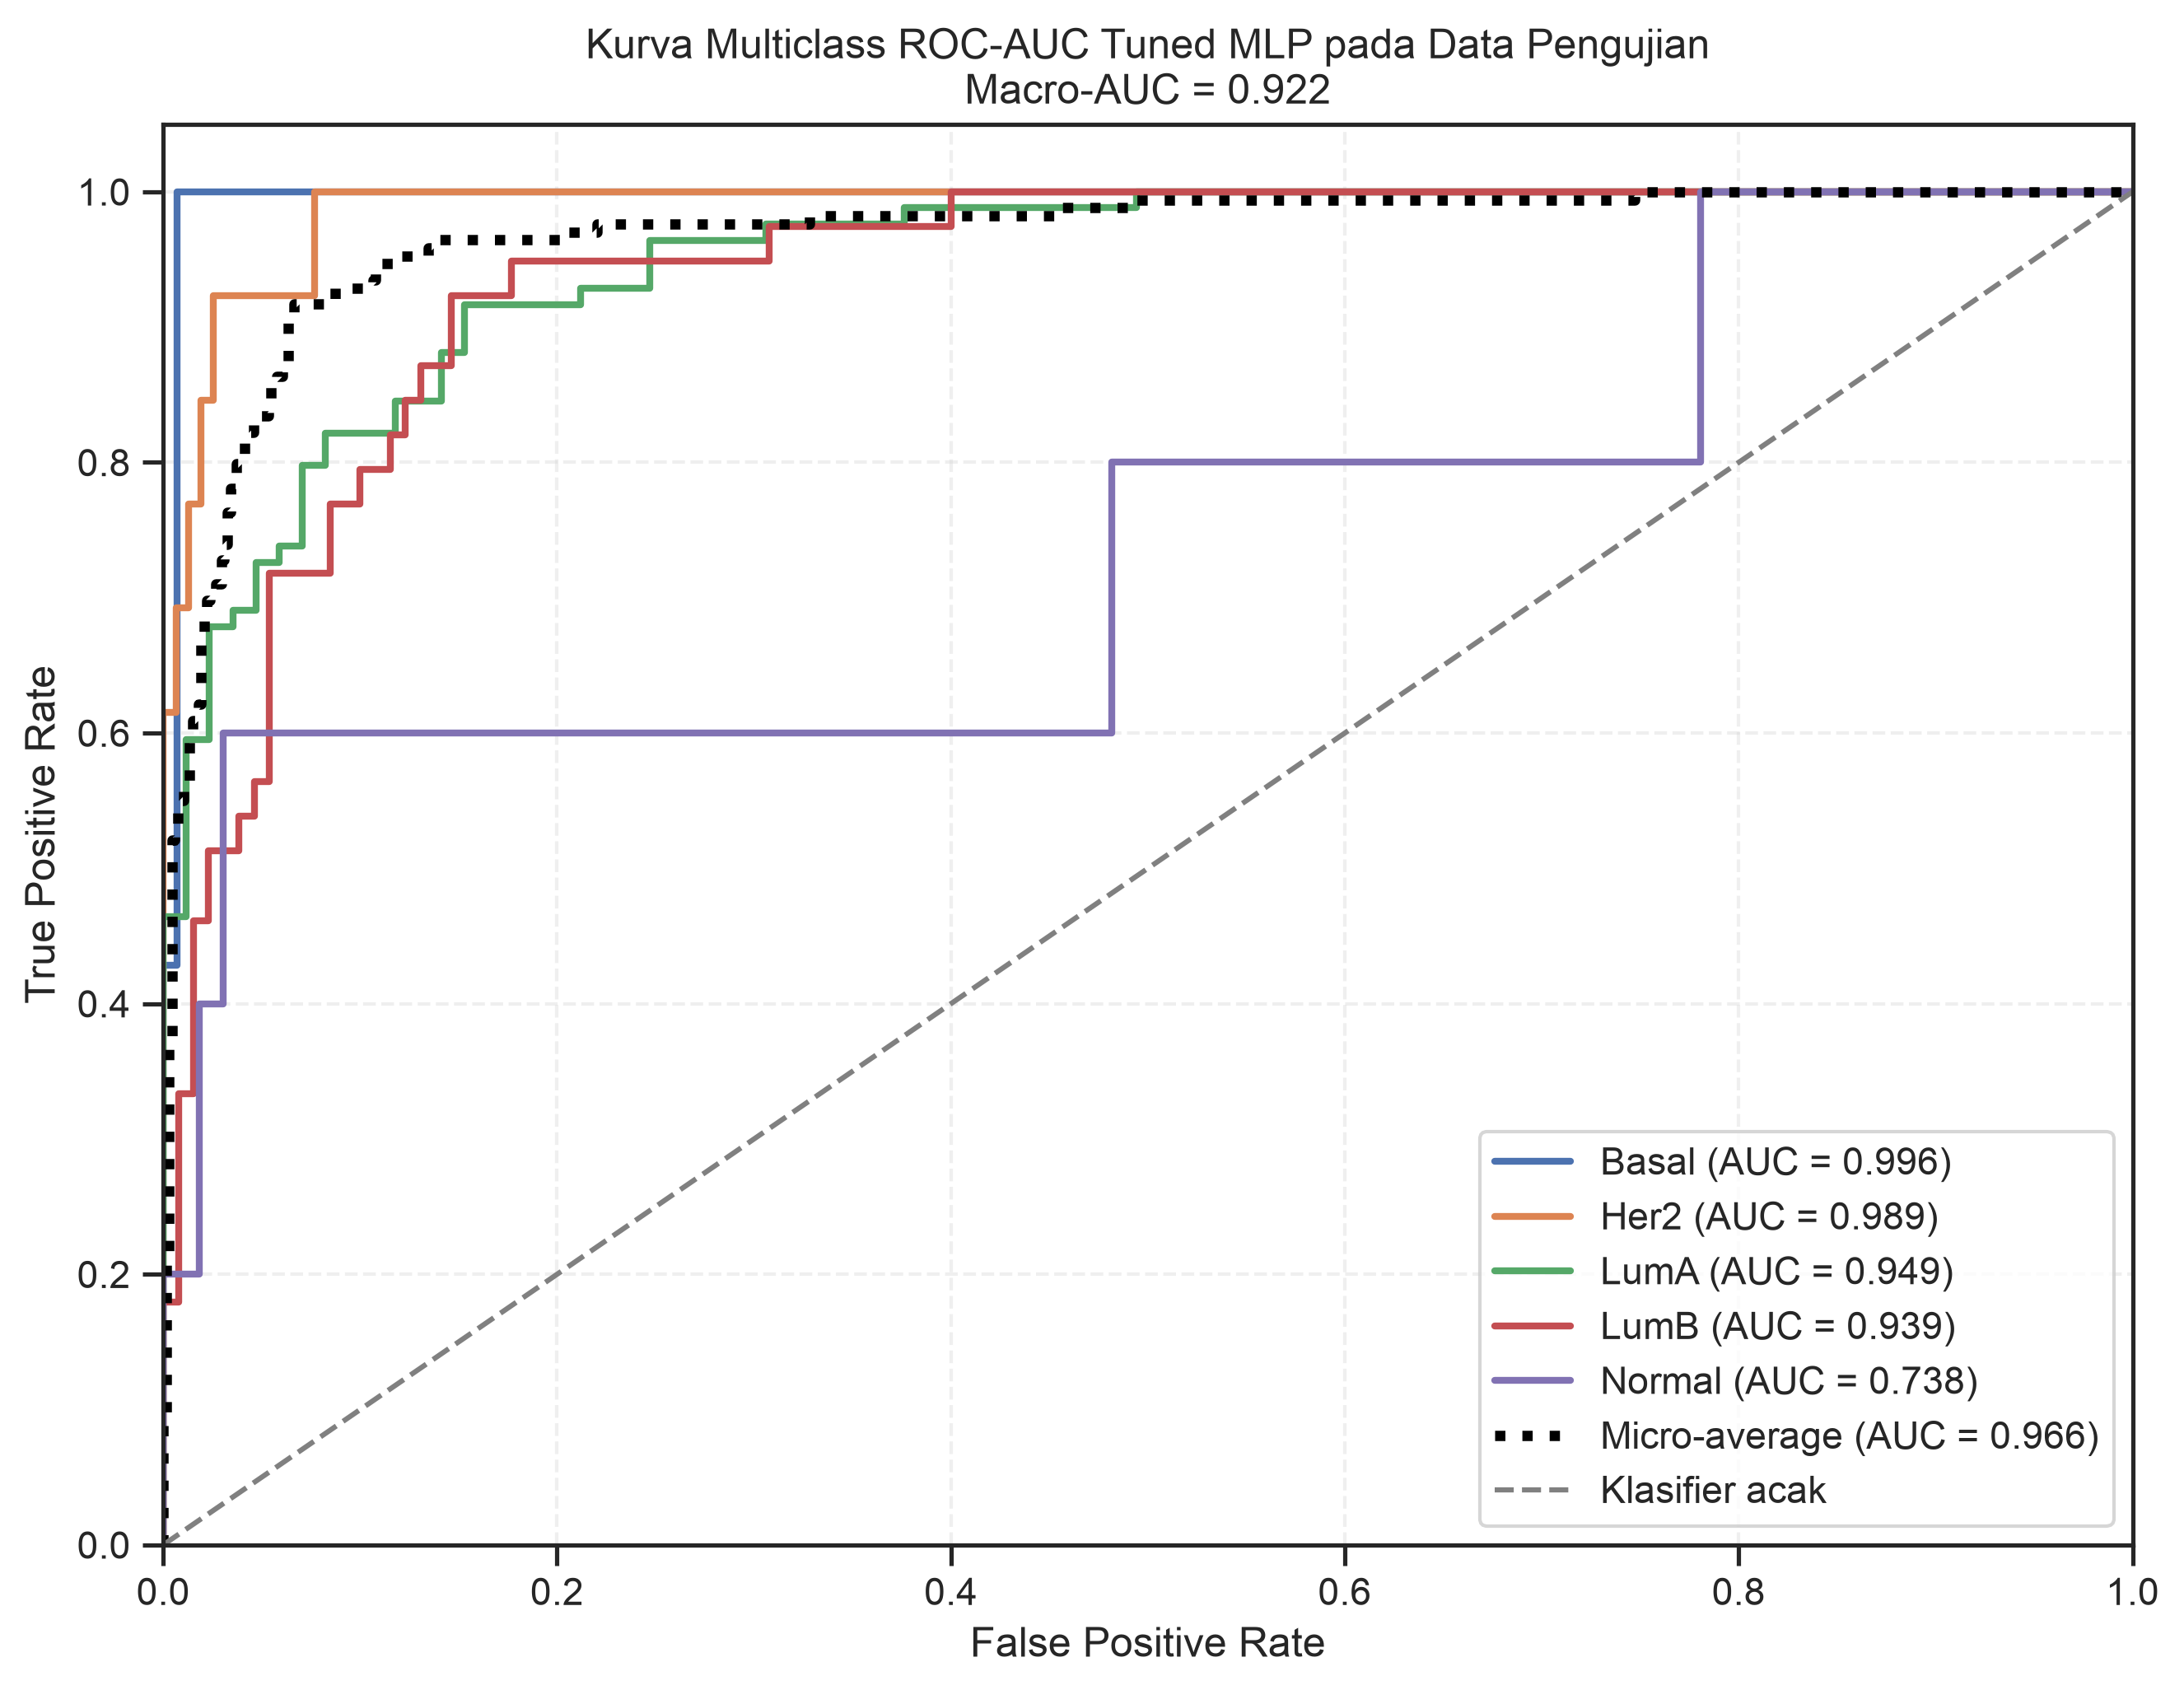

In [69]:
# ============================================================
# KURVA MULTICLASS ROC-AUC TUNED MLP — DATA PENGUJIAN
# ============================================================

class_names = np.asarray(label_encoder.classes_)
class_ids = np.arange(len(class_names))

y_true_test = np.asarray(y_test_tuned_mlp)
y_prob_test = np.asarray(y_test_prob_tuned_mlp)

if y_prob_test.shape != (len(y_true_test), len(class_names)):
    raise ValueError("Dimensi probabilitas prediksi tidak sesuai dengan label test.")

y_test_bin_roc = label_binarize(
    y_true_test,
    classes=class_ids
)

fig, ax = plt.subplots(figsize=(9, 7), dpi=300)

class_aucs = []

for i, subtype in enumerate(class_names):
    fpr, tpr, _ = roc_curve(
        y_test_bin_roc[:, i],
        y_prob_test[:, i]
    )
    class_auc = auc(fpr, tpr)
    class_aucs.append(class_auc)

    ax.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{subtype} (AUC = {class_auc:.3f})"
    )

# Micro-average ROC
micro_fpr, micro_tpr, _ = roc_curve(
    y_test_bin_roc.ravel(),
    y_prob_test.ravel()
)
micro_auc = auc(micro_fpr, micro_tpr)

ax.plot(
    micro_fpr,
    micro_tpr,
    linestyle=":",
    linewidth=3,
    color="black",
    label=f"Micro-average (AUC = {micro_auc:.3f})"
)

macro_auc = np.mean(class_aucs)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Klasifier acak"
)

ax.set(
    xlim=(0, 1),
    ylim=(0, 1.05),
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title=f"Kurva Multiclass ROC-AUC Tuned MLP pada Data Pengujian\nMacro-AUC = {macro_auc:.3f}"
)

ax.grid(linestyle="--", alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()

os.makedirs("results/figures", exist_ok=True)
plt.savefig(
    "results/figures/kurva_multiclass_roc_auc_tuned_mlp_data_pengujian.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

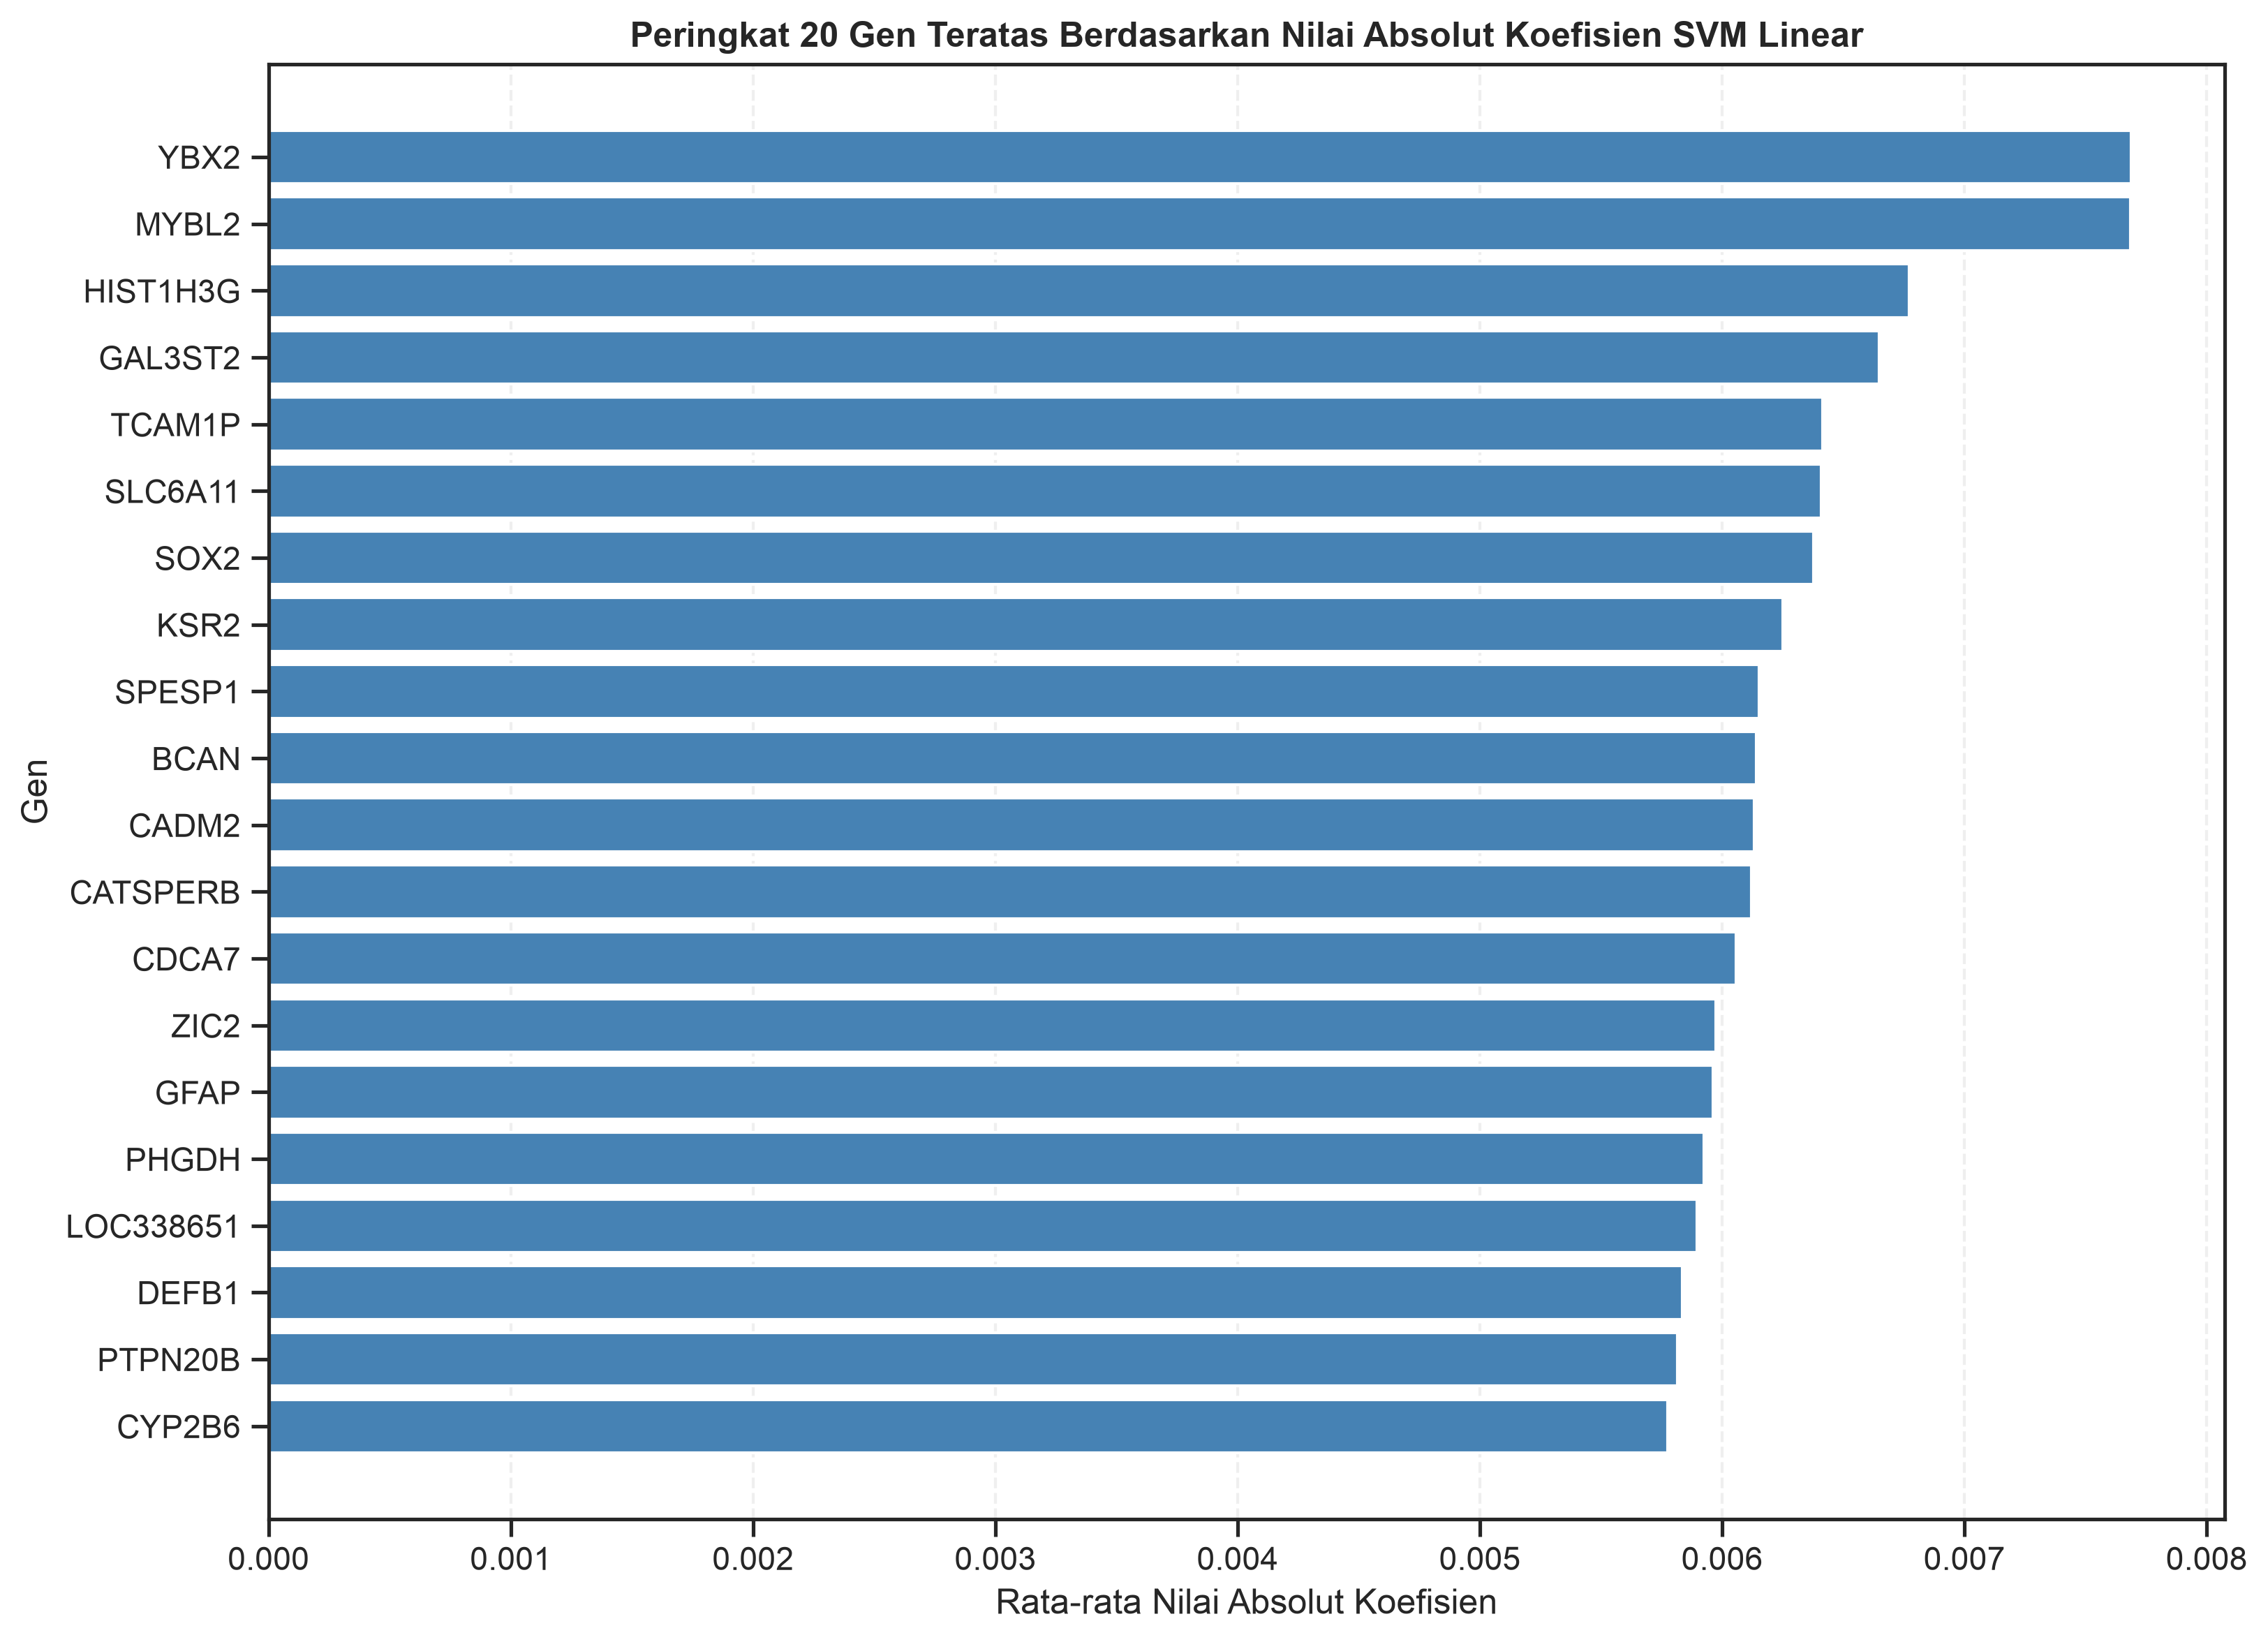

In [70]:
# ============================================================
# PERINGKAT 20 GEN TERATAS — LINEAR SVM
# ============================================================

svm_gene_names = svm_final_selector.get_feature_names_out(
    input_features=X_train.columns
)

mean_abs_coef = np.abs(
    final_svm_model.coef_
).mean(axis=0)

top_genes_df = (
    pd.DataFrame({
        "Gen": svm_gene_names,
        "Nilai Absolut Koefisien": mean_abs_coef
    })
    .nlargest(20, "Nilai Absolut Koefisien")
    .sort_values("Nilai Absolut Koefisien")
)

fig, ax = plt.subplots(figsize=(11, 8), dpi=300)

ax.barh(
    top_genes_df["Gen"],
    top_genes_df["Nilai Absolut Koefisien"],
    color="steelblue"
)

ax.set_title(
    "Peringkat 20 Gen Teratas Berdasarkan Nilai Absolut Koefisien SVM Linear",
    fontweight="bold"
)
ax.set_xlabel("Rata-rata Nilai Absolut Koefisien")
ax.set_ylabel("Gen")
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/figures/top_20_gen_linear_svm.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

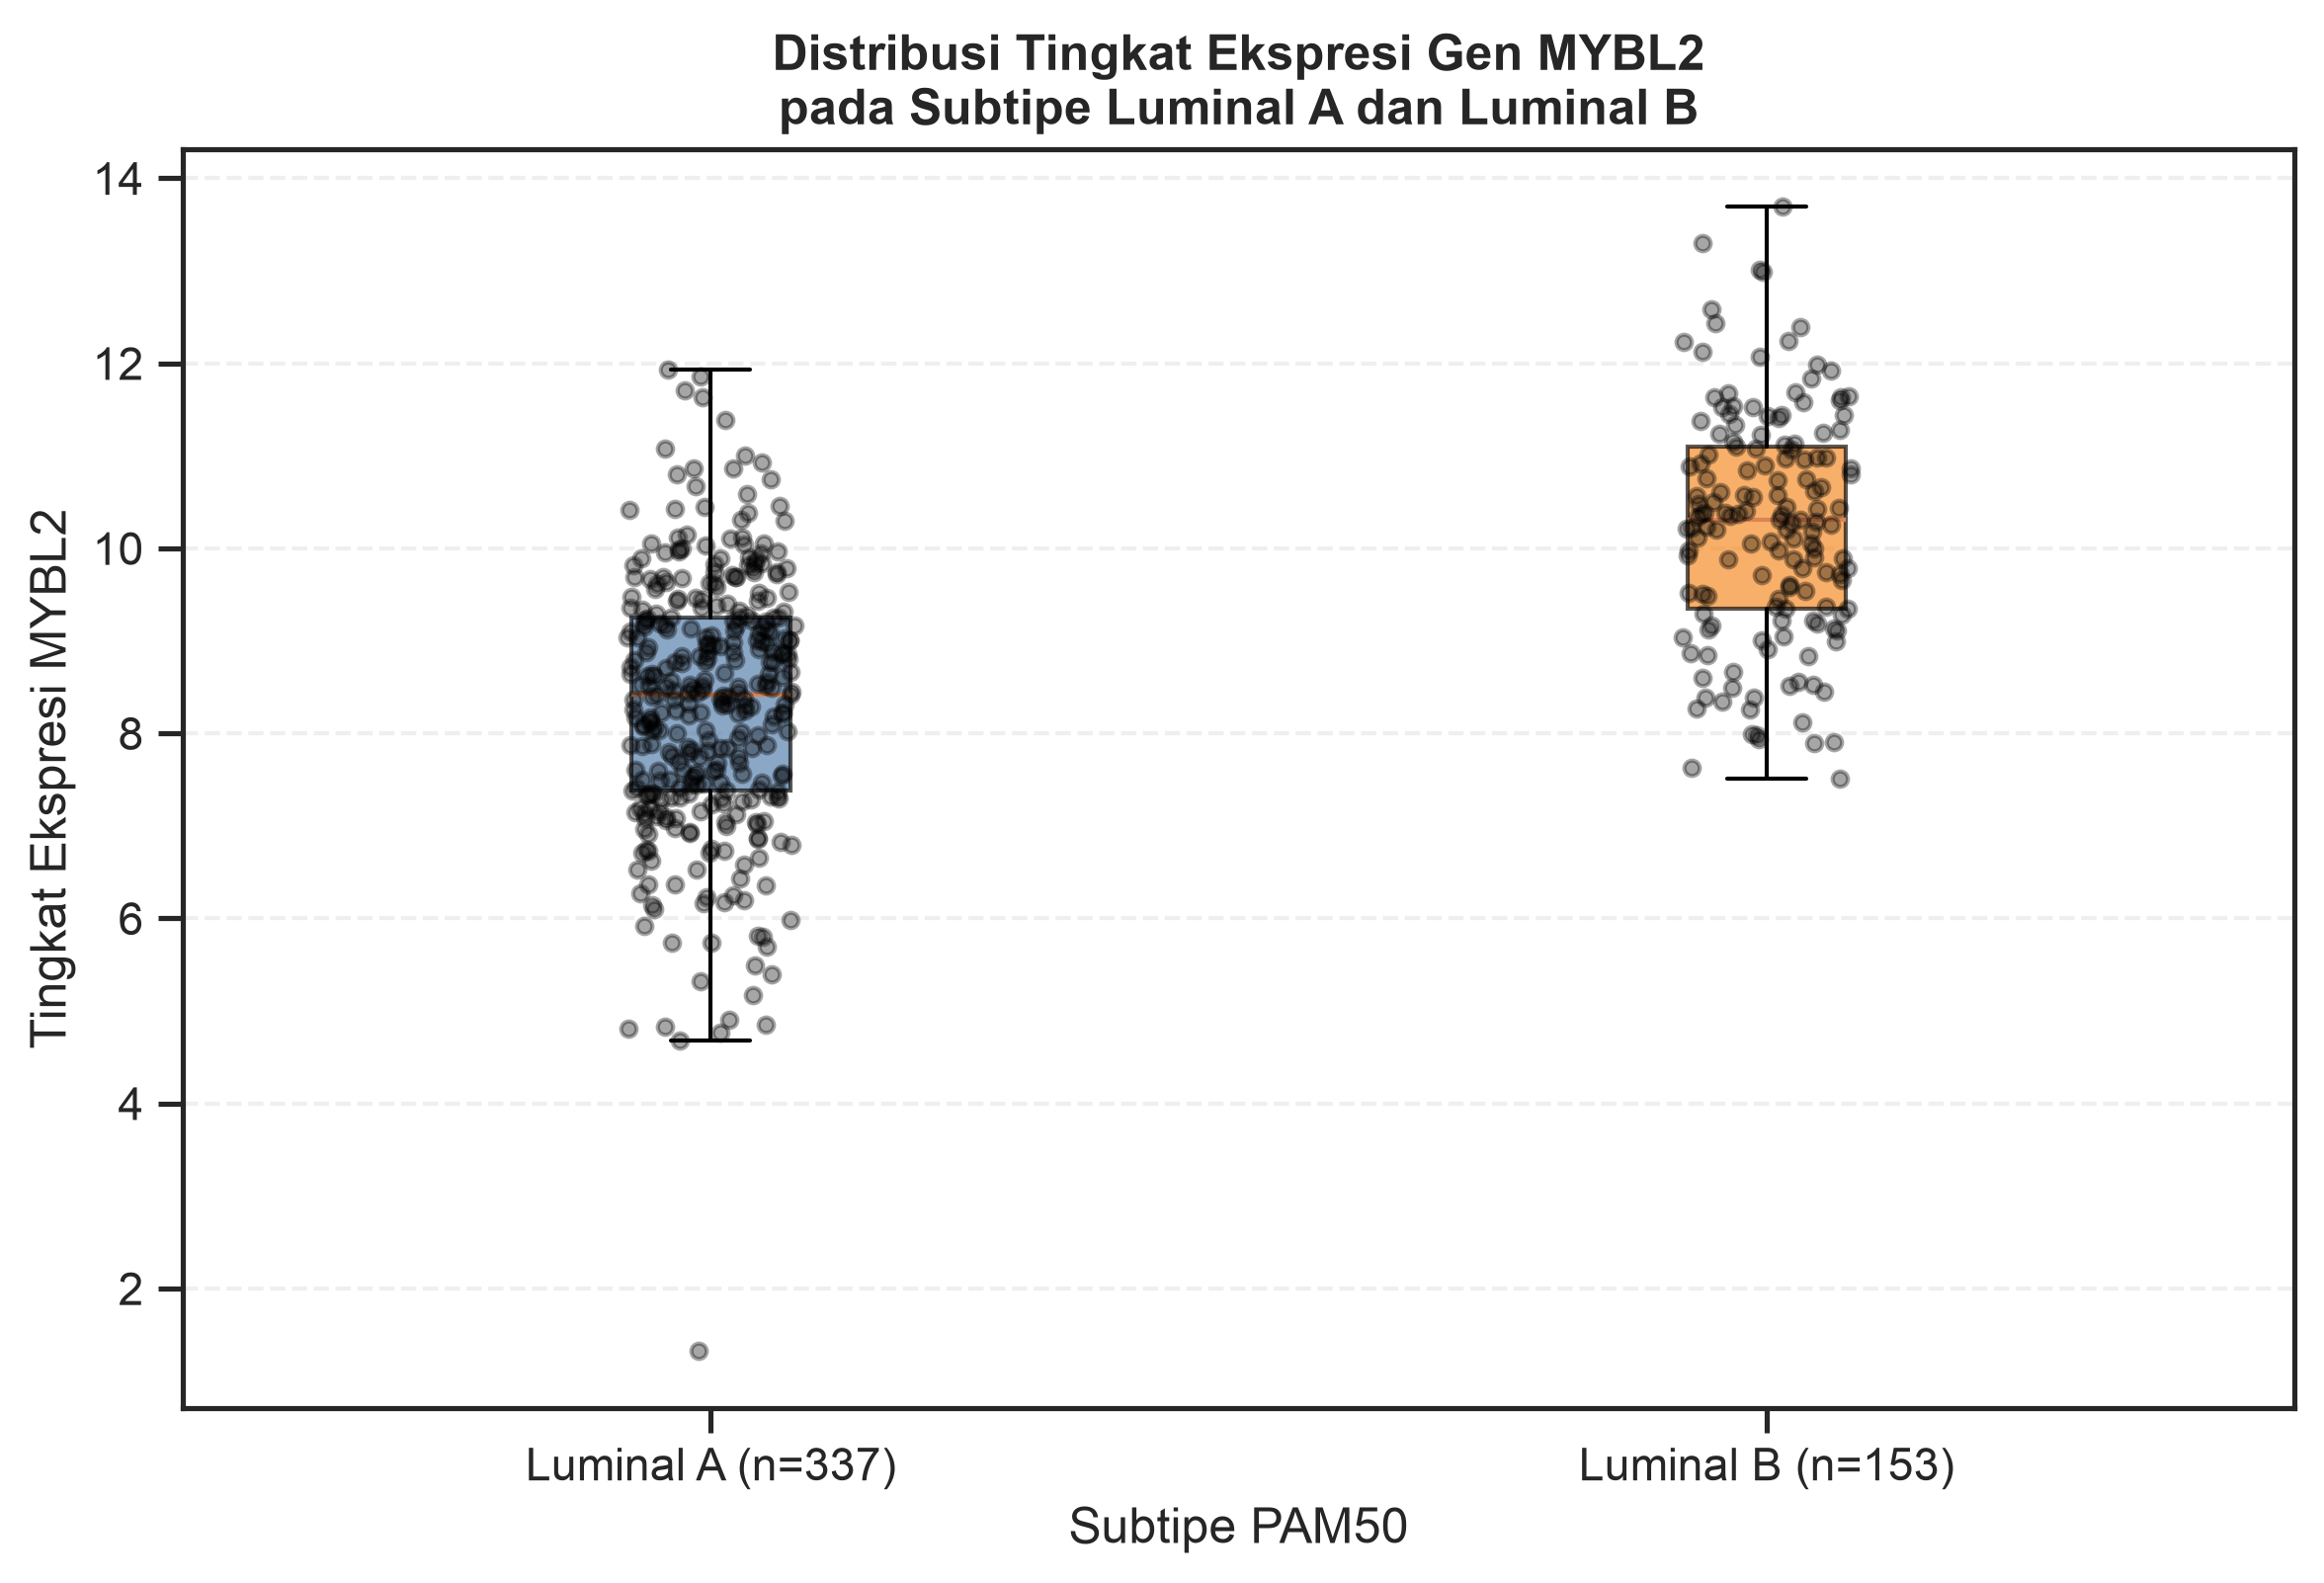

In [72]:
# ============================================================
# DISTRIBUSI EKSPRESI GEN MYBL2: LUMINAL A vs LUMINAL B
# ============================================================

gene_name = "MYBL2"

if gene_name not in X_train.columns:
    raise KeyError(f"Gen {gene_name} tidak ditemukan pada X_train.")

# Selaraskan label dengan indeks sampel
subtypes = pd.Series(
    label_encoder.inverse_transform(
        np.asarray(y_train, dtype=int)
    ),
    index=y_train.index if hasattr(y_train, "index") else X_train.index
)

plot_df = pd.DataFrame({
    "Ekspresi MYBL2": pd.to_numeric(X_train[gene_name], errors="coerce"),
    "Subtipe": subtypes.reindex(X_train.index)
})

plot_df = plot_df[
    plot_df["Subtipe"].isin(["LumA", "LumB"])
].dropna()

if plot_df.empty:
    raise ValueError("Tidak ditemukan data MYBL2 untuk LumA dan LumB.")

groups = [
    plot_df.loc[plot_df["Subtipe"] == subtype, "Ekspresi MYBL2"].to_numpy()
    for subtype in ["LumA", "LumB"]
]

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=300)

box = ax.boxplot(
    groups,
    tick_labels=[
        f"Luminal A (n={len(groups[0])})",
        f"Luminal B (n={len(groups[1])})"
    ],
    patch_artist=True,
    showfliers=False
)

for patch, color in zip(box["boxes"], ["#4C78A8", "#F58518"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)

# Tambahkan titik untuk menampilkan sebaran sampel
rng = np.random.default_rng(42)

for position, values in enumerate(groups, start=1):
    jitter = rng.uniform(-0.08, 0.08, size=len(values))
    ax.scatter(
        position + jitter,
        values,
        color="black",
        alpha=0.35,
        s=14,
        zorder=3
    )

ax.set_title(
    "Distribusi Tingkat Ekspresi Gen MYBL2\n"
    "pada Subtipe Luminal A dan Luminal B",
    fontweight="bold"
)
ax.set_xlabel("Subtipe PAM50")
ax.set_ylabel("Tingkat Ekspresi MYBL2")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/figures/distribusi_ekspresi_MYBL2_LumA_LumB.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

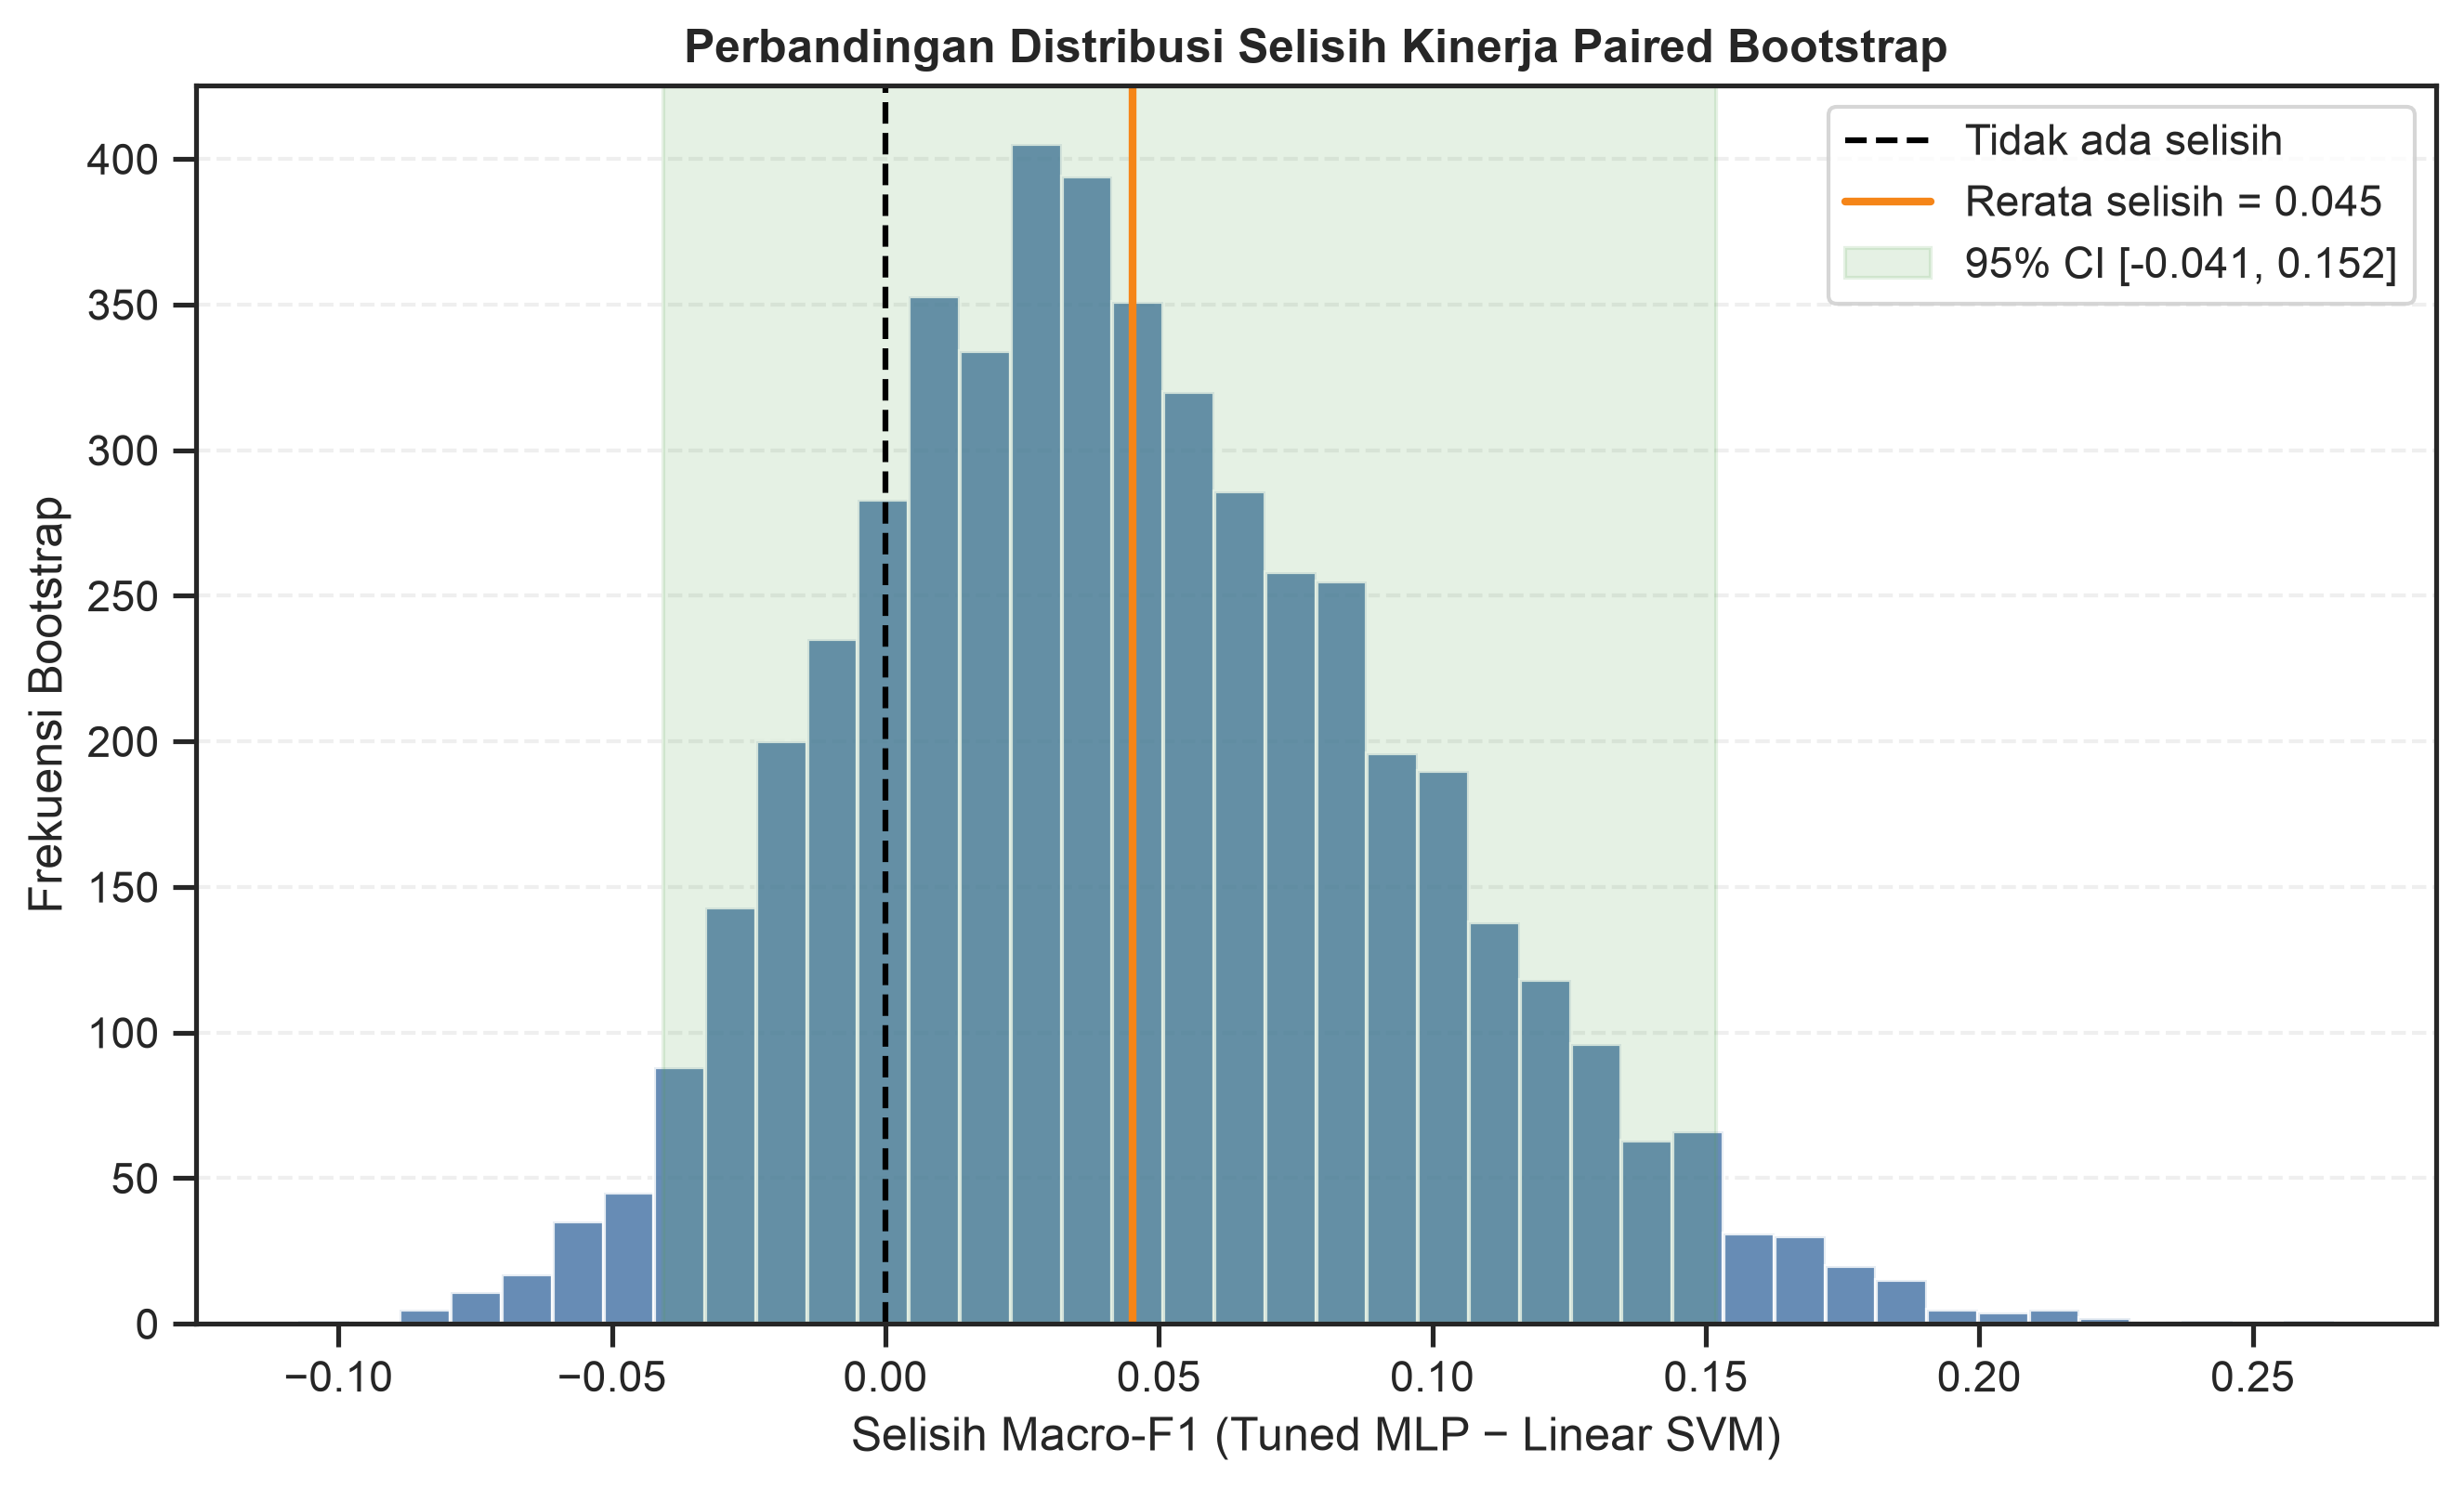

Rerata selisih Macro-F1 : 0.0451
95% CI                  : [-0.0406, 0.1518]


In [73]:
# ============================================================
# PERBANDINGAN DISTRIBUSI SELISIH KINERJA PAIRED BOOTSTRAP
# Selisih Macro-F1: Tuned MLP - Linear SVM
# ============================================================

if "bootstrap_difference" not in globals():
    raise RuntimeError(
        "bootstrap_difference belum tersedia. "
        "Jalankan sel paired bootstrap terlebih dahulu."
    )

differences = np.asarray(bootstrap_difference, dtype=float)
differences = differences[np.isfinite(differences)]

if differences.size == 0:
    raise ValueError("Tidak ada nilai bootstrap yang valid.")

ci_lower, ci_upper = np.percentile(differences, [2.5, 97.5])
mean_difference = differences.mean()

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=300)

ax.hist(
    differences,
    bins=40,
    color="#4C78A8",
    edgecolor="white",
    alpha=0.85
)

# Tandai nol, rerata bootstrap, dan interval kepercayaan 95%
ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label="Tidak ada selisih"
)

ax.axvline(
    mean_difference,
    color="#F58518",
    linestyle="-",
    linewidth=2,
    label=f"Rerata selisih = {mean_difference:.3f}"
)

ax.axvspan(
    ci_lower,
    ci_upper,
    color="#54A24B",
    alpha=0.15,
    label=f"95% CI [{ci_lower:.3f}, {ci_upper:.3f}]"
)

ax.set_title(
    "Perbandingan Distribusi Selisih Kinerja Paired Bootstrap",
    fontweight="bold"
)
ax.set_xlabel("Selisih Macro-F1 (Tuned MLP − Linear SVM)")
ax.set_ylabel("Frekuensi Bootstrap")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(
    "results/figures/distribusi_selisih_paired_bootstrap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"Rerata selisih Macro-F1 : {mean_difference:.4f}")
print(f"95% CI                  : [{ci_lower:.4f}, {ci_upper:.4f}]")

In [1]:
# Estimasi rata-rata ± standar deviasi Macro-F1
# Menggunakan Nested Cross-Validation

plot_data = nested_cv_summary.sort_values(
    "Mean_Macro_F1",
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

bars = ax.bar(
    plot_data["Model"],
    plot_data["Mean_Macro_F1"],
    yerr=plot_data["Std_Macro_F1"],
    capsize=5,
    color="#4C78A8",
    edgecolor="black"
)

for bar, mean_score, std_score in zip(
    bars,
    plot_data["Mean_Macro_F1"],
    plot_data["Std_Macro_F1"]
):
    ax.annotate(
        f"{mean_score:.4f} ± {std_score:.4f}",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Estimasi Kinerja Rata-rata dan Standar Deviasi Macro-F1\n"
    "Menggunakan Nested Cross-Validation",
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/figures/nested_cv_macro_f1_mean_std.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

NameError: name 'nested_cv_summary' is not defined

In [2]:
# Buat ringkasan jika hanya hasil per-fold yang tersedia
if "nested_cv_summary" not in globals():
    if "nested_cv_results" not in globals():
        raise RuntimeError(
            "Hasil nested CV belum tersedia. Jalankan sel nested "
            "cross-validation terlebih dahulu."
        )

    nested_cv_summary = (
        nested_cv_results
        .groupby("Model")["Macro_F1"]
        .agg(
            Mean_Macro_F1="mean",
            Std_Macro_F1="std"
        )
        .reset_index()
    )

plot_data = nested_cv_summary.sort_values(
    "Mean_Macro_F1",
    ascending=False
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)

bars = ax.bar(
    plot_data["Model"],
    plot_data["Mean_Macro_F1"],
    yerr=plot_data["Std_Macro_F1"],
    capsize=5,
    color="#4C78A8",
    edgecolor="black"
)

for bar, mean_score, std_score in zip(
    bars,
    plot_data["Mean_Macro_F1"],
    plot_data["Std_Macro_F1"]
):
    ax.annotate(
        f"{mean_score:.4f} ± {std_score:.4f}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title(
    "Estimasi Rata-rata dan Standar Deviasi Macro-F1\n"
    "Menggunakan Nested Cross-Validation",
    fontweight="bold"
)
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/figures/nested_cv_macro_f1_mean_std.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

RuntimeError: Hasil nested CV belum tersedia. Jalankan sel nested cross-validation terlebih dahulu.